# Exploitation de bases de données d'assurance automobile
### Audit, analyse, modélisation et tarification

**Étude réalisée par :** Morel POUNIGUIA  

---

Ce notebook contient **tout le code** de l'analyse et l'exécute **une étape à la fois**. Pour chaque étape on trouve :

1. **Une explication** : objectif, méthode, et comment lire les résultats ;
2. **Le calcul**, avec les tableaux importants et les graphiques ;
3. **Les points clés**, chiffrés automatiquement à partir des résultats.

| Partie / étape | Contenu |
|---|---|
| **0** | **Préparation** : configuration, outils de mise en forme et d'affichage |
| 1–2 | Compréhension et audit des données |
| 3 | Nettoyage et préparation |
| 3 bis | Statistiques détaillées |
| 4 | Jointure des bases |
| 5 | Analyse descriptive et exploratoire |
| 6 | Segmentation (ACP, k-means, classification hiérarchique) |
| 7 | Modélisation de la fréquence et du coût |
| 7 bis | Visualisations avancées |
| 8 | Interprétation actuarielle |
| 9 | Application : tarification et prévision |
| — | Conclusion, limites et recommandations |

> Chaque étape suit le même ordre : **explication** (objectif, méthode, lecture), **code** des fonctions de l'étape, puis **exécution** avec les tableaux, graphiques et points clés affichés **juste en dessous**. Exécutez le notebook dans l'ordre (« Run All »). Si vous modifiez une fonction, relancez sa cellule puis la cellule d'exécution qui la suit.

> **Lecture des résultats.** Sous chaque étape, les **points clés** donnent les chiffres importants, puis l'**interprétation** explique ce qu'ils signifient d'un point de vue statistique et actuariel (qualité du résultat, limites, conséquences pour le tarif).


### Correspondance avec le processus d'analyse demandé

| Processus demandé | Où le trouver dans ce notebook |
|---|---|
| 1. Traitement des données : compréhension, complétude, conformité, cohérence, anomalies | Étapes 1–2 (audit) et 3 (nettoyage documenté dans le journal des décisions) |
| 2. Jointures de bases et contrôles | Étape 4 |
| 3. Analyses descriptives : univariée, multivariée, ASD (réduction de dimension, classification) | Étapes 3 bis, 5 et 6 |
| 4. Analyse graphique (data visualisation) | Figures de chaque étape : qualité des données, impact du nettoyage, indices de prime, lois du nombre et du montant des sinistres, rapports de taux du GLM, comparaison des modèles, étape 7 bis (interactions, calibrage, Lorenz, effets partiels), grille tarifaire, tendance par segment, profils types |
| 5. Modélisation supervisée paramétrique et non paramétrique | Étape 7 (GLM contre forêt aléatoire et gradient boosting) |
| 6. Analyse des résultats : interprétation | « Points clés » de chaque étape et étape 8 |
| 7. Application : prévision, tarification | Étape 9 (tarif construit sur 2009, prévision testée sur 2010) |
| Conclusion, limites, recommandations | Dernière section |

## Partie 0 — Préparation

Configuration, outils de mise en forme du rapport et fonctions d'affichage. Chaque cellule confirme son exécution par un message.

### 0.1 Configuration : bibliothèques, chemins et constantes

In [1]:
import datetime
import shutil
import subprocess
import warnings
from pathlib import Path

import matplotlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from openpyxl import load_workbook
from scipy import stats as sstats
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import GammaRegressor, PoissonRegressor
from sklearn.metrics import (adjusted_rand_score, mean_absolute_error, mean_gamma_deviance,
                             mean_poisson_deviance, silhouette_score)
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

# ===========================================================================
# CONFIGURATION
# ===========================================================================
DOSSIER = Path.cwd()  # dossier du notebook = racine du projet : fonctionne sur tous les ordinateurs
DONNEES = DOSSIER / "donnees"  # fichiers d'entrée
FICHIER_CSV = DONNEES / "data_sin.csv"
FICHIER_XLSX = DONNEES / "data_ptf_Eco.xlsx"
SORTIE = DOSSIER / "resultats" / "tableaux"  # tableaux CSV
FIG = DOSSIER / "resultats" / "figures"  # graphiques PNG
FICHIER_TEX = DOSSIER / "rapport" / "rapport_analyse.tex"  # rapport LaTeX (et PDF)

GRAINE = 42  # graine commune à toutes les étapes aléatoires
SEUIL_MODALITES = 20
CODES_TEXTE_MANQUANTS = {"", "??", "???", "NA", "N/A", "null", "NULL", "-"}



SIGNIFICATIONS = {
    ("sinistres", "nb_sin"): "Nombre de sinistres déclarés sur la police",
    ("sinistres", "chg_sin"): "Coût total des sinistres (charge), en euros (hypothèse)",
    ("sinistres", "PolNum"): "Identifiant de la police (clé de jointure)",
    ("portefeuille", "PolNum"): "Identifiant de la police (clé de jointure)",
    ("portefeuille", "CalYear"): "Année calendaire de l'observation (2009 ou 2010)",
    ("portefeuille", "Gender"): "Sexe du conducteur ; codes mixtes Male/Female et H/F/h",
    ("portefeuille", "Type"): "Type de véhicule, codes A à F (hypothèse)",
    ("portefeuille", "Category"): "Catégorie de taille (Small/Medium/Large), '???' = inconnu",
    ("portefeuille", "Occupation"): "Catégorie socio-professionnelle du conducteur",
    ("portefeuille", "Age"): "Âge du conducteur en années (valeurs aberrantes présentes)",
    ("portefeuille", "Group1"): "Zone géographique, codes 4 à 20 (hypothèse)",
    ("portefeuille", "Bonus"): "Coefficient bonus-malus, de -50 à 150 (hypothèse)",
    ("portefeuille", "Poldur"): "Ancienneté de la police en années (valeurs négatives présentes)",
    ("portefeuille", "Value"): "Valeur du véhicule en euros (hypothèse) ; valeurs manquantes et '??'",
    ("portefeuille", "Adind"): "Indicateur binaire (0/1), signification à confirmer",
    ("portefeuille", "SubGroup2"): "Sous-groupe géographique, très peu renseigné (88 % de manquants)",
    ("portefeuille", "Group2"): "Groupe géographique à 10 modalités (hypothèse)",
    ("portefeuille", "Density"): "Densité de population de la zone (hypothèse)",
    ("exposition", "PolNum"): "Identifiant de la police (clé de jointure)",
    ("exposition", "Expdays"): "Nombre de jours d'exposition au risque sur l'année (91 à 365)",
}


def preparer_dossiers() -> None:
    """Crée les dossiers de sortie s'ils n'existent pas."""
    for dossier in (SORTIE, FIG, FICHIER_TEX.parent):
        dossier.mkdir(parents=True, exist_ok=True)

print(f"Configuration chargée : données dans {DONNEES.name}/, tableaux dans resultats/tableaux, figures dans resultats/figures, graine aléatoire = {GRAINE}")  # confirme l'exécution de la cellule


Configuration chargée : données dans donnees/, tableaux dans resultats/tableaux, figures dans resultats/figures, graine aléatoire = 42


### 0.2 Outils de mise en forme du rapport LaTeX

In [2]:
# ===========================================================================
# OUTILS LATEX ET MISE EN FORME DU RAPPORT
# ===========================================================================


CARACTERES = {
    "\\": r"\textbackslash{}", "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#",
    "_": r"\_", "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}", "^": r"\textasciicircum{}",
    "∩": r"$\cap$", "–": r"--", "—": r"---", "−": r"$-$", "×": r"$\times$",
    "€": r"\texteuro{}", "«": r"\guillemotleft{}", "»": r"\guillemotright{}",
    "≤": r"$\leq$", "≥": r"$\geq$", "→": r"$\rightarrow$",
    "↔": r"$\leftrightarrow$", "←": r"$\leftarrow$",
}


LITTERAL = {
    "é": r"\'e", "è": r"\`e", "ê": r"\^e", "à": r"\`a", "â": r"\^a", "ç": r"\c{c}",
    "ô": r"\^o", "û": r"\^u", "î": r"\^i", "É": r"\'E", "Â": r"\^A",
    "–": "--", "—": "---", "−": r"$-$", "×": r"$\times$", "∩": r"$\cap$",
    "€": r"\texteuro{}", "«": r"\guillemotleft{}", "»": r"\guillemotright{}",
    "≤": r"$\leq$", "≥": r"$\geq$", "→": r"$\rightarrow$",
    "À": r"\`A",
    "œ": r"\oe{}", "Œ": r"\OE{}",
    "↔": r"$\leftrightarrow$", "←": r"$\leftarrow$",
}


def echapper(texte) -> str:
    return "".join(CARACTERES.get(c, c) for c in str(texte))


def nombre(x, decimales=0) -> str:
    if pd.isna(x):
        return "--"
    s = f"{x:,.{decimales}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", " ")


def tableau(caption: str, label: str, entetes: list, lignes: list, specs: str) -> str:
    entete = " & ".join(r"\textbf{" + (e if "\\" in e else echapper(e)) + "}" for e in entetes) + r" \\"
    sortie = [
        r"\begin{longtable}{" + specs + "}",
        r"\caption{" + echapper(caption) + r"} \label{" + label + r"} \\",
        r"\toprule", entete, r"\midrule", r"\endfirsthead",
        r"\toprule", entete, r"\midrule", r"\endhead",
        r"\bottomrule", r"\endfoot",
    ]
    sortie += [" & ".join(str(c) for c in l) + r" \\" for l in lignes]
    sortie += [r"\bottomrule", r"\end{longtable}", ""]
    return "\n".join(sortie)


def literate() -> str:
    return "literate=" + " ".join("{" + c + "}{{" + v + "}}1" for c, v in LITTERAL.items()) + ","


PREAMBULE = r"""\documentclass[11pt,a4paper]{article}
\usepackage[utf8]{inputenc}
\usepackage[T1]{fontenc}
\usepackage{textcomp}
\usepackage[a4paper,margin=2.2cm]{geometry}
\usepackage{lmodern}
\usepackage{booktabs}
\usepackage{longtable}
\usepackage{array}
\usepackage{caption}
\usepackage{hyperref}
\usepackage{xcolor}
\usepackage{listings}
\usepackage{enumitem}
\usepackage{graphicx}

\renewcommand{\contentsname}{Table des matières}
\renewcommand{\tablename}{Tableau}
\renewcommand{\listtablename}{Liste des tableaux}
\renewcommand{\appendixname}{Annexe}
\renewcommand{\refname}{Références}
\newcommand{\dateFR}{__DATE_FR__}

\lstset{
  basicstyle=\ttfamily\footnotesize, breaklines=true, frame=single,
  numbers=left, numberstyle=\tiny\color{gray},
  keywordstyle=\color{blue!60!black}\bfseries,
  commentstyle=\color{green!40!black}\itshape,
  stringstyle=\color{red!50!black}, showstringspaces=false,
  __LITERATE__
  inputencoding=utf8
}

\title{Exploitation de bases de données d'assurance automobile\\[0.3em]\large Audit, analyse, modélisation et tarification}
\author{Morel POUNIGUIA}
\date{\dateFR}

\begin{document}
\maketitle
\tableofcontents
\newpage
"""


FIN = "\n\\end{document}\n"


def var_tex(nom) -> str:
    """Nom de variable en \\texttt avec retour possible après chaque underscore."""
    return "\\_\\allowbreak{}".join(echapper(m) for m in str(nom).split("_"))

print("Outils LaTeX chargés : echapper, nombre, tableau, var_tex")  # confirme l'exécution de la cellule


Outils LaTeX chargés : echapper, nombre, tableau, var_tex


### 0.3 Fonctions d'affichage du notebook et vérification des données

In [3]:
import re  # expressions régulières (mise en forme des nombres)
import time  # mesure du temps d'exécution de chaque étape
import warnings  # gestion des messages d'avertissement
from pathlib import Path  # manipulation simple des chemins de fichiers

import matplotlib.pyplot as plt  # graphiques
import numpy as np  # calculs numériques
import pandas as pd  # tableaux de données
from IPython.display import Image, Markdown, display  # affichage d'images et de texte dans le notebook

%matplotlib inline

plt.rcParams.update({  # style commun et sobre pour tous les graphiques
    "axes.spines.top": False, "axes.spines.right": False,  # pas de cadre inutile
    "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False,  # tailles de texte lisibles
})
BLEU, ORANGE, ROUGE, VERT, GRIS = "#4C72B0", "#DD8452", "#C44E52", "#55A868", "#8C8C8C"  # palette des graphiques
warnings.filterwarnings("ignore")  # masque les avertissements numériques sans gravité (numpy/sklearn)
pd.set_option("display.max_columns", 50)  # affiche jusqu'à 50 colonnes sans les tronquer
pd.set_option("display.max_colwidth", 80)  # coupe les textes trop longs à 80 caractères
pd.set_option("display.float_format", "{:,.4g}".format)  # arrondit les nombres à 4 chiffres significatifs

preparer_dossiers()  # crée resultats/tableaux, resultats/figures et rapport/ s'ils n'existent pas

for fichier in (FICHIER_CSV, FICHIER_XLSX):  # parcourt les deux fichiers de données attendus
    assert fichier.exists(), f"Fichier introuvable : {fichier}"  # arrête tout si une donnée manque

VOIR_TOUS_LES_CSV = False  # True : affiche aussi tous les fichiers CSV de chaque étape
LIGNES_MAX = 10  # nombre de lignes affichées pour chaque tableau
duree = {}  # durée de chaque étape, en secondes


def nombres(colonne):  # transforme « 0,25 » en 0.25 quand toute la colonne est numérique
    if colonne.dtype != object:  # colonne déjà numérique : rien à faire
        return colonne  # on la renvoie telle quelle
    essai = pd.to_numeric(colonne.str.replace(",", ".", regex=False), errors="coerce")  # tentative de conversion
    return essai if essai.notna().sum() == colonne.notna().sum() else colonne  # garde le texte si la conversion échoue


def montrer_fig(nom=None):  # affiche la figure en cours (et l'enregistre si un nom est donné)
    fig = plt.gcf()  # figure en cours de construction
    if nom:  # figure reprise dans le rapport PDF
        fig.savefig(FIG / f"fig_{nom}.png", dpi=150, bbox_inches="tight")  # enregistrement en PNG
    display(fig)  # affichage explicite (le script d'analyse force matplotlib en mode « Agg », sans fenêtre)
    plt.close(fig)  # libère la mémoire et évite un double affichage


def afficher(df, titre, n=LIGNES_MAX):  # affiche un tableau avec un titre et ses dimensions
    display(Markdown(f"**{titre}** — {df.shape[0]} lignes × {df.shape[1]} colonnes"))  # titre
    display(df.head(n))  # premières lignes


def virgule(texte):  # remplace le point décimal par une virgule : 41.1 → 41,1
    return re.sub(r"(?<=\d)\.(?=\d)", ",", texte)  # seulement entre deux chiffres


DERNIER = {"points": [], "interp": []}  # derniers constats affichés (repris dans le rapport PDF)
RAPPORT_COMPLEMENTS = {}  # sections ajoutées au rapport PDF : nom -> contenu


def points_cles(*phrases):  # affiche une liste à puces de constats
    phrases = [p for p in phrases if p]  # ignore les phrases vides
    DERNIER["points"] = [virgule(p) for p in phrases]  # mémorisés pour le rapport
    display(Markdown("#### Points clés\n" + "\n".join(f"- {virgule(p)}" for p in phrases)))  # rendu en Markdown


def interpretation(*phrases):  # affiche l'interprétation statistique / actuarielle des résultats
    phrases = [p for p in phrases if p]  # ignore les phrases vides
    DERNIER["interp"] = [virgule(p) for p in phrases]  # mémorisée pour le rapport
    display(Markdown("#### Interprétation\n" + "\n".join(f"- {virgule(p)}" for p in phrases)))  # rendu en Markdown


def verdict(condition, si_oui, si_non):  # choisit la phrase selon que le critère est rempli ou non
    return si_oui if condition else si_non  # phrase correspondant au résultat


def pour_rapport(nom, titre, legende, figure=True):  # ajoute la figure et ses constats au rapport PDF
    RAPPORT_COMPLEMENTS[nom] = {  # une section par graphique (un nouveau calcul remplace l'ancien)
        "titre": titre, "legende": legende,
        "figure": (FIG.relative_to(DOSSIER) / f"fig_{nom}.png").as_posix() if figure else None,
        "points": DERNIER["points"], "interp": DERNIER["interp"],
    }
    DERNIER["points"], DERNIER["interp"] = [], []  # évite de reprendre deux fois les mêmes phrases


def nb_fr(x, d=0):  # formate un nombre à la française : 12 345,6
    return f"{x:,.{d}f}".replace(",", " ").replace(".", ",")  # espace pour les milliers, virgule décimale


def montrer_csv(prefixe):  # affiche tous les fichiers CSV d'une étape (si VOIR_TOUS_LES_CSV)
    for f in sorted(SORTIE.glob(f"{prefixe}_*.csv")):  # chaque CSV dont le nom commence par le préfixe
        df = pd.read_csv(f, sep=";", low_memory=False).apply(nombres)  # lecture puis conversion des nombres
        afficher(df, f.stem)  # affichage


def etat_figures():  # date de modification de chaque figure du dossier resultats/figures
    return {f: f.stat().st_mtime for f in FIG.glob("*.png")}  # dictionnaire fichier -> date


def montrer_figures(avant):  # affiche les figures créées ou modifiées depuis l'état « avant »
    for f in sorted(FIG.glob("*.png")):  # chaque figure du dossier resultats/figures
        if avant.get(f) != f.stat().st_mtime:  # nouvelle figure, ou figure réécrite pendant l'étape
            display(Markdown(f"**Figure : {f.stem.replace('fig_', '').replace('_', ' ')}**"))  # titre
            display(Image(filename=str(f), width=700))  # image


def lancer(nom, fonction, *prefixes):  # exécute une étape, mesure sa durée et affiche ses figures
    debut = time.time()  # heure de départ
    avant = etat_figures()  # figures présentes avant l'étape
    resultat = fonction()  # lance la fonction de l'étape
    duree[nom] = time.time() - debut  # enregistre le temps écoulé
    display(Markdown(f"*{nom} terminée en {duree[nom]:.1f} s*"))  # affiche la durée
    if VOIR_TOUS_LES_CSV:  # option : tous les CSV bruts
        for p in prefixes:  # pour chaque préfixe de fichiers
            montrer_csv(p)  # affichage des CSV
    montrer_figures(avant)  # figures de l'étape uniquement
    return resultat  # renvoie le résultat pour les étapes suivantes


print("Prêt : données trouvées, fonctions chargées")  # confirme que tout est en place

Prêt : données trouvées, fonctions chargées


## Analyse étape par étape

Chaque étape suit le même plan : **objectif, méthode et lecture** (texte), **code** des fonctions de l'étape, puis **calcul** (tableaux et graphiques) et **points clés** (constats chiffrés calculés automatiquement), affichés sous le code.

### Étapes 1 et 2 — Compréhension et audit des données

**Objectif.** Savoir ce que contiennent les trois bases (sinistres, portefeuille, expositions) et repérer tous les problèmes de qualité **avant** de les corriger.

**Méthode.**
- *Dictionnaire* : type, nature (quantitative, qualitative, identifiant) et signification de chaque variable ;
- *Valeurs manquantes* : vraies cases vides et codes textuels (`??`, `NA`…) ;
- *Doublons* : lignes strictement identiques et clés `PolNum` répétées ;
- *Valeurs aberrantes* : règle de Tukey, hors de [Q1 − 1,5 × IQR ; Q3 + 1,5 × IQR] ;
- *Règles métier* : âge < 18 ans, ancienneté supérieure à l'âge, « Housewife » de sexe masculin, etc.

**Comment lire.** Une valeur aberrante au sens de Tukey n'est pas forcément une erreur : les gros sinistres sont réels. Les règles « Impossible » sont des erreurs certaines ; les règles « Suspect » sont à confirmer.

#### Code : chargement, dictionnaire, audit de qualité

Définition des fonctions de l'étape. Le résultat de leur exécution s'affiche dans la cellule suivante.

In [4]:
# ===========================================================================
# ÉTAPE 1 – COMPRÉHENSION DES BASES DE DONNÉES
# ===========================================================================


def charger_csv_brut() -> pd.DataFrame:
    """Sinistres en texte brut (séparateur ';', pas de conversion automatique)."""
    return pd.read_csv(FICHIER_CSV, sep=";", dtype=str, keep_default_na=False)


def charger_excel() -> dict:
    """Feuilles Excel avec leurs valeurs en cache (data_only)."""
    feuilles = {}
    for ws in load_workbook(FICHIER_XLSX, read_only=True, data_only=True).worksheets:
        rows = list(ws.iter_rows(values_only=True))
        feuilles[ws.title] = pd.DataFrame(rows[1:], columns=rows[0])
    return feuilles


def typer_sinistres(brut: pd.DataFrame) -> pd.DataFrame:
    """Convertit le CSV brut en types numériques (décimale en virgule)."""
    df = brut.copy()
    df["chg_sin"] = pd.to_numeric(df["chg_sin"].str.replace(",", ".", regex=False), errors="coerce")
    df["nb_sin"] = pd.to_numeric(df["nb_sin"], errors="coerce")
    df["PolNum"] = pd.to_numeric(df["PolNum"], errors="coerce")
    return df


def typer_portefeuille(ptf: pd.DataFrame) -> pd.DataFrame:
    df = ptf.copy()
    df["Value_num"] = pd.to_numeric(df["Value"], errors="coerce")
    df["Density"] = pd.to_numeric(df["Density"], errors="coerce")
    return df


def recenser_formules() -> pd.DataFrame:
    """Cellules contenant une formule au lieu d'une valeur, par feuille et par colonne."""
    lignes = []
    for ws in load_workbook(FICHIER_XLSX, read_only=True).worksheets:
        rows = ws.iter_rows(values_only=True)
        entete = next(rows)
        compte = {h: 0 for h in entete}
        exemple = {}
        for r in rows:
            for h, v in zip(entete, r):
                if isinstance(v, str) and v.startswith("="):
                    compte[h] += 1
                    exemple.setdefault(h, v)
        for h, n in compte.items():
            if n:
                lignes.append({"feuille": ws.title, "variable": h, "nb_formules": n,
                               "exemple": exemple[h][:120]})
    return pd.DataFrame(lignes)


def classer_variable(serie: pd.Series) -> str:
    """Retourne 'identifiant', 'qualitative' ou 'quantitative'."""
    if serie.name == "PolNum":
        return "identifiant"
    if pd.api.types.is_numeric_dtype(serie) and not pd.api.types.is_bool_dtype(serie):
        if serie.nunique(dropna=True) <= SEUIL_MODALITES:
            return "qualitative"
        return "quantitative"
    return "qualitative"


def dictionnaire(tables: dict) -> pd.DataFrame:
    lignes = []
    for nom, df in tables.items():
        for col in df.columns:
            s = df[col]
            lignes.append({
                "table": nom, "variable": col, "type_pandas": str(s.dtype),
                "nature": classer_variable(s),
                "nb_manquants": int(s.isna().sum()),
                "pct_manquants": round(100 * s.isna().mean(), 2),
                "nb_valeurs_distinctes": int(s.nunique(dropna=True)),
                "signification": SIGNIFICATIONS.get((nom, col), ""),
            })
    return pd.DataFrame(lignes)


def statistiques_quantitatives(dico: pd.DataFrame, tables: dict) -> pd.DataFrame:
    morceaux = []
    for nom, df in tables.items():
        cols = dico[(dico["table"] == nom) & (dico["nature"] == "quantitative")]["variable"]
        if len(cols):
            desc = df[cols].describe().T.round(3)
            desc.insert(0, "table", nom)
            morceaux.append(desc.reset_index().rename(columns={"index": "variable"}))
    return pd.concat(morceaux, ignore_index=True)


def cles_jointure(tables: dict) -> dict:
    """Unicité et recouvrement de PolNum."""
    resultat = {}
    ensembles = {}
    for nom, df in tables.items():
        s = df["PolNum"]
        resultat[nom] = {
            "nb_lignes": int(len(s)), "nb_PolNum_distincts": int(s.nunique()),
            "nb_PolNum_doublons_lignes": int(s.duplicated().sum()),
            "nb_lignes_identiques_completes": int(df.duplicated().sum()),
            "nb_PolNum_manquants": int(s.isna().sum()),
        }
        ensembles[nom] = set(s.dropna())
    noms = list(ensembles)
    recouvrement = {}
    for i, a in enumerate(noms):
        for b in noms[i + 1:]:
            inter = ensembles[a] & ensembles[b]
            recouvrement[f"{a} ∩ {b}"] = {
                "nb_communs": len(inter),
                "pct_de_" + a: round(100 * len(inter) / len(ensembles[a]), 2),
                "pct_de_" + b: round(100 * len(inter) / len(ensembles[b]), 2),
            }
    resultat["recouvrement"] = recouvrement
    sin_ids = ensembles["sinistres"]
    lignes_sans = int((~tables["sinistres"]["PolNum"].isin(ensembles["portefeuille"])).sum())
    resultat["sinistres_sans_police"] = {
        "nb_PolNum_distincts_sans_correspondance": len(sin_ids - ensembles["portefeuille"]),
        "nb_lignes_sinistres_concernees": lignes_sans,
    }
    return resultat


def anomalies_etape1(tables: dict) -> pd.DataFrame:
    p, e, s = tables["portefeuille"], tables["exposition"], tables["sinistres"]
    regles = [
        ("portefeuille", "Gender", "Codes non normalisés (H, F, h)", p["Gender"].isin(["H", "F", "h"])),
        ("portefeuille", "Gender", "Valeur manquante", p["Gender"].isna()),
        ("portefeuille", "Category", "Modalité '???' (inconnue)", p["Category"].eq("???")),
        ("portefeuille", "Value", "Valeur manquante", p["Value"].isna()),
        ("portefeuille", "Value", "Valeur non numérique '??'",
         pd.to_numeric(p["Value"], errors="coerce").isna() & p["Value"].notna()),
        ("portefeuille", "Age", "Âge < 18 ans", p["Age"] < 18),
        ("portefeuille", "Age", "Âge > 100 ans (aberrant)", p["Age"] > 100),
        ("portefeuille", "Poldur", "Ancienneté négative", p["Poldur"] < 0),
        ("portefeuille", "Poldur", "Ancienneté > âge du conducteur", p["Poldur"] > p["Age"]),
        ("portefeuille", "SubGroup2", "Valeur manquante (taux élevé)", p["SubGroup2"].isna()),
        ("exposition", "Expdays", "Exposition > 365 jours", e["Expdays"] > 365),
        ("sinistres", "chg_sin", "Coût nul", s["chg_sin"] == 0),
        ("sinistres", "PolNum", "Police sans correspondance dans le portefeuille", ~s["PolNum"].isin(p["PolNum"])),
    ]
    return pd.DataFrame([
        {"table": t, "variable": v, "anomalie": libelle, "nb_lignes": int(m.sum()),
         "pct": round(100 * m.mean(), 3)}
        for t, v, libelle, m in regles
    ])


def s_sources(res) -> str:
    noms = {"sinistres": "Sinistres (CSV)", "portefeuille": "Portefeuille PTF (Excel)",
            "exposition": "Exposition Expo (Excel)"}
    lignes = [[echapper(noms[k]), nombre(v["nb_lignes"]), nombre(v["nb_colonnes"])]
              for k, v in res["tables"].items()]
    return ("\\section{Sources de données}\n"
            "Trois jeux de données sont fournis. Le CSV utilise le séparateur \\texttt{;} et la virgule décimale ; "
            "le fichier Excel contient deux feuilles.\n\n"
            + tableau("Dimensions des tables importées", "tab:dimensions", ["Table", "Lignes", "Colonnes"], lignes, "lrr"))


def s_dictionnaire(dico) -> str:
    lignes = [[echapper(r.table), r"\texttt{" + echapper(r.variable) + "}", echapper(r.type_pandas),
               echapper(r.nature), nombre(r.pct_manquants, 2), echapper(r.signification)]
              for r in dico.itertuples()]
    return ("\\section{Dictionnaire des variables}\n"
            "Chaque variable est décrite par son type, sa nature et sa signification. Les significations sont "
            "\\emph{déduites} du nom et des valeurs : elles doivent être validées auprès du producteur.\n\n"
            + tableau("Dictionnaire des variables", "tab:dictionnaire",
                      ["Table", "Variable", "Type", "Nature", "\\% manquants", "Signification"],
                      lignes, "llllrp{6.2cm}"))


def s_nature(dico) -> str:
    def liste(nature):
        sub = dico[dico["nature"] == nature]
        return ", \\allowbreak ".join(
            r"\texttt{" + echapper(r.table) + ".\\allowbreak{}" + echapper(r.variable) + "}" for r in sub.itertuples()
        ) or "aucune"
    return ("\\section{Variables quantitatives et qualitatives}\n\\begin{itemize}\n"
            f"  \\item \\textbf{{Quantitatives}} ({(dico['nature'] == 'quantitative').sum()}) : {liste('quantitative')}.\n"
            f"  \\item \\textbf{{Qualitatives}} ({(dico['nature'] == 'qualitative').sum()}) : {liste('qualitative')}.\n"
            f"  \\item \\textbf{{Identifiants}} ({(dico['nature'] == 'identifiant').sum()}) : {liste('identifiant')}.\n"
            "\\end{itemize}\n"
            "Une variable numérique comptant au plus 20 valeurs distinctes est traitée comme qualitative. "
            "\\textbf{Cas particulier} : \\texttt{portefeuille.Value} est lue comme texte à cause de deux valeurs "
            "\\texttt{??} ; c'est une variable quantitative par nature.\n")


def s_statistiques(stats) -> str:
    lignes = [[echapper(r["table"]), r"\texttt{" + echapper(r["variable"]) + "}", nombre(r["count"]),
               nombre(r["mean"], 2), nombre(r["std"], 2), nombre(r["min"], 2), nombre(r["50%"], 2),
               nombre(r["max"], 2)]
              for r in stats.to_dict("records")]
    return ("\\section{Statistiques descriptives des variables quantitatives}\n"
            "Statistiques calculées sur les valeurs non manquantes.\n\n"
            + tableau("Statistiques descriptives", "tab:stats",
                      ["Table", "Variable", "N", "Moyenne", "Écart-type", "Min", "Médiane", "Max"],
                      lignes, "llrrrrrr"))


def s_anomalies_e1(an) -> str:
    lignes = [[echapper(r.table), r"\texttt{" + echapper(r.variable) + "}", echapper(r.anomalie),
               nombre(r.nb_lignes), nombre(r.pct, 3)] for r in an.itertuples()]
    return ("\\section{Contrôle de qualité de l'étape 1}\n"
            + tableau("Anomalies détectées à l'étape 1", "tab:anomalies_e1",
                      ["Table", "Variable", "Anomalie", "Lignes", "\\% des lignes"], lignes, "llp{6cm}rr"))


def s_cles(cles) -> str:
    lignes = [[echapper(n), nombre(cles[n]["nb_lignes"]), nombre(cles[n]["nb_PolNum_distincts"]),
               nombre(cles[n]["nb_PolNum_doublons_lignes"]), nombre(cles[n]["nb_lignes_identiques_completes"])]
              for n in ["sinistres", "portefeuille", "exposition"]]
    rec = [[echapper(k), nombre(v["nb_communs"]),
            " ; ".join(f"{kk.replace('pct_de_', '')} : {nombre(vv, 2)} \\%" for kk, vv in v.items() if kk.startswith("pct_de_"))]
           for k, v in cles["recouvrement"].items()]
    sans = cles["sinistres_sans_police"]
    return ("\\section{Clés de jointure}\n"
            "La clé candidate est \\texttt{PolNum}, présente dans les trois tables sans valeur manquante. "
            "Elle n'est pas unique, ce qui impose un traitement avant jointure.\n\n"
            + tableau("Unicité de PolNum par table", "tab:doublons_e1",
                      ["Table", "Lignes", "PolNum distincts", "Lignes à PolNum répété", "Lignes identiques en double"],
                      lignes, "lrrrr")
            + "\n" + tableau("Recouvrement entre tables", "tab:recouvrement",
                             ["Jointure", "PolNum communs", "Part couverte"], rec, "lrp{8cm}")
            + f"\n{nombre(sans['nb_PolNum_distincts_sans_correspondance'])} polices de sinistres n'existent pas "
            f"dans le portefeuille ({nombre(sans['nb_lignes_sinistres_concernees'])} lignes).\n")


def s_methode_e1() -> str:
    return ("\\section{Méthode}\n"
            "Les contrôles de l'étape 1 portent sur les dimensions, les types, la classification des variables "
            "(quantitatives, qualitatives, identifiants), les statistiques descriptives et les clés de jointure. "
            "Les significations sont à valider avec le producteur des données.\n")


# ===========================================================================
# ÉTAPE 2 – AUDIT ET QUALITÉ DES DONNÉES
# ===========================================================================


def manquants(brut: pd.DataFrame, nom: str) -> pd.DataFrame:
    n = len(brut)
    lignes = []
    for col in brut.columns:
        s = brut[col]
        vides = int(s.isna().sum())
        textes = int((s.astype(str).str.strip().isin(CODES_TEXTE_MANQUANTS) & s.notna()).sum())
        lignes.append({"table": nom, "variable": col, "nb_NA": vides, "nb_codes_textuels": textes,
                       "nb_total_manquants": vides + textes,
                       "pct_manquants": round(100 * (vides + textes) / n, 2)})
    return pd.DataFrame(lignes)


def doublons(brut: pd.DataFrame, nom: str) -> tuple:
    rep = brut[brut["PolNum"].duplicated(keep=False)]
    diff = rep.groupby("PolNum").filter(lambda g: len(g.drop_duplicates()) > 1)
    resume = {
        "table": nom, "nb_lignes": int(len(brut)),
        "nb_lignes_identiques_en_double": int(brut.duplicated().sum()),
        "nb_cles_repetees": int(rep["PolNum"].nunique()),
        "nb_lignes_cle_repetee": int(len(rep)),
        "nb_cles_repetees_contenu_different": int(diff["PolNum"].nunique()),
    }
    return resume, rep.sort_values("PolNum").head(12).assign(table=nom)


def outliers(df: pd.DataFrame, nom: str, colonnes: list) -> pd.DataFrame:
    lignes = []
    for col in colonnes:
        s = pd.to_numeric(df[col], errors="coerce").dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        bas, haut = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        lignes.append({
            "table": nom, "variable": col, "Q1": round(q1, 2), "mediane": round(s.median(), 2),
            "Q3": round(q3, 2), "borne_basse": round(bas, 2), "borne_haute": round(haut, 2),
            "nb_hors_bornes": int(((s < bas) | (s > haut)).sum()),
            "pct_hors_bornes": round(100 * ((s < bas) | (s > haut)).mean(), 2),
            "max": round(s.max(), 2),
        })
    return pd.DataFrame(lignes)


def erreurs_saisie(brut: pd.DataFrame, nom: str) -> pd.DataFrame:
    lignes = []
    for col in brut.columns:
        if col == "PolNum" or not brut[col].map(lambda x: isinstance(x, str)).any():
            continue
        s = brut[col].dropna().astype(str)
        espaces = int((s != s.str.strip()).sum())
        if espaces:
            lignes.append({"table": nom, "variable": col, "anomalie": "Espaces en début/fin de valeur",
                           "nb_lignes": espaces})
        groupes = {}
        for v in s.unique():
            groupes.setdefault(v.strip().upper(), []).append(v)
        for vs in groupes.values():
            if len(vs) > 1:
                lignes.append({"table": nom, "variable": col,
                               "anomalie": "Variantes de casse : " + " / ".join(vs),
                               "nb_lignes": int(s.isin(vs).sum())})
    return pd.DataFrame(lignes)


def regles_metier(ptf: pd.DataFrame, expo: pd.DataFrame, sin: pd.DataFrame) -> pd.DataFrame:
    v = ptf["Value_num"]
    regles = [
        ("Impossible", "portefeuille", "Age", "Âge inférieur à 18 ans (permis de conduire impossible)", ptf["Age"] < 18),
        ("Impossible", "portefeuille", "Age", "Âge supérieur à 100 ans", ptf["Age"] > 100),
        ("Impossible", "portefeuille", "Poldur", "Ancienneté de police négative", ptf["Poldur"] < 0),
        ("Incohérent", "portefeuille", "Poldur / Age", "Ancienneté supérieure à l'âge du conducteur", ptf["Poldur"] > ptf["Age"]),
        ("Suspect", "portefeuille", "Poldur / Age", "Ancienneté > âge − 18 (à confirmer)", ptf["Poldur"] > ptf["Age"] - 18),
        ("Impossible", "portefeuille", "Value", "Valeur du véhicule négative ou nulle", v <= 0),
        ("Suspect", "portefeuille", "Value", "Valeur du véhicule inférieure à 2 000 €", v < 2000),
        ("Impossible", "exposition", "Expdays", "Exposition supérieure à 365 jours", expo["Expdays"] > 365),
        ("Impossible", "exposition", "Expdays", "Exposition nulle ou négative", expo["Expdays"] <= 0),
        ("Impossible", "sinistres", "chg_sin", "Coût de sinistre négatif", sin["chg_sin"] < 0),
        ("Suspect", "sinistres", "chg_sin", "Coût nul malgré au moins un sinistre", (sin["chg_sin"] == 0) & (sin["nb_sin"] > 0)),
        ("Impossible", "sinistres", "nb_sin", "Nombre de sinistres nul ou négatif", sin["nb_sin"] <= 0),
        ("Impossible", "portefeuille", "Density", "Densité de population nulle ou négative", ptf["Density"] <= 0),
    ]
    return pd.DataFrame([
        {"categorie": c, "table": t, "variable": var, "regle": lib,
         "nb_lignes": int(m.fillna(False).sum()), "pct": round(100 * m.fillna(False).mean(), 3)}
        for c, t, var, lib, m in regles
    ])


def incoherences(ptf: pd.DataFrame) -> pd.DataFrame:
    n = len(ptf)
    masques = [
        ("Occupation « Retired » avec un âge inférieur à 50 ans", (ptf["Occupation"] == "Retired") & (ptf["Age"] < 50)),
        ("Occupation « Unemployed » avec un âge inférieur à 18 ans", (ptf["Occupation"] == "Unemployed") & (ptf["Age"] < 18)),
        ("Occupation « Housewife » pour un conducteur de sexe masculin (Male, H ou h)",
         (ptf["Occupation"] == "Housewife") & (ptf["Gender"].isin(["Male", "H", "h"]))),
        ("Sous-groupe SubGroup2 incompatible avec Group2 (1re lettre différente)",
         ptf["SubGroup2"].notna() & (ptf["SubGroup2"].str[0] != ptf["Group2"])),
        ("Catégorie « Small » avec une valeur de véhicule supérieure à 40 000 €",
         (ptf["Category"] == "Small") & (ptf["Value_num"] > 40000)),
        ("Catégorie « Large » avec une valeur de véhicule inférieure à 5 000 €",
         (ptf["Category"] == "Large") & (ptf["Value_num"] < 5000)),
    ]
    return pd.DataFrame([{"regle": lib, "nb_lignes": int(m.fillna(False).sum()),
                          "pct": round(100 * m.fillna(False).mean(), 3)} for lib, m in masques])


def formats(sin_brut: pd.DataFrame, ptf_brut: pd.DataFrame, expo_brut: pd.DataFrame,
            formules: pd.DataFrame) -> pd.DataFrame:
    lignes = [
        {"table": "sinistres", "variable": "chg_sin", "constat": "Décimale en virgule (séparateur ';')",
         "nb_lignes": int(sin_brut["chg_sin"].str.contains(",").sum()), "gravite": "Faible",
         "action": "Lire avec decimal=',' ou remplacer la virgule"},
        {"table": "portefeuille", "variable": "Density", "constat": "Nombre stocké comme texte dans Excel",
         "nb_lignes": int(ptf_brut["Density"].apply(lambda x: isinstance(x, str)).sum()), "gravite": "Moyenne",
         "action": "Convertir en numérique à l'import"},
        {"table": "portefeuille", "variable": "Value", "constat": "Montant stocké comme texte (code '??')",
         "nb_lignes": int(ptf_brut["Value"].apply(lambda x: isinstance(x, str)).sum()), "gravite": "Moyenne",
         "action": "Remplacer '??' par NA puis convertir"},
        {"table": "portefeuille", "variable": "Gender", "constat": "Codes non normalisés (H, F, h)",
         "nb_lignes": int(ptf_brut["Gender"].isin(["H", "F", "h"]).sum()), "gravite": "Moyenne",
         "action": "Recoder en Male / Female"},
    ]
    for nom, df in [("sinistres", sin_brut), ("portefeuille", ptf_brut), ("exposition", expo_brut)]:
        lignes.append({"table": nom, "variable": "PolNum", "constat": "PolNum de longueur différente de 9 chiffres",
                       "nb_lignes": int((df["PolNum"].astype(str).str.len() != 9).sum()),
                       "gravite": "Faible", "action": "Aucune si 0"})
    for _, r in formules.iterrows():
        lignes.append({"table": r["feuille"], "variable": r["variable"],
                       "constat": "Cellule contenant une formule (lien vers un classeur externe absent)",
                       "nb_lignes": int(r["nb_formules"]), "gravite": "Élevée",
                       "action": "Figer les valeurs après vérification, ou retirer le lien"})
    return pd.DataFrame(lignes)


def s_methode_e2() -> str:
    return ("\\section{Méthode de l'audit}\n"
            "Sept familles de contrôles sont appliquées : valeurs manquantes (NA et codes textuels), doublons, "
            "valeurs aberrantes (Tukey, bornes à 1,5 écart interquartile), erreurs de saisie, règles métier, "
            "incohérences entre variables, formats et types (y compris les cellules-formules Excel). "
            "Les contrôles sont lus sur les \\emph{valeurs} des cellules, et non sur leurs formules.\n")


def s_synthese(d) -> str:
    reg = d["regles"].set_index(["table", "variable", "regle"])
    inc = d["incoherences"]
    masc = inc[inc["regle"].str.contains("masculin")].iloc[0]
    formules = int(d["formules"]["nb_formules"].sum())
    sans = d["cles"]["sinistres_sans_police"]
    dbl = d["doublons"].set_index("table")
    age_aberrant = (reg.loc[("portefeuille", "Age", "Âge inférieur à 18 ans (permis de conduire impossible)")]["nb_lignes"]
                    + reg.loc[("portefeuille", "Age", "Âge supérieur à 100 ans")]["nb_lignes"])
    dens = d["formats"].set_index("variable").loc["Density", "nb_lignes"]
    sexe = d["formats"].set_index("variable").loc["Gender", "nb_lignes"]
    constats = [
        ["Élevée", "Formules liées à un classeur externe absent (\\texttt{Category})",
         f"{nombre(formules)} cellules ({nombre(100*formules/100027, 1)} \\%)", "Figer les valeurs après contrôle"],
        ["Élevée", "Sexe et profession quasi indépendants (\\texttt{Housewife} masculin)",
         nombre(masc["nb_lignes"]), "Vérifier le codage source"],
        ["Élevée", "Sinistres dont la police est absente du portefeuille",
         f"{nombre(sans['nb_PolNum_distincts_sans_correspondance'])} polices", "Exclure ou corriger la clé"],
        ["Moyenne", "Nombre décimal stocké comme texte (\\texttt{Density})", nombre(dens), "Convertir à l'import"],
        ["Moyenne", "Doublons exacts dans le portefeuille", nombre(dbl.loc["portefeuille", "nb_lignes_identiques_en_double"]),
         "Supprimer avant jointure"],
        ["Moyenne", "Doublons exacts dans l'exposition", nombre(dbl.loc["exposition", "nb_lignes_identiques_en_double"]),
         "Supprimer avant jointure"],
        ["Moyenne", "Codes de sexe non normalisés (\\texttt{H}, \\texttt{F}, \\texttt{h})", nombre(sexe),
         "Recoder en Male / Female"],
        ["Faible", "Âge aberrant (250 ans) et âges inférieurs à 18 ans", nombre(age_aberrant), "Exclure ou corriger"],
        ["Faible", "Ancienneté de police négative",
         nombre(reg.loc[("portefeuille", "Poldur", "Ancienneté de police négative")]["nb_lignes"]), "Corriger"],
        ["Faible", "Coût de sinistre nul malgré un sinistre déclaré",
         nombre(reg.loc[("sinistres", "chg_sin", "Coût nul malgré au moins un sinistre")]["nb_lignes"]),
         "Confirmer la signification"],
    ]
    return ("\\section{Synthèse des constats}\n"
            "Les anomalies sont classées par gravité, c'est-à-dire par leur effet potentiel sur les analyses.\n\n"
            + tableau("Principaux constats classés par gravité", "tab:synthese",
                      ["Gravité", "Constat", "Volume", "Action recommandée"], constats, "lp{6.8cm}rp{4cm}"))


def s_manquants(d) -> str:
    m = d["manquants"][d["manquants"]["nb_total_manquants"] > 0]
    lignes = [[echapper(r.table), r"\texttt{" + echapper(r.variable) + "}", nombre(r.nb_NA),
               nombre(r.nb_codes_textuels), nombre(r.nb_total_manquants), nombre(r.pct_manquants, 2)]
              for r in m.itertuples()]
    return ("\\section{Valeurs manquantes}\n"
            "Deux natures de manquants : cellules vides (\\texttt{NA}) et codes textuels "
            "(\\texttt{??}, \\texttt{???}), que la recherche de vides ne détecte pas.\n\n"
            + tableau("Valeurs manquantes par variable", "tab:manquants",
                      ["Table", "Variable", "NA", "Codes textuels", "Total", "\\% des lignes"], lignes, "llrrrr"))


def s_doublons(d) -> str:
    lignes = [[echapper(r.table), nombre(r.nb_lignes), nombre(r.nb_lignes_identiques_en_double),
               nombre(r.nb_cles_repetees), nombre(r.nb_lignes_cle_repetee), nombre(r.nb_cles_repetees_contenu_different)]
              for r in d["doublons"].itertuples()]
    ex = d["exemples"][d["exemples"]["table"] == "sinistres"].head(8)
    lignes_ex = [[nombre(float(r["PolNum"])), nombre(float(r["nb_sin"])),
                  nombre(float(str(r["chg_sin"]).replace(",", ".")), 2)]
                 for r in ex.to_dict("records")]
    return ("\\section{Doublons}\n"
            "Deux types : les lignes \\emph{identiques} (suppression sans perte) et les \\emph{clés répétées} "
            "(même \\texttt{PolNum}, contenu différent, à interpréter).\n\n"
            + tableau("Doublons par table", "tab:doublons",
                      ["Table", "Lignes", "Identiques en double", "Clés répétées", "Lignes concernées",
                       "Clés au contenu différent"], lignes, "lrrrrr")
            + "\n" + tableau("Exemples de clés répétées dans les sinistres", "tab:exemples_doublons",
                             ["PolNum", "Nombre de sinistres", "Coût (\\texteuro)"], lignes_ex, "rrr")
            + "\nDans les sinistres, une même police peut légitimement donner lieu à plusieurs déclarations : "
            "ces lignes ne sont pas des doublons à supprimer, contrairement aux lignes identiques.\n")


def s_outliers(d) -> str:
    lignes = [[echapper(r.table), r"\texttt{" + echapper(r.variable) + "}", nombre(r.mediane, 2),
               nombre(r.borne_basse, 2), nombre(r.borne_haute, 2), nombre(r.nb_hors_bornes),
               nombre(r.pct_hors_bornes, 2), nombre(r.max, 2)] for r in d["outliers"].itertuples()]
    return ("\\section{Valeurs aberrantes}\n"
            "Bornes de Tukey : $Q_1 - 1{,}5\\,\\mathrm{IQR}$ et $Q_3 + 1{,}5\\,\\mathrm{IQR}$. Un point hors bornes "
            "n'est pas une erreur en soi.\n\n"
            + tableau("Valeurs hors bornes de Tukey", "tab:outliers",
                      ["Table", "Variable", "Médiane", "Borne basse", "Borne haute", "Hors bornes", "\\%", "Max"],
                      lignes, "llrrrrrr")
            + "\n\\begin{itemize}\n"
            "  \\item \\textbf{Queues longues légitimes} : \\texttt{chg\\_sin}, \\texttt{Value} et \\texttt{Bonus}. "
            "Les points extrêmes sont plausibles.\n"
            "  \\item \\textbf{Variable discrète} : \\texttt{nb\\_sin} a un écart interquartile nul, donc toute "
            "valeur supérieure à 1 est signalée. La méthode n'est pas adaptée.\n"
            "  \\item \\textbf{Exposition partielle} : \\texttt{Expdays} est inférieur à 365 pour 21 \\% des polices, "
            "ce qui est normal pour une police souscrite ou résiliée en cours d'année.\n"
            "\\end{itemize}\n")


def s_saisie(d) -> str:
    lignes = [[echapper(r.table), r"\texttt{" + echapper(r.variable) + "}", echapper(r.anomalie), nombre(r.nb_lignes)]
              for r in d["saisie"].itertuples()]
    return ("\\section{Erreurs de saisie}\n"
            "Contrôles des espaces superflus, des variantes de casse et des codes non normalisés. "
            "Aucun espace parasite n'a été relevé.\n\n"
            + tableau("Erreurs de saisie détectées", "tab:saisie", ["Table", "Variable", "Erreur", "Lignes"],
                      lignes, "llp{7cm}r"))


def s_regles(d) -> str:
    lignes = [[echapper(r.categorie), echapper(r.table) + "." + echapper(r.variable), echapper(r.regle),
               nombre(r.nb_lignes), nombre(r.pct, 3)] for r in d["regles"].itertuples()]
    return ("\\section{Valeurs impossibles et règles métier}\n"
            "Chaque règle est classée en \\emph{impossible}, \\emph{incohérent} ou \\emph{suspect}. "
            "Les règles à zéro sont conservées pour traçabilité.\n\n"
            + tableau("Règles métier appliquées", "tab:regles",
                      ["Catégorie", "Variable", "Règle", "Lignes", "\\%"], lignes, "llp{6.5cm}rr"))


def s_incoherences(d) -> str:
    lignes = [[echapper(r.regle), nombre(r.nb_lignes), nombre(r.pct, 2)] for r in d["incoherences"].itertuples()]
    return ("\\section{Incohérences entre variables}\n"
            + tableau("Incohérences entre variables", "tab:incoherences", ["Règle", "Lignes", "\\%"], lignes, "p{10cm}rr")
            + "\n\\textbf{Lecture sexe × profession} : environ 63 \\% des conducteurs sont de sexe masculin, quelle que "
            "soit la profession. Une vraie corrélation attendrait une répartition très différente pour "
            "\\texttt{Housewife}. Le codage est probablement en cause : cette variable ne doit pas être utilisée "
            "tant que ce point n'est pas expliqué.\n")


def s_formats(d) -> str:
    f = d["formats"]
    lignes = [[echapper(r.table), r"\texttt{" + echapper(r.variable) + "}", echapper(r.constat),
               nombre(r.nb_lignes), echapper(r.gravite)] for r in f.itertuples()]
    return ("\\section{Formats et types}\n"
            "Un constat majeur : une part importante de \\texttt{Category} n'est pas une valeur mais une "
            "\\emph{formule Excel} renvoyant vers un classeur externe dont le chemin est absent. "
            "Les valeurs en cache semblent cohérentes, mais ne sont pas vérifiables. "
            "L'étape 1 ne détectait pas ces formules : ce script les recense.\n\n"
            + tableau("Problèmes de format et de type", "tab:formats",
                      ["Table", "Variable", "Constat", "Lignes", "Gravité"], lignes, "llp{6cm}rl"))


def s_plan(d) -> str:
    return ("\\section{Plan d'action avant l'analyse}\n\\begin{enumerate}\n"
            "  \\item \\textbf{Traçabilité du classeur} : retrouver le fichier source de \\texttt{Category} ou la valider.\n"
            "  \\item \\textbf{Codage du sexe et de la profession} : confirmer \\texttt{Gender} et \\texttt{Occupation}.\n"
            "  \\item \\textbf{Nettoyage déterministe} : supprimer les lignes identiques, convertir \\texttt{Density} et "
            "\\texttt{Value}, normaliser \\texttt{Gender}, remplacer \\texttt{??} et \\texttt{???} par NA.\n"
            "  \\item \\textbf{Valeurs extrêmes} : exclure l'âge de 250 ans et les âges inférieurs à 18 ans ; conserver "
            "les queues longues de \\texttt{chg\\_sin}, \\texttt{Value} et \\texttt{Bonus}.\n"
            "  \\item \\textbf{Jointure} : décider du sort des polices de sinistres absentes du portefeuille, et "
            "dédoublonner l'exposition avant jointure.\n"
            "  \\item \\textbf{Définitions à confirmer} : \\texttt{Poldur}, \\texttt{Adind}, \\texttt{Density} et "
            "l'unité de \\texttt{chg\\_sin} et \\texttt{Value}.\n\\end{enumerate}\n")


def etape1_et_2() -> dict:
    sin_brut = charger_csv_brut()
    feuilles = charger_excel()
    ptf_brut, expo_brut = feuilles["PTF"], feuilles["Expo"]
    sin = typer_sinistres(sin_brut)
    ptf = typer_portefeuille(ptf_brut)

    # Étape 1 : tables telles que lues (Value reste en texte pour la détection de '??').
    tables_e1 = {"sinistres": typer_sinistres(sin_brut), "portefeuille": ptf_brut, "exposition": expo_brut}
    dico = dictionnaire(tables_e1)
    stats = statistiques_quantitatives(dico, tables_e1)
    cles = cles_jointure(tables_e1)
    anomalies_e1 = anomalies_etape1(tables_e1)
    etape1_resume = {"tables": {k: {"nb_lignes": len(v), "nb_colonnes": v.shape[1]}
                                for k, v in tables_e1.items()}}
    dico.to_csv(SORTIE / "etape1_dictionnaire.csv", index=False, sep=";")
    stats.to_csv(SORTIE / "etape1_statistiques.csv", index=False, sep=";")
    anomalies_e1.to_csv(SORTIE / "etape1_anomalies.csv", index=False, sep=";")

    # Étape 2
    manq = pd.concat([manquants(sin_brut, "sinistres"), manquants(ptf_brut, "portefeuille"),
                      manquants(expo_brut, "exposition")], ignore_index=True)
    res_dbl, ex_dbl = [], []
    for brut, nom in [(sin_brut, "sinistres"), (ptf_brut, "portefeuille"), (expo_brut, "exposition")]:
        r, e = doublons(brut, nom)
        res_dbl.append(r)
        ex_dbl.append(e)
    out = pd.concat([
        outliers(sin, "sinistres", ["nb_sin", "chg_sin"]),
        outliers(ptf, "portefeuille", ["Age", "Bonus", "Poldur", "Value_num", "Density"]),
        outliers(expo_brut, "exposition", ["Expdays"]),
    ], ignore_index=True)
    saisie = pd.concat([erreurs_saisie(ptf_brut, "portefeuille"), erreurs_saisie(sin_brut, "sinistres")],
                       ignore_index=True)
    regles = regles_metier(ptf, expo_brut, sin)
    inc = incoherences(ptf)
    formules = recenser_formules()
    fmt = formats(sin_brut, ptf_brut, expo_brut, formules)
    for nom, df in [("etape2_manquants", manq), ("etape2_outliers", out), ("etape2_saisie", saisie),
                    ("etape2_regles", regles), ("etape2_incoherences", inc), ("etape2_formats", fmt),
                    ("etape2_formules", formules)]:
        df.to_csv(SORTIE / f"{nom}.csv", index=False, sep=";")

    return {
        "etape1_resume": etape1_resume, "dico": dico, "stats": stats, "cles": cles,
        "anomalies_e1": anomalies_e1,
        "manquants": manq, "doublons": pd.DataFrame(res_dbl), "exemples": pd.concat(ex_dbl, ignore_index=True),
        "outliers": out, "saisie": saisie, "regles": regles, "incoherences": inc,
        "formats": fmt, "formules": formules,
    }

print("Fonctions chargées (18) ; fonction principale : etape1_et_2()")  # confirme l'exécution de la cellule


Fonctions chargées (18) ; fonction principale : etape1_et_2()


In [5]:
res = lancer("Étapes 1-2", etape1_et_2, "etape1", "etape2")  # audit : res contient tous les résultats

afficher(res["dico"], "Dictionnaire des variables", 20)  # description de chaque variable
afficher(res["stats"], "Statistiques brutes (avant nettoyage)")  # moyenne, quartiles… des données brutes
afficher(res["doublons"], "Doublons par table")  # lignes en double et clés répétées
afficher(res["anomalies_e1"], "Anomalies détectées", 15)  # liste des anomalies
afficher(res["outliers"], "Valeurs aberrantes (règle de Tukey)")  # valeurs hors des bornes
afficher(res["regles"], "Contrôles des règles métier", 15)  # règles impossibles / incohérentes / suspectes
afficher(res["incoherences"], "Incohérences entre variables")  # croisements suspects
afficher(res["formats"], "Problèmes de format")  # décimales, nombres stockés en texte…

st = res["stats"].set_index("variable")  # statistiques brutes indexées par variable
dbl = res["doublons"].set_index("table")  # doublons indexés par table
inc = res["incoherences"]  # incohérences entre variables
points_cles(  # constats chiffrés
    f"Le portefeuille brut compte **{nb_fr(dbl.loc['portefeuille', 'nb_lignes'])} lignes**, "
    f"les sinistres **{nb_fr(dbl.loc['sinistres', 'nb_lignes'])} lignes**.",
    f"Doublons stricts : {dbl['nb_lignes_identiques_en_double'].sum()} lignes ; "
    f"{dbl['nb_cles_repetees'].sum()} clés `PolNum` répétées, dont {dbl['nb_cles_repetees_contenu_different'].sum()} "
    "avec un contenu différent (à arbitrer).",
    f"Valeurs impossibles avant nettoyage : âge de {st.loc['Age', 'min']:.0f} à {st.loc['Age', 'max']:.0f} ans, "
    f"ancienneté de {st.loc['Poldur', 'min']:.0f} à {st.loc['Poldur', 'max']:.0f} ans.",
    f"Incohérence la plus fréquente : « {inc.loc[inc['nb_lignes'].idxmax(), 'regle']} » "
    f"({nb_fr(inc['nb_lignes'].max())} lignes, {inc['pct'].max():.1f} %).",
    f"Montant des sinistres : la moyenne vaut **{st.loc['chg_sin', 'mean'] / st.loc['chg_sin', '50%']:.1f} fois la médiane** "
    f"({nb_fr(st.loc['chg_sin', 'mean'])} € contre {nb_fr(st.loc['chg_sin', '50%'])} €), donc la distribution est très asymétrique.",
)

conflits = dbl["nb_cles_repetees_contenu_different"].sum()  # clés PolNum en conflit
ratio_moy_med = st.loc["chg_sin", "mean"] / st.loc["chg_sin", "50%"]  # moyenne / médiane des montants
interpretation(  # ce que l'audit veut dire
    verdict(conflits == 0, "La clé `PolNum` est unique : les jointures seront sûres.",
            f"{conflits} clés `PolNum` ont des contenus différents : la clé n'est pas unique. Une jointure directe "
            "dupliquerait des sinistres et gonflerait la fréquence ; il faut arbitrer ces cas avant l'étape 4."),
    verdict(st.loc["Age", "min"] >= 18 and st.loc["Age", "max"] <= 100, "Les âges sont tous plausibles.",
            f"Des âges hors de [18 ; 100] ans existent (min {st.loc['Age', 'min']:.0f}, max {st.loc['Age', 'max']:.0f}) : "
            "ce sont des erreurs de saisie. Non corrigées, elles fausseraient la moyenne, l'écart-type et les modèles."),
    verdict(inc["pct"].max() < 5, "Les incohérences entre variables restent marginales.",
            f"Une incohérence touche {inc['pct'].max():.1f} % des lignes : c'est trop fréquent pour une erreur isolée, "
            "c'est plutôt un problème de codage de la variable. Supprimer ces lignes ferait perdre une part importante "
            "du portefeuille : il vaut mieux les recoder ou les garder en les signalant."),
    f"Moyenne = {ratio_moy_med:.1f} × médiane : la distribution des montants a une **longue queue à droite**, "
    "comme toujours pour des sinistres. La moyenne seule est trompeuse ; on décrira le coût avec la médiane et "
    "les quantiles, et on le modélisera avec une loi asymétrique (Gamma, log-normale), pas une loi normale.",
    "Les données sont exploitables, mais un nettoyage documenté est indispensable avant toute analyse.",
)

*Étapes 1-2 terminée en 10.9 s*

**Dictionnaire des variables** — 20 lignes × 8 colonnes

,table,variable,type_pandas,nature,nb_manquants,pct_manquants,nb_valeurs_distinctes,signification
0,sinistres,nb_sin,int64,qualitative,0,0,7,Nombre de sinistres déclarés sur la police
1,sinistres,chg_sin,float64,quantitative,0,0,12804,"Coût total des sinistres (charge), en euros (hypothèse)"
2,sinistres,PolNum,int64,identifiant,0,0,13201,Identifiant de la police (clé de jointure)
3,portefeuille,PolNum,int64,identifiant,0,0,100000,Identifiant de la police (clé de jointure)
4,portefeuille,CalYear,int64,qualitative,0,0,2,Année calendaire de l'observation (2009 ou 2010)
5,portefeuille,Gender,object,qualitative,5,0,5,Sexe du conducteur ; codes mixtes Male/Female et H/F/h
6,portefeuille,Type,object,qualitative,0,0,6,"Type de véhicule, codes A à F (hypothèse)"
7,portefeuille,Category,object,qualitative,0,0,4,"Catégorie de taille (Small/Medium/Large), '???' = inconnu"
8,portefeuille,Occupation,object,qualitative,0,0,5,Catégorie socio-professionnelle du conducteur
9,portefeuille,Age,int64,quantitative,0,0,61,Âge du conducteur en années (valeurs aberrantes présentes)


**Statistiques brutes (avant nettoyage)** — 5 lignes × 10 colonnes

,variable,table,count,mean,std,min,25%,50%,75%,max
0,chg_sin,sinistres,1.33e+04,"1,174","1,632",0,248.2,617.7,"1,362",1.288e+04
1,Age,portefeuille,1e+05,41.12,14.32,4,30,40,51,250
2,Bonus,portefeuille,1e+05,-6.922,48.63,-50,-40,-30,10,150
3,Poldur,portefeuille,1e+05,5.473,4.6,-9,1,4,9,55
4,Expdays,exposition,1e+05,327.6,73.56,91,340,365,365,365


**Doublons par table** — 3 lignes × 6 colonnes

... (9 outputs left out)

**Problèmes de format** — 8 lignes × 6 colonnes

,table,variable,constat,nb_lignes,gravite,action
0,sinistres,chg_sin,Décimale en virgule (séparateur ';'),13140,Faible,"Lire avec decimal=',' ou remplacer la virgule"
1,portefeuille,Density,Nombre stocké comme texte dans Excel,100027,Moyenne,Convertir en numérique à l'import
2,portefeuille,Value,Montant stocké comme texte (code '??'),1,Moyenne,Remplacer '??' par NA puis convertir
3,portefeuille,Gender,"Codes non normalisés (H, F, h)",11,Moyenne,Recoder en Male / Female
4,sinistres,PolNum,PolNum de longueur différente de 9 chiffres,0,Faible,Aucune si 0
5,portefeuille,PolNum,PolNum de longueur différente de 9 chiffres,0,Faible,Aucune si 0
6,exposition,PolNum,PolNum de longueur différente de 9 chiffres,0,Faible,Aucune si 0
7,PTF,Category,Cellule contenant une formule (lien vers un classeur externe absent),42605,Élevée,"Figer les valeurs après vérification, ou retirer le lien"


#### Points clés
- Le portefeuille brut compte **100 027 lignes**, les sinistres **13 300 lignes**.
- Doublons stricts : 55 lignes ; 146 clés `PolNum` répétées, dont 91 avec un contenu différent (à arbitrer).
- Valeurs impossibles avant nettoyage : âge de 4 à 250 ans, ancienneté de -9 à 55 ans.
- Incohérence la plus fréquente : « Occupation « Housewife » pour un conducteur de sexe masculin (Male, H ou h) » (12 653 lignes, 12,7 %).
- Montant des sinistres : la moyenne vaut **1,9 fois la médiane** (1 174 € contre 618 €), donc la distribution est très asymétrique.

#### Interprétation
- 91 clés `PolNum` ont des contenus différents : la clé n'est pas unique. Une jointure directe dupliquerait des sinistres et gonflerait la fréquence ; il faut arbitrer ces cas avant l'étape 4.
- Des âges hors de [18 ; 100] ans existent (min 4, max 250) : ce sont des erreurs de saisie. Non corrigées, elles fausseraient la moyenne, l'écart-type et les modèles.
- Une incohérence touche 12,7 % des lignes : c'est trop fréquent pour une erreur isolée, c'est plutôt un problème de codage de la variable. Supprimer ces lignes ferait perdre une part importante du portefeuille : il vaut mieux les recoder ou les garder en les signalant.
- Moyenne = 1,9 × médiane : la distribution des montants a une **longue queue à droite**, comme toujours pour des sinistres. La moyenne seule est trompeuse ; on décrira le coût avec la médiane et les quantiles, et on le modélisera avec une loi asymétrique (Gamma, log-normale), pas une loi normale.
- Les données sont exploitables, mais un nettoyage documenté est indispensable avant toute analyse.

#### Graphique : où se trouvent les problèmes de qualité ?
À gauche, la part de valeurs manquantes par variable ; à droite, le nombre de lignes touchées par chaque règle métier ou incohérence, selon sa gravité. L'axe horizontal est **logarithmique** : chaque graduation multiplie la valeur par 10, ce qui permet de voir sur le même graphique des problèmes touchant 1 ligne et d'autres touchant 10 000 lignes.

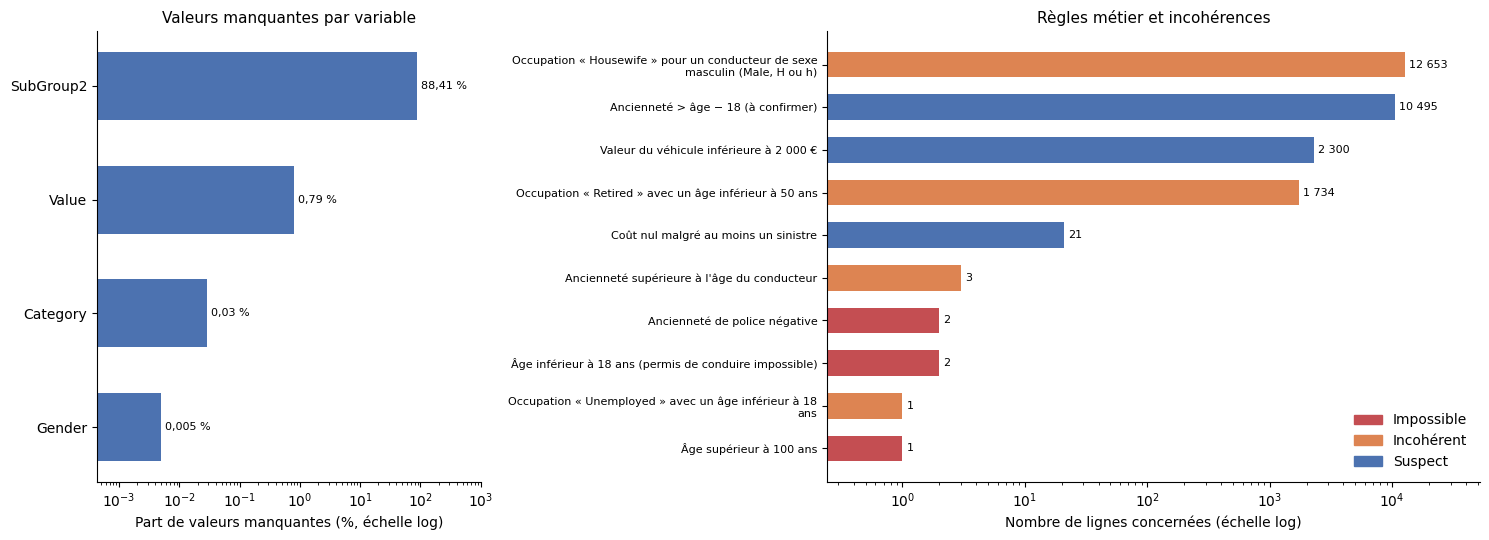

#### Points clés
- La variable la plus incomplète est **SubGroup2** (88,4 % de manquants) ; toutes les autres ont moins de 0,8 % de manquants.
- Les valeurs **impossibles** touchent 5 lignes au total ; les cas **suspects ou incohérents**, 27 207 lignes.

#### Interprétation
- Avec 88 % de valeurs manquantes, SubGroup2 ne peut pas servir de variable explicative : l'imputer reviendrait à inventer l'essentiel de son contenu. On garde seulement un indicateur « renseigné / non renseigné ».
- Pour les autres variables, moins de 0,8 % de manquants : une imputation simple (médiane, modalité la plus fréquente) ne peut pas biaiser sensiblement les résultats.
- Les deux types d'anomalies n'appellent pas le même traitement. Les valeurs **impossibles** sont rares : on peut les corriger ou les retirer une par une. Les cas **suspects ou incohérents** sont massifs : ce sont des problèmes de codage ou de définition, à signaler plutôt qu'à supprimer, sinon on perdrait une grande partie du portefeuille.

In [6]:
import textwrap  # coupe les libellés trop longs sur plusieurs lignes

taille_table = dbl["nb_lignes"]  # nombre de lignes de chaque table brute
manq = res["manquants"].query("nb_total_manquants > 0").copy()  # variables avec au moins une valeur manquante
manq["pct_reel"] = 100 * manq["nb_total_manquants"] / manq["table"].map(taille_table)  # part exacte (non arrondie)
manq = manq.sort_values("pct_reel")  # de la plus petite à la plus grande part
regles_q = pd.concat([res["regles"][["categorie", "regle", "nb_lignes"]],  # règles métier
                      inc.assign(categorie="Incohérent")[["regle", "nb_lignes", "categorie"]]])  # incohérences
regles_q = regles_q[regles_q["nb_lignes"] > 0].sort_values("nb_lignes")  # seulement les règles qui se déclenchent
COUL_GRAVITE = {"Impossible": ROUGE, "Incohérent": ORANGE, "Suspect": BLEU}  # une couleur par gravité

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.7]})  # deux graphiques
ax1.barh(manq["variable"], manq["pct_reel"], color=BLEU, height=0.6)  # part de manquants
ax1.bar_label(ax1.containers[0], labels=[(f"{v:.3f} %" if v < 0.01 else f"{v:.2f} %").replace(".", ",") for v in manq["pct_reel"]], padding=3, fontsize=8)
ax1.set_xscale("log")  # échelle logarithmique
ax1.margins(x=0.25)  # place pour les étiquettes
ax1.set_xlabel("Part de valeurs manquantes (%, échelle log)")  # axe horizontal
ax1.set_title("Valeurs manquantes par variable")  # titre
ax2.barh([textwrap.fill(r, 55) for r in regles_q["regle"]], regles_q["nb_lignes"],  # lignes touchées par règle
         color=regles_q["categorie"].map(COUL_GRAVITE), height=0.6)
ax2.bar_label(ax2.containers[0], labels=[nb_fr(v) for v in regles_q["nb_lignes"]], padding=3, fontsize=8)
ax2.set_xscale("log")  # échelle logarithmique
ax2.margins(x=0.15)  # place pour les étiquettes
ax2.tick_params(axis="y", labelsize=8)  # libellés plus petits
ax2.set_xlabel("Nombre de lignes concernées (échelle log)")  # axe horizontal
ax2.set_title("Règles métier et incohérences")  # titre
ax2.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COUL_GRAVITE.values()],  # légende des gravités
           labels=list(COUL_GRAVITE), loc="lower right")
plt.tight_layout()  # ajuste les marges
montrer_fig("qualite_donnees")  # affiche et enregistre la figure

n_impossible = regles_q.loc[regles_q["categorie"] == "Impossible", "nb_lignes"].sum()  # lignes impossibles
n_suspect = regles_q.loc[regles_q["categorie"] != "Impossible", "nb_lignes"].sum()  # lignes suspectes ou incohérentes
var_max = manq.iloc[-1]  # variable la plus incomplète
autres_max = manq.iloc[:-1]["pct_reel"].max()  # part maximale des autres variables
points_cles(
    f"La variable la plus incomplète est **{var_max['variable']}** ({var_max['pct_reel']:.1f} % de manquants) ; "
    f"toutes les autres ont moins de {autres_max:.1f} % de manquants.",
    f"Les valeurs **impossibles** touchent {nb_fr(n_impossible)} lignes au total ; les cas **suspects ou incohérents**, "
    f"{nb_fr(n_suspect)} lignes.",
)
interpretation(
    f"Avec {var_max['pct_reel']:.0f} % de valeurs manquantes, {var_max['variable']} ne peut pas servir de variable "
    "explicative : l'imputer reviendrait à inventer l'essentiel de son contenu. On garde seulement un indicateur "
    "« renseigné / non renseigné ».",
    f"Pour les autres variables, moins de {autres_max:.1f} % de manquants : une imputation simple (médiane, modalité "
    "la plus fréquente) ne peut pas biaiser sensiblement les résultats.",
    "Les deux types d'anomalies n'appellent pas le même traitement. Les valeurs **impossibles** sont rares : on peut "
    "les corriger ou les retirer une par une. Les cas **suspects ou incohérents** sont massifs : ce sont des "
    "problèmes de codage ou de définition, à signaler plutôt qu'à supprimer, sinon on perdrait une grande partie du portefeuille.",
)
pour_rapport("qualite_donnees", "Étapes 1-2 : localisation des problèmes de qualité",
             "Valeurs manquantes par variable et lignes touchées par chaque règle métier (échelles logarithmiques).")

### Étape 3 — Nettoyage et préparation

**Objectif.** Corriger les anomalies de l'audit et créer les variables nécessaires à l'analyse.

**Méthode.** Chaque correction est notée dans un **journal des décisions** (action, nombre de lignes, justification). Puis on crée les variables actuarielles :
- *exposition* = jours couverts / 365 ;
- *fréquence annuelle* = nombre de sinistres / exposition ;
- *coût moyen par sinistre* = coût total / nombre de sinistres.

**Comment lire.** Le tableau des vérifications doit être entièrement « OK » : c'est la garantie que la base est exploitable.

#### Code : nettoyage et préparation

Définition des fonctions de l'étape. Le résultat de leur exécution s'affiche dans la cellule suivante.

In [7]:
# ===========================================================================
# ÉTAPE 3 – NETTOYAGE ET PRÉPARATION
# ===========================================================================


JOURNAL = []


def journaliser(etape, table, variable, action, effectif, justification):
    JOURNAL.append({"etape": etape, "table": table, "variable": variable, "action": action,
                    "nb_lignes": int(effectif), "justification": justification})


def charger_nettoyage():
    sin = pd.read_csv(FICHIER_CSV, sep=";", dtype=str, keep_default_na=False)
    wb = load_workbook(FICHIER_XLSX, read_only=True, data_only=True)
    feuilles = {}
    for ws in wb.worksheets:
        rows = list(ws.iter_rows(values_only=True))
        feuilles[ws.title] = pd.DataFrame(rows[1:], columns=rows[0])
    # Repère les polices dont la catégorie est une formule Excel (valeur en cache conservée)
    formules = set()
    ws = load_workbook(FICHIER_XLSX, read_only=True)["PTF"]
    rows = ws.iter_rows(values_only=True)
    entete = next(rows)
    i_cat, i_pol = entete.index("Category"), entete.index("PolNum")
    for r in rows:
        if isinstance(r[i_cat], str) and r[i_cat].startswith("="):
            formules.add(int(r[i_pol]))
    return sin, feuilles["PTF"], feuilles["Expo"], formules


def nettoyer_doublons(sin, ptf, expo):
    # Sinistres : lignes identiques = double saisie
    n_avant = len(sin)
    cout_doublons = pd.to_numeric(sin[sin.duplicated()]["chg_sin"].str.replace(",", ".", regex=False)).sum()
    sin = sin.drop_duplicates().reset_index(drop=True)
    journaliser("1. Doublons", "sinistres", "toutes", "Suppression des lignes identiques",
                n_avant - len(sin),
                "Ligne strictement identique à une autre : double saisie, aucune information ajoutée.")

    # Portefeuille : doublons exacts
    n_avant = len(ptf)
    ptf = ptf.drop_duplicates().reset_index(drop=True)
    journaliser("1. Doublons", "portefeuille", "toutes", "Suppression des lignes identiques",
                n_avant - len(ptf), "Ligne identique répétée : une police = une ligne.")

    # Portefeuille : même PolNum, contenu différent -> garder la ligne la plus complète et plausible
    n_conflits = 0
    garder = []
    for pol, grp in ptf.groupby("PolNum", sort=False):
        if len(grp) == 1:
            garder.append(grp.index[0])
            continue
        n_conflits += len(grp) - 1
        completude = grp.notna().sum(axis=1)
        plausible = grp["Poldur"] <= grp["Age"] - 18
        classement = pd.DataFrame({"compl": completude, "plaus": plausible}).sort_values(
            ["plaus", "compl"], ascending=False)
        garder.append(classement.index[0])
        ecarts = grp.loc[:, grp.nunique(dropna=False) > 1].columns.tolist()
        if ecarts == ["SubGroup2"]:
            motif = "Même police, une ligne sans SubGroup2 : on garde la ligne complète."
        else:
            motif = f"Conflit sur {', '.join(ecarts)} : on garde la valeur plausible (ancienneté ≤ âge − 18)."
        journaliser("1. Doublons", "portefeuille", "PolNum " + str(pol), "Conflit résolu : une ligne gardée",
                    len(grp) - 1, motif)
    ptf = ptf.loc[garder].reset_index(drop=True)

    # Exposition : doublons exacts
    n_avant = len(expo)
    expo = expo.drop_duplicates().reset_index(drop=True)
    journaliser("1. Doublons", "exposition", "toutes", "Suppression des lignes identiques",
                n_avant - len(expo), "Ligne identique répétée : une police = une exposition.")
    return sin, ptf, expo, cout_doublons


def corriger_formats(sin, ptf, expo, formules):
    # Sinistres : décimale en virgule, nombres entiers
    sin["chg_sin"] = pd.to_numeric(sin["chg_sin"].str.replace(",", ".", regex=False), errors="coerce")
    sin["nb_sin"] = pd.to_numeric(sin["nb_sin"], errors="coerce").astype("Int64")
    sin["PolNum"] = pd.to_numeric(sin["PolNum"], errors="coerce").astype("Int64")
    journaliser("2. Formats", "sinistres", "chg_sin", "Conversion en nombre (virgule décimale)",
                len(sin), "Le fichier utilise la virgule comme séparateur décimal.")

    # Portefeuille : Density stocké en texte
    n_texte = int(ptf["Density"].apply(lambda x: isinstance(x, str)).sum())
    ptf["Density"] = pd.to_numeric(ptf["Density"], errors="coerce")
    journaliser("2. Formats", "portefeuille", "Density", "Conversion texte vers nombre", n_texte,
                "Densité stockée comme texte dans l'Excel.")

    # Value : code '??' -> manquant
    n_codes = int((ptf["Value"] == "??").sum())
    ptf["Value"] = ptf["Value"].replace({"??": np.nan})
    ptf["Value"] = pd.to_numeric(ptf["Value"], errors="coerce")
    journaliser("2. Formats", "portefeuille", "Value", "Code '??' remplacé par manquant", n_codes,
                "Code textuel signalant une absence de valeur.")

    # Gender : codes normalisés
    avant = ptf["Gender"].copy()
    ptf["Gender"] = ptf["Gender"].replace({"H": "Male", "h": "Male", "F": "Female"})
    ptf["Gender"] = ptf["Gender"].fillna("Inconnu")
    n_norm = int((avant.isin(["H", "h", "F"])).sum())
    journaliser("2. Formats", "portefeuille", "Gender", "Normalisation H/h -> Male, F -> Female", n_norm,
                "Hypothèse : H = homme, F = femme (codes français). À confirmer avec le producteur.")
    journaliser("2. Formats", "portefeuille", "Gender", "Manquant renseigné « Inconnu »",
                int(avant.isna().sum()), "Cinq polices sans sexe : pas d'imputation fiable.")

    # Category : '???' -> 'Inconnue' (pas d'imputation), indicateur de source
    n_inc = int((ptf["Category"] == "???").sum())
    ptf["Category"] = ptf["Category"].replace({"???": "Inconnue"})
    ptf["categorie_source"] = np.where(ptf["PolNum"].isin(formules), "formule_externe", "valeur")
    journaliser("2. Formats", "portefeuille", "Category", "Code '???' remplacé par « Inconnue »", n_inc,
                "Pas d'imputation fiable (0,03 % des lignes). Valeurs issues de formules conservées en cache.")

    # SubGroup2 : indicateur de renseignement, colonne conservée
    ptf["subgroupe_renseigne"] = ptf["SubGroup2"].notna().astype(int)
    journaliser("2. Formats", "portefeuille", "SubGroup2", "Indicateur de renseignement créé",
                len(ptf), "88 % de valeurs manquantes : colonne conservée mais non imputée.")

    ptf["PolNum"] = pd.to_numeric(ptf["PolNum"], errors="coerce").astype("Int64")
    expo["PolNum"] = pd.to_numeric(expo["PolNum"], errors="coerce").astype("Int64")
    expo["Expdays"] = pd.to_numeric(expo["Expdays"], errors="coerce").astype("Int64")
    return sin, ptf, expo


def traiter_valeurs(ptf):
    ptf = ptf.copy()

    # Âges impossibles -> manquants puis imputation par la médiane de la profession
    impossibles = (ptf["Age"] > 100) | (ptf["Age"] < 18)
    n_imp_age = int(impossibles.sum())
    ptf["age_imputee"] = impossibles.astype(int)
    ptf.loc[impossibles, "Age"] = np.nan
    med_age = ptf.groupby("Occupation")["Age"].transform("median")
    ptf["Age"] = ptf["Age"].fillna(med_age)
    journaliser("3. Valeurs impossibles", "portefeuille", "Age",
                "Âge > 100 ou < 18 remplacé par la médiane de la profession", n_imp_age,
                "Âge de 250 ans ou permis impossible à 16 ans : erreur de saisie. Imputation signalée.")

    # Ancienneté négative -> manquant puis médiane
    neg = ptf["Poldur"] < 0
    ptf["poldur_imputee"] = neg.astype(int)
    ptf.loc[neg, "Poldur"] = np.nan
    ptf["Poldur"] = ptf["Poldur"].fillna(ptf["Poldur"].median())
    journaliser("3. Valeurs impossibles", "portefeuille", "Poldur",
                "Ancienneté négative remplacée par la médiane", int(neg.sum()),
                "Une ancienneté négative est impossible.")

    # Ancienneté incohérente avec l'âge : signalée, non modifiée
    ptf["poldur_incoherente"] = (ptf["Poldur"] > ptf["Age"]).astype(int)
    journaliser("3. Valeurs impossibles", "portefeuille", "Poldur",
                "Signalement : ancienneté supérieure à l'âge (non modifiée)",
                int(ptf["poldur_incoherente"].sum()), "Cas peu nombreux, à confirmer avec le producteur.")

    # Valeur du véhicule manquante -> médiane par type et catégorie
    manquante = ptf["Value"].isna()
    ptf["value_imputee"] = manquante.astype(int)
    med = ptf.groupby(["Type", "Category"])["Value"].transform("median")
    ptf["Value"] = ptf["Value"].fillna(med).fillna(ptf["Value"].median())
    journaliser("3. Valeurs manquantes", "portefeuille", "Value",
                "Imputation par la médiane (type, catégorie)", int(manquante.sum()),
                "Valeur manquante pour 0,8 % des polices. Médiane par groupe homogène ; imputation signalée.")

    # Valeurs extrêmes : signalées uniquement
    seuil_value = ptf["Value"].quantile(0.99)
    ptf["value_extreme"] = (ptf["Value"] > seuil_value).astype(int)
    journaliser("4. Valeurs aberrantes", "portefeuille", "Value",
                "Signalement des valeurs au-delà du 99e centile (non modifiées)",
                int(ptf["value_extreme"].sum()), "Véhicule de forte valeur : réel, conservé.")

    # Densité, Bonus : aucune modification
    journaliser("4. Valeurs aberrantes", "portefeuille", "Bonus",
                "Aucune modification", int(ptf["Bonus"].notna().sum()),
                "Coefficient bonus-malus dans une plage plausible (-50 à 150) : queue longue conservée.")
    return ptf


def traiter_sinistres(sin):
    sin = sin.copy()
    # Coût nul : conservé (sinistre clos sans paiement possible), signalé
    sin["cout_nul"] = ((sin["chg_sin"] == 0) & (sin["nb_sin"] > 0)).astype(int)
    journaliser("4. Valeurs aberrantes", "sinistres", "chg_sin",
                "Signalement des coûts nuls (non modifiés)", int(sin["cout_nul"].sum()),
                "Sinistre déclaré sans coût : peut être un dossier clos sans paiement. À confirmer.")

    # Sinistres extrêmes : signalés, non plafonnés
    positifs = sin.loc[sin["chg_sin"] > 0, "chg_sin"]
    p99 = positifs.quantile(0.99)
    sin["sinistre_extreme"] = (sin["chg_sin"] > p99).astype(int)
    journaliser("4. Valeurs aberrantes", "sinistres", "chg_sin",
                "Signalement des sinistres au-delà du 99e centile (non modifiés)",
                int(sin["sinistre_extreme"].sum()),
                "Sinistre exceptionnel potentiellement réel : conservé. Pris en compte dans le coût total.")
    # Version plafonnée à titre de sensibilité uniquement (non utilisée par défaut)
    p995 = positifs.quantile(0.995)
    sin["chg_sin_plafonne_sensibilite"] = sin["chg_sin"].clip(upper=p995)
    journaliser("4. Valeurs aberrantes", "sinistres", "chg_sin_plafonne_sensibilite",
                "Variable de sensibilité créée (plafond au 99,5e centile)", int(len(sin)),
                "Permet de mesurer l'impact des extrêmes. Non utilisée par défaut.")
    return sin


def construire_base(ptf, expo, sin):
    # Agrégation des sinistres par police
    sin_agg = sin.groupby("PolNum").agg(
        nb_sinistres=("nb_sin", "sum"),
        cout_total=("chg_sin", "sum"),
        nb_lignes_sinistres=("PolNum", "size"),
        nb_sinistres_extremes=("sinistre_extreme", "sum"),
    ).reset_index()

    base = ptf.merge(expo, on="PolNum", how="inner", validate="one_to_one")
    base = base.merge(sin_agg, on="PolNum", how="left", validate="one_to_one")
    for c in ["nb_sinistres", "cout_total", "nb_lignes_sinistres", "nb_sinistres_extremes"]:
        base[c] = base[c].fillna(0)
    base["nb_sinistres"] = base["nb_sinistres"].astype(int)
    base["nb_lignes_sinistres"] = base["nb_lignes_sinistres"].astype(int)
    base["nb_sinistres_extremes"] = base["nb_sinistres_extremes"].astype(int)

    # Variables créées
    base["expo_annees"] = base["Expdays"].astype(float) / 365.0
    base["a_sinistre"] = (base["nb_sinistres"] > 0).astype(int)
    base["frequence_annuelle"] = base["nb_sinistres"] / base["expo_annees"]
    base["cout_moyen_par_sinistre"] = np.where(base["nb_sinistres"] > 0,
                                               base["cout_total"] / base["nb_sinistres"].replace(0, np.nan),
                                               np.nan)
    base["tranche_age"] = pd.cut(base["Age"].astype(float), bins=[17, 25, 35, 50, 65, 120],
                                 labels=["18-25", "26-35", "36-50", "51-65", "66+"]).astype(str)
    base["tranche_anciennete"] = pd.cut(base["Poldur"].astype(float), bins=[-1, 1, 4, 9, 1000],
                                        labels=["0-1", "2-4", "5-9", "10+"]).astype(str)
    base["log_valeur"] = np.log(base["Value"].astype(float))
    base["quartile_valeur"] = pd.qcut(base["Value"].astype(float), 4,
                                      labels=["Q1", "Q2", "Q3", "Q4"]).astype(str)
    base["sexe_renseigne"] = (base["Gender"] != "Inconnu").astype(int)
    return base


def variables_creees() -> pd.DataFrame:
    return pd.DataFrame([
        ("expo_annees", "Exposition en années (Expdays / 365)", "Dénominateur des fréquences"),
        ("nb_sinistres", "Nombre total de sinistres de la police", "Somme de nb_sin"),
        ("cout_total", "Coût total des sinistres de la police", "Somme de chg_sin"),
        ("a_sinistre", "1 si la police a au moins un sinistre", "Variable binaire"),
        ("frequence_annuelle", "Nombre de sinistres par année d'exposition", "nb_sinistres / expo_annees"),
        ("cout_moyen_par_sinistre", "Coût moyen par sinistre", "cout_total / nb_sinistres (si > 0)"),
        ("tranche_age", "Tranche d'âge du conducteur", "18-25, 26-35, 36-50, 51-65, 66+"),
        ("tranche_anciennete", "Tranche d'ancienneté de la police", "0-1, 2-4, 5-9, 10+ ans"),
        ("log_valeur", "Logarithme de la valeur du véhicule", "Pour les modèles multiplicatifs"),
        ("quartile_valeur", "Quartile de valeur du véhicule", "Q1 à Q4"),
        ("sexe_renseigne", "1 si le sexe est renseigné", "Indicateur de qualité"),
        ("nb_sinistres_extremes", "Sinistres au-delà du 99e centile", "Signalement, sans suppression"),
        ("subgroupe_renseigne", "1 si SubGroup2 est renseigné", "Indicateur de qualité"),
        ("age_imputee / poldur_imputee / value_imputee", "1 si la valeur a été imputée", "Traçabilité"),
        ("poldur_incoherente", "1 si ancienneté > âge", "Signalement"),
        ("categorie_source", "formule_externe ou valeur", "Traçabilité de la catégorie"),
    ], columns=["variable", "description", "calcul"])


def verifier(base, sin_clean, sin_raw_total, cout_doublons, ptf_avant, sin_avant, sinistres_sans_police):
    controles = []

    def ajouter(nom, ok, detail):
        controles.append({"controle": nom, "resultat": "OK" if ok else "ÉCHEC", "detail": detail})

    ajouter("Une ligne par police dans la base", base["PolNum"].is_unique, f"{len(base)} polices")
    ajouter("Pas de valeur manquante sur les champs clés",
            base[["PolNum", "Age", "Value", "Expdays", "Gender", "Poldur"]].isna().sum().sum() == 0,
            "PolNum, Age, Value, Expdays, Gender, Poldur")
    ajouter("Expdays entre 1 et 365", base["Expdays"].between(1, 365).all(),
            f"min {int(base['Expdays'].min())}, max {int(base['Expdays'].max())}")
    ajouter("Âge entre 18 et 100 après nettoyage", base["Age"].between(18, 100).all(),
            f"min {base['Age'].min():.0f}, max {base['Age'].max():.0f}")
    ajouter("Ancienneté positive ou nulle", (base["Poldur"] >= 0).all(), f"min {base['Poldur'].min():.0f}")
    ajouter("Valeur du véhicule strictement positive", (base["Value"] > 0).all(),
            f"min {base['Value'].min():,.0f}".replace(",", " "))
    ajouter("Aucun code textuel restant dans Category (hors « Inconnue »)",
            not base["Category"].isin(["???", "??"]).any(), f"{int((base['Category'] == 'Inconnue').sum())} « Inconnue »")
    ajouter("Sexe normalisé", set(base["Gender"].unique()) <= {"Male", "Female", "Inconnu"},
            ", ".join(sorted(base["Gender"].unique())))
    ajouter("Fréquences positives ou nulles", (base["frequence_annuelle"].dropna() >= 0).all(),
            f"max {base['frequence_annuelle'].max():.2f}")
    ajouter("Aucun sinistre perdu : total des nb_sin conservé",
            int(base["nb_sinistres"].sum()) == int(sin_clean.loc[sin_clean["PolNum"].isin(base["PolNum"]), "nb_sin"].sum()),
            f"{int(base['nb_sinistres'].sum())} sinistres dans la base")
    total_base = base["cout_total"].sum()
    total_clean = sin_clean.loc[sin_clean["PolNum"].isin(base["PolNum"]), "chg_sin"].sum()
    ajouter("Coût total rapproché (base = sinistres nettoyés rattachés)",
            abs(total_base - total_clean) < 0.01,
            f"{total_base:,.2f} € dans la base".replace(",", " "))
    ajouter("Coût total rapproché (brut − doublons supprimés = nettoyé)",
            abs((sin_raw_total - cout_doublons) - sin_clean["chg_sin"].sum()) < 0.01,
            f"brut {sin_raw_total:,.2f} − doublons {cout_doublons:,.2f} = nettoyé {sin_clean['chg_sin'].sum():,.2f}"
            .replace(",", " "))
    ajouter("Aucun doublon de police dans l'exposition de la base", base["PolNum"].duplicated().sum() == 0,
            "contrôle d'unicité")
    ajouter("Sinistres hors portefeuille exclus et comptés",
            sinistres_sans_police["nb_lignes"] > 0,
            f"{sinistres_sans_police['polices']} polices, {sinistres_sans_police['nb_lignes']} lignes exclues de la base")
    return pd.DataFrame(controles)


def etape3() -> dict:
    sin, ptf, expo, formules = charger_nettoyage()
    sin_raw_total = pd.to_numeric(sin["chg_sin"].str.replace(",", ".", regex=False)).sum()
    avant = {"sin_avant": len(sin), "ptf_avant": len(ptf), "expo_avant": len(expo)}

    JOURNAL.clear()
    sin, ptf, expo, cout_doublons = nettoyer_doublons(sin, ptf, expo)
    sin, ptf, expo = corriger_formats(sin, ptf, expo, formules)
    ptf = traiter_valeurs(ptf)
    sin = traiter_sinistres(sin)

    hors = sin[~sin["PolNum"].isin(ptf["PolNum"])]
    sinistres_sans_police = {"polices": int(hors["PolNum"].nunique()), "nb_lignes": len(hors)}
    journaliser("5. Jointure", "sinistres", "PolNum",
                "Sinistres sans police dans le portefeuille : conservés dans sinistres_nettoyes, exclus de la base",
                len(hors), "Pas de caractéristiques de risque disponibles pour ces polices. À traiter séparément.")

    base = construire_base(ptf, expo, sin)
    creees = variables_creees()
    verif = verifier(base, sin, sin_raw_total, cout_doublons, len(ptf), len(sin), sinistres_sans_police)

    verif.to_csv(SORTIE / "etape3_verifications.csv", index=False, sep=";")
    pd.DataFrame(JOURNAL).to_csv(SORTIE / "etape3_journal_decisions.csv", index=False, sep=";")
    creees.to_csv(SORTIE / "etape3_variables_creees.csv", index=False, sep=";")
    base.to_csv(SORTIE / "etape3_base_polices.csv", index=False, sep=";", decimal=",")
    sin.to_csv(SORTIE / "etape3_sinistres_nettoyes.csv", index=False, sep=";", decimal=",")

    echec = verif[verif["resultat"] != "OK"]
    print(f"Étape 3 : base de {len(base)} polices, {len(sin)} sinistres nettoyés, "
          f"{len(JOURNAL)} décisions, {len(echec)} contrôle(s) en échec")
    return {"journal": list(JOURNAL), "verif": verif, "creees": creees,
            "base_n": len(base), "base": base, "ptf": ptf, "expo": expo, "sin": sin,
            "avant_apres": {**avant, "sin_apres": len(sin), "ptf_apres": len(ptf), "expo_apres": len(expo)}}


def section_etape3(e3: dict) -> str:
    journal, verif, creees, avant_apres, base_n = (
        e3["journal"], e3["verif"], e3["creees"], e3["avant_apres"], e3["base_n"])
    principes = (
        "\\section{Objectif et principes}\n"
        "L'objectif est d'obtenir une base fiable pour les analyses. Trois principes guident les décisions :\n"
        "\\begin{itemize}\n"
        "  \\item \\textbf{Aucune suppression automatique des valeurs extrêmes.} Un sinistre exceptionnel peut "
        "être réel et actuariellement important : les extrêmes sont signalés, jamais retirés.\n"
        "  \\item \\textbf{Traçabilité.} Chaque décision est journalisée (table, variable, effectif, justification), "
        "et chaque imputation est signalée par une variable indicatrice.\n"
        "  \\item \\textbf{Vérification.} Les totaux sont rapprochés avant et après nettoyage.\n"
        "\\end{itemize}\n")
    lignes_av = [
        ["Sinistres", nombre(avant_apres["sin_avant"]), nombre(avant_apres["sin_apres"])],
        ["Polices du portefeuille", nombre(avant_apres["ptf_avant"]), nombre(avant_apres["ptf_apres"])],
        ["Lignes d'exposition", nombre(avant_apres["expo_avant"]), nombre(avant_apres["expo_apres"])],
        ["Polices dans la base finale", "--", nombre(base_n)],
    ]
    lignes_j = [[echapper(r["etape"]), echapper(r["table"]), r"\texttt{" + var_tex(r["variable"]) + "}",
                 echapper(r["action"]), nombre(r["nb_lignes"]), echapper(r["justification"])]
                for r in journal]
    lignes_v = [[echapper(r["controle"]), echapper(r["resultat"]), echapper(r["detail"])]
                for r in verif.to_dict("records")]
    lignes_c = [[r"\texttt{" + var_tex(r["variable"]) + "}", echapper(r["description"]), echapper(r["calcul"])]
                for r in creees.to_dict("records")]
    return (
        "\n\\part{Étape 3 -- Nettoyage et préparation des données}\n\\section{Objectif}\n"
        "Obtenir une base fiable pour les analyses, sans supprimer les valeurs extrêmes réelles.\n"
        + principes
        + "\\section{Effectifs avant et après nettoyage}\n"
        + tableau("Effectifs avant et après nettoyage", "tab:effectifs", ["Table", "Avant", "Après"],
                  lignes_av, "lrr")
        + "\\section{Journal des décisions}\n"
        "Chaque ligne correspond à une décision. Les effectifs indiquent le nombre de lignes concernées.\n"
        + tableau("Journal des décisions", "tab:journal",
                  ["Étape", "Table", "Variable", "Action", "Lignes", "Justification"], lignes_j,
                  "p{1.8cm}p{1.9cm}p{2.4cm}p{3.2cm}r p{4.0cm}")
        + "\\section{Vérifications après nettoyage}\n"
        + tableau("Contrôles après nettoyage", "tab:verif", ["Contrôle", "Résultat", "Détail"], lignes_v,
                  "p{6.5cm}lp{5.5cm}")
        + "\\section{Variables créées}\n"
        + tableau("Variables créées pour l'analyse", "tab:creees", ["Variable", "Description", "Calcul"],
                  lignes_c, "p{4.2cm}p{5.3cm}p{5cm}")
        + "\\section{Points à valider}\n\\begin{enumerate}\n"
        "  \\item Le sens des codes \\texttt{H}, \\texttt{h} et \\texttt{F} (hypothèse : homme, femme).\n"
        "  \\item L'explication de l'incohérence sexe × profession signalée à l'étape 2.\n"
        "  \\item Le conflit de \\texttt{Poldur} pour une police (une seule ligne retenue selon la plausibilité).\n"
        "  \\item La signification des coûts nuls et de la période d'observation des sinistres.\n"
        "  \\item La version de sensibilité plafonnée au 99,5e centile : à utiliser seulement pour comparer les "
        "résultats, jamais en remplacement des valeurs réelles.\n"
        "\\end{enumerate}\n")

print("Fonctions chargées (11) ; fonction principale : etape3()")  # confirme l'exécution de la cellule


Fonctions chargées (11) ; fonction principale : etape3()


In [8]:
res["etape3"] = lancer("Étape 3", etape3, "etape3")  # base nettoyée, stockée dans res
e3 = res["etape3"]  # raccourci

afficher(pd.DataFrame(e3["journal"]), "Journal des décisions de nettoyage", 30)  # chaque correction et sa raison
afficher(e3["creees"], "Variables créées", 20)  # nouvelles variables
afficher(e3["verif"], "Vérifications après nettoyage", 20)  # contrôles de qualité finaux

aa = e3["avant_apres"]  # effectifs avant et après nettoyage
echecs = (e3["verif"]["resultat"] != "OK").sum()  # nombre de contrôles en échec
points_cles(  # constats chiffrés
    f"Sinistres : {nb_fr(aa['sin_avant'])} → **{nb_fr(aa['sin_apres'])} lignes** "
    f"({nb_fr(aa['sin_avant'] - aa['sin_apres'])} retirées).",
    f"Portefeuille : {nb_fr(aa['ptf_avant'])} → **{nb_fr(aa['ptf_apres'])} polices** ; "
    f"exposition : {nb_fr(aa['expo_avant'])} → {nb_fr(aa['expo_apres'])} lignes.",
    f"{len(e3['journal'])} décisions de nettoyage documentées, {len(e3['creees'])} variables créées.",
    "Tous les contrôles sont OK." if echecs == 0 else f"{echecs} contrôle(s) en échec : voir le tableau ci-dessus.",
)

perte_sin = 100 * (aa["sin_avant"] - aa["sin_apres"]) / aa["sin_avant"]  # part des sinistres retirés
interpretation(  # ce que le nettoyage veut dire
    verdict(perte_sin < 1, f"Le nettoyage ne retire que {perte_sin:.2f} % des sinistres : la base reste représentative, "
            "le risque de biais lié au nettoyage est négligeable.",
            f"{perte_sin:.1f} % des sinistres ont été retirés : vérifier que ces lignes ne concernent pas un profil "
            "particulier, sinon la base nettoyée serait biaisée (biais de sélection)."),
    verdict(echecs == 0, "Tous les contrôles passent après nettoyage : la base peut servir aux analyses.",
            "Des contrôles échouent : il faut les comprendre avant d'aller plus loin."),
    "Le journal des décisions rend le nettoyage **traçable et reproductible** : chaque correction peut être "
    "vérifiée ou contestée une par une (exigence classique d'un audit de données actuarielles).",
)

Étape 3 : base de 100000 polices, 13288 sinistres nettoyés, 25 décisions, 0 contrôle(s) en échec


*Étape 3 terminée en 10.6 s*

**Journal des décisions de nettoyage** — 25 lignes × 6 colonnes

,etape,table,variable,action,nb_lignes,justification
0,1. Doublons,sinistres,toutes,Suppression des lignes identiques,12,"Ligne strictement identique à une autre : double saisie, aucune information ..."
1,1. Doublons,portefeuille,toutes,Suppression des lignes identiques,22,Ligne identique répétée : une police = une ligne.
2,1. Doublons,portefeuille,PolNum 200114994,Conflit résolu : une ligne gardée,1,"Même police, une ligne sans SubGroup2 : on garde la ligne complète."
3,1. Doublons,portefeuille,PolNum 200115001,Conflit résolu : une ligne gardée,1,"Même police, une ligne sans SubGroup2 : on garde la ligne complète."
4,1. Doublons,portefeuille,PolNum 200115043,Conflit résolu : une ligne gardée,1,"Même police, une ligne sans SubGroup2 : on garde la ligne complète."
5,1. Doublons,portefeuille,PolNum 200115070,Conflit résolu : une ligne gardée,1,"Même police, une ligne sans SubGroup2 : on garde la ligne complète."
6,1. Doublons,portefeuille,PolNum 200115169,Conflit résolu : une ligne gardée,1,Conflit sur Poldur : on garde la valeur plausible (ancienneté ≤ âge − 18).
7,1. Doublons,exposition,toutes,Suppression des lignes identiques,21,Ligne identique répétée : une police = une exposition.
8,2. Formats,sinistres,chg_sin,Conversion en nombre (virgule décimale),13288,Le fichier utilise la virgule comme séparateur décimal.
9,2. Formats,portefeuille,Density,Conversion texte vers nombre,100000,Densité stockée comme texte dans l'Excel.


**Variables créées** — 16 lignes × 3 colonnes

,variable,description,calcul
0,expo_annees,Exposition en années (Expdays / 365),Dénominateur des fréquences
1,nb_sinistres,Nombre total de sinistres de la police,Somme de nb_sin
2,cout_total,Coût total des sinistres de la police,Somme de chg_sin
3,a_sinistre,1 si la police a au moins un sinistre,Variable binaire
4,frequence_annuelle,Nombre de sinistres par année d'exposition,nb_sinistres / expo_annees
5,cout_moyen_par_sinistre,Coût moyen par sinistre,cout_total / nb_sinistres (si > 0)
6,tranche_age,Tranche d'âge du conducteur,"18-25, 26-35, 36-50, 51-65, 66+"
7,tranche_anciennete,Tranche d'ancienneté de la police,"0-1, 2-4, 5-9, 10+ ans"
8,log_valeur,Logarithme de la valeur du véhicule,Pour les modèles multiplicatifs
9,quartile_valeur,Quartile de valeur du véhicule,Q1 à Q4


**Vérifications après nettoyage** — 14 lignes × 3 colonnes

,controle,resultat,detail
0,Une ligne par police dans la base,OK,100000 polices
1,Pas de valeur manquante sur les champs clés,OK,"PolNum, Age, Value, Expdays, Gender, Poldur"
2,Expdays entre 1 et 365,OK,"min 91, max 365"
3,Âge entre 18 et 100 après nettoyage,OK,"min 18, max 75"
4,Ancienneté positive ou nulle,OK,min 0
5,Valeur du véhicule strictement positive,OK,min 1 000
6,Aucun code textuel restant dans Category (hors « Inconnue »),OK,29 « Inconnue »
7,Sexe normalisé,OK,"Female, Inconnu, Male"
8,Fréquences positives ou nulles,OK,max 7.30
9,Aucun sinistre perdu : total des nb_sin conservé,OK,14748 sinistres dans la base


#### Points clés
- Sinistres : 13 300 → **13 288 lignes** (12 retirées).
- Portefeuille : 100 027 → **100 000 polices** ; exposition : 100 021 → 100 000 lignes.
- 25 décisions de nettoyage documentées, 16 variables créées.
- Tous les contrôles sont OK.

#### Interprétation
- Le nettoyage ne retire que 0,09 % des sinistres : la base reste représentative, le risque de biais lié au nettoyage est négligeable.
- Tous les contrôles passent après nettoyage : la base peut servir aux analyses.
- Le journal des décisions rend le nettoyage **traçable et reproductible** : chaque correction peut être vérifiée ou contestée une par une (exigence classique d'un audit de données actuarielles).

#### Graphique : impact de chaque phase du nettoyage
Nombre de lignes touchées par phase du journal, en séparant les **suppressions** (lignes retirées) des **corrections** (valeurs modifiées, imputées ou signalées ; une même ligne peut recevoir plusieurs corrections, par exemple une par colonne convertie). Échelle logarithmique.

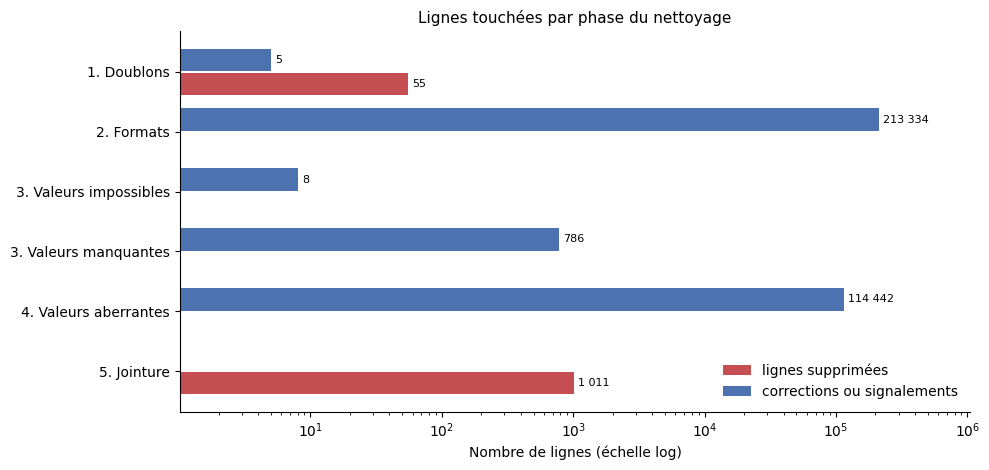

#### Points clés
- 1 066 lignes supprimées contre 328 575 corrections ou signalements de valeurs (une même ligne peut être corrigée plusieurs fois).
- La phase qui touche le plus de lignes est « 2. Formats ».

#### Interprétation
- Le nettoyage **corrige plus qu'il ne supprime** : c'est le bon choix, car supprimer des lignes fait perdre de l'exposition et peut biaiser le portefeuille si les lignes retirées ne sont pas tirées au hasard.
- Les suppressions concernent surtout des doublons, c'est-à-dire de l'information répétée : les retirer ne fait perdre aucune information réelle.

In [9]:
jn = pd.DataFrame(e3["journal"])  # journal des décisions
jn["nature"] = np.where(jn["action"].str.contains("Suppression|supprim|retir|exclu", case=False, regex=True),
                        "suppression", "correction")  # nature de chaque décision
impact = jn.pivot_table(index="etape", columns="nature", values="nb_lignes", aggfunc="sum", fill_value=0)  # lignes par phase
impact = impact.reindex(columns=["suppression", "correction"], fill_value=0).iloc[::-1]  # première phase en haut

fig, ax = plt.subplots(figsize=(10, 0.55 * len(impact) + 1.5))  # hauteur adaptée au nombre de phases
pos = np.arange(len(impact))  # position de chaque phase
for decal, nature, coul in [(-0.2, "suppression", ROUGE), (0.2, "correction", BLEU)]:  # deux barres par phase
    valeurs = impact[nature].replace(0, np.nan)  # pas de barre quand aucune ligne n'est concernée
    barres = ax.barh(pos + decal, valeurs, 0.38, color=coul, label="lignes supprimées" if nature == "suppression" else "corrections ou signalements")
    ax.bar_label(barres, labels=["" if pd.isna(v) else nb_fr(v) for v in valeurs], padding=3, fontsize=8)
ax.set_yticks(pos, impact.index)  # noms des phases
ax.set_xscale("log")  # échelle logarithmique
ax.margins(x=0.15)  # place pour les étiquettes
ax.set_xlabel("Nombre de lignes (échelle log)")  # axe horizontal
ax.set_title("Lignes touchées par phase du nettoyage")  # titre
ax.legend(loc="lower right")  # légende
plt.tight_layout()  # ajuste les marges
montrer_fig("impact_nettoyage")  # affiche et enregistre la figure

n_supp, n_corr = impact["suppression"].sum(), impact["correction"].sum()  # totaux
phase_max = impact.sum(axis=1).idxmax()  # phase qui touche le plus de lignes
points_cles(
    f"{nb_fr(n_supp)} lignes supprimées contre {nb_fr(n_corr)} corrections ou signalements de valeurs "
    "(une même ligne peut être corrigée plusieurs fois).",
    f"La phase qui touche le plus de lignes est « {phase_max} ».",
)
interpretation(
    verdict(n_supp < n_corr, "Le nettoyage **corrige plus qu'il ne supprime** : c'est le bon choix, car supprimer des "
            "lignes fait perdre de l'exposition et peut biaiser le portefeuille si les lignes retirées ne sont pas tirées au hasard.",
            "Le nettoyage supprime plus de lignes qu'il n'en corrige : vérifier que ces suppressions ne visent pas un profil particulier."),
    "Les suppressions concernent surtout des doublons, c'est-à-dire de l'information répétée : les retirer ne fait "
    "perdre aucune information réelle.",
)
pour_rapport("impact_nettoyage", "Étape 3 : impact du nettoyage",
             "Lignes supprimées et lignes corrigées ou signalées, par phase du nettoyage (échelle logarithmique).")

### Étape 3 bis — Statistiques détaillées (données nettoyées)

**Objectif.** Décrire précisément chaque variable après nettoyage.

**Statistiques calculées.**

| Statistique | Signification |
|---|---|
| moyenne / médiane | valeur centrale ; un grand écart entre les deux signale une distribution asymétrique |
| écart-type | dispersion autour de la moyenne |
| CV % | écart-type / moyenne : dispersion relative (calculé seulement si la moyenne est > 0) |
| Q1, Q3, IQR | quartiles et écart interquartile (dispersion des 50 % centraux) |
| P5, P95, P99 | percentiles : P99 est la valeur dépassée par seulement 1 % des observations |
| asymétrie | > 0 : queue étirée vers les grandes valeurs |
| aplatissement | > 0 : valeurs extrêmes plus fréquentes que dans une loi normale |

#### Code : statistiques détaillées

Définition des fonctions de l'étape. Le résultat de leur exécution s'affiche dans la cellule suivante.

In [10]:
def stats_detaillees(df, colonnes):  # tableau complet de statistiques descriptives
    num = df[colonnes]  # variables numériques à décrire
    moy = num.mean()  # moyenne de chaque variable
    return pd.DataFrame({  # une ligne par variable, une colonne par statistique
        "N": num.count(),  # nombre de valeurs renseignées
        "manquants": num.isna().sum(),  # nombre de valeurs manquantes
        "moyenne": moy,  # moyenne arithmétique
        "médiane": num.median(),  # valeur centrale
        "écart-type": num.std(),  # dispersion autour de la moyenne
        "CV %": 100 * num.std() / moy.where(moy > 0),  # coefficient de variation (seulement si moyenne > 0)
        "min": num.min(),  # plus petite valeur
        "P5": num.quantile(0.05),  # 5e percentile
        "Q1": num.quantile(0.25),  # premier quartile
        "Q3": num.quantile(0.75),  # troisième quartile
        "IQR": num.quantile(0.75) - num.quantile(0.25),  # écart interquartile
        "P95": num.quantile(0.95),  # 95e percentile
        "P99": num.quantile(0.99),  # 99e percentile
        "max": num.max(),  # plus grande valeur
        "asymétrie": num.skew(),  # coefficient d'asymétrie
        "aplatissement": num.kurt(),  # excès d'aplatissement
    })

print("Fonctions chargées (1) ; fonction principale : stats_detaillees()")  # confirme l'exécution de la cellule


Fonctions chargées (1) ; fonction principale : stats_detaillees()


In [11]:
base = e3["base"]  # base des polices nettoyée (une ligne par police)
sin = e3["sin"]  # base des sinistres nettoyée (une ligne par sinistre)
VAR_POLICES = ["Age", "Bonus", "Poldur", "Value", "Density", "expo_annees",  # variables clés des polices
               "nb_sinistres", "cout_total", "frequence_annuelle", "cout_moyen_par_sinistre"]  # et leur sinistralité
VAR_POLICES = [v for v in VAR_POLICES if v in base.columns]  # garde seulement celles présentes

st_pol = stats_detaillees(base, VAR_POLICES)  # statistiques des polices
st_sin = stats_detaillees(sin, ["chg_sin"])  # statistiques du montant des sinistres
afficher(st_pol, "Polices", 20)  # affichage
afficher(st_sin, "Sinistres (montant chg_sin)")  # affichage
st_pol.to_csv(SORTIE / "stats_detaillees_polices.csv", sep=";", decimal=",")  # sauvegarde pour Excel
st_sin.to_csv(SORTIE / "stats_detaillees_sinistres.csv", sep=";", decimal=",")  # (format français)

age = st_pol.loc["Age"]  # statistiques de l'âge
s = st_sin.loc["chg_sin"]  # statistiques des montants de sinistres
nbs = st_pol.loc["nb_sinistres"]  # statistiques du nombre de sinistres par police
asym = st_pol["asymétrie"]  # asymétrie de chaque variable de police
points_cles(  # constats chiffrés
    f"Âge moyen **{age['moyenne']:.1f} ans** (médiane {age['médiane']:.0f}, écart-type {age['écart-type']:.1f}) : "
    f"distribution assez symétrique (asymétrie {age['asymétrie']:.2f}).",
    f"Montant d'un sinistre : moyenne **{nb_fr(s['moyenne'])} €**, médiane **{nb_fr(s['médiane'])} €**, "
    f"P99 {nb_fr(s['P99'])} €, asymétrie {s['asymétrie']:.2f} : quelques gros sinistres tirent la moyenne vers le haut.",
    f"Nombre de sinistres par police : moyenne {nbs['moyenne']:.3f}, variance {nbs['écart-type'] ** 2:.3f}. "
    "Une variance supérieure à la moyenne indique une surdispersion par rapport à une loi de Poisson.",
    f"Variable la plus asymétrique : **{asym.idxmax()}** (asymétrie {asym.max():.1f}).",
)

dispersion = nbs["écart-type"] ** 2 / nbs["moyenne"]  # indice de dispersion variance / moyenne
interpretation(  # lecture statistique
    f"Âge : asymétrie {age['asymétrie']:.2f}. "
    + ("Elle est proche de 0 : moyenne et médiane sont presque égales, et la moyenne résume bien l'âge."
       if abs(age["asymétrie"]) < 0.5 else "Elle est marquée : on résumera l'âge par la médiane plutôt que par la moyenne."),
    verdict(dispersion < 1.1, "Variance ≈ moyenne : une loi de Poisson convient au nombre de sinistres.",
            f"Indice de dispersion (variance / moyenne) = **{dispersion:.2f}** > 1 : il y a **surdispersion**. "
            "Elle vient en partie des différences entre assurés (âge, bonus…), que les modèles prendront en compte. "
            "S'il en reste, un Poisson simple donnerait des p-valeurs trop optimistes : une binomiale négative serait alors plus prudente."),
    f"Montant d'un sinistre : coefficient de variation {s['CV %']:.0f} %, asymétrie {s['asymétrie']:.2f}, "
    f"P99 = {s['P99'] / s['médiane']:.0f} × la médiane. C'est une loi à **queue épaisse** : la loi Gamma (ou log-normale) "
    "est adaptée, la loi normale ne l'est pas.",
    "Les quelques sinistres graves pèsent lourd dans la moyenne : sur un petit segment, un seul gros sinistre "
    "peut faire varier fortement la prime pure. En pratique, on écrête souvent les sinistres graves et on répartit "
    "leur surcoût sur tout le portefeuille.",
)

**Polices** — 10 lignes × 16 colonnes

,N,manquants,moyenne,médiane,écart-type,CV %,min,P5,Q1,Q3,IQR,P95,P99,max,asymétrie,aplatissement
Age,100000,0,41.12,40,14.3,34.77,18,20,30,51,21,68,74,75,0.4146,-0.6245
Bonus,100000,0,-6.93,-30,48.63,NaN,-50,-50,-40,10,50,100,140,150,1.398,1.282
Poldur,100000,0,5.473,4,4.599,84.03,0,0,1,9,8,14,15,55,0.5876,-0.6457
Value,100000,0,1.645e+04,1.46e+04,1.049e+04,63.75,"1,000","3,280","8,370",2.26e+04,1.423e+04,3.88e+04,4.777e+04,5e+04,0.9682,0.644
Density,100000,0,117.2,94.36,79.5,67.86,14.38,25.14,50.63,174.6,124,275.1,293.6,297.4,0.6573,-0.7501
expo_annees,100000,0,0.8975,1,0.2016,22.46,0.2493,0.389,0.9315,1,0.06849,1,1,1,-1.853,2.061
nb_sinistres,100000,0,0.1475,0,0.4376,296.7,0,0,0,0,0,1,2,7,3.896,22.49
cout_total,100000,0,106.2,0,445,419.2,0,0,0,0,0,723.5,"2,202",1.288e+04,7.398,84.2
frequence_annuelle,100000,0,0.1645,0,0.5012,304.7,0,0,0,0,0,1,2.147,7.3,4.074,23.01
cout_moyen_par_sinistre,12256,87744,714,494,740.9,103.8,0.18,40.62,212.6,958.3,745.7,"2,139","3,394",1.232e+04,2.655,14.22


**Sinistres (montant chg_sin)** — 1 lignes × 16 colonnes

,N,manquants,moyenne,médiane,écart-type,CV %,min,P5,Q1,Q3,IQR,P95,P99,max,asymétrie,aplatissement
chg_sin,13288,0,"1,174",617.3,"1,632",139,0,43.37,248.2,"1,362","1,114","4,559","8,621",1.288e+04,2.936,9.769


#### Points clés
- Âge moyen **41,1 ans** (médiane 40, écart-type 14,3) : distribution assez symétrique (asymétrie 0,41).
- Montant d'un sinistre : moyenne **1 174 €**, médiane **617 €**, P99 8 621 €, asymétrie 2,94 : quelques gros sinistres tirent la moyenne vers le haut.
- Nombre de sinistres par police : moyenne 0,147, variance 0,192. Une variance supérieure à la moyenne indique une surdispersion par rapport à une loi de Poisson.
- Variable la plus asymétrique : **cout_total** (asymétrie 7,4).

#### Interprétation
- Âge : asymétrie 0,41. Elle est proche de 0 : moyenne et médiane sont presque égales, et la moyenne résume bien l'âge.
- Indice de dispersion (variance / moyenne) = **1,30** > 1 : il y a **surdispersion**. Elle vient en partie des différences entre assurés (âge, bonus…), que les modèles prendront en compte. S'il en reste, un Poisson simple donnerait des p-valeurs trop optimistes : une binomiale négative serait alors plus prudente.
- Montant d'un sinistre : coefficient de variation 139 %, asymétrie 2,94, P99 = 14 × la médiane. C'est une loi à **queue épaisse** : la loi Gamma (ou log-normale) est adaptée, la loi normale ne l'est pas.
- Les quelques sinistres graves pèsent lourd dans la moyenne : sur un petit segment, un seul gros sinistre peut faire varier fortement la prime pure. En pratique, on écrête souvent les sinistres graves et on répartit leur surcoût sur tout le portefeuille.

#### Statistiques par catégorie
Pour chaque variable qualitative : poids dans le portefeuille, **fréquence** (sinistres par année d'exposition), **coût moyen** par sinistre et **prime pure** (coût par année d'exposition = fréquence × coût moyen).

In [12]:
CATEGORIES = ["Gender", "Type", "Category", "Occupation", "tranche_age", "tranche_anciennete"]  # variables qualitatives
CATEGORIES = [c for c in CATEGORIES if c in base.columns]  # garde seulement celles présentes
prime_globale = base["cout_total"].sum() / base["expo_annees"].sum()  # prime pure moyenne du portefeuille
ecarts = {}  # écart max/min de prime pure par variable
tables = {}  # tableau de chaque variable, repris dans le graphique suivant

for c in CATEGORIES:  # une table par variable qualitative
    g = base.groupby(c, observed=True)  # regroupe les polices par modalité
    t = pd.DataFrame({  # indicateurs par modalité
        "polices": g.size(),  # nombre de polices
        "part %": 100 * g.size() / len(base),  # part du portefeuille
        "exposition": g["expo_annees"].sum(),  # exposition totale en années
        "sinistres": g["nb_sinistres"].sum(),  # nombre total de sinistres
        "fréquence": g["nb_sinistres"].sum() / g["expo_annees"].sum(),  # sinistres par année d'exposition
        "coût moyen": g["cout_total"].sum() / g["nb_sinistres"].sum().replace(0, np.nan),  # coût par sinistre
        "prime pure": g["cout_total"].sum() / g["expo_annees"].sum(),  # coût par année d'exposition
        "indice prime": 100 * g["cout_total"].sum() / g["expo_annees"].sum() / prime_globale,  # 100 = moyenne
        "âge moyen": g["Age"].mean(),  # âge moyen des assurés
        "âge médian": g["Age"].median(),  # âge médian
        "écart-type âge": g["Age"].std(),  # dispersion des âges
    })
    t_fiable = t[t["polices"] >= 100]  # ignore les modalités trop petites pour l'écart
    ecarts[c] = t_fiable["prime pure"].max() / t_fiable["prime pure"].min()  # rapport prime max / prime min
    tables[c] = t  # gardé pour le graphique
    afficher(t, c, 20)  # affichage

ecarts = pd.Series(ecarts).sort_values(ascending=False)  # variables triées par pouvoir discriminant
points_cles(  # constats chiffrés
    f"Prime pure moyenne du portefeuille : **{nb_fr(prime_globale, 1)} € par année d'exposition**.",
    "Rapport entre la prime pure la plus haute et la plus basse, par variable : "
    + ", ".join(f"{k} ×{v:.2f}" for k, v in ecarts.items()) + ".",
    f"La variable qui sépare le plus les risques est **{ecarts.index[0]}**.",
    "La colonne *indice prime* se lit par rapport à 100 : 150 veut dire 50 % plus cher que la moyenne.",
)

faibles = ecarts[ecarts < 1.2]  # variables à faible pouvoir discriminant
interpretation(  # lecture des écarts bruts
    f"**{ecarts.index[0]}** (×{ecarts.iloc[0]:.1f}) et **{ecarts.index[1]}** (×{ecarts.iloc[1]:.1f}) créent les plus "
    "grands écarts de prime pure : ce sont des variables tarifaires candidates fortes.",
    (f"{', '.join(faibles.index)} : écart inférieur à ×1,2, donc faible pouvoir discriminant pris isolément."
     if len(faibles) else "Toutes les variables créent un écart d'au moins ×1,2."),
    "Ces écarts sont **bruts** (une variable à la fois). Une variable peut sembler discriminante seulement parce "
    "qu'elle est liée à une autre (par exemple les retraités sont aussi les plus âgés). Seul un modèle multivarié "
    "(GLM de l'étape 5) mesure l'effet propre de chaque variable.",
    "**Sexe** : même s'il est discriminant, il est interdit comme critère de tarification dans l'Union européenne "
    "(arrêt Test-Achats, 2012). Il sert à l'analyse, pas au tarif ; c'est pourquoi il ne figure pas dans la grille de l'étape 9.",
)

**Gender** — 3 lignes × 11 colonnes

,polices,part %,exposition,sinistres,fréquence,coût moyen,prime pure,indice prime,âge moyen,âge médian,écart-type âge
Gender,,,,,,,,,,,
Female,36566,36.57,3.28e+04,4521,0.1378,685.9,94.53,79.92,39.79,38,13.9
Inconnu,5,0.005,5,0,0,NaN,0,0,25.8,24,6.797
Male,63429,63.43,5.694e+04,10227,0.1796,734.8,132,111.6,41.89,41,14.47


**Type** — 6 lignes × 11 colonnes

,polices,part %,exposition,sinistres,fréquence,coût moyen,prime pure,indice prime,âge moyen,âge médian,écart-type âge
Type,,,,,,,,,,,
A,27756,27.76,2.491e+04,3519,0.1412,821.5,116,98.1,41.11,40,14.31
B,22088,22.09,1.98e+04,3022,0.1526,780.6,119.1,100.7,41.16,40,14.31
C,13858,13.86,1.242e+04,2016,0.1624,719.5,116.8,98.78,41.1,40,14.31
D,19589,19.59,1.763e+04,3198,0.1814,638,115.7,97.83,41.11,40,14.2
E,11168,11.17,1.003e+04,1985,0.1979,631.4,124.9,105.6,41.15,40,14.42
F,5541,5.541,"4,953",1008,0.2035,616.8,125.5,106.1,41.1,40,14.3


**Category** — 4 lignes × 11 colonnes

,polices,part %,exposition,sinistres,fréquence,coût moyen,prime pure,indice prime,âge moyen,âge médian,écart-type âge
Category,,,,,,,,,,,
Inconnue,29,0.029,26.11,1,0.0383,36.07,1.381,1.168,37.97,33,15.78
Large,32012,32.01,2.873e+04,5116,0.1781,714.9,127.3,107.6,41.46,40,14.3
Medium,36245,36.24,3.249e+04,5278,0.1624,704.2,114.4,96.7,41.13,40,14.29
Small,31714,31.71,2.85e+04,4353,0.1527,744.6,113.7,96.16,40.79,39,14.3


... (4 outputs left out)

**tranche_anciennete** — 4 lignes × 11 colonnes

,polices,part %,exposition,sinistres,fréquence,coût moyen,prime pure,indice prime,âge moyen,âge médian,écart-type âge
tranche_anciennete,,,,,,,,,,,
0-1,25560,25.56,2.292e+04,4451,0.1942,720.1,139.8,118.2,39.27,38,13.4
10+,23160,23.16,2.08e+04,2802,0.1347,721.3,97.15,82.13,41.84,40,14.7
2-4,25803,25.8,2.318e+04,3928,0.1695,732.3,124.1,104.9,41.88,41,14.16
5-9,25477,25.48,2.285e+04,3567,0.1561,704.4,110,92.99,41.57,40,14.78


#### Points clés
- Prime pure moyenne du portefeuille : **118,3 € par année d'exposition**.
- Rapport entre la prime pure la plus haute et la plus basse, par variable : tranche_age ×5,58, Occupation ×4,70, tranche_anciennete ×1,44, Gender ×1,40, Category ×1,12, Type ×1,08.
- La variable qui sépare le plus les risques est **tranche_age**.
- La colonne *indice prime* se lit par rapport à 100 : 150 veut dire 50 % plus cher que la moyenne.

#### Interprétation
- **tranche_age** (×5,6) et **Occupation** (×4,7) créent les plus grands écarts de prime pure : ce sont des variables tarifaires candidates fortes.
- Category, Type : écart inférieur à ×1,2, donc faible pouvoir discriminant pris isolément.
- Ces écarts sont **bruts** (une variable à la fois). Une variable peut sembler discriminante seulement parce qu'elle est liée à une autre (par exemple les retraités sont aussi les plus âgés). Seul un modèle multivarié (GLM de l'étape 5) mesure l'effet propre de chaque variable.
- **Sexe** : même s'il est discriminant, il est interdit comme critère de tarification dans l'Union européenne (arrêt Test-Achats, 2012). Il sert à l'analyse, pas au tarif ; c'est pourquoi il ne figure pas dans la grille de l'étape 9.

#### Graphique : indice de prime pure par modalité
Pour chaque variable qualitative, l'indice de prime pure de chaque modalité (100 = moyenne du portefeuille). Rouge : modalité plus chère que la moyenne ; bleu : moins chère. Seules les modalités d'au moins 100 polices sont représentées. Attention : chaque graphique a sa propre échelle horizontale.

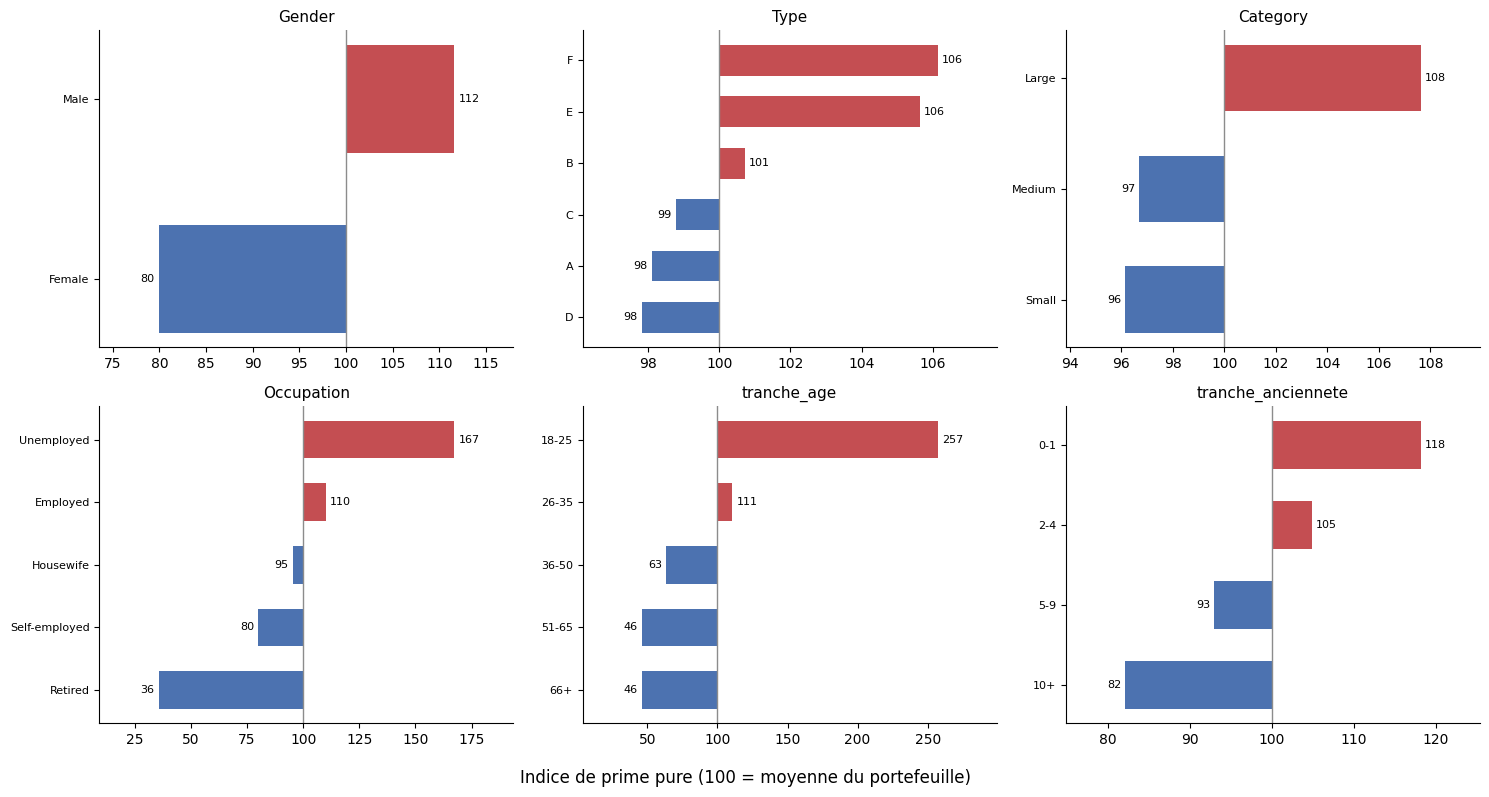

#### Points clés
- Modalité la plus chère : **tranche_age = 18-25** (indice 257) ; la moins chère : **Occupation = Retired** (indice 36).

#### Interprétation
- Un indice de 150 veut dire une prime pure 50 % plus chère que la moyenne, un indice de 70, 30 % moins chère. Plus les barres s'éloignent de 100, plus la variable sépare les risques.
- Pour l'âge et l'ancienneté, l'indice évolue de façon **régulière** d'une tranche à l'autre : c'est le signe d'un vrai effet, et non de fluctuations aléatoires.
- Ces indices sont bruts : ils mélangent l'effet propre de la variable et celui des variables qui lui sont liées. Le GLM de l'étape 9 donne les effets à autres caractéristiques égales.

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))  # une petite figure par variable
for ax, c in zip(axes.flat, CATEGORIES):  # une variable par graphique
    t = tables[c][tables[c]["polices"] >= 100]  # modalités assez grandes
    if c == "tranche_anciennete":  # ordre naturel (sinon « 10+ » vient avant « 2-4 »)
        t = t.reindex(sorted(t.index, key=lambda m: int(str(m).split("-")[0].rstrip("+"))))
    if c not in ("tranche_age", "tranche_anciennete"):  # variables sans ordre naturel : tri par indice
        t = t.sort_values("indice prime")
    ind = t["indice prime"]  # indice de chaque modalité
    barres = ax.barh(t.index.astype(str), ind - 100, left=100, height=0.6,  # barres partant de la moyenne
                     color=np.where(ind >= 100, ROUGE, BLEU))
    ax.bar_label(barres, labels=[f"{v:.0f}" for v in ind], padding=3, fontsize=8)  # valeur de l'indice
    ax.axvline(100, color=GRIS, lw=1)  # moyenne du portefeuille
    ax.margins(x=0.2)  # place pour les étiquettes
    ax.set_title(c)  # nom de la variable
    ax.tick_params(axis="y", labelsize=8)  # libellés plus petits
    if c in ("tranche_age", "tranche_anciennete"):  # première tranche en haut
        ax.invert_yaxis()
fig.supxlabel("Indice de prime pure (100 = moyenne du portefeuille)")  # axe commun
plt.tight_layout()  # ajuste les marges
montrer_fig("indices_prime")  # affiche et enregistre la figure

tous = pd.concat({c: tables[c][tables[c]["polices"] >= 100]["indice prime"] for c in CATEGORIES})  # tous les indices
haut_i, bas_i = tous.idxmax(), tous.idxmin()  # modalités extrêmes
points_cles(
    f"Modalité la plus chère : **{haut_i[0]} = {haut_i[1]}** (indice {tous.max():.0f}) ; la moins chère : "
    f"**{bas_i[0]} = {bas_i[1]}** (indice {tous.min():.0f}).",
)
interpretation(
    "Un indice de 150 veut dire une prime pure 50 % plus chère que la moyenne, un indice de 70, 30 % moins chère. "
    "Plus les barres s'éloignent de 100, plus la variable sépare les risques.",
    "Pour l'âge et l'ancienneté, l'indice évolue de façon **régulière** d'une tranche à l'autre : c'est le signe d'un "
    "vrai effet, et non de fluctuations aléatoires.",
    "Ces indices sont bruts : ils mélangent l'effet propre de la variable et celui des variables qui lui sont liées. "
    "Le GLM de l'étape 9 donne les effets à autres caractéristiques égales.",
)
pour_rapport("indices_prime", "Étape 3 bis : indice de prime pure par modalité",
             "Indice de prime pure par modalité (100 = moyenne du portefeuille), modalités d'au moins 100 polices.")

#### Test d'indépendance du khi-deux entre chaque variable et la survenance d'un sinistre
Le **test du khi-deux** vérifie si la proportion de polices sinistrées est la même dans toutes les modalités d'une variable (hypothèse d'indépendance). La **p-valeur** indique si l'écart observé peut venir du hasard. Le **V de Cramér** (de 0 à 1) mesure la **force** du lien, indépendamment de la taille de l'échantillon : en dessous de 0,1 le lien est faible, entre 0,1 et 0,3 il est modéré.

In [14]:
lignes_chi2 = []  # une ligne par variable
for c in CATEGORIES:  # pour chaque variable qualitative
    ct = pd.crosstab(base[c], base["a_sinistre"])  # tableau croisé modalité × (sinistrée ou non)
    chi2, p_chi2, ddl, _ = sstats.chi2_contingency(ct)  # test du khi-deux
    v_cramer = np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1)))  # V de Cramér
    lignes_chi2.append({"variable": c, "khi-deux": chi2, "ddl": ddl, "p-valeur": p_chi2, "V de Cramér": v_cramer})
khi2 = pd.DataFrame(lignes_chi2).set_index("variable").sort_values("V de Cramér", ascending=False)  # du plus fort au plus faible
khi2.to_csv(SORTIE / "stats_khi2_independance.csv", sep=";", decimal=",")  # sauvegarde
afficher(khi2, "Tests du khi-deux : variable × survenance d'au moins un sinistre")  # affichage

n_sig = (khi2["p-valeur"] < 0.05).sum()  # variables significatives
v_max = khi2["V de Cramér"].iloc[0]  # lien le plus fort
points_cles(
    f"{n_sig} variables sur {len(khi2)} sont significativement liées à la survenance d'un sinistre (p < 5 %).",
    f"Le lien le plus fort est avec **{khi2.index[0]}** (V = {v_max:.3f}), le plus faible avec "
    f"**{khi2.index[-1]}** (V = {khi2['V de Cramér'].iloc[-1]:.3f}).",
)
interpretation(
    f"Avec {nb_fr(len(base))} polices, le test du khi-deux détecte des écarts minuscules : presque tout devient "
    "« significatif ». La p-valeur dit seulement que le lien existe ; c'est le **V de Cramér** qui dit s'il est important.",
    "Tous les V sont "
    + ("faibles (< 0,1)" if v_max < 0.1 else "faibles à modérés")
    + " : aucune variable seule ne détermine la survenance d'un sinistre. C'est normal en assurance, où chaque facteur "
    "déplace un peu la probabilité de sinistre, et où c'est leur combinaison qui fait la différence.",
    "Limite : ce test ne tient pas compte de l'exposition (une police assurée 3 mois a moins de chances d'être sinistrée "
    "qu'une police assurée 12 mois). Les GLM, qui l'intègrent, sont plus fiables pour mesurer les effets.",
)
pour_rapport("khi2_independance", "Étape 3 bis : tests d'indépendance du khi-deux",
             "", figure=False)
RAPPORT_COMPLEMENTS["khi2_independance"]["tableau"] = pd.DataFrame({  # tableau mis en forme pour le rapport
    "khi-deux": [nb_fr(v, 1) for v in khi2["khi-deux"]], "ddl": [nb_fr(v) for v in khi2["ddl"]],
    "p-valeur": ["< 0,001" if v < 0.001 else nb_fr(v, 3) for v in khi2["p-valeur"]],
    "V de Cramér": [nb_fr(v, 3) for v in khi2["V de Cramér"]]}, index=khi2.index)

**Tests du khi-deux : variable × survenance d'au moins un sinistre** — 6 lignes × 4 colonnes

,khi-deux,ddl,p-valeur,V de Cramér
variable,,,,
tranche_age,"3,047",4,0,0.1746
Occupation,"1,407",4,1.763e-303,0.1186
tranche_anciennete,161.4,3,9.154e-35,0.04017
Type,155,5,1.153e-31,0.03937
Gender,130.4,2,4.867e-29,0.03611
Category,41.73,3,4.575e-09,0.02043


#### Points clés
- 6 variables sur 6 sont significativement liées à la survenance d'un sinistre (p < 5 %).
- Le lien le plus fort est avec **tranche_age** (V = 0,175), le plus faible avec **Category** (V = 0,020).

#### Interprétation
- Avec 100 000 polices, le test du khi-deux détecte des écarts minuscules : presque tout devient « significatif ». La p-valeur dit seulement que le lien existe ; c'est le **V de Cramér** qui dit s'il est important.
- Tous les V sont faibles à modérés : aucune variable seule ne détermine la survenance d'un sinistre. C'est normal en assurance, où chaque facteur déplace un peu la probabilité de sinistre, et où c'est leur combinaison qui fait la différence.
- Limite : ce test ne tient pas compte de l'exposition (une police assurée 3 mois a moins de chances d'être sinistrée qu'une police assurée 12 mois). Les GLM, qui l'intègrent, sont plus fiables pour mesurer les effets.

#### Histogrammes
Forme de la distribution des principales variables, avec la moyenne (rouge) et la médiane (vert).

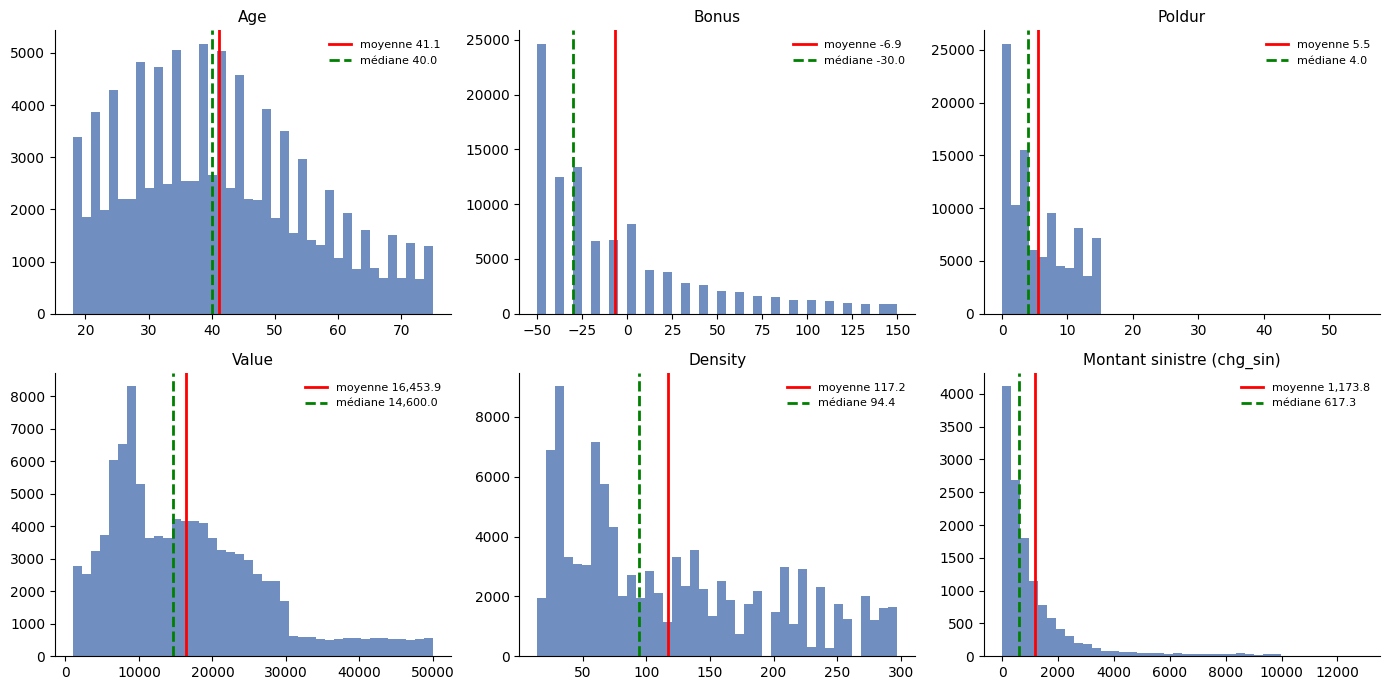

In [15]:
VAR_HIST = [v for v in ["Age", "Bonus", "Poldur", "Value", "Density"] if v in base.columns]  # variables des polices
fig, axes = plt.subplots(2, 3, figsize=(14, 7))  # grille de 2 × 3 graphiques
axes = axes.ravel()  # liste simple des 6 emplacements
series = [(v, base[v]) for v in VAR_HIST] + [("Montant sinistre (chg_sin)", sin["chg_sin"])]  # données à tracer
for ax, (nom, x) in zip(axes, series):  # un graphique par variable
    x = x.dropna()  # retire les valeurs manquantes
    ax.hist(x, bins=40, color="#4C72B0", alpha=0.8)  # histogramme en 40 classes
    ax.axvline(x.mean(), color="red", lw=2, label=f"moyenne {x.mean():,.1f}")  # trait de la moyenne
    ax.axvline(x.median(), color="green", lw=2, ls="--", label=f"médiane {x.median():,.1f}")  # trait de la médiane
    ax.set_title(nom)  # titre du graphique
    ax.legend(fontsize=8)  # légende
for ax in axes[len(series):]:  # emplacements inutilisés
    ax.axis("off")  # on les masque
plt.tight_layout()  # ajuste les marges
montrer_fig()  # affiche la figure

#### Quelle loi pour le nombre de sinistres : Poisson ou binomiale négative ?
On compare le nombre de polices observé avec 0, 1, 2… sinistres à ce que prévoient deux lois, avec la même fréquence moyenne et l'exposition réelle de chaque police :
- **Poisson** : la variance égale la moyenne (tous les assurés ont le même risque) ;
- **binomiale négative** : la variance dépasse la moyenne (les assurés ont des risques différents), d'un facteur estimé sur les données.

Le **test de Cameron-Trivedi** vérifie formellement si la variance dépasse la moyenne (surdispersion).

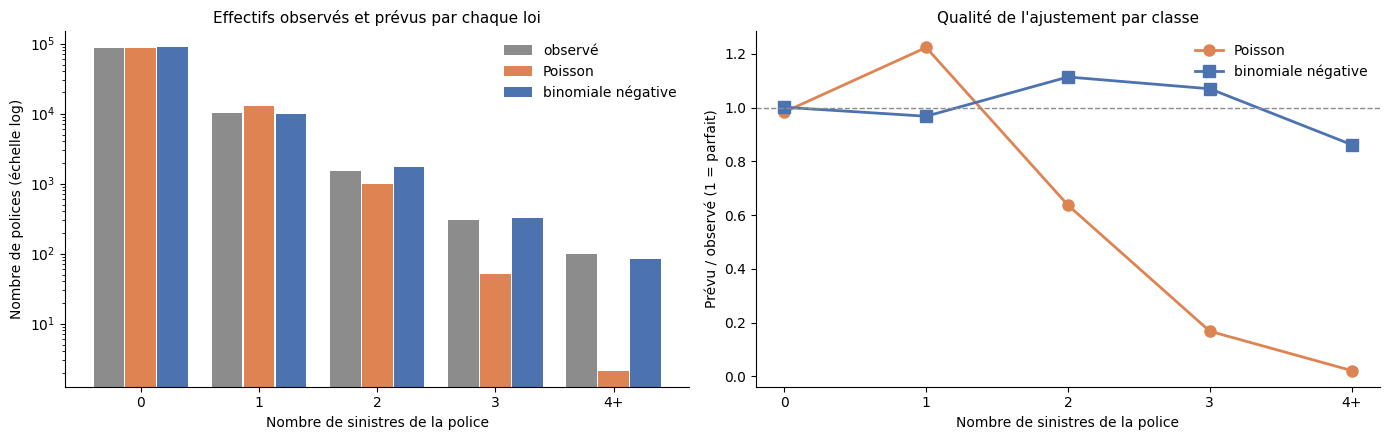

,observé,Poisson,binomiale négative
0,87744,86336,87888
1,10322,12635,9994
2,1530,975,1705
3,306,51,328
4+,98,2,85


#### Points clés
- Paramètre de surdispersion estimé : α = 1,88 (variance = moyenne × (1 + α × moyenne)).
- Test de Cameron-Trivedi : t = 21,8, p-valeur inférieure à 0,0001.
- Khi-deux d'ajustement : **6 329** pour Poisson contre **32** pour la binomiale négative.
- Polices à 4 sinistres ou plus : 98 observées, 2 prévues par Poisson, 85 par la binomiale négative.

#### Interprétation
- Le test rejette l'hypothèse « variance = moyenne » (p-valeur inférieure à 0,0001) : la **surdispersion est significative**.
- La loi de Poisson **sous-estime fortement les polices multi-sinistrées** (prévu / observé = 0,02 pour 4+ sinistres) : elle suppose que tous les assurés ont le même risque. La binomiale négative, qui autorise des risques différents, est beaucoup plus proche (rapport 0,86).
- Cette comparaison est **marginale** : elle ne tient pas compte des variables (âge, bonus…). Une grande partie de la surdispersion vient justement de ces différences, que le GLM de Poisson prend en compte. Le GLM de Poisson reste donc valable pour estimer les effets moyens ; la surdispersion restante rend seulement ses intervalles de confiance un peu trop étroits.
- En pratique, pour estimer les **écarts-types** des coefficients ou simuler des scénarios de sinistralité (provisionnement, réassurance), il faut utiliser la binomiale négative.

In [16]:
nb_y = base["nb_sinistres"].to_numpy()  # nombre de sinistres de chaque police
nb_expo = base["expo_annees"].to_numpy()  # exposition de chaque police
garde = nb_expo > 0  # polices exposées
nb_y, nb_expo = nb_y[garde], nb_expo[garde]
nb_mu = nb_y.sum() / nb_expo.sum() * nb_expo  # nombre attendu par police (fréquence moyenne × exposition)
alpha_nb = max(((nb_y - nb_mu) ** 2 - nb_y).sum() / (nb_mu ** 2).sum(), 1e-6)  # surdispersion (méthode des moments)

z_ct = ((nb_y - nb_mu) ** 2 - nb_y) / nb_mu  # variable du test de Cameron-Trivedi
beta_ct = (z_ct * nb_mu).sum() / (nb_mu ** 2).sum()  # pente de la régression de z sur mu (sans constante)
se_ct = np.sqrt(((z_ct - beta_ct * nb_mu) ** 2).sum() / (len(z_ct) - 1) / (nb_mu ** 2).sum())  # erreur type
t_ct = beta_ct / se_ct  # statistique de test
p_ct = sstats.norm.sf(t_ct)  # p-valeur unilatérale (H1 : variance > moyenne)
p_ct_txt = "inférieure à 0,0001" if p_ct < 1e-4 else f"{p_ct:.4f}"  # p-valeur lisible

KMAX = 4  # dernière classe : « 4 sinistres ou plus »
n_nb, p_nbin = 1 / alpha_nb, 1 / (1 + alpha_nb * nb_mu)  # paramètres de la binomiale négative
classes = [str(k) for k in range(KMAX)] + [f"{KMAX}+"]  # libellés des classes
loi_obs = np.array([(nb_y == k).sum() for k in range(KMAX)] + [(nb_y >= KMAX).sum()])  # effectifs observés
loi_pois = np.array([sstats.poisson.pmf(k, nb_mu).sum() for k in range(KMAX)] + [sstats.poisson.sf(KMAX - 1, nb_mu).sum()])
loi_nb = np.array([sstats.nbinom.pmf(k, n_nb, p_nbin).sum() for k in range(KMAX)] + [sstats.nbinom.sf(KMAX - 1, n_nb, p_nbin).sum()])
chi2_pois = ((loi_obs - loi_pois) ** 2 / loi_pois).sum()  # khi-deux d'ajustement de Poisson
chi2_nb = ((loi_obs - loi_nb) ** 2 / loi_nb).sum()  # khi-deux d'ajustement de la binomiale négative

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))  # deux graphiques
pos = np.arange(len(classes))  # position des classes
for decal, valeurs, lib, coul in [(-0.27, loi_obs, "observé", GRIS), (0, loi_pois, "Poisson", ORANGE),
                                  (0.27, loi_nb, "binomiale négative", BLEU)]:
    ax1.bar(pos + decal, valeurs, 0.26, color=coul, label=lib)  # effectifs
ax1.set_yscale("log")  # échelle logarithmique : les classes rares restent visibles
ax1.set_xticks(pos, classes)  # libellés des classes
ax1.set_xlabel("Nombre de sinistres de la police")  # axe horizontal
ax1.set_ylabel("Nombre de polices (échelle log)")  # axe vertical
ax1.set_title("Effectifs observés et prévus par chaque loi")  # titre
ax1.legend()  # légende
ax2.plot(pos, loi_pois / loi_obs, "o-", color=ORANGE, lw=2, ms=8, label="Poisson")  # prévu / observé
ax2.plot(pos, loi_nb / loi_obs, "s-", color=BLEU, lw=2, ms=8, label="binomiale négative")
ax2.axhline(1, color=GRIS, ls="--", lw=1)  # ajustement parfait
ax2.set_xticks(pos, classes)  # libellés des classes
ax2.set_xlabel("Nombre de sinistres de la police")  # axe horizontal
ax2.set_ylabel("Prévu / observé (1 = parfait)")  # axe vertical
ax2.set_title("Qualité de l'ajustement par classe")  # titre
ax2.legend()  # légende
plt.tight_layout()  # ajuste les marges
montrer_fig("loi_nombre_sinistres")  # affiche et enregistre la figure

display(pd.DataFrame({"observé": loi_obs, "Poisson": loi_pois, "binomiale négative": loi_nb}, index=classes).round(0).astype(int))  # tableau
points_cles(
    f"Paramètre de surdispersion estimé : α = {alpha_nb:.2f} (variance = moyenne × (1 + α × moyenne)).",
    f"Test de Cameron-Trivedi : t = {t_ct:.1f}, p-valeur {p_ct_txt}.",
    f"Khi-deux d'ajustement : **{nb_fr(chi2_pois)}** pour Poisson contre **{nb_fr(chi2_nb)}** pour la binomiale négative.",
    f"Polices à {KMAX} sinistres ou plus : {loi_obs[-1]:.0f} observées, {loi_pois[-1]:.0f} prévues par Poisson, "
    f"{loi_nb[-1]:.0f} par la binomiale négative.",
)
interpretation(
    verdict(p_ct < 0.05, f"Le test rejette l'hypothèse « variance = moyenne » (p-valeur {p_ct_txt}) : la **surdispersion est significative**.",
            "Le test ne rejette pas l'égalité variance = moyenne : la loi de Poisson est acceptable."),
    f"La loi de Poisson **sous-estime fortement les polices multi-sinistrées** (prévu / observé = {loi_pois[-1] / loi_obs[-1]:.2f} "
    f"pour {KMAX}+ sinistres) : elle suppose que tous les assurés ont le même risque. La binomiale négative, qui autorise des "
    f"risques différents, est beaucoup plus proche (rapport {loi_nb[-1] / loi_obs[-1]:.2f}).",
    "Cette comparaison est **marginale** : elle ne tient pas compte des variables (âge, bonus…). Une grande partie de la "
    "surdispersion vient justement de ces différences, que le GLM de Poisson prend en compte. Le GLM de Poisson reste donc "
    "valable pour estimer les effets moyens ; la surdispersion restante rend seulement ses intervalles de confiance un peu trop étroits.",
    "En pratique, pour estimer les **écarts-types** des coefficients ou simuler des scénarios de sinistralité (provisionnement, "
    "réassurance), il faut utiliser la binomiale négative.",
)
pour_rapport("loi_nombre_sinistres", "Étape 3 bis : loi du nombre de sinistres",
             "Nombre de polices par nombre de sinistres : observé, prévu par la loi de Poisson et par la binomiale négative.")

#### Quelle loi pour le montant d'un sinistre : Gamma ou log-normale ?
On ajuste les deux lois classiques des montants de sinistres par maximum de vraisemblance et on les compare :
- **densités** sur l'échelle logarithmique des montants (à gauche) ;
- **diagramme quantile-quantile** (à droite) : si la loi convient, les points suivent la diagonale. Les points du haut décrivent les gros sinistres ;
- **AIC** (critère d'Akaike) : plus il est bas, meilleur est le compromis entre ajustement et nombre de paramètres.

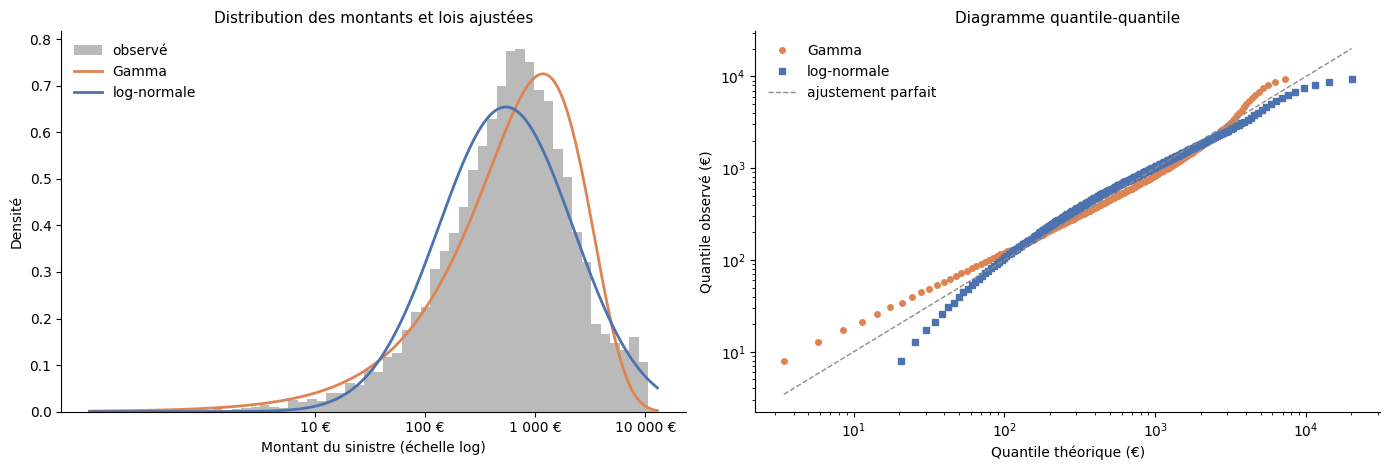

,AIC,P99 (€),moyenne (€)
Gamma,213449,6199,1176
log-normale,213622,14156,1448


#### Points clés
- AIC : Gamma 213 449, log-normale 213 622 → la loi **Gamma** ajuste mieux (écart de 173 points).
- P99 des montants : observé 8 622 €, Gamma 6 199 €, log-normale 14 156 €.
- Montant moyen : observé 1 176 €, Gamma 1 176 €, log-normale 1 448 €.

#### Interprétation
- Un écart d'AIC de plus de 10 points est considéré comme décisif : la loi **Gamma** est nettement plus adaptée à la forme globale des montants.
- Sur les gros sinistres (P99), la Gamma s'écarte de l'observé de -28 %, la log-normale de +64 %. La Gamma sous-estime la queue de distribution : elle donne trop peu de poids aux gros sinistres.
- Le GLM Gamma de l'étape 7 reste un choix justifié : il modélise directement le **coût moyen** (ce qui intéresse la tarification), alors qu'un modèle log-normal modélise la moyenne du logarithme et demande une correction pour revenir à la moyenne en euros. Ce qu'il faut retenir, c'est que la queue de distribution doit être traitée à part : écrêtement des gros sinistres et, au-delà d'un seuil, une loi spécifique (Pareto) ou une réassurance.

In [17]:
montants = sin.loc[sin["chg_sin"] > 0, "chg_sin"].to_numpy()  # montants strictement positifs
par_gamma = sstats.gamma.fit(montants, floc=0)  # loi Gamma (forme, 0, échelle)
par_lnorm = sstats.lognorm.fit(montants, floc=0)  # loi log-normale (sigma, 0, exp(mu))
aic_gamma = 2 * 2 - 2 * sstats.gamma.logpdf(montants, *par_gamma).sum()  # AIC Gamma (2 paramètres)
aic_lnorm = 2 * 2 - 2 * sstats.lognorm.logpdf(montants, *par_lnorm).sum()  # AIC log-normale (2 paramètres)
proba = np.linspace(0.01, 0.995, 200)  # niveaux de quantile comparés
q_emp = np.quantile(montants, proba)  # quantiles observés
q_gamma = sstats.gamma.ppf(proba, *par_gamma)  # quantiles de la Gamma
q_lnorm = sstats.lognorm.ppf(proba, *par_lnorm)  # quantiles de la log-normale

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))  # deux graphiques
u = np.linspace(np.log10(montants.min()), np.log10(montants.max()), 300)  # grille en log10 du montant
ax1.hist(np.log10(montants), bins=60, density=True, color=GRIS, alpha=0.6, label="observé")  # histogramme
for loi, par, lib, coul in [(sstats.gamma, par_gamma, "Gamma", ORANGE), (sstats.lognorm, par_lnorm, "log-normale", BLEU)]:
    ax1.plot(u, loi.pdf(10 ** u, *par) * 10 ** u * np.log(10), color=coul, lw=2, label=lib)  # densité de log10(X)
ax1.set_xticks([1, 2, 3, 4], ["10 €", "100 €", "1 000 €", "10 000 €"])  # graduations lisibles
ax1.set_xlabel("Montant du sinistre (échelle log)")  # axe horizontal
ax1.set_ylabel("Densité")  # axe vertical
ax1.set_title("Distribution des montants et lois ajustées")  # titre
ax1.legend()  # légende
ax2.loglog(q_gamma, q_emp, "o", ms=4, color=ORANGE, label="Gamma")  # quantiles Gamma
ax2.loglog(q_lnorm, q_emp, "s", ms=4, color=BLEU, label="log-normale")  # quantiles log-normale
lims = [min(q_emp.min(), q_gamma.min(), q_lnorm.min()), max(q_emp.max(), q_gamma.max(), q_lnorm.max())]  # bornes
ax2.loglog(lims, lims, "--", color=GRIS, lw=1, label="ajustement parfait")  # diagonale
ax2.set_xlabel("Quantile théorique (€)")  # axe horizontal
ax2.set_ylabel("Quantile observé (€)")  # axe vertical
ax2.set_title("Diagramme quantile-quantile")  # titre
ax2.legend()  # légende
plt.tight_layout()  # ajuste les marges
montrer_fig("loi_montants")  # affiche et enregistre la figure

meilleure = "log-normale" if aic_lnorm < aic_gamma else "Gamma"  # loi retenue par l'AIC
p99_emp = np.quantile(montants, 0.99)  # P99 observé
p99_g, p99_l = sstats.gamma.ppf(0.99, *par_gamma), sstats.lognorm.ppf(0.99, *par_lnorm)  # P99 des deux lois
display(pd.DataFrame({"AIC": [aic_gamma, aic_lnorm], "P99 (€)": [p99_g, p99_l], "moyenne (€)": [
    sstats.gamma.mean(*par_gamma), sstats.lognorm.mean(*par_lnorm)]}, index=["Gamma", "log-normale"]).round(0).astype(int))  # tableau
points_cles(
    f"AIC : Gamma {nb_fr(aic_gamma)}, log-normale {nb_fr(aic_lnorm)} → la loi **{meilleure}** ajuste mieux "
    f"(écart de {nb_fr(abs(aic_gamma - aic_lnorm))} points).",
    f"P99 des montants : observé {nb_fr(p99_emp)} €, Gamma {nb_fr(p99_g)} €, log-normale {nb_fr(p99_l)} €.",
    f"Montant moyen : observé {nb_fr(montants.mean())} €, Gamma {nb_fr(sstats.gamma.mean(*par_gamma))} €, "
    f"log-normale {nb_fr(sstats.lognorm.mean(*par_lnorm))} €.",
)
interpretation(
    f"Un écart d'AIC de plus de 10 points est considéré comme décisif : la loi **{meilleure}** est nettement plus adaptée "
    "à la forme globale des montants.",
    f"Sur les gros sinistres (P99), la Gamma s'écarte de l'observé de {100 * (p99_g / p99_emp - 1):+.0f} %, la log-normale "
    f"de {100 * (p99_l / p99_emp - 1):+.0f} %. "
    + ("La Gamma sous-estime la queue de distribution : elle donne trop peu de poids aux gros sinistres."
       if p99_g < p99_emp else "La Gamma ne sous-estime pas la queue de distribution."),
    "Le GLM Gamma de l'étape 7 reste un choix justifié : il modélise directement le **coût moyen** (ce qui intéresse la "
    "tarification), alors qu'un modèle log-normal modélise la moyenne du logarithme et demande une correction pour revenir "
    "à la moyenne en euros. Ce qu'il faut retenir, c'est que la queue de distribution doit être traitée à part : écrêtement "
    "des gros sinistres et, au-delà d'un seuil, une loi spécifique (Pareto) ou une réassurance.",
)
pour_rapport("loi_montants", "Étape 3 bis : loi du montant d'un sinistre",
             "Distribution des montants de sinistres, lois Gamma et log-normale ajustées, et diagramme quantile-quantile.")

### Étape 4 — Jointure des bases

**Objectif.** Rassembler en une seule base une ligne par police, avec ses caractéristiques, son exposition et ses sinistres.

**Méthode.** Trois jointures sur la clé `PolNum`, chacune contrôlée :
- portefeuille ↔ exposition (1 à 1) ;
- sinistres → polices (plusieurs sinistres pour une police) ;
- polices ← sinistres agrégés (0 ou 1 ligne par police).

**Comment lire.** On vérifie qu'aucune jointure ne crée de doublons et que le coût total est conservé (somme avant = somme après). Les sinistres « sans police » ne peuvent pas être tarifés et sont exclus.

#### Code : jointures et contrôles

Définition des fonctions de l'étape. Le résultat de leur exécution s'affiche dans la cellule suivante.

In [18]:
# ===========================================================================
# ÉTAPE 4 – JOINTURE DES BASES
# ===========================================================================


POLICE_ATTRIBUTS = ["PolNum", "CalYear", "Gender", "Type", "Category", "Occupation", "Age", "Group1",
                    "Bonus", "Poldur", "Value", "Adind", "Group2", "Density", "Expdays",
                    "tranche_age", "quartile_valeur"]


def etape4(e3: dict) -> dict:
    """Réalise les jointures une à une, contrôle chaque résultat et produit la base consolidée."""
    ptf, expo, sin = e3["ptf"], e3["expo"], e3["sin"]
    controles = []

    # --- Jointure 1 : portefeuille ↔ exposition (relation 1 à 1) -------------------
    j1 = ptf[["PolNum"]].merge(expo, on="PolNum", how="outer", indicator=True, validate="one_to_one")
    j1_gauche_seules = int((j1["_merge"] == "left_only").sum())
    j1_droite_seules = int((j1["_merge"] == "right_only").sum())
    controles.append({
        "jointure": "Portefeuille ↔ Exposition", "relation": "1 à 1",
        "lignes_gauche": len(ptf), "lignes_droite": len(expo), "lignes_apres": len(j1),
        "correspondances": int((j1["_merge"] == "both").sum()),
        "cles_sans_correspondance_gauche": j1_gauche_seules,
        "cles_sans_correspondance_droite": j1_droite_seules,
        "doublons_generes": len(j1) - int(j1["PolNum"].nunique()),
        "resultat": "OK" if j1_gauche_seules == 0 and j1_droite_seules == 0 and len(j1) == len(ptf) else "À EXAMINER",
    })
    polices = ptf.merge(expo, on="PolNum", how="inner", validate="one_to_one")

    # --- Jointure 2 : sinistres → polices (plusieurs sinistres par police : n à 1) --
    attributs = e3["base"][POLICE_ATTRIBUTS]
    j2 = sin.merge(attributs, on="PolNum", how="left", indicator=True, validate="many_to_one")
    lignes_sans_police = j2[j2["_merge"] == "left_only"]
    controles.append({
        "jointure": "Sinistres → Polices", "relation": "n à 1",
        "lignes_gauche": len(sin), "lignes_droite": len(attributs), "lignes_apres": len(j2),
        "correspondances": int((j2["_merge"] == "both").sum()),
        "cles_sans_correspondance_gauche": int(lignes_sans_police["PolNum"].nunique()),
        "cles_sans_correspondance_droite": None,
        "doublons_generes": len(j2) - len(sin),
        "resultat": "OK" if len(j2) == len(sin) else "ÉCHEC",
    })

    # --- Jointure 3 : polices ← sinistres agrégés (1 à 0..1) ------------------------
    agregat = sin.groupby("PolNum", as_index=False).agg(nb_sinistres=("nb_sin", "sum"),
                                                       cout_total=("chg_sin", "sum"))
    j3 = polices[["PolNum"]].merge(agregat, on="PolNum", how="left", indicator=True, validate="one_to_one")
    sans_sinistre = int((j3["_merge"] == "left_only").sum())
    sinistres_hors_police = int((~agregat["PolNum"].isin(polices["PolNum"])).sum())
    controles.append({
        "jointure": "Polices ← Sinistres agrégés", "relation": "1 à 0 ou 1",
        "lignes_gauche": len(polices), "lignes_droite": len(agregat), "lignes_apres": len(j3),
        "correspondances": int((j3["_merge"] == "both").sum()),
        "cles_sans_correspondance_gauche": sans_sinistre,
        "cles_sans_correspondance_droite": sinistres_hors_police,
        "doublons_generes": len(j3) - len(polices),
        "resultat": "OK" if len(j3) == len(polices) else "ÉCHEC",
    })

    # --- Rapprochement des montants et des effectifs --------------------------------
    base = e3["base"]
    total_sin_rattaches = float(sin.loc[sin["PolNum"].isin(polices["PolNum"]), "chg_sin"].sum())
    total_base = float(base["cout_total"].sum())
    nb_rattaches = int(sin["PolNum"].isin(polices["PolNum"]).sum())
    coherence = [
        ("Coût total : base consolidée = sinistres rattachés", abs(total_base - total_sin_rattaches) < 0.01,
         f"{total_base:,.2f} € = {total_sin_rattaches:,.2f} €".replace(",", " ")),
        ("Nombre de sinistres : base = sinistres rattachés",
         int(base["nb_sinistres"].sum()) == int(sin.loc[sin["PolNum"].isin(polices["PolNum"]), "nb_sin"].sum()),
         f"{int(base['nb_sinistres'].sum())} sinistres"),
        ("Lignes de sinistres : rattachées + non rattachées = total",
         nb_rattaches + int(lignes_sans_police.shape[0]) == len(sin),
         f"{nb_rattaches} + {lignes_sans_police.shape[0]} = {len(sin)}"),
        ("Une ligne par police dans la base consolidée", base["PolNum"].is_unique, f"{len(base)} polices"),
        ("Aucun doublon généré par les jointures", all(c["doublons_generes"] == 0 for c in controles),
         "contrôle sur les trois jointures"),
    ]
    controles_coherence = pd.DataFrame(coherence, columns=["controle", "ok", "detail"])
    controles_coherence["resultat"] = np.where(controles_coherence["ok"], "OK", "ÉCHEC")

    # --- Sorties ---------------------------------------------------------------------
    sin_consolides = j2.drop(columns=["_merge"]).copy()
    sin_consolides["police_trouvee"] = (sin_consolides["Age"].notna()).astype(int)
    controles_df = pd.DataFrame(controles)
    controles_df.to_csv(SORTIE / "etape4_controles_jointure.csv", index=False, sep=";")
    controles_coherence.to_csv(SORTIE / "etape4_coherence.csv", index=False, sep=";")
    pd.DataFrame({"PolNum": lignes_sans_police["PolNum"].drop_duplicates().astype("int64")}).to_csv(
        SORTIE / "etape4_cles_sinistres_sans_police.csv", index=False, sep=";")
    sin_consolides.to_csv(SORTIE / "etape4_sinistres_consolides.csv", index=False, sep=";", decimal=",")
    base.to_csv(SORTIE / "etape4_base_polices_consolidee.csv", index=False, sep=";", decimal=",")

    print(f"Étape 4 : {len(base)} polices consolidées, {len(sin_consolides)} sinistres consolidés, "
          f"{len(lignes_sans_police)} lignes sans police")
    return {"controles": controles_df, "coherence": controles_coherence,
            "sans_police_polices": int(lignes_sans_police["PolNum"].nunique()),
            "sans_police_lignes": len(lignes_sans_police),
            "sans_sinistre": sans_sinistre, "base_n": len(base),
            "sin_consolides_n": len(sin_consolides)}


def section_etape4(e4: dict) -> str:
    c = e4["controles"]
    lignes = [[echapper(r["jointure"]), echapper(r["relation"]), nombre(r["lignes_gauche"]),
               nombre(r["lignes_droite"]), nombre(r["lignes_apres"]), nombre(r["correspondances"]),
               nombre(r["cles_sans_correspondance_gauche"]),
               "--" if pd.isna(r["cles_sans_correspondance_droite"]) else nombre(r["cles_sans_correspondance_droite"]),
               nombre(r["doublons_generes"]), echapper(r["resultat"])]
              for r in c.to_dict("records")]
    coh = [[echapper(r["controle"]), echapper(r["resultat"]), echapper(r["detail"])]
           for r in e4["coherence"].to_dict("records")]
    return (
        "\n\\part{Étape 4 -- Jointure des bases}\n\\section{Objectif}\n"
        "Réunir les informations pour obtenir une vision complète des polices et des sinistres, "
        "en contrôlant chaque jointure.\n\n"
        "\\section{Relations entre les tables}\n"
        "\\begin{itemize}\n"
        "  \\item \\textbf{Portefeuille et exposition} : une police = une ligne dans chaque table (relation 1 à 1).\n"
        "  \\item \\textbf{Sinistres et polices} : une police peut avoir plusieurs sinistres, un sinistre "
        "appartient à une seule police (relation n à 1).\n"
        "  \\item \\textbf{Polices et sinistres agrégés} : chaque police a au plus un total de sinistres "
        "(relation 1 à 0 ou 1).\n"
        "\\end{itemize}\n"
        "\\section{Contrôle des jointures}\n"
        "Pour chaque jointure : lignes avant et après, correspondances, clés sans correspondance et doublons "
        "générés. La validation de la relation (\\texttt{validate}) impose la cardinalité attendue : toute "
        "violation arrête le programme.\n"
        + "{\\footnotesize\\setlength{\\tabcolsep}{3pt}\n"
        + tableau("Contrôle des jointures", "tab:jointures",
                  ["Jointure", "Relation", "Gauche", "Droite", "Après", "Corresp.", "Sans corresp. gauche",
                   "Sans corresp. droite", "Doublons", "Résultat"],
                  lignes, "p{2.1cm}p{1.2cm}*{8}{>{\\raggedleft\\arraybackslash}p{1.05cm}}p{1.7cm}")
        + "}\n"
        + "\\section{Cohérence des montants et des effectifs}\n"
        + tableau("Contrôles de cohérence après jointure", "tab:coherence_j",
                  ["Contrôle", "Résultat", "Détail"], coh, "p{7cm}lp{5cm}")
        + "\\section{Résultat : base consolidée}\n"
        f"La base consolidée contient {nombre(e4['base_n'])} polices, une ligne par police. "
        f"Les sinistres consolidés contiennent {nombre(e4['sin_consolides_n'])} lignes, chacune rattachée à ses "
        "caractéristiques de police lorsque la police existe. "
        f"{nombre(e4['sans_police_polices'])} polices de sinistres ({nombre(e4['sans_police_lignes'])} lignes) "
        "ne figurent pas dans le portefeuille : elles sont conservées mais sans caractéristiques de risque.\n"
        "\\section{Points à valider}\n\\begin{enumerate}\n"
        "  \\item Les polices de sinistres absentes du portefeuille : extraction incomplète du portefeuille, "
        "ou polices résiliées avant la période d'observation ?\n"
        f"  \\item Les {nombre(e4['sans_sinistre'])} polices sans sinistre : elles sont conservées dans la base "
        "avec un nombre de sinistres nul, ce qui est attendu pour une analyse de fréquence.\n"
        "  \\item La période des sinistres n'est pas connue : la jointure ne garantit pas qu'un sinistre "
        "correspond à l'exposition de l'année de la police.\n"
        "\\end{enumerate}\n"
    )

print("Fonctions chargées (2) ; fonction principale : etape4()")  # confirme l'exécution de la cellule


Fonctions chargées (2) ; fonction principale : etape4()


In [19]:
res["etape4"] = lancer("Étape 4", lambda: etape4(res["etape3"]), "etape4")  # jointure sur la base nettoyée
e4 = res["etape4"]  # raccourci

afficher(e4["controles"], "Contrôles des jointures")  # bilan de chaque jointure
afficher(e4["coherence"], "Contrôles de cohérence")  # conservation des totaux

ok = e4["coherence"]["ok"].all() and (e4["controles"]["resultat"] == "OK").all()  # tous les contrôles passent ?
points_cles(  # constats chiffrés
    f"Base consolidée : **{nb_fr(e4['base_n'])} polices**, dont {nb_fr(e4['sans_sinistre'])} sans sinistre "
    f"({100 * e4['sans_sinistre'] / e4['base_n']:.1f} %).",
    f"{nb_fr(e4['sans_police_lignes'])} lignes de sinistres ({e4['sans_police_polices']} numéros de police) "
    f"n'ont pas de police correspondante, soit {100 * e4['sans_police_lignes'] / e4['sin_consolides_n']:.1f} % "
    "des sinistres : elles sont exclues de la tarification.",
    "Totaux conservés et aucun doublon créé." if ok else "Au moins un contrôle échoue : voir les tableaux.",
)

pct_sans_police = 100 * e4["sans_police_lignes"] / e4["sin_consolides_n"]  # sinistres sans police
interpretation(  # ce que la jointure veut dire
    f"{100 * e4['sans_sinistre'] / e4['base_n']:.1f} % de polices sans sinistre : c'est normal en assurance auto. "
    "Le nombre de sinistres est une **variable de comptage** avec beaucoup de zéros : on le modélise avec une loi de "
    "Poisson (ou binomiale négative), pas avec une régression linéaire.",
    verdict(pct_sans_police < 1, "Presque tous les sinistres retrouvent leur police.",
            f"{pct_sans_police:.1f} % des sinistres n'ont pas de police. S'ils concernent des contrats réels absents du "
            "fichier, la fréquence et la prime pure sont **sous-estimées** d'environ autant. À signaler au gestionnaire des données."),
    verdict(ok, "Jointure sûre : aucune ligne n'est dupliquée ni perdue, les totaux de sinistres et de coût sont conservés.",
            "Un contrôle de jointure échoue : les résultats suivants pourraient être faux."),
)

Étape 4 : 100000 polices consolidées, 13288 sinistres consolidés, 1011 lignes sans police


*Étape 4 terminée en 0.8 s*

**Contrôles des jointures** — 3 lignes × 10 colonnes

,jointure,relation,lignes_gauche,lignes_droite,lignes_apres,correspondances,cles_sans_correspondance_gauche,cles_sans_correspondance_droite,doublons_generes,resultat
0,Portefeuille ↔ Exposition,1 à 1,100000,100000,100000,100000,0,0,0,OK
1,Sinistres → Polices,n à 1,13288,100000,13288,12277,945,NaN,0,OK
2,Polices ← Sinistres agrégés,1 à 0 ou 1,100000,13201,100000,12256,87744,945,0,OK


**Contrôles de cohérence** — 5 lignes × 4 colonnes

,controle,ok,detail,resultat
0,Coût total : base consolidée = sinistres rattachés,True,10 615 729.37 € = 10 615 729.37 €,OK
1,Nombre de sinistres : base = sinistres rattachés,True,14748 sinistres,OK
2,Lignes de sinistres : rattachées + non rattachées = total,True,12277 + 1011 = 13288,OK
3,Une ligne par police dans la base consolidée,True,100000 polices,OK
4,Aucun doublon généré par les jointures,True,contrôle sur les trois jointures,OK


#### Points clés
- Base consolidée : **100 000 polices**, dont 87 744 sans sinistre (87,7 %).
- 1 011 lignes de sinistres (945 numéros de police) n'ont pas de police correspondante, soit 7,6 % des sinistres : elles sont exclues de la tarification.
- Totaux conservés et aucun doublon créé.

#### Interprétation
- 87,7 % de polices sans sinistre : c'est normal en assurance auto. Le nombre de sinistres est une **variable de comptage** avec beaucoup de zéros : on le modélise avec une loi de Poisson (ou binomiale négative), pas avec une régression linéaire.
- 7,6 % des sinistres n'ont pas de police. S'ils concernent des contrats réels absents du fichier, la fréquence et la prime pure sont **sous-estimées** d'environ autant. À signaler au gestionnaire des données.
- Jointure sûre : aucune ligne n'est dupliquée ni perdue, les totaux de sinistres et de coût sont conservés.

### Étape 5 — Analyse descriptive et exploratoire

**Objectif.** Comprendre comment la sinistralité varie selon les caractéristiques des assurés.

**Méthode.**
- *Analyse univariée* : distribution de chaque variable ;
- *Analyse bivariée* : fréquence et coût moyen par tranche d'âge, sexe, ancienneté et type ;
- *Corrélations de Spearman* : liens monotones entre variables, robustes aux valeurs extrêmes ;
- *GLM de Poisson* : effet de chaque facteur sur la fréquence, **toutes choses égales par ailleurs**.

**Comment lire le GLM.** Le *rapport de taux* (exp du coefficient) se lit par rapport à la modalité de référence : 2,9 veut dire 2,9 fois plus de sinistres. Si l'intervalle de confiance à 95 % ne contient pas 1, l'effet est significatif.

#### Code : analyse descriptive et GLM de Poisson

Définition des fonctions de l'étape. Le résultat de leur exécution s'affiche dans la cellule suivante.

In [20]:
# ===========================================================================
# ÉTAPE 5 – ANALYSE DESCRIPTIVE ET EXPLORATOIRE
# ===========================================================================


BANDES_AGE = ["18-25", "26-35", "36-50", "51-65", "66+"]


BANDES_ANC = ["0-1", "2-4", "5-9", "10+"]


def _stats_colonnes(df: pd.DataFrame, colonnes: list) -> pd.DataFrame:
    lignes = []
    for c in colonnes:
        s = pd.to_numeric(df[c], errors="coerce").dropna()
        lignes.append({"variable": c, "N": len(s), "moyenne": s.mean(), "mediane": s.median(),
                       "ecart_type": s.std(), "min": s.min(), "p90": s.quantile(0.9),
                       "p99": s.quantile(0.99), "max": s.max()})
    return pd.DataFrame(lignes)


def _etiqueter(ax, batons, textes, taille=7) -> None:
    """Écrit une étiquette au bout de chaque bâton et laisse de la place au-dessus."""
    ax.bar_label(batons, labels=textes, padding=2, fontsize=taille, fontweight="bold")
    ax.margins(y=0.15)


def _pct(valeurs) -> list:
    """Pourcentages à la française : 12.34 -> '12,3 %'."""
    return [f"{v:.1f} %".replace(".", ",") for v in valeurs]


def _sauver_fig(fig, nom: str) -> str:
    chemin = FIG / f"{nom}.png"
    fig.tight_layout()
    fig.savefig(chemin, dpi=150)
    plt.close(fig)
    return (FIG.relative_to(DOSSIER) / f"{nom}.png").as_posix()  # chemin lu par LaTeX depuis la racine


def tableau_groupe(base: pd.DataFrame, col: str, ordre: list) -> pd.DataFrame:
    """Fréquence, coût moyen et part de polices sinistrées par modalité."""
    g = base.groupby(col, observed=True).agg(
        polices=("PolNum", "size"), exposition=("expo_annees", "sum"),
        sinistres=("nb_sinistres", "sum"), cout=("cout_total", "sum"),
        part_sinistrees=("a_sinistre", "mean"), valeur_moyenne=("Value", "mean"),
    ).reindex(ordre).reset_index()
    g["frequence_pour_100_ans"] = 100 * g["sinistres"] / g["exposition"]
    g["cout_moyen_par_sinistre"] = np.where(g["sinistres"] > 0, g["cout"] / g["sinistres"].replace(0, np.nan), np.nan)
    g["part_sinistrees"] = 100 * g["part_sinistrees"]
    return g


def dummies(serie: pd.Series, nom: str, reference: str, ordre: list) -> tuple:
    colonnes, noms = [], []
    for c in ordre:
        if c == reference:
            continue
        colonnes.append((serie == c).astype(float).values)
        noms.append(f"{nom} = {c}")
    return colonnes, noms


def glm_poisson(y, expo, X, noms):
    """Régression de Poisson avec décalage log(exposition), par moindres carrés pondérés itératifs."""
    off = np.log(expo)
    beta = np.zeros(X.shape[1])
    beta[0] = np.log(y.sum() / expo.sum())
    for _ in range(100):
        eta = X @ beta + off
        mu = np.exp(eta)
        z = (eta - off) + (y - mu) / mu
        XtW = X.T * mu
        nouveau = np.linalg.solve(XtW @ X, XtW @ z)
        if np.max(np.abs(nouveau - beta)) < 1e-10:
            beta = nouveau
            break
        beta = nouveau
    mu = np.exp(X @ beta + off)
    cov = np.linalg.inv((X.T * mu) @ X)
    se = np.sqrt(np.diag(cov))
    z_val = beta / se
    p = 2 * (1 - sstats.norm.cdf(np.abs(z_val)))
    return pd.DataFrame({
        "facteur": noms, "coefficient": beta, "erreur_type": se,
        "rapport_de_taux": np.exp(beta),
        "ic95_bas": np.exp(beta - 1.96 * se), "ic95_haut": np.exp(beta + 1.96 * se),
        "p_valeur": p,
    })


def etape5(e3: dict) -> dict:
    base = e3["base"].copy()
    sin = e3["sin"]
    base["Bonus_10"] = base["Bonus"].astype(float) / 10.0
    base["Gender"] = base["Gender"].astype(str)
    figures = {}

    # ---- A. Univarié -------------------------------------------------------------------
    uni = _stats_colonnes(base, ["Age", "Value", "Bonus", "Poldur", "expo_annees", "nb_sinistres"])
    uni.to_csv(SORTIE / "etape5_univarie_stats.csv", index=False, sep=";")

    freq_nb = base["nb_sinistres"].value_counts().sort_index().reset_index()
    freq_nb.columns = ["nb_sinistres", "polices"]
    freq_nb["pct"] = 100 * freq_nb["polices"] / len(base)
    freq_nb.to_csv(SORTIE / "etape5_nb_sinistres.csv", index=False, sep=";")

    montants = sin.loc[sin["chg_sin"] > 0, "chg_sin"].astype(float)
    m_stats = pd.DataFrame([{
        "N": len(montants), "moyenne": montants.mean(), "mediane": montants.median(),
        "p90": montants.quantile(0.9), "p99": montants.quantile(0.99), "max": montants.max(),
        "part_cout_top1pct_sinistres": 100 * montants.nlargest(int(len(montants) * 0.01)).sum() / montants.sum(),
    }])
    m_stats.to_csv(SORTIE / "etape5_montants_stats.csv", index=False, sep=";")

    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    ax.hist(base["Age"].astype(float), bins=np.arange(17, 81, 2), color="#4C72B0", edgecolor="white")
    ax.set_xlabel("Âge du conducteur (ans)"); ax.set_ylabel("Polices")
    ax.set_title("Distribution des âges (après nettoyage)")
    figures["age"] = _sauver_fig(fig, "fig_age")

    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    ax.hist(base["Value"].astype(float), bins=60, color="#55A868", edgecolor="white")
    ax.set_xlabel("Valeur du véhicule (€)"); ax.set_ylabel("Polices")
    ax.set_title("Distribution de la valeur du véhicule (proxy du niveau tarifaire)")
    figures["value"] = _sauver_fig(fig, "fig_value")

    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    b = ax.bar(freq_nb["nb_sinistres"].astype(str), freq_nb["polices"], color="#C44E52")
    ax.set_yscale("log")
    ax.bar_label(b, labels=[f"{v:.2f} %".replace(".", ",") for v in freq_nb["pct"]], padding=2, fontsize=7,
                 fontweight="bold")  # part des polices
    ax.set_ylim(top=freq_nb["polices"].max() * 4); ax.set_xlabel("Nombre de sinistres par police"); ax.set_ylabel("Polices (échelle log)")
    ax.set_title("Fréquence des sinistres par police")
    figures["nb"] = _sauver_fig(fig, "fig_nb_sinistres")

    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    ax.hist(np.log10(montants), bins=50, color="#8172B2", edgecolor="white")
    ax.set_xlabel("Montant du sinistre (log10 €)"); ax.set_ylabel("Sinistres")
    ax.set_title("Distribution des montants de sinistres (échelle logarithmique)")
    figures["montants"] = _sauver_fig(fig, "fig_montants")

    # ---- B. Bivarié et multivarié ---------------------------------------------------------
    t_age = tableau_groupe(base, "tranche_age", BANDES_AGE)
    t_sexe = tableau_groupe(base, "Gender", ["Male", "Female", "Inconnu"])
    t_anc = tableau_groupe(base, "tranche_anciennete", BANDES_ANC)
    t_type = tableau_groupe(base, "Type", sorted(base["Type"].unique()))
    for nom, t in [("age", t_age), ("sexe", t_sexe), ("anciennete", t_anc), ("type", t_type)]:
        t.to_csv(SORTIE / f"etape5_biv_{nom}.csv", index=False, sep=";")

    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    b = ax.bar(t_age["tranche_age"], t_age["frequence_pour_100_ans"], color="#4C72B0")
    _etiqueter(ax, b, _pct(t_age["frequence_pour_100_ans"]))  # fréquence annuelle en %
    ax.set_xlabel("Tranche d'âge"); ax.set_ylabel("Sinistres pour 100 ans d'exposition")
    ax.set_title("Fréquence des sinistres selon l'âge")
    figures["freq_age"] = _sauver_fig(fig, "fig_frequence_age")

    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    b = ax.bar(t_anc["tranche_anciennete"], t_anc["frequence_pour_100_ans"], color="#DD8452")
    _etiqueter(ax, b, _pct(t_anc["frequence_pour_100_ans"]))  # fréquence annuelle en %
    ax.set_xlabel("Ancienneté de la police (années)"); ax.set_ylabel("Sinistres pour 100 ans d'exposition")
    ax.set_title("Fréquence des sinistres selon l'ancienneté")
    figures["freq_anc"] = _sauver_fig(fig, "fig_frequence_anciennete")

    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    b = ax.bar(t_type["Type"].astype(str), t_type["cout_moyen_par_sinistre"], color="#937860")
    cm = t_type["cout"].sum() / t_type["sinistres"].sum()  # coût moyen de tout le portefeuille
    _etiqueter(ax, b, [f"{v:.0f} €\n({round(100 * (v / cm - 1)) or 0:+d} %)" for v in t_type["cout_moyen_par_sinistre"]])  # écart à la moyenne
    ax.set_xlabel("Type (code)"); ax.set_ylabel("Coût moyen par sinistre (€)")
    ax.set_title("Coût moyen des sinistres selon le type")
    figures["cout_type"] = _sauver_fig(fig, "fig_cout_type")

    # Sexe et niveau tarifaire (valeur du véhicule)
    val_sexe = base.groupby("Gender")["Value"].agg(["count", "mean", "median"]).reindex(
        ["Male", "Female", "Inconnu"]).reset_index()
    val_sexe.to_csv(SORTIE / "etape5_biv_sexe_valeur.csv", index=False, sep=";")

    # Multivarié : Poisson avec décalage log(exposition)
    # Les polices au sexe « Inconnu » sont exclues : aucun sinistre observé, effet non estimable.
    d = base[(base["expo_annees"] > 0) & (base["Gender"] != "Inconnu")].copy()
    y = d["nb_sinistres"].astype(float).values
    expo = d["expo_annees"].astype(float).values
    blocs, noms = [np.ones(len(d))], ["Constante"]
    for col, ref, ordre, nom in [("tranche_age", "36-50", BANDES_AGE, "Âge"),
                                 ("Gender", "Male", ["Male", "Female"], "Sexe"),
                                 ("tranche_anciennete", "5-9", BANDES_ANC, "Ancienneté"),
                                 ("Type", "A", sorted(base["Type"].unique()), "Type")]:
        c, n = dummies(d[col].astype(str), nom, ref, ordre)
        blocs += c
        noms += n
    blocs.append(d["Bonus_10"].values)
    noms.append("Bonus-malus (par +10 points)")
    blocs.append(d["log_valeur"].astype(float).values)
    noms.append("Valeur du véhicule (par +1 log)")
    X = np.column_stack(blocs)
    glm = glm_poisson(y, expo, X, noms)
    glm.to_csv(SORTIE / "etape5_poisson.csv", index=False, sep=";")

    # ---- C. Corrélations -----------------------------------------------------------------
    # a_sinistre et frequence_annuelle sont dérivées de nb_sinistres : leur corrélation serait mécanique.
    cols = ["Age", "Bonus", "Poldur", "Value", "Density", "expo_annees", "nb_sinistres"]
    cd = base[cols].astype(float)
    rho = cd.corr(method="spearman")
    rho.to_csv(SORTIE / "etape5_correlations_spearman.csv", sep=";", decimal=",")
    fig, ax = plt.subplots(figsize=(6.8, 5.6))
    im = ax.imshow(rho.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols))); ax.set_yticks(range(len(cols)))
    ax.set_xticklabels(cols, rotation=45, ha="right", fontsize=8); ax.set_yticklabels(cols, fontsize=8)
    for i in range(len(cols)):
        for j in range(len(cols)):
            ax.text(j, i, f"{rho.values[i, j]:.2f}", ha="center", va="center", fontsize=6.5)
    fig.colorbar(im, ax=ax, shrink=0.8)
    ax.set_title("Corrélations de Spearman")
    figures["corr"] = _sauver_fig(fig, "fig_correlations")

    cible = rho["nb_sinistres"].drop("nb_sinistres").sort_values(key=np.abs, ascending=False).reset_index()
    cible.columns = ["variable", "rho_avec_nb_sinistres"]
    cible.to_csv(SORTIE / "etape5_correlations_cible.csv", index=False, sep=";", decimal=",")

    print(f"Étape 5 : {len(base)} polices analysées ; modèle de Poisson sur {len(d)} polices ; "
          f"{len(figures)} familles de figures")
    return {"uni": uni, "freq_nb": freq_nb, "montants": m_stats, "t_age": t_age, "t_sexe": t_sexe,
            "t_anc": t_anc, "t_type": t_type, "val_sexe": val_sexe, "glm": glm, "rho": rho,
            "cible": cible, "figures": figures, "n_base": len(base), "n_glm": len(d),
            "n_inconnu": int((base["Gender"] == "Inconnu").sum())}


def section_etape5(e5: dict) -> str:
    f = e5["figures"]
    def fig(chemin, legende):
        return ("\\begin{figure}[htbp]\\centering\\includegraphics[width=0.85\\textwidth]{" + chemin + "}\n"
                "\\caption{" + echapper(legende) + "}\\end{figure}\n")

    def tab_groupe(t, nom_col, titre, label):
        lignes = [[echapper(r[nom_col]), nombre(r["polices"]), nombre(r["exposition"], 0),
                    nombre(r["sinistres"]), nombre(r["frequence_pour_100_ans"], 2),
                    nombre(r["part_sinistrees"], 2), nombre(r["cout_moyen_par_sinistre"], 0),
                    nombre(r["valeur_moyenne"], 0)] for r in t.to_dict("records")]
        return ("{\\footnotesize\\setlength{\\tabcolsep}{3pt}\n"
                + tableau(titre, label, [nom_col.replace("_", " "), "Polices", "Exposition (ans)", "Sinistres",
                                         "Fréquence /100 ans", "\\% sinistrées", "Coût moyen (€)", "Valeur moy. (€)"],
                          lignes, "p{2.4cm}*{7}{>{\\raggedleft\\arraybackslash}p{1.45cm}}")
                + "}\n")

    uni = e5["uni"]
    lignes_u = [[r"\texttt{" + echapper(r["variable"]) + "}", nombre(r["N"]), nombre(r["moyenne"], 2),
                 nombre(r["mediane"], 2), nombre(r["ecart_type"], 2), nombre(r["min"], 2),
                 nombre(r["p90"], 2), nombre(r["max"], 2)] for r in uni.to_dict("records")]
    m = e5["montants"].iloc[0]
    freq = e5["freq_nb"]
    lignes_f = [[nombre(r["nb_sinistres"]), nombre(r["polices"]), nombre(r["pct"], 2)] for r in freq.to_dict("records")]

    glm = e5["glm"]
    lignes_g = []
    for r in glm.to_dict("records"):
        sig = "oui" if r["p_valeur"] < 0.05 else "non"
        lignes_g.append([echapper(r["facteur"]), nombre(r["rapport_de_taux"], 3),
                         nombre(r["ic95_bas"], 3) + " – " + nombre(r["ic95_haut"], 3),
                         "< 0,001" if r["p_valeur"] < 0.001 else nombre(r["p_valeur"], 3), sig])
    rho = e5["cible"]
    lignes_r = [[r"\texttt{" + echapper(r["variable"]) + "}", nombre(r["rho_avec_nb_sinistres"], 3)]
                for r in rho.to_dict("records")]

    return (
        "\n\\part{Étape 5 -- Analyse descriptive et exploratoire}\n\\section{Objectif}\n"
        "Comprendre le comportement des données et identifier les premières relations. "
        "Trois niveaux sont traités : univarié, bivarié et multivarié, puis corrélations.\n\n"
        "\\begin{enumerate}\n"
        "  \\item \\textbf{Limite importante} : le jeu de données ne contient \\emph{pas} de colonne de prime. "
        "Les analyses portant sur la prime sont donc remplacées par la \\textbf{valeur du véhicule} et le "
        "\\textbf{bonus-malus}, qui sont des facteurs tarifaires. Ce sont des substituts, pas des primes.\n"
        "  \\item \\textbf{Type} est interprété comme le type de contrat ou de véhicule (codes A à F, hypothèse à confirmer).\n"
        "  \\item \\textbf{Fréquence} = nombre de sinistres par année d'exposition. Le coût moyen = coût total / nombre de sinistres.\n"
        "\\end{enumerate}\n"
        "\\section{A. Analyse univariée}\n"
        "\\subsection{Distribution des âges et des valeurs}\n"
        + fig(f["age"], "Distribution des âges des conducteurs (base par police, après nettoyage).")
        + fig(f["value"], "Distribution de la valeur du véhicule : substitut du niveau tarifaire, la prime n'étant pas disponible.")
        + tableau("Statistiques descriptives des variables principales", "tab:e5_uni",
                  ["Variable", "N", "Moyenne", "Médiane", "Écart-type", "Min", "P90", "Max"], lignes_u,
                  "lrrrrrrr")
        + "\\subsection{Fréquence des sinistres}\n"
        + fig(f["nb"], "Nombre de sinistres par police (échelle logarithmique).")
        + tableau("Répartition des polices selon leur nombre de sinistres", "tab:e5_nb",
                  ["Sinistres", "Polices", "\\%"], lignes_f, "rrr")
        + "\\subsection{Distribution des montants de sinistres}\n"
        + fig(f["montants"], "Montants des sinistres (chaque sinistre au coût positif). L'échelle logarithmique "
              "montre la queue longue, attendue en assurance.")
        + tableau("Montants des sinistres (coût positif)", "tab:e5_montants",
                  ["N", "Moyenne (€)", "Médiane (€)", "P90 (€)", "P99 (€)", "Max (€)", "Part du coût du top 1 \\%"],
                  [[nombre(m["N"]), nombre(m["moyenne"], 0), nombre(m["mediane"], 0), nombre(m["p90"], 0),
                    nombre(m["p99"], 0), nombre(m["max"], 0), nombre(m["part_cout_top1pct_sinistres"], 1) + " \\%"]],
                  "rrrrrrr")
        + "\\textbf{Lecture} : le top 1 \\% des sinistres représente une part importante du coût total. Ces "
        "sinistres sont réels et ne sont pas retirés : ils comptent fortement dans le coût des garanties.\n"
        "\\section{B. Analyse bivariée et multivariée}\n"
        "\\subsection{Âge et fréquence des sinistres}\n"
        + fig(f["freq_age"], "Fréquence des sinistres selon la tranche d'âge.")
        + tab_groupe(e5["t_age"], "tranche_age", "Fréquence et coût selon la tranche d'âge", "tab:e5_age")
        + "\\subsection{Sexe et niveau tarifaire}\n"
        "Les primes n'étant pas disponibles, le niveau tarifaire est approché par la valeur du véhicule.\n"
        + tab_groupe(e5["t_sexe"], "Gender", "Fréquence, coût et valeur selon le sexe", "tab:e5_sexe")
        + "\\subsection{Ancienneté et sinistralité}\n"
        + fig(f["freq_anc"], "Fréquence des sinistres selon l'ancienneté de la police.")
        + tab_groupe(e5["t_anc"], "tranche_anciennete", "Fréquence et coût selon l'ancienneté", "tab:e5_anc")
        + "\\subsection{Type et coût moyen des sinistres}\n"
        + fig(f["cout_type"], "Coût moyen par sinistre selon le type (codes A à F).")
        + tab_groupe(e5["t_type"], "Type", "Fréquence et coût selon le type", "tab:e5_type")
        + "\\subsection{Analyse multivariée : modèle de Poisson}\n"
        f"Pour mesurer l'effet de chaque facteur toutes choses égales par ailleurs, la fréquence est modélisée "
        f"par une régression de Poisson sur {nombre(e5['n_glm'])} polices, avec décalage logarithmique de "
        "l'exposition. Un rapport de taux supérieur à 1 signifie une fréquence plus élevée ; l'intervalle à 95 \\% "
        "indique la précision. Les polices au sexe inconnu ("
        + str(e5['n_inconnu']) + " polices) sont exclues : aucun sinistre n'y est observé, "
        "l'effet ne peut pas être estimé. Les facteurs de référence sont : âge 36-50, sexe masculin, "
        "ancienneté 5-9 ans, type A.\n"
        + tableau("Modèle de Poisson : rapports de taux (fréquence des sinistres)", "tab:e5_glm",
                  ["Facteur", "Rapport de taux", "IC 95 \\%", "p-valeur", "Significatif (5 \\%)"], lignes_g,
                  "p{6.2cm}rrrl")
        + "\\section{C. Analyse des corrélations}\n"
        "Les corrélations de Spearman sont utilisées : elles ne supposent pas de loi normale et résistent aux valeurs extrêmes.\n"
        + fig(f["corr"], "Matrice de corrélation de Spearman entre les variables numériques.")
        + tableau("Corrélation de chaque variable avec le nombre de sinistres", "tab:e5_rho",
                  ["Variable", "Rho de Spearman"], lignes_r, "lr")
        + "\\subsection{Facteurs potentiellement explicatifs}\n"
        "\\begin{itemize}\n"
        "  \\item Les facteurs \\textbf{significatifs dans le modèle multivarié} sont les candidats les plus solides. "
        "Ils restent à valider : un modèle ne prouve pas la causalité.\n"
        "  \\item Le \\textbf{bonus-malus} est un facteur tarifaire : sa relation avec la sinistralité peut résulter "
        "de la tarification elle-même. Il ne doit pas être interprété comme une cause.\n"
        "  \\item Les corrélations entre variables explicatives (par exemple âge et ancienneté) peuvent masquer "
        "ou exagérer un effet : c'est pourquoi le modèle multivarié est privilégié.\n"
        "\\end{itemize}\n"
        "\\section{Points à valider}\n\\begin{enumerate}\n"
        "  \\item Confirmer l'existence d'une prime dans les données, ou fournir la table des primes.\n"
        "  \\item Confirmer la signification de \\texttt{Type} (contrat, véhicule ou autre).\n"
        "  \\item Connaître la période des sinistres pour vérifier l'alignement avec l'exposition.\n"
        "\\end{enumerate}\n"
    )

print("Fonctions chargées (5) ; fonction principale : etape5()")  # confirme l'exécution de la cellule


Fonctions chargées (5) ; fonction principale : etape5()


Étape 5 : 100000 polices analysées ; modèle de Poisson sur 99995 polices ; 8 familles de figures


*Étape 5 terminée en 0.5 s*

**Figure : age**

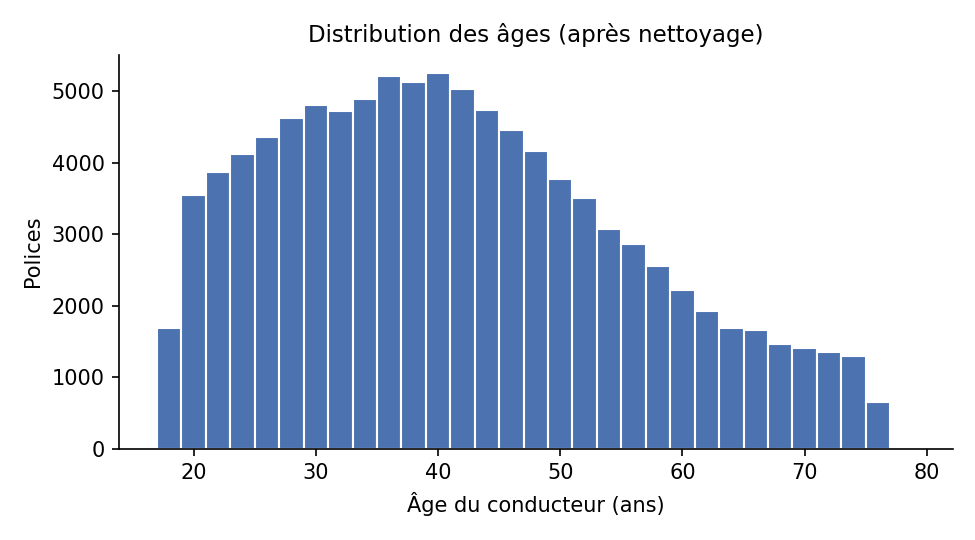

**Figure : correlations**

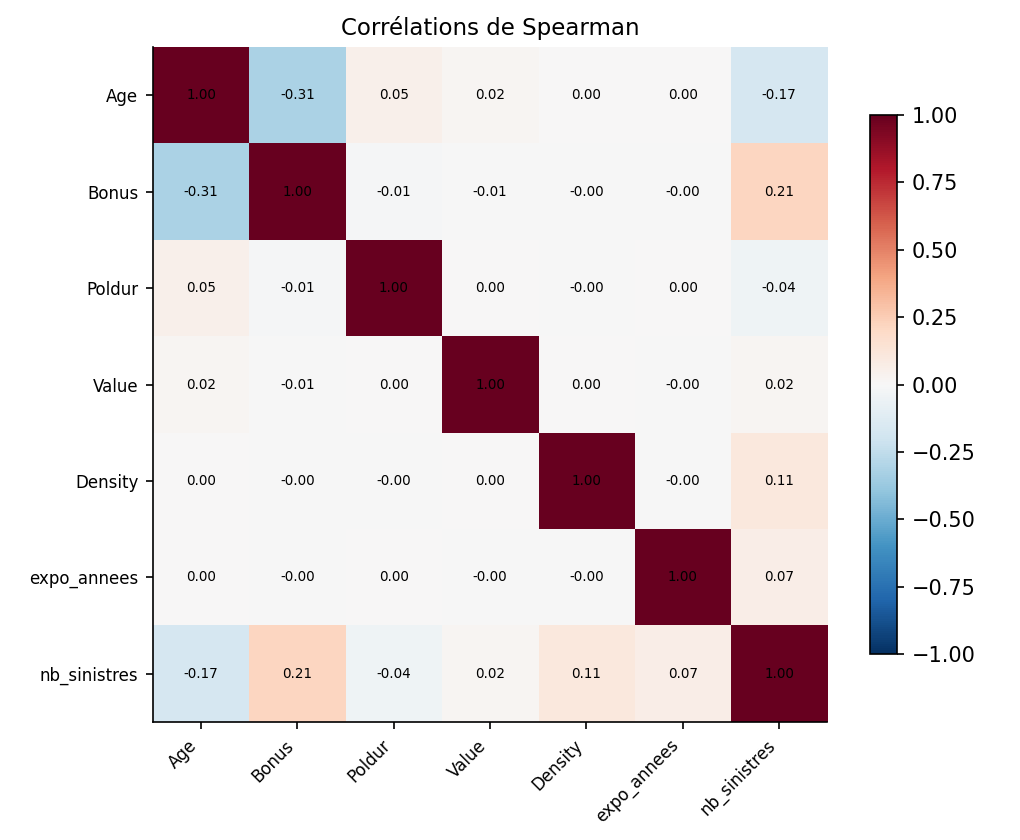

**Figure : cout type**

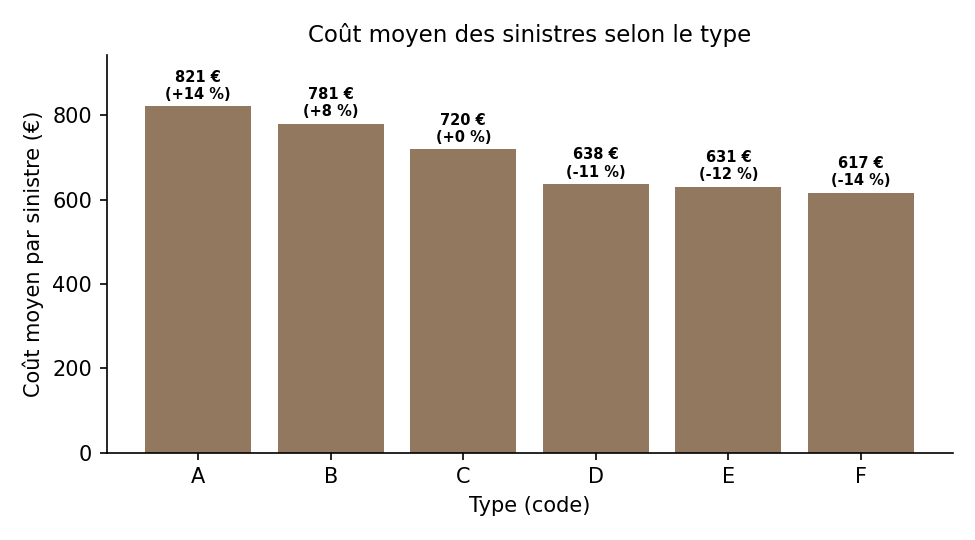

**Figure : frequence age**

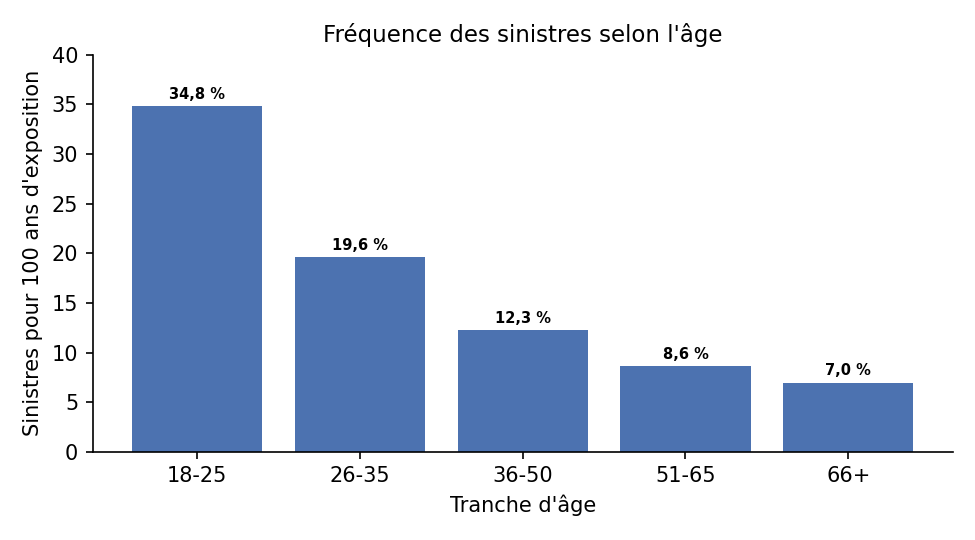

**Figure : frequence anciennete**

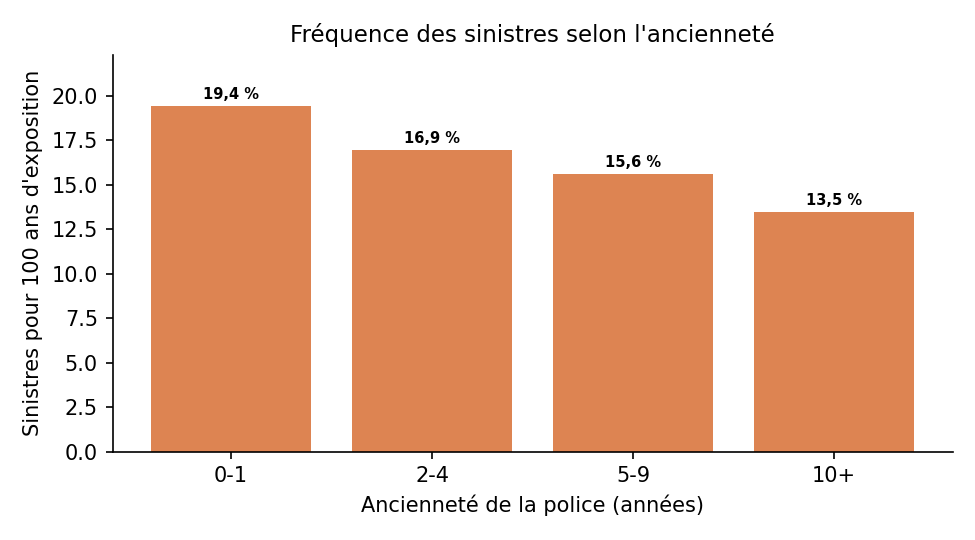

**Figure : montants**

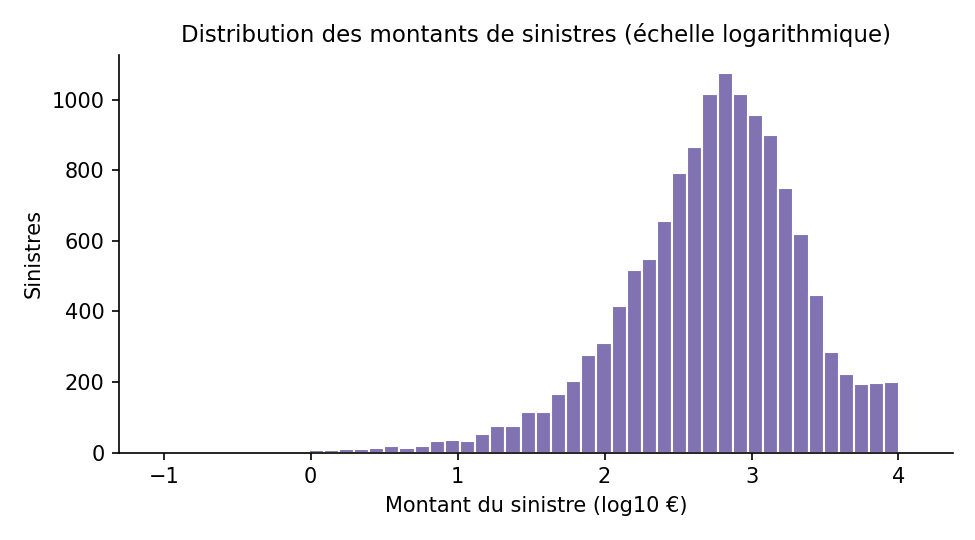

**Figure : nb sinistres**

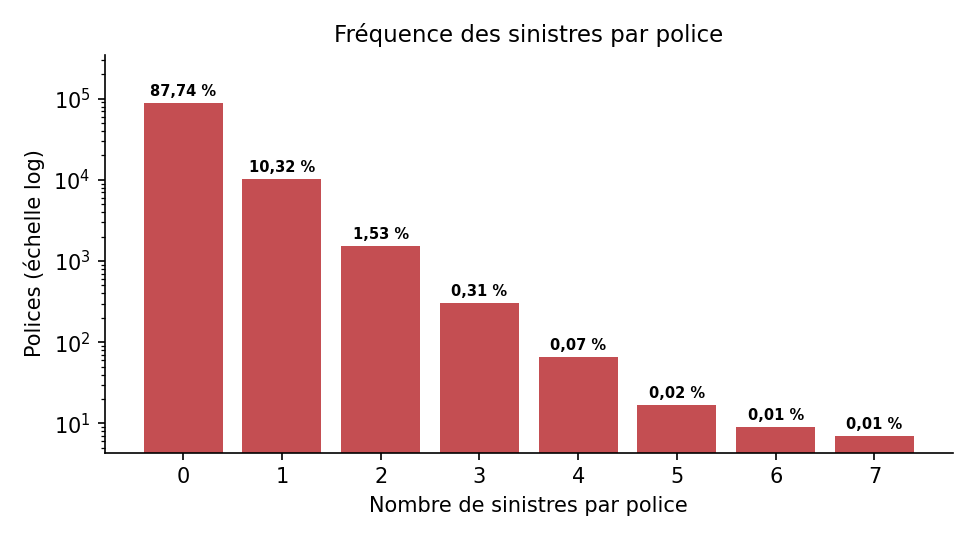

**Figure : value**

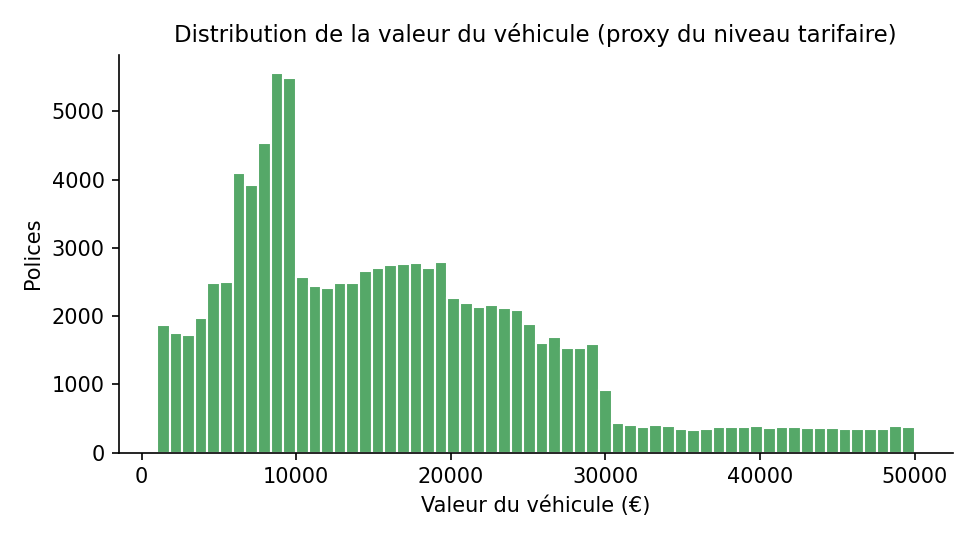

**Répartition du nombre de sinistres par police** — 8 lignes × 3 colonnes

,nb_sinistres,polices,pct
0,0,87744,87.74
1,1,10322,10.32
2,2,1530,1.53
3,3,306,0.306
4,4,65,0.065
5,5,17,0.017
6,6,9,0.009
7,7,7,0.007


**Sinistralité par tranche d'âge** — 5 lignes × 9 colonnes

,tranche_age,polices,exposition,sinistres,cout,part_sinistrees,valeur_moyenne,frequence_pour_100_ans,cout_moyen_par_sinistre
0,18-25,15386,1.379e+04,4800,4.192e+06,23.92,1.61e+04,34.81,873.4
1,26-35,23880,2.144e+04,4202,2.808e+06,14.57,1.627e+04,19.6,668.2
2,36-50,35078,3.151e+04,3867,2.358e+06,9.678,1.658e+04,12.27,609.8
3,51-65,18586,1.667e+04,1436,9.118e+05,6.957,1.661e+04,8.614,634.9
4,66+,7070,"6,342",443,3.457e+05,5.757,1.681e+04,6.985,780.3


**Sinistralité par sexe** — 3 lignes × 9 colonnes

,Gender,polices,exposition,sinistres,cout,part_sinistrees,valeur_moyenne,frequence_pour_100_ans,cout_moyen_par_sinistre
0,Male,63429,5.694e+04,10227,7.515e+06,13.15,1.651e+04,17.96,734.8
1,Female,36566,3.28e+04,4521,3.101e+06,10.7,1.636e+04,13.78,685.9
2,Inconnu,5,5,0,0,0,1.383e+04,0,NaN


... (6 outputs left out)

**GLM de Poisson : rapports de taux** — 16 lignes × 7 colonnes

,facteur,coefficient,erreur_type,rapport_de_taux,ic95_bas,ic95_haut,p_valeur
0,Constante,-3.246,0.1123,0.03892,0.03123,0.0485,0
1,Âge = 18-25,1.067,0.02175,2.908,2.787,3.035,0
2,Âge = 26-35,0.3808,0.02232,1.463,1.401,1.529,0
3,Âge = 51-65,-0.184,0.03105,0.8319,0.7828,0.8841,3.092e-09
4,Âge = 66+,-0.2487,0.05051,0.7798,0.7063,0.8609,8.473e-07
5,Sexe = Female,-0.3327,0.01789,0.717,0.6923,0.7426,0
6,Ancienneté = 0-1,0.1716,0.0225,1.187,1.136,1.241,2.376e-14
7,Ancienneté = 2-4,0.1174,0.02314,1.125,1.075,1.177,3.957e-07
8,Ancienneté = 10+,-0.1329,0.02525,0.8755,0.8333,0.9199,1.4e-07
9,Type = B,0.07023,0.0248,1.073,1.022,1.126,0.004636


#### Points clés
- 87,7 % des polices n'ont **aucun sinistre** sur la période.
- Les **18-25 ans** ont une fréquence de 34,8 sinistres pour 100 ans d'exposition, contre 12,3 pour les 36-50 ans (×2,8).
- Hommes : 18,0 ; femmes : 13,8 sinistres pour 100 ans.
- À caractéristiques égales (GLM), un conducteur de 18-25 ans a **2,91 fois** plus de sinistres qu'un 36-50 ans.
- 15 facteurs du GLM sont significatifs au seuil de 5 %.
- Variable la plus corrélée au nombre de sinistres : **Bonus** (ρ = 0,21).

#### Interprétation
- **Rapport de taux** : 1 = pas d'effet ; 1,5 = 50 % de sinistres en plus que la modalité de référence ; 0,8 = 20 % de moins. La **p-valeur** indique si l'écart peut être dû au hasard (< 5 % : peu probable) ; elle ne dit rien de la taille de l'effet.
- Jeunes conducteurs : écart brut ×2,8, écart ajusté ×2,91. L'effet de l'âge **résiste à l'ajustement** : il ne vient pas d'autres variables (sexe, véhicule, bonus…), c'est un vrai facteur de risque.
- ρ de Spearman maximal = 0,21 : corrélation faible. C'est normal : avec près de 90 % de zéros, aucune variable seule n'explique le nombre de sinistres ; c'est la **combinaison** des facteurs qui compte, d'où le recours au GLM.
- Tous les facteurs du GLM sont significatifs : chacun apporte une information utile.
- La surdispersion vue à l'étape 3 bis rend les intervalles de confiance du Poisson un peu trop étroits : les facteurs dont la p-valeur est juste sous 5 % sont à confirmer.

In [21]:
res["etape5"] = lancer("Étape 5", lambda: etape5(res["etape3"]), "etape5")  # analyse exploratoire
e5 = res["etape5"]  # raccourci

afficher(e5["freq_nb"], "Répartition du nombre de sinistres par police")  # combien de polices ont 0, 1, 2… sinistres
afficher(e5["t_age"], "Sinistralité par tranche d'âge")  # fréquence et coût par âge
afficher(e5["t_sexe"], "Sinistralité par sexe")  # fréquence et coût par sexe
afficher(e5["t_anc"], "Sinistralité par ancienneté")  # fréquence et coût par ancienneté
afficher(e5["t_type"], "Sinistralité par type de véhicule")  # fréquence et coût par type
afficher(e5["cible"], "Corrélation (Spearman) avec le nombre de sinistres")  # variables les plus liées aux sinistres
afficher(e5["glm"], "GLM de Poisson : rapports de taux", 20)  # effets ajustés sur la fréquence

ta = e5["t_age"].set_index("tranche_age")  # tableau par âge indexé
ts = e5["t_sexe"].set_index("Gender")  # tableau par sexe indexé
glm = e5["glm"].set_index("facteur")  # GLM indexé par facteur
sig = (e5["glm"]["p_valeur"] < 0.05).sum() - 1  # facteurs significatifs (hors constante)
cible = e5["cible"].iloc[0]  # variable la plus corrélée
points_cles(  # constats chiffrés
    f"{e5['freq_nb'].iloc[0]['pct']:.1f} % des polices n'ont **aucun sinistre** sur la période.",
    f"Les **18-25 ans** ont une fréquence de {ta.loc['18-25', 'frequence_pour_100_ans']:.1f} sinistres pour 100 ans d'exposition, "
    f"contre {ta.loc['36-50', 'frequence_pour_100_ans']:.1f} pour les 36-50 ans "
    f"(×{ta.loc['18-25', 'frequence_pour_100_ans'] / ta.loc['36-50', 'frequence_pour_100_ans']:.1f}).",
    f"Hommes : {ts.loc['Male', 'frequence_pour_100_ans']:.1f} ; femmes : {ts.loc['Female', 'frequence_pour_100_ans']:.1f} sinistres pour 100 ans.",
    f"À caractéristiques égales (GLM), un conducteur de 18-25 ans a **{glm.loc['Âge = 18-25', 'rapport_de_taux']:.2f} fois** "
    "plus de sinistres qu'un 36-50 ans.",
    f"{sig} facteurs du GLM sont significatifs au seuil de 5 %.",
    f"Variable la plus corrélée au nombre de sinistres : **{cible['variable']}** (ρ = {cible['rho_avec_nb_sinistres']:.2f}).",
)

rr_brut = ta.loc["18-25", "frequence_pour_100_ans"] / ta.loc["36-50", "frequence_pour_100_ans"]  # écart brut
rr_ajuste = glm.loc["Âge = 18-25", "rapport_de_taux"]  # écart à caractéristiques égales
non_sig = e5["glm"][(e5["glm"]["p_valeur"] >= 0.05) & (e5["glm"]["facteur"] != "Constante")]["facteur"]  # non significatifs
rho = abs(cible["rho_avec_nb_sinistres"])  # force de la corrélation la plus forte
interpretation(  # lecture statistique
    "**Rapport de taux** : 1 = pas d'effet ; 1,5 = 50 % de sinistres en plus que la modalité de référence ; "
    "0,8 = 20 % de moins. La **p-valeur** indique si l'écart peut être dû au hasard (< 5 % : peu probable) ; "
    "elle ne dit rien de la taille de l'effet.",
    f"Jeunes conducteurs : écart brut ×{rr_brut:.1f}, écart ajusté ×{rr_ajuste:.2f}. "
    + ("L'effet de l'âge **résiste à l'ajustement** : il ne vient pas d'autres variables (sexe, véhicule, bonus…), "
       "c'est un vrai facteur de risque." if rr_ajuste >= 0.8 * rr_brut
       else "L'effet diminue une fois ajusté : une partie de l'écart brut venait d'autres variables liées à l'âge."),
    f"ρ de Spearman maximal = {rho:.2f} : corrélation "
    + ("faible" if rho < 0.3 else "modérée" if rho < 0.5 else "forte")
    + ". C'est normal : avec près de 90 % de zéros, aucune variable seule n'explique le nombre de sinistres ; "
    "c'est la **combinaison** des facteurs qui compte, d'où le recours au GLM.",
    verdict(len(non_sig) == 0, "Tous les facteurs du GLM sont significatifs : chacun apporte une information utile.",
            f"Facteurs non significatifs : {', '.join(non_sig)}. On peut les regrouper avec la référence ou les retirer."),
    "La surdispersion vue à l'étape 3 bis rend les intervalles de confiance du Poisson un peu trop étroits : "
    "les facteurs dont la p-valeur est juste sous 5 % sont à confirmer.",
)

#### Graphique : rapports de taux du GLM et intervalles de confiance à 95 %
Chaque point est l'effet d'un facteur sur la fréquence **à autres caractéristiques égales** ; le trait horizontal est l'intervalle de confiance à 95 %. À droite de la ligne 1 : plus de sinistres que la modalité de référence ; à gauche : moins. Un intervalle qui ne coupe pas la ligne 1 correspond à un effet significatif. Échelle logarithmique, pour que ×2 et ×0,5 soient à la même distance de 1.

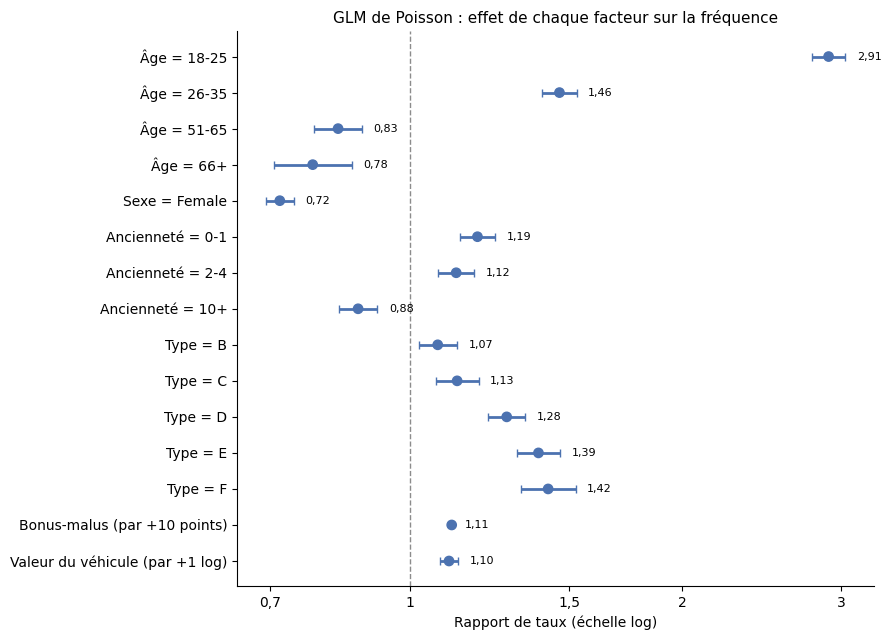

#### Points clés
- 15 facteurs sur 15 ont un intervalle de confiance qui exclut 1.
- Intervalle le plus large : **Âge = 66+** (0,71 à 0,86).
- Bonus-malus : ×1,112 par tranche de 10 points, soit **×2,9** entre un bonus de −50 et un malus de +50.
- Valeur du véhicule : ×1,071 quand la valeur double.

#### Interprétation
- La largeur d'un intervalle dépend surtout du **nombre de sinistres** dans la modalité : plus il y a de sinistres, plus l'estimation est précise. L'intervalle de « Âge = 66+ » est le plus large parce que cette modalité compte peu d'assurés ou peu de sinistres.
- Les intervalles des variables continues (bonus-malus, valeur) sont très étroits : leur effet est estimé sur tout le portefeuille à la fois, et non sur une seule modalité.
- Comme les données sont surdispersées (voir la binomiale négative à l'étape 3 bis), ces intervalles sont un peu trop étroits. Les conclusions ne changent pas pour les effets forts, qui restent loin de 1.

In [22]:
g5 = e5["glm"][e5["glm"]["facteur"] != "Constante"].iloc[::-1].reset_index(drop=True)  # facteurs (premier en haut)
fig, ax = plt.subplots(figsize=(9, 6.5))  # zone de dessin
pos = np.arange(len(g5))  # une ligne par facteur
sig5 = (g5["ic95_bas"] > 1) | (g5["ic95_haut"] < 1)  # intervalle ne contenant pas 1
ax.errorbar(g5["rapport_de_taux"], pos, xerr=[g5["rapport_de_taux"] - g5["ic95_bas"], g5["ic95_haut"] - g5["rapport_de_taux"]],
            fmt="none", ecolor=BLEU, elinewidth=2, capsize=3)  # intervalles de confiance
ax.scatter(g5["rapport_de_taux"], pos, s=45, zorder=3, color=np.where(sig5, BLEU, GRIS))  # rapports de taux
for k, r in g5.iterrows():  # valeur à droite de chaque intervalle
    ax.text(r["ic95_haut"] * 1.03, k, f"{r['rapport_de_taux']:.2f}".replace(".", ","), va="center", fontsize=8)
ax.axvline(1, color=GRIS, ls="--", lw=1)  # absence d'effet
ax.set_xscale("log")  # échelle logarithmique
graduations = [0.7, 1, 1.5, 2, 3]  # graduations lisibles
ax.set_xticks(graduations, [str(g).replace(".", ",") for g in graduations])
ax.minorticks_off()  # pas de petites graduations
ax.set_yticks(pos, g5["facteur"])  # noms des facteurs
ax.set_xlabel("Rapport de taux (échelle log)")  # axe horizontal
ax.set_title("GLM de Poisson : effet de chaque facteur sur la fréquence")  # titre
plt.tight_layout()  # ajuste les marges
montrer_fig("glm_forest_plot")  # affiche et enregistre la figure

g5["largeur_rel"] = g5["ic95_haut"] / g5["ic95_bas"]  # largeur relative de l'intervalle
moins_precis = g5.loc[g5["largeur_rel"].idxmax()]  # facteur le moins précis
rr_bonus = glm.loc["Bonus-malus (par +10 points)", "rapport_de_taux"]  # effet de +10 points de bonus-malus
rr_valeur = glm.loc["Valeur du véhicule (par +1 log)", "rapport_de_taux"]  # effet de +1 en log de la valeur
points_cles(
    f"{sig5.sum()} facteurs sur {len(g5)} ont un intervalle de confiance qui exclut 1.",
    f"Intervalle le plus large : **{moins_precis['facteur']}** ({moins_precis['ic95_bas']:.2f} à {moins_precis['ic95_haut']:.2f}).",
    f"Bonus-malus : ×{rr_bonus:.3f} par tranche de 10 points, soit **×{rr_bonus ** 10:.1f}** entre un bonus de −50 et un malus de +50.",
    f"Valeur du véhicule : ×{rr_valeur ** np.log(2):.3f} quand la valeur double.",
)
interpretation(
    "La largeur d'un intervalle dépend surtout du **nombre de sinistres** dans la modalité : plus il y a de sinistres, plus "
    f"l'estimation est précise. L'intervalle de « {moins_precis['facteur']} » est le plus large parce que cette modalité "
    "compte peu d'assurés ou peu de sinistres.",
    "Les intervalles des variables continues (bonus-malus, valeur) sont très étroits : leur effet est estimé sur tout le "
    "portefeuille à la fois, et non sur une seule modalité.",
    "Comme les données sont surdispersées (voir la binomiale négative à l'étape 3 bis), ces intervalles sont un peu trop "
    "étroits. Les conclusions ne changent pas pour les effets forts, qui restent loin de 1.",
)
pour_rapport("glm_forest_plot", "Étape 5 : rapports de taux du GLM de Poisson",
             "Rapports de taux du GLM de fréquence et intervalles de confiance à 95 % (échelle logarithmique).")

### Étape 6 — Segmentation (ACP, k-means, classification hiérarchique)

**Objectif.** Regrouper les polices en profils de risque homogènes.

**Méthode.**
- *ACP* (analyse en composantes principales) : résume les 5 variables numériques standardisées (âge, bonus, ancienneté, valeur, densité) en quelques axes ;
- *k-means* : forme k groupes ; k est choisi à l'aide de l'inertie (méthode du coude) et du score de silhouette ;
- *Classification hiérarchique* : seconde méthode pour vérifier que les groupes sont stables. L'accord entre les deux méthodes est mesuré par l'**ARI** (0 = hasard, 1 = groupes identiques).

**Comment lire.** Une variable avec une charge forte (proche de ±1) sur un axe est bien résumée par cet axe. Les profils se comparent surtout par leur **fréquence** et leur **charge annuelle**.

#### Code : ACP, k-means, classification hiérarchique

Définition des fonctions de l'étape. Le résultat de leur exécution s'affiche dans la cellule suivante.

In [23]:
# ===========================================================================
# ÉTAPE 6 – SEGMENTATION ET RÉDUCTION DE DIMENSION
# ===========================================================================


VARIABLES_SEG = ["Age", "Bonus", "Poldur", "log_valeur", "log_densite"]


LIBELLES_SEG = {"Age": "Âge", "Bonus": "Bonus-malus", "Poldur": "Ancienneté",
                "log_valeur": "Valeur (log)", "log_densite": "Densité (log)"}


NOMS_PROFILS = ["Faible risque", "Risque intermédiaire", "Risque élevé"]


def etape6(e3: dict) -> dict:

    base = e3["base"].copy()
    figures = {}
    base["Age"] = base["Age"].astype(float)
    base["Bonus"] = base["Bonus"].astype(float)
    base["Poldur"] = base["Poldur"].astype(float)
    base["Value"] = base["Value"].astype(float)
    base["log_valeur"] = np.log(base["Value"].clip(lower=1))
    base["log_densite"] = np.log1p(base["Density"].astype(float).clip(lower=0))
    base["femme"] = (base["Gender"].astype(str) == "Female").astype(float)
    Z = StandardScaler().fit_transform(base[VARIABLES_SEG].to_numpy())
    rng = np.random.default_rng(GRAINE)

    # ---- ACP ---------------------------------------------------------------------------
    acp = PCA(random_state=GRAINE).fit(Z)
    composantes = acp.transform(Z)
    var = pd.DataFrame({
        "composante": [f"CP{i + 1}" for i in range(len(VARIABLES_SEG))],
        "valeur_propre": acp.explained_variance_,
        "pct_variance": 100 * acp.explained_variance_ratio_,
        "pct_cumule": 100 * np.cumsum(acp.explained_variance_ratio_),
    })
    var.to_csv(SORTIE / "etape6_acp_variance.csv", index=False, sep=";", decimal=",")
    # Corrélation variable / composante = vecteur propre × racine de la valeur propre (données standardisées)
    charges = pd.DataFrame(acp.components_[:2].T * np.sqrt(acp.explained_variance_[:2]),
                           columns=["CP1", "CP2"])
    charges.insert(0, "variable", VARIABLES_SEG)
    charges.to_csv(SORTIE / "etape6_acp_charges.csv", index=False, sep=";", decimal=",")

    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    b = ax.bar(var["composante"], var["pct_variance"], color="#4C72B0", label="% de variance")
    ax.bar_label(b, labels=_pct(var["pct_variance"]), label_type="center", fontsize=7, color="white",
                 fontweight="bold")  # % de variance dans le bâton (la courbe passe au-dessus)
    ax.plot(var["composante"], var["pct_cumule"], "o-", color="#C44E52", label="% cumulé")
    ax.set_ylabel("% de la variance"); ax.set_ylim(0, 105); ax.legend(fontsize=8)
    ax.set_title("Éboulis des valeurs propres (ACP)")
    figures["acp_eboulis"] = _sauver_fig(fig, "fig_acp_eboulis")

    fig, ax = plt.subplots(figsize=(5.2, 5.2))
    theta = np.linspace(0, 2 * np.pi, 200)
    ax.plot(np.cos(theta), np.sin(theta), color="grey", lw=0.8)
    ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
    for _, r in charges.iterrows():
        ax.arrow(0, 0, r["CP1"], r["CP2"], head_width=0.04, length_includes_head=True, color="#4C72B0")
        ax.text(r["CP1"] * 1.15, r["CP2"] * 1.15, LIBELLES_SEG[r["variable"]], fontsize=8, ha="center")
    ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.3, 1.3); ax.set_aspect("equal")
    ax.set_xlabel(f"CP1 ({var['pct_variance'][0]:.1f} %)"); ax.set_ylabel(f"CP2 ({var['pct_variance'][1]:.1f} %)")
    ax.set_title("Cercle des corrélations")
    figures["acp_cercle"] = _sauver_fig(fig, "fig_acp_cercle")

    # ---- Choix du nombre de groupes (K-means) -------------------------------------------
    idx_sil = rng.choice(len(Z), size=min(20000, len(Z)), replace=False)
    lignes_k = []
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=10, random_state=GRAINE).fit(Z)
        lignes_k.append({"k": k, "inertie": km.inertia_,
                         "silhouette": silhouette_score(Z[idx_sil], km.labels_[idx_sil])})
    choix_k = pd.DataFrame(lignes_k)
    choix_k.to_csv(SORTIE / "etape6_kmeans_choix_k.csv", index=False, sep=";", decimal=",")

    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    ax.plot(choix_k["k"], choix_k["inertie"], "o-", color="#4C72B0")
    ax.set_xlabel("Nombre de groupes k"); ax.set_ylabel("Inertie intra-groupes")
    ax2 = ax.twinx()
    ax2.plot(choix_k["k"], choix_k["silhouette"], "s--", color="#C44E52")
    ax2.set_ylabel("Silhouette (rouge)", color="#C44E52")
    ax.set_title("Choix de k : coude de l'inertie et silhouette")
    figures["kmeans_k"] = _sauver_fig(fig, "fig_kmeans_choix_k")

    # ---- Segmentation finale : K-means à 3 groupes --------------------------------------
    km3 = KMeans(n_clusters=3, n_init=10, random_state=GRAINE).fit(Z)
    base["segment_brut"] = km3.labels_

    # Validation : classification hiérarchique de Ward sur un échantillon
    idx_h = rng.choice(len(Z), size=3000, replace=False)
    hier = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(Z[idx_h])
    ari = adjusted_rand_score(km3.labels_[idx_h], hier)
    hier_df = pd.DataFrame([{"methode": "K-means (k=3)", "echantillon": 3000,
                             "concordance_ARI_avec_hierarchique": ari}])
    hier_df.to_csv(SORTIE / "etape6_hierarchique_comparaison.csv", index=False, sep=";", decimal=",")

    # ---- Profils : caractéristiques et sinistralité ----------------------------------------
    prof = base.groupby("segment_brut").agg(
        polices=("PolNum", "size"), exposition=("expo_annees", "sum"),
        sinistres=("nb_sinistres", "sum"), cout=("cout_total", "sum"),
        age=("Age", "mean"), bonus=("Bonus", "mean"), poldur=("Poldur", "mean"),
        valeur=("Value", "mean"), part_femmes=("femme", "mean"),
    ).reset_index()
    prof["part_polices"] = 100 * prof["polices"] / prof["polices"].sum()
    prof["frequence_pour_100_ans"] = 100 * prof["sinistres"] / prof["exposition"]
    prof["cout_moyen_par_sinistre"] = prof["cout"] / prof["sinistres"].replace(0, np.nan)
    prof["charge_annuelle"] = prof["cout"] / prof["exposition"]
    prof["part_femmes"] = 100 * prof["part_femmes"]
    # Nommage selon la charge annuelle moyenne (coût total / exposition) : la plus faible = faible risque
    prof = prof.sort_values("charge_annuelle").reset_index(drop=True)
    prof["profil"] = NOMS_PROFILS
    base["profil"] = base["segment_brut"].map(dict(zip(prof["segment_brut"], prof["profil"])))
    prof.to_csv(SORTIE / "etape6_profils.csv", index=False, sep=";", decimal=",")
    base[["PolNum", "segment_brut", "profil"]].to_csv(SORTIE / "etape6_affectation_polices.csv",
                                                       index=False, sep=";")

    # Figures : projection ACP colorée par profil, et sinistralité par profil
    couleurs = {"Faible risque": "#55A868", "Risque intermédiaire": "#DD8452", "Risque élevé": "#C44E52"}
    idx_plot = rng.choice(len(Z), size=5000, replace=False)
    fig, ax = plt.subplots(figsize=(6.5, 4.2))
    for nom in NOMS_PROFILS:
        m = idx_plot[base["profil"].values[idx_plot] == nom]
        ax.scatter(composantes[m, 0], composantes[m, 1], s=4, alpha=0.5, color=couleurs[nom], label=nom)
    ax.set_xlabel("CP1"); ax.set_ylabel("CP2"); ax.legend(fontsize=8, markerscale=3)
    ax.set_title("Polices (échantillon de 5 000) projetées sur le premier plan de l'ACP")
    figures["profils_acp"] = _sauver_fig(fig, "fig_profils_acp")

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 3.6))
    cols = [couleurs[n] for n in prof["profil"]]
    b1 = a1.bar(prof["profil"], prof["frequence_pour_100_ans"], color=cols)
    _etiqueter(a1, b1, _pct(prof["frequence_pour_100_ans"]))  # fréquence annuelle en %
    a1.set_title("Fréquence (sinistres /100 ans)", fontsize=9)
    b2 = a2.bar(prof["profil"], prof["charge_annuelle"], color=cols)
    part = 100 * prof["cout"] / prof["cout"].sum()  # part du coût total portée par chaque profil
    _etiqueter(a2, b2, [f"{v:.0f} €\n({q:.0f} % du coût)" for v, q in zip(prof["charge_annuelle"], part)])
    a2.set_title("Charge annuelle (€ par an d'exposition)", fontsize=9)
    for a in (a1, a2):
        a.tick_params(axis="x", labelrotation=20, labelsize=7)
    figures["profils_risque"] = _sauver_fig(fig, "fig_profils_risque")

    print(f"Étape 6 : ACP ({var['pct_cumule'][1]:.1f} % de variance sur 2 axes), k-means k=3, "
          f"concordance hiérarchique ARI = {ari:.2f}")
    return {"var": var, "charges": charges, "choix_k": choix_k, "prof": prof, "ari": ari,
            "figures": figures, "n_base": len(base), "variables": VARIABLES_SEG}


def section_etape6(e6: dict) -> str:
    f = e6["figures"]
    prof = e6["prof"]
    var = e6["var"]
    def fig(chemin, legende, largeur="0.85"):
        return ("\\begin{figure}[htbp]\\centering\\includegraphics[width=" + largeur + "\\textwidth]{" + chemin + "}\n"
                "\\caption{" + echapper(legende) + "}\\end{figure}\n")

    lignes_v = [[r["composante"], nombre(r["valeur_propre"], 3), nombre(r["pct_variance"], 1),
                 nombre(r["pct_cumule"], 1)] for r in var.to_dict("records")]
    lignes_k = [[nombre(r["k"]), nombre(r["inertie"], 0), nombre(r["silhouette"], 3)]
                for r in e6["choix_k"].to_dict("records")]
    lignes_p = []
    for r in prof.to_dict("records"):
        lignes_p.append([echapper(r["profil"]), nombre(r["part_polices"], 1), nombre(r["age"], 1),
                         nombre(r["bonus"], 1), nombre(r["poldur"], 1), nombre(r["valeur"], 0),
                         nombre(r["frequence_pour_100_ans"], 2), nombre(r["cout_moyen_par_sinistre"], 0),
                         nombre(r["charge_annuelle"], 0), nombre(r["part_femmes"], 1)])
    p = {r["profil"]: r for r in prof.to_dict("records")}
    faible, moyen, eleve = p["Faible risque"], p["Risque intermédiaire"], p["Risque élevé"]
    return (
        "\n\\part{Étape 6 -- Segmentation et réduction de dimension}\n\\section{Objectif}\n"
        "Identifier des groupes d'assurés aux caractéristiques proches, afin de repérer des profils de risque "
        "(faible, intermédiaire, élevé).\n"
        "\\section{Méthode}\n"
        "\\begin{enumerate}\n"
        "  \\item \\textbf{Variables de segmentation} : âge du conducteur, bonus-malus, ancienneté de la police, "
        "valeur du véhicule (log) et densité de la zone (log). Ce sont des caractéristiques connues à la "
        "souscription. Les sinistres ne sont \\emph{pas} utilisés pour construire les groupes : ils servent "
        "ensuite à vérifier et à nommer les profils, ce qui évite un raisonnement circulaire.\n"
        "  \\item \\textbf{Réduction de dimension (ACP)} : les variables sont centrées et réduites, puis une ACP "
        "résume la structure. Elle sert à lire les groupes et à les visualiser.\n"
        "  \\item \\textbf{Nombre de groupes} : K-means testé de $k=2$ à $k=8$ (inertie et silhouette). "
        "On retient $k=3$, demandé par l'objectif (trois profils).\n"
        "  \\item \\textbf{Validation} : une classification hiérarchique de Ward, sur un échantillon de 3 000 polices, "
        "est comparée au K-means (indice ARI, 1 = concordance parfaite).\n"
        "  \\item \\textbf{Nommage} : les groupes sont classés par charge annuelle moyenne (coût total / exposition). "
        "Le plus faible est « faible risque », le plus élevé « risque élevé ».\n"
        "  \\item \\textbf{Non retenu} : l'analyse factorielle des correspondances multiples (ACM), prévue pour les "
        "variables qualitatives. Le sexe, le type, la catégorie et la profession ne sont donc pas dans la "
        "segmentation. Une ACM pourrait les intégrer dans une étape ultérieure.\n"
        "\\end{enumerate}\n"
        "\\section{A. Réduction de dimension : ACP}\n"
        + fig(f["acp_eboulis"], "Éboulis des valeurs propres : part de variance de chaque composante et cumul.", "0.7")
        + tableau("Valeurs propres de l'ACP", "tab:e6_acp",
                  ["Composante", "Valeur propre", "\\% variance", "\\% cumulé"], lignes_v, "lrrr")
        + fig(f["acp_cercle"], "Cercle des corrélations : contribution des variables aux deux premières composantes.", "0.6")
        + "\\section{B. Choix du nombre de groupes}\n"
        + fig(f["kmeans_k"], "Inertie intra-groupes (bleu) et silhouette (rouge) selon le nombre de groupes $k$.", "0.8")
        + tableau("Inertie et silhouette selon le nombre de groupes", "tab:e6_k",
                  ["$k$", "Inertie", "Silhouette"], lignes_k, "rrr")
        + "\\section{C. Profils d'assurés}\n"
        "Le K-means à $k=3$ produit trois groupes. Concordance avec la classification hiérarchique : ARI = "
        + nombre(e6["ari"], 2) + " (échantillon de 3 000 polices). Cette concordance est \\textbf{modérée} : les "
        "deux méthodes ne tracent pas exactement les mêmes frontières, signe que les groupes se recouvrent.\n"
        + fig(f["profils_acp"], "Polices projetées sur le premier plan de l'ACP, colorées selon leur profil.")
        + tableau("Caractéristiques et sinistralité des trois profils", "tab:e6_profils",
                  ["Profil", "Polices \\%", "Âge", "Bonus", "Ancien.", "Valeur (€)", "Fréq. /100 ans",
                   "Coût moy. (€)", "Charge (€/an)", "\\% femmes"], lignes_p,
                  "p{2.7cm}*{9}{>{\\raggedleft\\arraybackslash}p{1.25cm}}")
        + fig(f["profils_risque"], "Fréquence et charge annuelle moyenne par profil.")
        + "\\section{Interprétation}\n\\begin{itemize}\n"
        f"  \\item \\textbf{{Faible risque}} ({nombre(faible['part_polices'], 1)} \\% des polices) : fréquence de "
        f"{nombre(faible['frequence_pour_100_ans'], 2)} sinistres pour 100 ans, charge annuelle de "
        f"{nombre(faible['charge_annuelle'], 0)} €.\n"
        f"  \\item \\textbf{{Risque intermédiaire}} ({nombre(moyen['part_polices'], 1)} \\% des polices) : fréquence de "
        f"{nombre(moyen['frequence_pour_100_ans'], 2)} sinistres pour 100 ans, charge annuelle de "
        f"{nombre(moyen['charge_annuelle'], 0)} €.\n"
        f"  \\item \\textbf{{Risque élevé}} ({nombre(eleve['part_polices'], 1)} \\% des polices) : fréquence de "
        f"{nombre(eleve['frequence_pour_100_ans'], 2)} sinistres pour 100 ans, charge annuelle de "
        f"{nombre(eleve['charge_annuelle'], 0)} €.\n"
        "\\end{itemize}\n"
        "\\section{Limites}\n\\begin{enumerate}\n"
        "  \\item Le jeu de données ne contient pas de \\emph{prime}. Les profils reflètent donc les caractéristiques "
        "de risque, et non le niveau de tarif réellement appliqué.\n"
        "  \\item Les profils sont des \\emph{groupes statistiques} : ils décrivent des assurés semblables, ils "
        "n'expliquent pas la cause des sinistres.\n"
        "  \\item Le choix $k=3$ est imposé par l'objectif. La silhouette reste faible (environ 0,17 pour "
        "toutes les valeurs de $k$) et la courbe d'inertie n'a pas de coude net : il n'existe pas de nombre de "
        "groupes naturellement meilleur. Les profils sont des découpages utiles, pas des catégories tranchées.\n"
        "  \\item Les variables qualitatives ne sont pas dans la segmentation (voir Méthode).\n"
        "\\end{enumerate}\n"
    )

print("Fonctions chargées (2) ; fonction principale : etape6()")  # confirme l'exécution de la cellule


Fonctions chargées (2) ; fonction principale : etape6()


Étape 6 : ACP (44.5 % de variance sur 2 axes), k-means k=3, concordance hiérarchique ARI = 0.36


*Étape 6 terminée en 12.0 s*

**Figure : acp cercle**

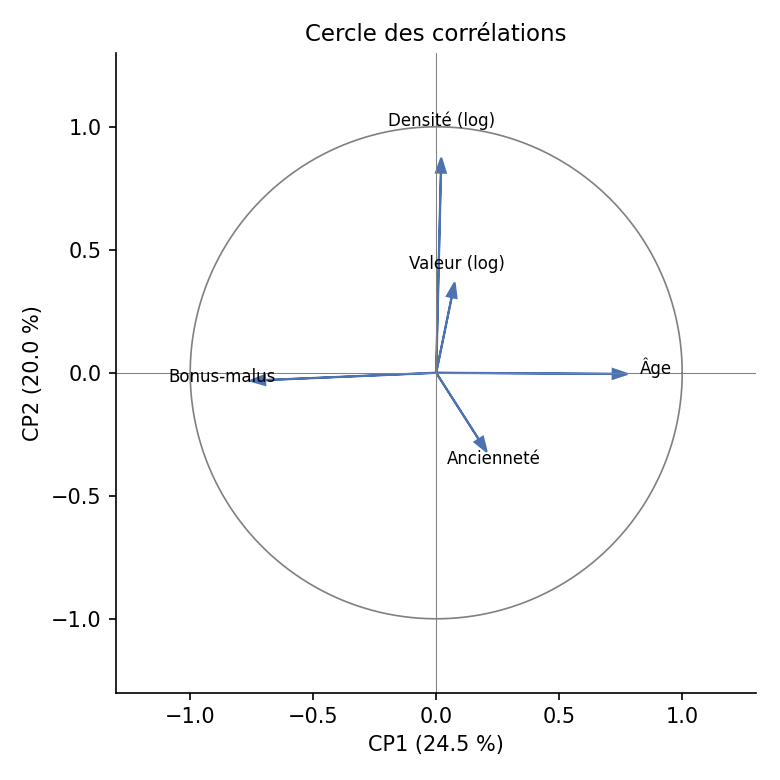

**Figure : acp eboulis**

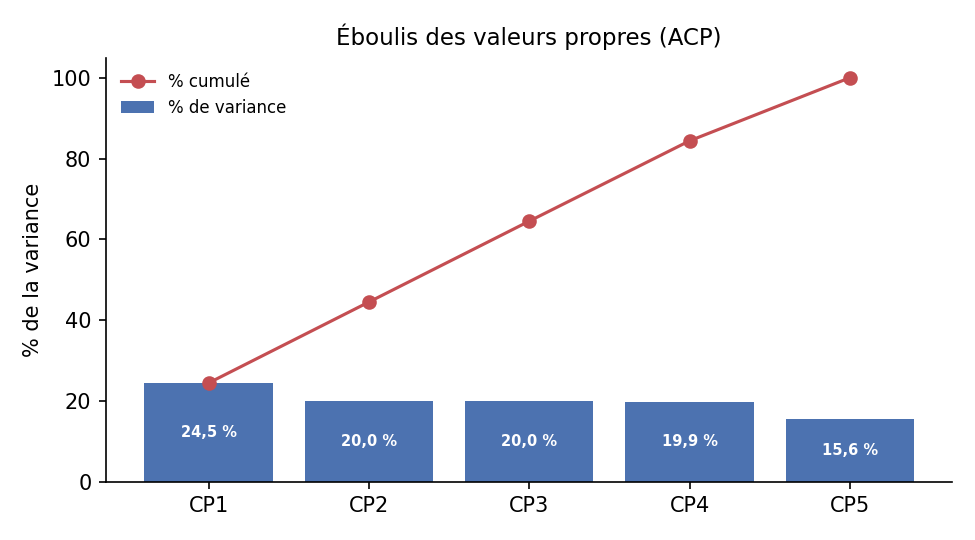

**Figure : kmeans choix k**

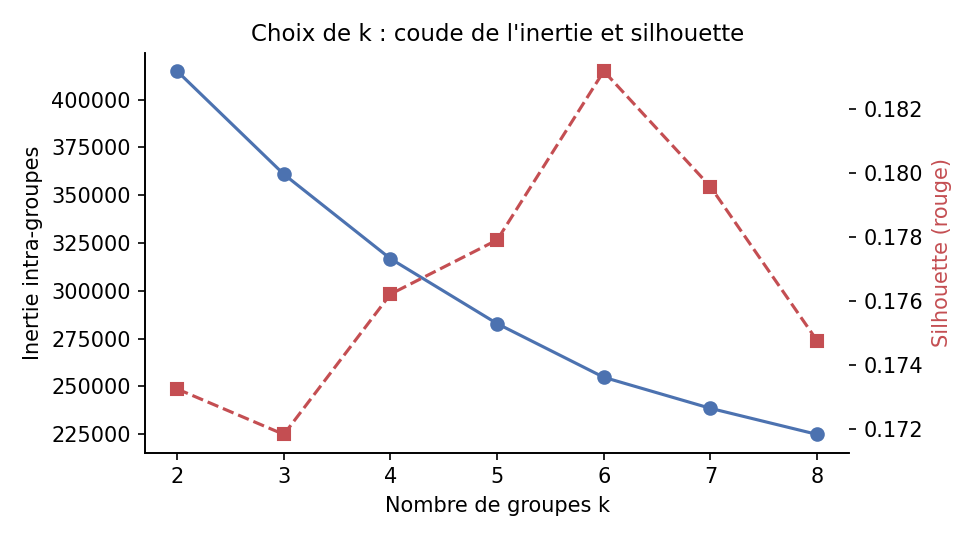

**Figure : profils acp**

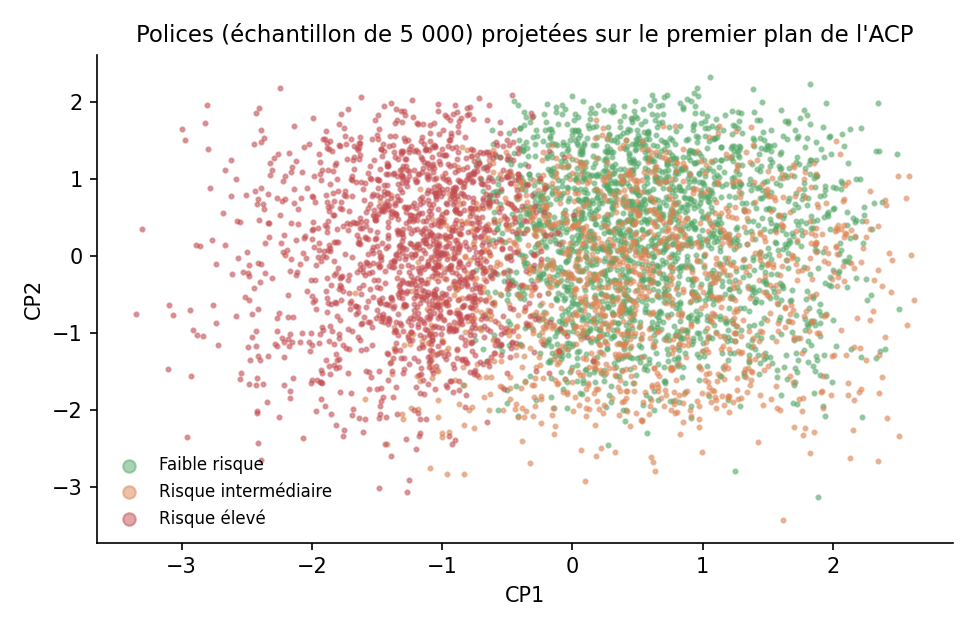

**Figure : profils risque**

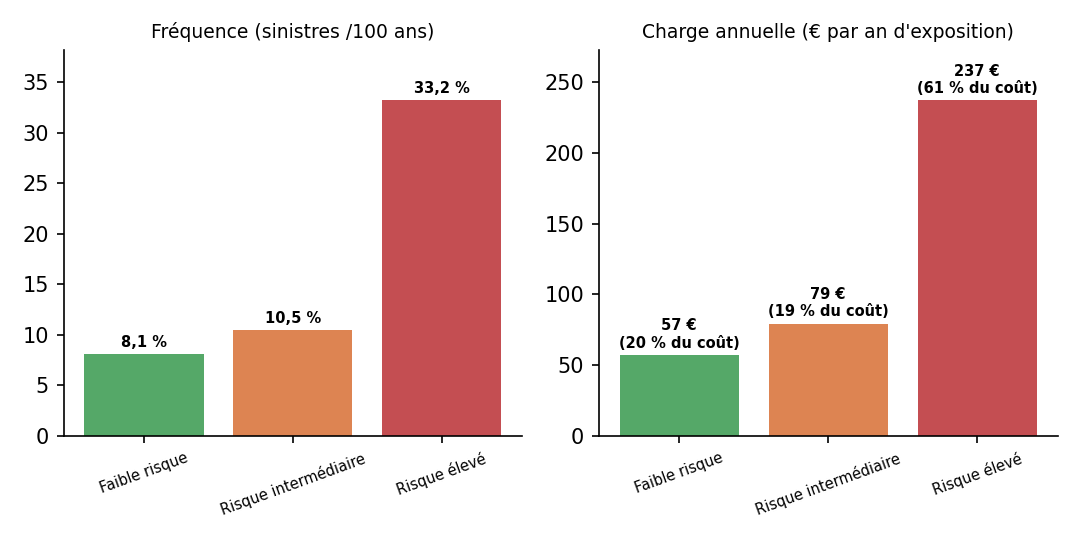

**ACP : variance expliquée par axe** — 5 lignes × 4 colonnes

,composante,valeur_propre,pct_variance,pct_cumule
0,CP1,1.224,24.47,24.47
1,CP2,1.002,20.03,44.51
2,CP3,1,20,64.51
3,CP4,0.9935,19.87,84.38
4,CP5,0.7809,15.62,100


**ACP : charges des variables sur les deux premiers axes** — 5 lignes × 3 colonnes

,variable,CP1,CP2
0,Age,0.7775,-0.00481
1,Bonus,-0.7557,-0.03223
2,Poldur,0.2053,-0.3212
3,log_valeur,0.07498,0.3666
4,log_densite,0.02043,0.8735


**Choix du nombre de groupes (k)** — 7 lignes × 3 colonnes

,k,inertie,silhouette
0,2,4.149e+05,0.1733
1,3,3.61e+05,0.1718
2,4,3.168e+05,0.1762
3,5,2.828e+05,0.1779
4,6,2.547e+05,0.1832
5,7,2.385e+05,0.1796
6,8,2.248e+05,0.1748


**Profils de risque obtenus** — 3 lignes × 14 colonnes

,segment_brut,polices,exposition,sinistres,cout,age,bonus,poldur,valeur,part_femmes,part_polices,frequence_pour_100_ans,cout_moyen_par_sinistre,charge_annuelle
profil,,,,,,,,,,,,,,
Faible risque,2,41091,3.69e+04,2994,2.114e+06,47.68,-35.42,2.69,1.665e+04,34.6,41.09,8.114,706,57.28
Risque intermédiaire,1,28462,2.555e+04,2682,2.028e+06,41.9,-21.24,11.33,1.651e+04,36.85,28.46,10.5,756.3,79.39
Risque élevé,0,30447,2.73e+04,9072,6.474e+06,31.55,44.89,3.754,1.614e+04,38.95,30.45,33.23,713.6,237.1


#### Points clés
- Les deux premiers axes de l'ACP résument **44,5 %** de l'information. C'est peu : les variables sont peu corrélées entre elles, et chacune apporte une information propre.
- Axe 1 : surtout **Age** (+0,78) et **Bonus** (-0,76) ; axe 2 : surtout **log_densite**.
- Profil « Risque élevé » : 30,4 % des polices, fréquence 33,2 pour 100 ans, âge moyen 32 ans, bonus moyen +45.
- Profil « Faible risque » : 41,1 % des polices, fréquence 8,1 pour 100 ans, soit **4,1 fois moins** que le profil le plus risqué.
- Accord k-means / hiérarchique : ARI = 0,36. C'est un accord modéré : les grandes tendances sont stables, mais les frontières entre les groupes ne sont pas nettes.

#### Interprétation
- Le plan 1-2 ne résume que 45 % de l'information, et les valeurs propres sont toutes proches de 1 : les variables sont presque indépendantes. Les graphiques de l'ACP sont une aide visuelle, pas une preuve : les distances y sont déformées.
- Axe 1 : Age et Bonus s'opposent → on peut le lire comme un axe **« expérience du conducteur »** (jeunes avec malus d'un côté, conducteurs âgés avec bonus de l'autre).
- Silhouette maximale 0,18 (une valeur sous 0,25 indique une structure faible) : les groupes ne sont pas naturellement séparés. Le portefeuille forme un **continuum de risque** plutôt que des classes distinctes.
- ARI = 0,36 : les deux méthodes ne s'accordent que partiellement, ce qui confirme que les frontières entre groupes sont floues.
- Malgré cela, les profils séparent bien le risque (fréquence ×4,1). Ils sont utiles pour **décrire et communiquer** (souscription, marketing) ; le tarif, lui, se construit avec un GLM.

In [24]:
res["etape6"] = lancer("Étape 6", lambda: etape6(res["etape3"]), "etape6")  # segmentation
e6 = res["etape6"]  # raccourci

afficher(e6["var"], "ACP : variance expliquée par axe")  # part d'information de chaque axe
afficher(e6["charges"], "ACP : charges des variables sur les deux premiers axes")  # contribution de chaque variable
afficher(e6["choix_k"], "Choix du nombre de groupes (k)")  # inertie et silhouette selon k
afficher(e6["prof"].set_index("profil"), "Profils de risque obtenus")  # description de chaque groupe

pr = e6["prof"].set_index("profil")  # profils indexés par nom
ch = e6["charges"].set_index("variable")  # charges indexées
haut, bas = pr["frequence_pour_100_ans"].idxmax(), pr["frequence_pour_100_ans"].idxmin()  # profils extrêmes
axe1 = ch["CP1"].abs().nlargest(2).index  # deux variables les plus liées à l'axe 1
points_cles(  # constats chiffrés
    f"Les deux premiers axes de l'ACP résument **{e6['var'].iloc[1]['pct_cumule']:.1f} %** de l'information. "
    "C'est peu : les variables sont peu corrélées entre elles, et chacune apporte une information propre.",
    f"Axe 1 : surtout **{axe1[0]}** ({ch.loc[axe1[0], 'CP1']:+.2f}) et **{axe1[1]}** ({ch.loc[axe1[1], 'CP1']:+.2f}) ; "
    f"axe 2 : surtout **{ch['CP2'].abs().idxmax()}**.",
    f"Profil « {haut} » : {pr.loc[haut, 'part_polices']:.1f} % des polices, fréquence "
    f"{pr.loc[haut, 'frequence_pour_100_ans']:.1f} pour 100 ans, âge moyen {pr.loc[haut, 'age']:.0f} ans, bonus moyen {pr.loc[haut, 'bonus']:+.0f}.",
    f"Profil « {bas} » : {pr.loc[bas, 'part_polices']:.1f} % des polices, fréquence "
    f"{pr.loc[bas, 'frequence_pour_100_ans']:.1f} pour 100 ans, soit "
    f"**{pr.loc[haut, 'frequence_pour_100_ans'] / pr.loc[bas, 'frequence_pour_100_ans']:.1f} fois moins** que le profil le plus risqué.",
    f"Accord k-means / hiérarchique : ARI = {e6['ari']:.2f}. C'est un accord modéré : les grandes tendances sont "
    "stables, mais les frontières entre les groupes ne sont pas nettes.",
)

sil = e6["choix_k"]["silhouette"].max()  # meilleure silhouette
opposes = np.sign(ch.loc[axe1[0], "CP1"]) != np.sign(ch.loc[axe1[1], "CP1"])  # signes opposés sur l'axe 1 ?
interpretation(  # lecture de la segmentation
    verdict(e6["var"].iloc[1]["pct_cumule"] >= 60, "Le plan factoriel résume bien les données.",
            f"Le plan 1-2 ne résume que {e6['var'].iloc[1]['pct_cumule']:.0f} % de l'information, et les valeurs propres sont "
            "toutes proches de 1 : les variables sont presque indépendantes. Les graphiques de l'ACP sont une aide visuelle, "
            "pas une preuve : les distances y sont déformées."),
    f"Axe 1 : {axe1[0]} et {axe1[1]} " + ("s'opposent" if opposes else "vont dans le même sens")
    + " → on peut le lire comme un axe **« expérience du conducteur »** (jeunes avec malus d'un côté, conducteurs "
    "âgés avec bonus de l'autre).",
    verdict(sil >= 0.5, f"Silhouette {sil:.2f} : les groupes sont bien séparés.",
            f"Silhouette maximale {sil:.2f} (une valeur sous 0,25 indique une structure faible) : les groupes ne sont pas "
            "naturellement séparés. Le portefeuille forme un **continuum de risque** plutôt que des classes distinctes."),
    verdict(e6["ari"] >= 0.65, f"ARI = {e6['ari']:.2f} : les deux méthodes trouvent les mêmes groupes.",
            f"ARI = {e6['ari']:.2f} : les deux méthodes ne s'accordent que partiellement, ce qui confirme que les frontières "
            "entre groupes sont floues."),
    f"Malgré cela, les profils séparent bien le risque (fréquence ×{pr.loc[haut, 'frequence_pour_100_ans'] / pr.loc[bas, 'frequence_pour_100_ans']:.1f}). "
    "Ils sont utiles pour **décrire et communiquer** (souscription, marketing) ; le tarif, lui, se construit avec un GLM.",
)

### Étape 7 — Modélisation de la fréquence et du coût

**Objectif.** Prédire le coût annuel attendu de chaque police (la **prime pure**) = fréquence attendue × coût moyen attendu.

**Méthode.**
- Séparation **80 % apprentissage / 20 % test** : les modèles sont jugés sur des polices qu'ils n'ont jamais vues ;
- *Fréquence* : GLM de Poisson, forêt aléatoire, gradient boosting Poisson, avec l'exposition comme poids ;
- *Coût* : GLM Gamma, forêt aléatoire, gradient boosting Gamma ;
- Comparaison par **déviance** (plus elle est faible, mieux c'est), en validation croisée et sur le test ; un modèle constant sert de référence.

**Comment lire.**
- *surapprentissage %* : écart entre la déviance sur le test et sur l'apprentissage ; s'il est élevé, le modèle « apprend par cœur » ;
- *ae_test* : sinistres totaux prédits / observés ; un modèle bien calibré est proche de 1 ;
- *Déciles* : on classe les polices de la moins à la plus risquée selon le modèle ; un bon modèle a un coût réel qui croît d'un décile à l'autre.

#### Code : modèles de fréquence et de coût

Définition des fonctions de l'étape. Le résultat de leur exécution s'affiche dans la cellule suivante.

In [25]:
# ===========================================================================
# ÉTAPE 7 – MODÉLISATION STATISTIQUE ET APPRENTISSAGE AUTOMATIQUE
# ===========================================================================


NUM_MOD = ["Age", "Bonus", "Poldur", "Value", "Density"]


CAT_MOD = ["Gender", "Type", "Category", "Occupation", "Group1"]


LIBELLES_7 = {"Age": "Âge", "Bonus": "Bonus-malus", "Poldur": "Ancienneté", "Value": "Valeur du véhicule",
              "Density": "Densité de la zone", "Gender": "Sexe", "Type": "Type", "Category": "Catégorie",
              "Occupation": "Profession", "Group1": "Zone géographique"}


def _pipe_glm(modele):
    ct = ColumnTransformer([("num", StandardScaler(), NUM_MOD),
                            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CAT_MOD)])
    return Pipeline([("prep", ct), ("modele", modele)])


def _pipe_arbre(categories, modele):
    ct = ColumnTransformer([("cat", OrdinalEncoder(categories=categories), CAT_MOD),
                            ("num", "passthrough", NUM_MOD)])
    return Pipeline([("prep", ct), ("modele", modele)])


def _ajuster(fabrique, X, y, w=None):
    m = fabrique()
    if w is None:
        m.fit(X, y)
    else:
        m.fit(X, y, modele__sample_weight=w)
    return m


def _dev_pois(y, p, w):
    return mean_poisson_deviance(y, p, sample_weight=w)


def _dev_gamma(y, p, w=None):
    return mean_gamma_deviance(y, p, sample_weight=w)


def _cv(fabrique, X, y, w, deviance):
    kf = KFold(n_splits=5, shuffle=True, random_state=GRAINE)
    scores = []
    for a, b in kf.split(X):
        m = _ajuster(fabrique, X.iloc[a], y[a], None if w is None else w[a])
        scores.append(deviance(y[b], m.predict(X.iloc[b]), None if w is None else w[b]))
    return float(np.mean(scores)), float(np.std(scores))


def _importance(m, X, y, w, deviance, rng):
    """Hausse moyenne de la déviance quand on mélange une variable (importance par permutation, test)."""
    ref = deviance(y, m.predict(X), w)
    lignes = []
    for c in NUM_MOD + CAT_MOD:
        hausses = []
        for _ in range(3):
            Xp = X.copy()
            Xp[c] = rng.permutation(Xp[c].to_numpy())
            hausses.append(deviance(y, m.predict(Xp), w) - ref)
        lignes.append({"variable": c, "libelle": LIBELLES_7[c], "hausse_deviance": float(np.mean(hausses)),
                       "hausse_relative_pct": 100 * float(np.mean(hausses)) / ref})
    return pd.DataFrame(lignes).sort_values("hausse_relative_pct", ascending=False).reset_index(drop=True)


def _libelle_coef(nom):
    if nom.startswith("num__"):
        return f"{LIBELLES_7[nom[5:]]} (+1 écart-type)"
    brut = nom[5:]
    for v in CAT_MOD:
        if brut.startswith(v + "_"):
            return f"{LIBELLES_7[v]} = {brut[len(v) + 1:]}"
    return brut


def _metriques_cout(pred, reel):
    ordre = np.argsort(-pred)
    k = int(0.1 * len(pred))
    return {"ae_total": float(pred.sum() / reel.sum()),
            "mae_par_police": float(mean_absolute_error(reel, pred)),
            "part_cout_top10": float(100 * reel[ordre[:k]].sum() / reel.sum())}


def etape7(e3: dict) -> dict:
    warnings.filterwarnings("ignore", category=ConvergenceWarning)
    rng = np.random.default_rng(GRAINE)
    figures = {}

    base = e3["base"].copy()
    n_brut = len(base)
    base = base[(base["expo_annees"].astype(float) > 0) & (base["Gender"].astype(str) != "Inconnu")]
    base = base.reset_index(drop=True)
    for c in NUM_MOD:
        base[c] = base[c].astype(float)
    for c in CAT_MOD:
        base[c] = base[c].astype(str)
        # Modalités rares (moins de 100 polices) regroupées : évite des modalités absentes de l'apprentissage
        effectifs = base[c].value_counts()
        rares = effectifs[effectifs < 100].index
        base.loc[base[c].isin(rares), c] = "Autre"
    cats = [sorted(base[c].unique()) for c in CAT_MOD]
    base["expo"] = base["expo_annees"].astype(float)
    base["nb"] = base["nb_sinistres"].astype(float)
    base["cout"] = base["cout_total"].astype(float)

    idx_tr, idx_te = train_test_split(np.arange(len(base)), test_size=0.2, random_state=GRAINE)
    tr, te = base.iloc[idx_tr], base.iloc[idx_te]
    X_tr, X_te = tr[NUM_MOD + CAT_MOD], te[NUM_MOD + CAT_MOD]
    r_tr = (tr["nb"] / tr["expo"]).to_numpy()
    r_te = (te["nb"] / te["expo"]).to_numpy()
    w_tr, w_te = tr["expo"].to_numpy(), te["expo"].to_numpy()
    nb_te = te["nb"].to_numpy()

    # Sinistres à coût positif, rattachés aux caractéristiques de leur police
    sin = e3["sin"]
    # Une ligne de sinistre peut regrouper plusieurs sinistres (nb_sin) : le coût par sinistre est chg_sin / nb_sin,
    # et chaque ligne pèse nb_sin dans l'apprentissage.
    s = sin.loc[(sin["chg_sin"].astype(float) > 0) & (sin["nb_sin"].astype(float) > 0),
                ["PolNum", "chg_sin", "nb_sin"]].copy()
    s["chg_sin"] = s["chg_sin"].astype(float)
    s["nb_sin"] = s["nb_sin"].astype(float)
    s["cout_par_sinistre"] = s["chg_sin"] / s["nb_sin"]
    s = s.merge(base[["PolNum"] + NUM_MOD + CAT_MOD], on="PolNum", how="inner")
    ids_tr, ids_te = set(tr["PolNum"]), set(te["PolNum"])
    s_tr, s_te = s[s["PolNum"].isin(ids_tr)], s[s["PolNum"].isin(ids_te)]
    Xs_tr, ys_tr, ws_tr = s_tr[NUM_MOD + CAT_MOD], s_tr["cout_par_sinistre"].to_numpy(), s_tr["nb_sin"].to_numpy()
    Xs_te, ys_te, ws_te = s_te[NUM_MOD + CAT_MOD], s_te["cout_par_sinistre"].to_numpy(), s_te["nb_sin"].to_numpy()

    split = pd.DataFrame([
        {"jeu": "Polices apprentissage", "effectif": len(tr), "sinistres": int(tr["nb"].sum())},
        {"jeu": "Polices test", "effectif": len(te), "sinistres": int(te["nb"].sum())},
        {"jeu": "Lignes de sinistres à coût positif, apprentissage", "effectif": len(s_tr), "sinistres": int(ws_tr.sum())},
        {"jeu": "Lignes de sinistres à coût positif, test", "effectif": len(s_te), "sinistres": int(ws_te.sum())},
    ])
    split.to_csv(SORTIE / "etape7_split.csv", index=False, sep=";")

    # ---- Fréquence : nombre de sinistres par année d'exposition --------------------------
    cand_f = [
        ("Constante (référence)", lambda: _pipe_arbre(cats, DummyRegressor(strategy="mean"))),
        ("GLM Poisson", lambda: _pipe_glm(PoissonRegressor(alpha=1e-4, max_iter=500))),
        ("Forêt aléatoire", lambda: _pipe_arbre(cats, RandomForestRegressor(
            n_estimators=100, max_depth=8, min_samples_leaf=200, n_jobs=-1, random_state=GRAINE))),
        ("Gradient boosting Poisson", lambda: _pipe_arbre(cats, HistGradientBoostingRegressor(
            loss="poisson", learning_rate=0.05, max_iter=300, max_leaf_nodes=31, min_samples_leaf=200,
            categorical_features=list(range(len(CAT_MOD))), random_state=GRAINE))),
    ]
    lignes_f, modeles_f = [], {}
    for nom, fab in cand_f:
        cv_m, cv_s = _cv(fab, X_tr, r_tr, w_tr, _dev_pois)
        m = _ajuster(fab, X_tr, r_tr, w_tr)
        d_tr = _dev_pois(r_tr, m.predict(X_tr), w_tr)
        p_te = m.predict(X_te)
        d_te = _dev_pois(r_te, p_te, w_te)
        lignes_f.append({"modele": nom, "deviance_cv": cv_m, "ecart_type_cv": cv_s,
                         "deviance_apprentissage": d_tr, "deviance_test": d_te,
                         "surapprentissage_pct": 100 * (d_te - d_tr) / d_tr,
                         "ae_test": float((p_te * w_te).sum() / nb_te.sum())})
        modeles_f[nom] = m
    res_f = pd.DataFrame(lignes_f)
    res_f.to_csv(SORTIE / "etape7_frequence_modeles.csv", index=False, sep=";", decimal=",")
    best_f = res_f.loc[res_f["deviance_cv"].idxmin(), "modele"]

    # ---- Coût moyen par sinistre : régression gamma -----------------------------------------
    cand_s = [
        ("Constante (référence)", lambda: _pipe_arbre(cats, DummyRegressor(strategy="mean"))),
        ("GLM Gamma", lambda: _pipe_glm(GammaRegressor(alpha=1e-4, max_iter=500))),
        ("Forêt aléatoire", lambda: _pipe_arbre(cats, RandomForestRegressor(
            n_estimators=100, max_depth=6, min_samples_leaf=50, n_jobs=-1, random_state=GRAINE))),
        ("Gradient boosting Gamma", lambda: _pipe_arbre(cats, HistGradientBoostingRegressor(
            loss="gamma", learning_rate=0.05, max_iter=200, max_leaf_nodes=15, min_samples_leaf=50,
            categorical_features=list(range(len(CAT_MOD))), random_state=GRAINE))),
    ]
    lignes_s, modeles_s = [], {}
    for nom, fab in cand_s:
        cv_m, cv_s = _cv(fab, Xs_tr, ys_tr, ws_tr, _dev_gamma)
        m = _ajuster(fab, Xs_tr, ys_tr, ws_tr)
        d_tr = _dev_gamma(ys_tr, m.predict(Xs_tr), ws_tr)
        p_te = m.predict(Xs_te)
        d_te = _dev_gamma(ys_te, p_te, ws_te)
        lignes_s.append({"modele": nom, "deviance_cv": cv_m, "ecart_type_cv": cv_s,
                         "deviance_apprentissage": d_tr, "deviance_test": d_te,
                         "surapprentissage_pct": 100 * (d_te - d_tr) / d_tr,
                         "mae_test": float(mean_absolute_error(ys_te, p_te, sample_weight=ws_te)),
                         "ae_test": float((p_te * ws_te).sum() / (ys_te * ws_te).sum())})
        modeles_s[nom] = m
    res_s = pd.DataFrame(lignes_s)
    res_s.to_csv(SORTIE / "etape7_severite_modeles.csv", index=False, sep=";", decimal=",")
    best_s = res_s.loc[res_s["deviance_cv"].idxmin(), "modele"]

    # ---- Coût total par police : fréquence × coût moyen ----------------------------------
    m_f, m_s = modeles_f[best_f], modeles_s[best_s]
    c_f, c_s = modeles_f["Constante (référence)"], modeles_s["Constante (référence)"]
    e_te, c_te = te["expo"].to_numpy(), te["cout"].to_numpy()
    pred_modele = m_f.predict(X_te) * e_te * m_s.predict(X_te)
    pred_ref = c_f.predict(X_te) * e_te * c_s.predict(X_te)
    tot = pd.DataFrame([
        {"approche": f"{best_f} × {best_s}", **_metriques_cout(pred_modele, c_te)},
        {"approche": "Référence constante", **_metriques_cout(pred_ref, c_te)},
    ])
    tot.to_csv(SORTIE / "etape7_cout_total_resultats.csv", index=False, sep=";", decimal=",")

    dec = pd.Series(pred_modele).rank(method="first")
    dec = (pd.qcut(dec, 10, labels=False) + 1).to_numpy()
    deciles = pd.DataFrame({"decile": dec, "pred": pred_modele, "reel": c_te}).groupby("decile").agg(
        polices=("pred", "size"), cout_predit_moyen=("pred", "mean"), cout_reel_moyen=("reel", "mean"),
        cout_reel_total=("reel", "sum")).reset_index()
    deciles["part_cout_reel_pct"] = 100 * deciles["cout_reel_total"] / deciles["cout_reel_total"].sum()
    deciles.drop(columns="cout_reel_total").to_csv(SORTIE / "etape7_cout_total_deciles.csv", index=False,
                                                   sep=";", decimal=",")

    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    ax.bar(deciles["decile"], deciles["cout_reel_moyen"], color="#C7C7C7",
           label="Coût réel moyen (étiquette : part du coût total)")
    haut_max = max(deciles["cout_reel_moyen"].max(), deciles["cout_predit_moyen"].max())
    for d, reel, pred, p in deciles[["decile", "cout_reel_moyen", "cout_predit_moyen", "part_cout_reel_pct"]].itertuples(index=False):
        # étiquette au-dessus du bâton et du point rouge, pour ne pas être masquée par la courbe
        ax.text(d, max(reel, pred) + 0.03 * haut_max, f"{p:.1f} %".replace(".", ","),
                ha="center", va="bottom", fontsize=7, fontweight="bold")
    ax.plot(deciles["decile"], deciles["cout_predit_moyen"], "o-", color="#C44E52", label="Coût prédit moyen")
    ax.set_xlabel("Décile de coût prédit (1 = plus faible, 10 = plus élevé)"); ax.set_ylabel("€ par police et par an")
    ax.set_xticks(range(1, 11)); ax.legend(fontsize=8)
    ax.set_ylim(0, 1.15 * max(deciles["cout_reel_moyen"].max(), deciles["cout_predit_moyen"].max()))  # place pour les étiquettes
    ax.set_title("Coût total annuel : prédit et réel par décile")
    figures["deciles"] = _sauver_fig(fig, "fig_cout_deciles")

    # ---- Importance des variables ---------------------------------------------------------
    imp_f = _importance(m_f, X_te, r_te, w_te, _dev_pois, rng)
    imp_s = _importance(m_s, Xs_te, ys_te, ws_te, _dev_gamma, rng)
    imp_f.to_csv(SORTIE / "etape7_importance_frequence.csv", index=False, sep=";", decimal=",")
    imp_s.to_csv(SORTIE / "etape7_importance_severite.csv", index=False, sep=";", decimal=",")

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.4, 3.8))
    for ax, imp, titre in [(a1, imp_f, "Fréquence"), (a2, imp_s, "Coût moyen par sinistre")]:
        o = imp.sort_values("hausse_relative_pct")
        ax.barh(o["libelle"], o["hausse_relative_pct"], color="#4C72B0")
        vmax = max(o["hausse_relative_pct"].max(), 0.1)
        for i, v in enumerate(o["hausse_relative_pct"]):
            # étiquette toujours à droite de zéro ; « ≈ 0 % » quand la variable n'apporte rien
            texte = "≈ 0 %" if abs(v) < 0.05 else f"{v:.1f} %".replace(".", ",")
            ax.text(max(v, 0) + 0.02 * vmax, i, texte, va="center", fontsize=6)
        ax.set_xlim(0, 1.25 * vmax)  # place pour les étiquettes
        ax.set_title(titre, fontsize=9); ax.tick_params(labelsize=7)
        ax.set_xlabel("Hausse de déviance (%)", fontsize=8)
    fig.suptitle("Importance des variables par permutation (test)", fontsize=9)
    figures["importance"] = _sauver_fig(fig, "fig_importance_variables")

    # ---- Coefficients du GLM Poisson retenu comme référence interprétable ------------------
    m_glm = modeles_f["GLM Poisson"]
    noms = m_glm.named_steps["prep"].get_feature_names_out()
    coefs = m_glm.named_steps["modele"].coef_
    glm_rr = pd.DataFrame({"facteur": [_libelle_coef(n) for n in noms], "coefficient": coefs,
                           "rapport_de_taux": np.exp(coefs)})
    glm_rr.to_csv(SORTIE / "etape7_glm_frequence_coefficients.csv", index=False, sep=";", decimal=",")
    cats = m_glm.named_steps["prep"].named_transformers_["cat"].categories_
    references = [(LIBELLES_7[v], str(cats[i][0])) for i, v in enumerate(CAT_MOD)]

    def _dev_test(df, nom):
        return float(df.loc[df["modele"] == nom, "deviance_test"].iloc[0])
    gain_f = 100 * (1 - _dev_test(res_f, best_f) / _dev_test(res_f, "Constante (référence)"))
    gain_s = 100 * (1 - _dev_test(res_s, best_s) / _dev_test(res_s, "Constante (référence)"))
    print(f"Étape 7 : {len(tr)} polices d'apprentissage, {len(te)} de test, {int(ws_tr.sum())} sinistres d'apprentissage ; "
          f"fréquence retenue : {best_f} ; coût retenu : {best_s} ; A/E total test = "
          f"{tot.loc[0, 'ae_total']:.3f} ; {n_brut - len(base)} police(s) exclue(s)")
    return {"split": split, "res_f": res_f, "res_s": res_s, "best_f": best_f, "best_s": best_s,
            "total": tot, "deciles": deciles, "imp_f": imp_f, "imp_s": imp_s, "glm_rr": glm_rr,
            "references": references, "figures": figures, "n_exclus": n_brut - len(base),
            "modele_frequence": m_f, "X_te": X_te, "te": te, "gain_f": gain_f, "gain_s": gain_s,
            "n_tr": len(tr), "n_te": len(te), "n_s_tr": int(ws_tr.sum()), "n_s_te": int(ws_te.sum())}


def section_etape7(e7: dict) -> str:
    f = e7["figures"]

    def tab_petit(*args):
        return "{\\footnotesize\\setlength{\\tabcolsep}{3pt}\n" + tableau(*args) + "}\n"

    res_f, res_s, tot = e7["res_f"], e7["res_s"], e7["total"]
    imp_f, imp_s = e7["imp_f"], e7["imp_s"]
    best_f, best_s = e7["best_f"], e7["best_s"]

    def fig(chemin, legende, largeur="0.85"):
        return ("\\begin{figure}[htbp]\\centering\\includegraphics[width=" + largeur + "\\textwidth]{" + chemin + "}\n"
                "\\caption{" + echapper(legende) + "}\\end{figure}\n")

    lignes_f = [[echapper(r["modele"]), nombre(r["deviance_cv"], 4), nombre(r["ecart_type_cv"], 4),
                 nombre(r["deviance_apprentissage"], 4), nombre(r["deviance_test"], 4),
                 nombre(r["surapprentissage_pct"], 1), nombre(r["ae_test"], 3)] for r in res_f.to_dict("records")]
    lignes_s = [[echapper(r["modele"]), nombre(r["deviance_cv"], 3), nombre(r["ecart_type_cv"], 3),
                 nombre(r["deviance_apprentissage"], 3), nombre(r["deviance_test"], 3),
                 nombre(r["surapprentissage_pct"], 1), nombre(r["mae_test"], 0), nombre(r["ae_test"], 3)]
                for r in res_s.to_dict("records")]
    lignes_t = [[echapper(r["approche"]), nombre(r["ae_total"], 3), nombre(r["mae_par_police"], 1),
                 nombre(r["part_cout_top10"], 1)] for r in tot.to_dict("records")]
    imp = imp_f[["variable", "libelle"]].copy()
    imp["freq"] = imp["variable"].map(dict(zip(imp_f["variable"], imp_f["hausse_relative_pct"])))
    imp["sev"] = imp["variable"].map(dict(zip(imp_s["variable"], imp_s["hausse_relative_pct"])))
    imp = imp.sort_values("freq", ascending=False)
    lignes_i = [[echapper(r["libelle"]), nombre(r["freq"], 1), nombre(r["sev"], 1)] for r in imp.to_dict("records")]
    lignes_g = [[echapper(r["facteur"]), nombre(r["rapport_de_taux"], 3)] for r in e7["glm_rr"].to_dict("records")]
    refs = ", ".join(echapper(a) + " : " + echapper(b) for a, b in e7["references"])
    def deviance_test(df, nom):
        return float(df.loc[df["modele"] == nom, "deviance_test"].iloc[0])
    gain_f = 100 * (1 - deviance_test(res_f, best_f) / deviance_test(res_f, "Constante (référence)"))
    gain_s = 100 * (1 - deviance_test(res_s, best_s) / deviance_test(res_s, "Constante (référence)"))
    surappr_gb_f = float(res_f.loc[res_f["modele"] == "Gradient boosting Poisson", "surapprentissage_pct"].iloc[0])
    surappr_gb_s = float(res_s.loc[res_s["modele"] == "Gradient boosting Gamma", "surapprentissage_pct"].iloc[0])
    top3_sev = ", ".join(imp_s["libelle"].head(3).tolist()).lower()
    ligne_modele = tot.iloc[0]
    ligne_ref = tot.iloc[1]
    top3 = ", ".join(imp_f["libelle"].head(3).tolist()).lower()
    return (
        "\n\\part{Étape 7 -- Modélisation statistique et apprentissage automatique}\n\\section{Objectif}\n"
        "Prévoir le coût total annuel attendu par police. Ce coût se décompose en \\textbf{fréquence} "
        "(nombre de sinistres par année d'exposition) et \\textbf{coût moyen par sinistre}, le modèle "
        "« fréquence × coût » utilisé en tarification.\n"
        "\\section{Choix des modèles}\n"
        + tab_petit("Problématique, modèles candidats et métriques", "tab:e7_choix",
                  ["Composante", "Modèles candidats", "Métrique"],
                  [["Fréquence (sinistres / exposition)", "Constante, GLM Poisson, forêt aléatoire, gradient boosting Poisson",
                    "Déviance de Poisson pondérée par l'exposition, ratio A/E"],
                   ["Coût moyen par sinistre", "Constante, GLM Gamma, forêt aléatoire, gradient boosting gamma",
                    "Déviance gamma, erreur absolue moyenne, ratio A/E"],
                   ["Coût total par police", "Fréquence × coût moyen",
                    "Ratio A/E total, erreur absolue par police, part du coût dans le décile supérieur"]],
                  "p{3.4cm}p{5.6cm}p{5.6cm}")
        + "La survenue d'un sinistre n'est pas modélisée à part : le modèle de fréquence la couvre, une police "
        "sans sinistre ayant une fréquence nulle.\n"
        "\\section{Méthode}\n"
        "\\begin{enumerate}\n"
        "  \\item \\textbf{Données} : polices avec exposition positive, hors sexe inconnu ("
        + str(e7["n_exclus"]) + " polices exclues au total). Les sinistres sont ceux à coût positif, sans plafonnement : "
        "les montants extrêmes sont conservés, comme demandé.\n"
        "  \\item \\textbf{Séparation} : " + nombre(e7["n_tr"]) + " polices d'apprentissage et "
        + nombre(e7["n_te"]) + " polices de test (80 / 20, tirage aléatoire à graine fixe). Les "
        + nombre(e7["n_s_tr"]) + " sinistres d'apprentissage et les " + nombre(e7["n_s_te"])
        + " sinistres de test suivent leur police.\n"
        "  \\item \\textbf{Choix des modèles} : validation croisée à 5 blocs sur l'apprentissage uniquement. "
        "Le jeu de test n'a servi ni au choix ni au réglage.\n"
        "  \\item \\textbf{Surapprentissage} : comparaison entre déviance d'apprentissage et déviance de test.\n"
        "  \\item \\textbf{Variables} : elles sont les mêmes pour tous les modèles : âge, bonus-malus, ancienneté, "
        "valeur du véhicule, densité, sexe, type, catégorie, profession et zone géographique. L'année "
        "calendaire n'est pas utilisée (deux années seulement).\n"
        "\\end{enumerate}\n"
        "\\section{A. Modèles de fréquence}\n"
        + tab_petit("Fréquence : validation croisée et test (plus la déviance est faible, mieux c'est)", "tab:e7_freq",
                  ["Modèle", "Déviance CV", "Écart-type CV", "Déviance app.", "Déviance test", "Surappr. (\\%)", "A/E test"],
                  lignes_f, "p{3.8cm}*{6}{>{\\raggedleft\\arraybackslash}p{1.6cm}}")
        + "Modèle retenu : \\textbf{" + echapper(best_f) + "} (déviance de validation croisée la plus faible). "
        "Le ratio A/E compare le nombre de sinistres prédit au nombre observé ; 1 signifie une prévision juste en moyenne.\n"
        "\\section{B. Modèles de coût moyen par sinistre}\n"
        + tab_petit("Coût moyen par sinistre : validation croisée et test", "tab:e7_sev",
                  ["Modèle", "Déviance CV", "Écart-type CV", "Déviance app.", "Déviance test", "Surappr. (\\%)", "MAE test (€)", "A/E test"],
                  lignes_s, "p{3.4cm}*{7}{>{\\raggedleft\\arraybackslash}p{1.4cm}}")
        + "Modèle retenu : \\textbf{" + echapper(best_s) + "}. Le coût moyen d'un sinistre est très dispersé "
        "(queue longue) : l'erreur absolue moyenne reste élevée, même pour le meilleur modèle. Le gain par rapport à "
        "la référence constante est modeste : la déviance de test baisse d'environ " + nombre(gain_s, 1) + " \\%.\n"
        "\\section{C. Coût total annuel par police}\n"
        "Le coût total prédit est le produit : fréquence prédite × exposition × coût moyen prédit. Il est comparé "
        "au coût réel sur le jeu de test, avec une référence constante.\n"
        + tab_petit("Coût total annuel : modèle fréquence × coût contre référence constante", "tab:e7_total",
                  ["Approche", "A/E total", "Erreur abs. par police (€)", "Part coût réel, top décile (\\%)"],
                  lignes_t, "p{5.2cm}*{3}{>{\\raggedleft\\arraybackslash}p{2.6cm}}")
        + fig(f["deciles"], "Coût annuel moyen prédit et réel par décile de coût prédit (jeu de test).")
        + "\\section{D. Surapprentissage}\n"
        "Le surapprentissage se mesure par l'écart entre déviance d'apprentissage et déviance de test. "
        "Les colonnes « Surappr. » des tableaux ci-dessus donnent cet écart en pourcentage. Un écart de quelques "
        "pour cent est normal ; un écart important signalerait un modèle qui mémorise l'apprentissage.\n"
        "Le gradient boosting présente l'écart le plus élevé : " + nombre(surappr_gb_f, 1) + " \\% pour la fréquence et "
        + nombre(surappr_gb_s, 1) + " \\% pour le coût. Pour la fréquence, il reste le meilleur en validation croisée "
        "et il est retenu ; cet écart justifie de le surveiller si le modèle est utilisé en production.\n"
        "\\section{E. Variables importantes et interprétation}\n"
        "L'importance par permutation mesure la hausse de déviance quand la variable est mélangée au hasard dans "
        "le jeu de test : plus la hausse est grande, plus le modèle dépend de la variable.\n"
        + tab_petit("Importance des variables par permutation (hausse de déviance, en %)", "tab:e7_imp",
                  ["Variable", "Fréquence (\\%)", "Coût moyen (\\%)"], lignes_i, "lrr")
        + fig(f["importance"], "Importance des variables par permutation sur le jeu de test.")
        + "Pour lire les effets un par un, le GLM Poisson donne des rapports de taux. Pour les variables numériques, "
        "le rapport correspond à une augmentation d'un écart-type. Pour les variables qualitatives, il est comparé à "
        "la modalité de référence : " + refs + ".\n"
        + tab_petit("GLM Poisson : rapports de taux de fréquence", "tab:e7_glm",
                  ["Facteur", "Rapport de taux"], lignes_g, "p{7cm}r")
        + "\\section{Interprétation}\n\\begin{itemize}\n"
        "  \\item Les variables les plus importantes pour la fréquence sont : " + top3 + ".\n"
        "  \\item Le modèle retenu répartit mieux le coût total que la référence constante : le décile supérieur "
        "concentre " + nombre(ligne_modele["part_cout_top10"], 1) + " \\% du coût réel, contre "
        + nombre(ligne_ref["part_cout_top10"], 1) + " \\% pour la référence.\n"
        "  \\item Pour le coût moyen par sinistre, les variables expliquent peu de choses : la déviance de test ne "
        "baisse que d'environ " + nombre(gain_s, 1) + " \\% par rapport à la référence constante. Les variables les "
        "plus liées au coût sont : " + top3_sev + ".\n"
        "  \\item Pour la fréquence, la déviance de test baisse d'environ " + nombre(gain_f, 1)
        + " \\% par rapport à la référence constante.\n"
        "  \\item Le ratio A/E total du modèle retenu vaut " + nombre(ligne_modele["ae_total"], 3)
        + " sur le jeu de test : le niveau moyen du coût total est bien calé.\n"
        "\\end{itemize}\n"
        "\\section{Limites}\n\\begin{enumerate}\n"
        "  \\item Pas de colonne prime : le modèle prédit un coût, pas un tarif. Le bonus-malus, qui est un facteur "
        "tarifaire, reste dans les variables explicatives.\n"
        "  \\item Les sinistres n'ont pas de date : la validation est aléatoire, pas temporelle.\n"
        "  \\item Le nombre de sinistres est limité (" + nombre(e7["n_s_te"]) + " sinistres de test). Les écarts "
        "entre modèles de coût peuvent donc être sensibles à l'échantillon.\n"
        "  \\item Les montants extrêmes sont conservés : ils pèsent fortement sur la déviance gamma et l'erreur absolue.\n"
        "  \\item Les modèles décrivent des associations, pas des causes.\n"
        "\\end{enumerate}\n"
        "\\section{Points à valider}\n\\begin{enumerate}\n"
        "  \\item Confirmer l'existence d'une prime ou d'un tarif, pour calibrer le coût prédit sur le tarif.\n"
        "  \\item Disposer des dates de sinistre, pour une validation temporelle (apprentissage sur le passé, test sur le futur).\n"
        "\\end{enumerate}\n"
    )

print("Fonctions chargées (2) ; fonction principale : etape7()")  # confirme l'exécution de la cellule


Fonctions chargées (2) ; fonction principale : etape7()


Étape 7 : 79996 polices d'apprentissage, 19999 de test, 11756 sinistres d'apprentissage ; fréquence retenue : Gradient boosting Poisson ; coût retenu : GLM Gamma ; A/E total test = 1.008 ; 5 police(s) exclue(s)


*Étape 7 terminée en 14.7 s*

**Figure : cout deciles**

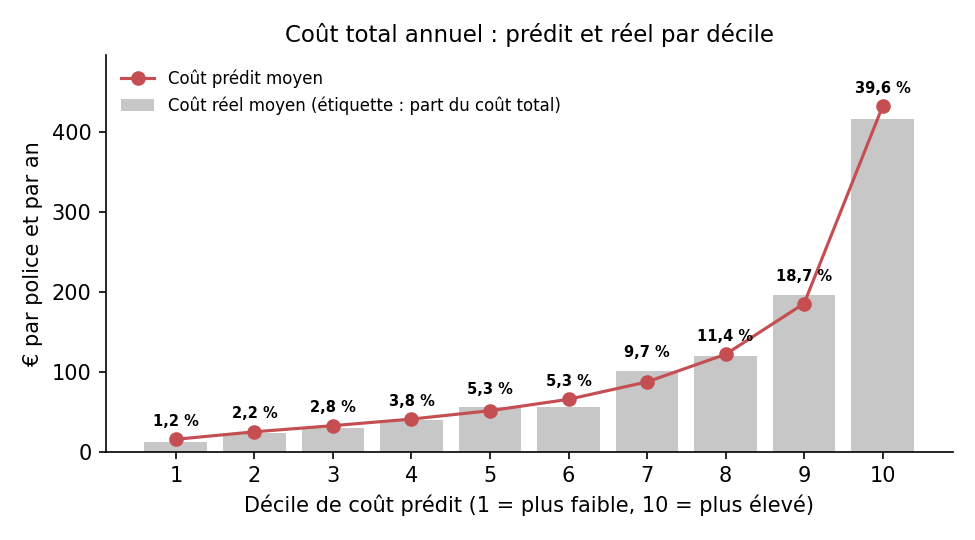

**Figure : importance variables**

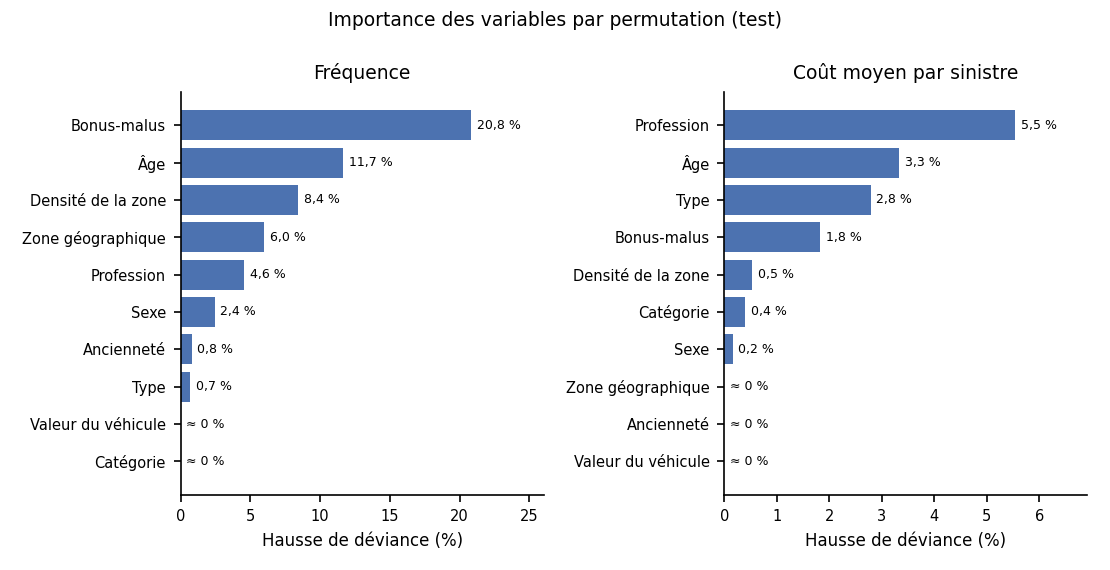

**Découpage apprentissage / test** — 4 lignes × 3 colonnes

,jeu,effectif,sinistres
0,Polices apprentissage,79996,11776
1,Polices test,19999,2972
2,"Lignes de sinistres à coût positif, apprentissage",9786,11756
3,"Lignes de sinistres à coût positif, test",2470,2968


**Modèles de fréquence (déviance de Poisson)** — 4 lignes × 7 colonnes

,modele,deviance_cv,ecart_type_cv,deviance_apprentissage,deviance_test,surapprentissage_pct,ae_test
0,Constante (référence),0.7031,0.00513,0.7031,0.7103,1.028,0.9875
1,GLM Poisson,0.5596,0.005937,0.5582,0.5658,1.363,0.9888
2,Forêt aléatoire,0.5663,0.003044,0.5492,0.5715,4.056,0.9858
3,Gradient boosting Poisson,0.5498,0.005179,0.5112,0.5517,7.905,0.9822


**Modèles de coût (déviance Gamma)** — 4 lignes × 8 colonnes

,modele,deviance_cv,ecart_type_cv,deviance_apprentissage,deviance_test,surapprentissage_pct,mae_test,ae_test
0,Constante (référence),1.043,0.03834,1.042,0.9741,-6.525,485.7,1.023
1,GLM Gamma,0.9716,0.02441,0.9646,0.9297,-3.626,477.2,1.027
2,Forêt aléatoire,0.9743,0.02606,0.9372,0.9297,-0.7923,474.5,1.028
3,Gradient boosting Gamma,0.9956,0.0275,0.8439,0.9473,12.25,470.5,0.9726


... (8 outputs left out)

**GLM de fréquence : rapports de taux** — 37 lignes × 3 colonnes

,facteur,coefficient,rapport_de_taux
0,Âge (+1 écart-type),-0.4798,0.6189
1,Bonus-malus (+1 écart-type),0.4857,1.625
2,Ancienneté (+1 écart-type),-0.1155,0.8909
3,Valeur du véhicule (+1 écart-type),0.001568,1.002
4,Densité de la zone (+1 écart-type),0.3313,1.393
5,Sexe = Male,0.3163,1.372
6,Type = B,0.04405,1.045
7,Type = C,0.1214,1.129
8,Type = D,0.2477,1.281
9,Type = E,0.3351,1.398


#### Points clés
- Fréquence : le modèle retenu est **Gradient boosting Poisson**. Sa déviance de test est 0,552, contre 0,710 pour la référence (**gain 22,3 %**). Son surapprentissage est de 7,9 %.
- Coût : le modèle retenu est **GLM Gamma**. Son gain n'est que de 4,6 % : le montant d'un sinistre est beaucoup plus difficile à prévoir que leur nombre.
- Calibrage : prédit / observé = **1,008** sur le test (idéal = 1).
- Segmentation : les 10 % de polices jugées les plus risquées représentent **39,6 %** du coût réel ; le coût réel moyen passe de 12 € (décile 1) à 416 € (décile 10).
- Variables les plus utiles pour la fréquence : Bonus-malus, Âge, Densité de la zone.

#### Interprétation
- Fréquence : gain de déviance de 22,3 % mesuré sur des données que le modèle n'a jamais vues : il a appris une vraie structure, pas du bruit. En assurance auto, la sinistralité individuelle reste très aléatoire, donc un gain de cet ordre est déjà solide.
- Surapprentissage 7,9 % (< 10 %) : les performances sont proches entre apprentissage et test, le modèle **généralise** bien.
- Prédit / observé = 1,008 : écart inférieur à 3 %, le niveau global des primes est juste.
- Coût : gain de 4,6 % seulement. Les caractéristiques de l'assuré expliquent peu le **montant** d'un sinistre, qui dépend surtout des circonstances de l'accident. La segmentation du tarif reposera donc surtout sur la **fréquence**.
- Le décile le plus risqué coûte 33 fois plus que le moins risqué : le modèle **classe** très bien les polices.
- Le gradient boosting est le plus précis, mais un GLM reste plus lisible et plus facile à justifier (régulateur, réseau commercial). C'est pourquoi le tarif de l'étape 9 est un GLM ; le boosting sert de référence de performance.

In [26]:
res["etape7"] = lancer("Étape 7", lambda: etape7(res["etape3"]), "etape7")  # modèles prédictifs
e7 = res["etape7"]  # raccourci

afficher(e7["split"], "Découpage apprentissage / test")  # taille des échantillons
afficher(e7["res_f"], "Modèles de fréquence (déviance de Poisson)")  # comparaison des modèles de fréquence
afficher(e7["res_s"], "Modèles de coût (déviance Gamma)")  # comparaison des modèles de coût
afficher(e7["total"], "Coût total : modèle retenu contre référence")  # performance de la prime pure
afficher(e7["deciles"], "Coût prédit et réel par décile de risque")  # pouvoir de segmentation
afficher(e7["imp_f"], "Importance des variables : fréquence")  # variables les plus utiles (fréquence)
afficher(e7["imp_s"], "Importance des variables : coût")  # variables les plus utiles (coût)
afficher(e7["glm_rr"], "GLM de fréquence : rapports de taux", 15)  # effet de chaque facteur

rf = e7["res_f"].set_index("modele")  # résultats fréquence indexés
dec = e7["deciles"]  # tableau des déciles
tot = e7["total"]  # comparaison des approches
points_cles(  # constats chiffrés
    f"Fréquence : le modèle retenu est **{e7['best_f']}**. Sa déviance de test est {rf.loc[e7['best_f'], 'deviance_test']:.3f}, "
    f"contre {rf.loc['Constante (référence)', 'deviance_test']:.3f} pour la référence (**gain {e7['gain_f']:.1f} %**). "
    f"Son surapprentissage est de {rf.loc[e7['best_f'], 'surapprentissage_pct']:.1f} %.",
    f"Coût : le modèle retenu est **{e7['best_s']}**. Son gain n'est que de {e7['gain_s']:.1f} % : le montant d'un sinistre "
    "est beaucoup plus difficile à prévoir que leur nombre.",
    f"Calibrage : prédit / observé = **{tot.loc[0, 'ae_total']:.3f}** sur le test (idéal = 1).",
    f"Segmentation : les 10 % de polices jugées les plus risquées représentent **{tot.loc[0, 'part_cout_top10']:.1f} %** du coût réel ; "
    f"le coût réel moyen passe de {nb_fr(dec.iloc[0]['cout_reel_moyen'])} € (décile 1) à {nb_fr(dec.iloc[-1]['cout_reel_moyen'])} € (décile 10).",
    f"Variables les plus utiles pour la fréquence : {', '.join(e7['imp_f']['libelle'].head(3))}.",
)

sur = rf.loc[e7["best_f"], "surapprentissage_pct"]  # surapprentissage du modèle retenu
ae = tot.loc[0, "ae_total"]  # rapport prédit / observé
interpretation(  # lecture des modèles
    verdict(e7["gain_f"] >= 10, f"Fréquence : gain de déviance de {e7['gain_f']:.1f} % mesuré sur des données que le modèle "
            "n'a jamais vues : il a appris une vraie structure, pas du bruit. En assurance auto, la sinistralité individuelle "
            "reste très aléatoire, donc un gain de cet ordre est déjà solide.",
            f"Gain de déviance faible ({e7['gain_f']:.1f} %) : le modèle prévoit à peine mieux que la moyenne."),
    verdict(sur < 10, f"Surapprentissage {sur:.1f} % (< 10 %) : les performances sont proches entre apprentissage et test, "
            "le modèle **généralise** bien.",
            f"Surapprentissage {sur:.1f} % : le modèle colle trop aux données d'apprentissage ; il faut le régulariser."),
    verdict(abs(ae - 1) < 0.03, f"Prédit / observé = {ae:.3f} : écart inférieur à 3 %, le niveau global des primes est juste.",
            f"Prédit / observé = {ae:.3f} : le niveau global est biaisé, un recalage est nécessaire."),
    verdict(e7["gain_s"] >= 10, "Le coût moyen est lui aussi bien expliqué par les variables.",
            f"Coût : gain de {e7['gain_s']:.1f} % seulement. Les caractéristiques de l'assuré expliquent peu le **montant** d'un "
            "sinistre, qui dépend surtout des circonstances de l'accident. La segmentation du tarif reposera donc surtout sur la **fréquence**."),
    f"Le décile le plus risqué coûte {dec.iloc[-1]['cout_reel_moyen'] / dec.iloc[0]['cout_reel_moyen']:.0f} fois plus que le "
    "moins risqué : le modèle **classe** très bien les polices.",
    "Le gradient boosting est le plus précis, mais un GLM reste plus lisible et plus facile à justifier "
    "(régulateur, réseau commercial). C'est pourquoi le tarif de l'étape 9 est un GLM ; le boosting sert de référence de performance."
    if "GLM" not in e7["best_f"] else "Le GLM est à la fois le plus performant et le plus lisible : il peut servir directement de tarif.",
)

#### Graphique : comparaison des modèles en validation croisée
Déviance moyenne en validation croisée (plus elle est basse, meilleur est le modèle), avec plus ou moins un écart-type entre les plis. Si deux intervalles se chevauchent largement, la différence entre les modèles n'est pas fiable.

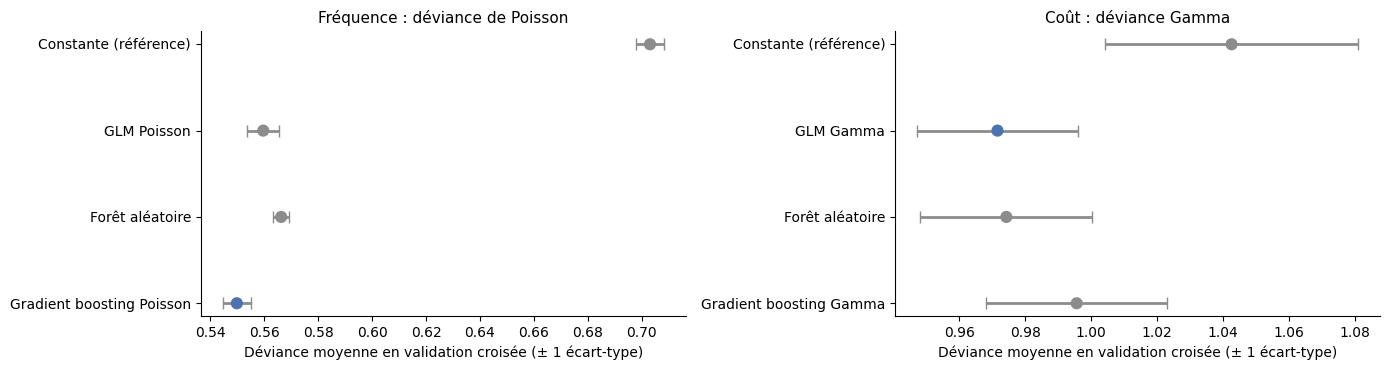

#### Points clés
- Fréquence : le GLM fait mieux que la référence de **30 écarts-types**, et le Gradient boosting Poisson fait mieux que le GLM de 2,0 écart-type.
- Coût : le GLM Gamma fait mieux que la référence de 2,4 écarts-types.

#### Interprétation
- Pour la fréquence, le vrai saut de performance est le passage de la constante au GLM (30 écarts-types). Le gain supplémentaire du modèle le plus complexe est réel mais modeste (2,0 écarts-types). Le GLM conserve donc l'essentiel de la performance (94 % du gain total) tout en restant lisible : c'est le prix, faible, de l'explicabilité.
- Pour le coût, le GLM, la forêt et le boosting sont au même niveau, avec des intervalles qui se chevauchent largement, et ne font que modestement mieux que la référence (2,4 écarts-types). Cela confirme que le montant d'un sinistre est surtout aléatoire et que les variables disponibles l'expliquent mal.

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))  # fréquence et coût côte à côte (échelles différentes)
for ax, t, titre, meilleur in [(axes[0], e7["res_f"], "Fréquence : déviance de Poisson", e7["best_f"]),
                               (axes[1], e7["res_s"], "Coût : déviance Gamma", e7["best_s"])]:
    t = t.iloc[::-1].reset_index(drop=True)  # référence en bas
    pos = np.arange(len(t))  # une ligne par modèle
    ax.errorbar(t["deviance_cv"], pos, xerr=t["ecart_type_cv"], fmt="none", ecolor=GRIS, elinewidth=2, capsize=4)
    ax.scatter(t["deviance_cv"], pos, s=60, zorder=3, color=[BLEU if m == meilleur else GRIS for m in t["modele"]])
    ax.set_yticks(pos, t["modele"])  # noms des modèles
    ax.set_xlabel("Déviance moyenne en validation croisée (± 1 écart-type)")  # axe horizontal
    ax.set_title(titre)  # titre
plt.tight_layout()  # ajuste les marges
montrer_fig("comparaison_modeles")  # affiche et enregistre la figure

rff, rss = e7["res_f"].set_index("modele"), e7["res_s"].set_index("modele")  # résultats indexés
et_f = rff["ecart_type_cv"].mean()  # écart-type typique entre plis (fréquence)
et_s = rss["ecart_type_cv"].mean()  # écart-type typique entre plis (coût)
gap_glm = (rff.loc["GLM Poisson", "deviance_cv"] - rff.loc[e7["best_f"], "deviance_cv"]) / et_f  # GLM vs meilleur
gap_ref_f = (rff.loc["Constante (référence)", "deviance_cv"] - rff.loc["GLM Poisson", "deviance_cv"]) / et_f  # référence vs GLM
gap_ref_s = (rss.loc["Constante (référence)", "deviance_cv"] - rss.loc["GLM Gamma", "deviance_cv"]) / et_s  # référence vs GLM
points_cles(
    f"Fréquence : le GLM fait mieux que la référence de **{gap_ref_f:.0f} écarts-types**, et le {e7['best_f']} fait "
    f"mieux que le GLM de {gap_glm:.1f} écart-type.",
    f"Coût : le GLM Gamma fait mieux que la référence de {gap_ref_s:.1f} écarts-types.",
)
interpretation(
    f"Pour la fréquence, le vrai saut de performance est le passage de la constante au GLM ({gap_ref_f:.0f} écarts-types). "
    "Le gain supplémentaire du modèle le plus complexe est "
    + ("plus petit que la variabilité entre plis : il n'est pas significatif." if gap_glm < 1
       else f"réel mais modeste ({gap_glm:.1f} écarts-types)." if gap_glm < 3
       else f"net ({gap_glm:.1f} écarts-types).")
    + f" Le GLM conserve donc l'essentiel de la performance ({100 * gap_ref_f / (gap_ref_f + gap_glm):.0f} % du gain total) "
    "tout en restant lisible : c'est le prix, faible, de l'explicabilité.",
    f"Pour le coût, le GLM, la forêt et le boosting sont au même niveau, avec des intervalles qui se chevauchent largement, "
    f"et ne font que modestement mieux que la référence ({gap_ref_s:.1f} écarts-types). Cela confirme que le montant d'un "
    "sinistre est surtout aléatoire et que les variables disponibles l'expliquent mal.",
)
pour_rapport("comparaison_modeles", "Étape 7 : comparaison des modèles en validation croisée",
             "Déviance moyenne en validation croisée et écart-type entre plis, pour les modèles de fréquence et de coût.")

### Étape 7 bis — Visualisations avancées

**Objectif.** Utiliser les graphiques pour **comprendre** les relations entre variables et vérifier la qualité du modèle, pas seulement pour décrire.

| Graphique | Question à laquelle il répond |
|---|---|
| Carte de chaleur âge × bonus | Les deux effets s'additionnent-ils, ou interagissent-ils ? |
| Calibrage par vingtile | Les fréquences prédites correspondent-elles aux fréquences observées, pour les bons comme pour les mauvais risques ? |
| Courbe de Lorenz et indice de Gini | Le modèle classe-t-il bien les risques ? (Gini 0 = classement au hasard) |
| Effets partiels | Quelle est la forme de l'effet de chaque variable (linéaire, seuil, plateau) ? |

#### Interaction âge × bonus-malus

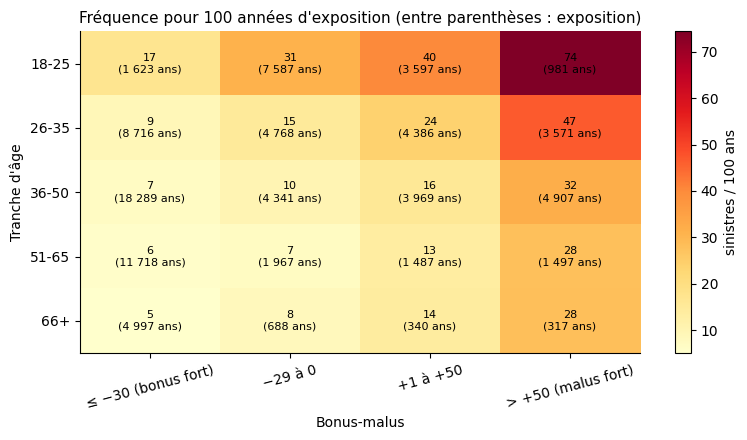

#### Points clés
- Les deux effets se cumulent : un 18-25 ans à fort malus a **74** sinistres pour 100 ans, contre **6** pour un 51-65 ans à fort bonus (×13).
- Même parmi les conducteurs à fort bonus, les 18-25 ans restent 2,5 fois plus risqués que les 36-50 ans : l'âge apporte une information que le bonus ne capte pas encore (peu d'historique).
- Les cases à faible exposition (nombre entre parenthèses) sont moins fiables et ne doivent pas être sur-interprétées.

#### Interprétation
- Si l'âge et le bonus portaient la même information, l'effet de l'âge disparaîtrait à bonus égal. Ce n'est pas le cas : les deux variables doivent figurer **ensemble** dans le tarif.
- L'effet de l'âge (18-25 contre 36-50) est similaire quel que soit le bonus (×2,5 avec fort bonus, ×2,3 avec fort malus) : l'hypothèse **multiplicative** du GLM (effets qui se multiplient sans interaction) est raisonnable.
- 2 case(s) ont moins de 500 années d'exposition : leur fréquence est imprécise (quelques sinistres de plus ou de moins la font beaucoup varier).

In [28]:
b = base.copy()  # copie de la base des polices
b["bande_bonus"] = pd.cut(b["Bonus"], [-51, -30, 0, 50, 150],  # découpe du bonus-malus en 4 bandes
                          labels=["≤ −30 (bonus fort)", "−29 à 0", "+1 à +50", "> +50 (malus fort)"])
nb_s = b.pivot_table(index="tranche_age", columns="bande_bonus", values="nb_sinistres", aggfunc="sum", observed=False)  # sinistres
expo = b.pivot_table(index="tranche_age", columns="bande_bonus", values="expo_annees", aggfunc="sum", observed=False)  # exposition
freq = (100 * nb_s / expo).reindex(BANDES_AGE)  # fréquence pour 100 années d'exposition, âges dans l'ordre

fig, ax = plt.subplots(figsize=(8, 4.5))  # zone de dessin
im = ax.imshow(freq.values, cmap="YlOrRd", aspect="auto")  # carte de chaleur : plus c'est rouge, plus c'est risqué
ax.set_xticks(range(freq.shape[1]), freq.columns, rotation=15)  # étiquettes des bandes de bonus
ax.set_yticks(range(freq.shape[0]), freq.index)  # étiquettes des tranches d'âge
for i in range(freq.shape[0]):  # pour chaque tranche d'âge
    for j in range(freq.shape[1]):  # pour chaque bande de bonus
        v, e = freq.iat[i, j], expo.reindex(BANDES_AGE).iat[i, j]  # fréquence et exposition de la case
        if pd.notna(v):  # case non vide
            ax.text(j, i, f"{v:.0f}\n({e:,.0f} ans)".replace(",", " "), ha="center", va="center", fontsize=8)  # valeur
ax.set_xlabel("Bonus-malus")  # titre de l'axe horizontal
ax.set_ylabel("Tranche d'âge")  # titre de l'axe vertical
ax.set_title("Fréquence pour 100 années d'exposition (entre parenthèses : exposition)")  # titre
fig.colorbar(im, ax=ax, label="sinistres / 100 ans")  # échelle de couleurs
plt.tight_layout()  # ajuste les marges
montrer_fig("interaction_age_bonus")  # affiche et enregistre la figure

f_jeune_malus = freq.loc["18-25"].iloc[-1]  # jeunes à fort malus
f_senior_bonus = freq.loc["51-65"].iloc[0]  # 51-65 ans à fort bonus
ratio_age_bonus = freq.iloc[:, 0] / freq.iloc[:, 0].loc["36-50"]  # effet de l'âge parmi les bons conducteurs
points_cles(  # constats chiffrés
    f"Les deux effets se cumulent : un 18-25 ans à fort malus a **{f_jeune_malus:.0f}** sinistres pour 100 ans, "
    f"contre **{f_senior_bonus:.0f}** pour un 51-65 ans à fort bonus (×{f_jeune_malus / f_senior_bonus:.0f}).",
    f"Même parmi les conducteurs à fort bonus, les 18-25 ans restent {ratio_age_bonus.loc['18-25']:.1f} fois plus risqués "
    "que les 36-50 ans : l'âge apporte une information que le bonus ne capte pas encore (peu d'historique).",
    "Les cases à faible exposition (nombre entre parenthèses) sont moins fiables et ne doivent pas être sur-interprétées.",
)

effet_age_bonus = freq.loc["18-25"].iloc[0] / freq.loc["36-50"].iloc[0]  # effet de l'âge parmi les forts bonus
effet_age_malus = freq.loc["18-25"].iloc[-1] / freq.loc["36-50"].iloc[-1]  # effet de l'âge parmi les forts malus
peu_exposees = int((expo.reindex(BANDES_AGE) < 500).sum().sum())  # cases avec moins de 500 années d'exposition
proche = 0.7 < effet_age_malus / effet_age_bonus < 1.4  # l'effet de l'âge est-il stable selon le bonus ?
interpretation(  # lecture de l'interaction
    "Si l'âge et le bonus portaient la même information, l'effet de l'âge disparaîtrait à bonus égal. "
    "Ce n'est pas le cas : les deux variables doivent figurer **ensemble** dans le tarif.",
    verdict(proche, f"L'effet de l'âge (18-25 contre 36-50) est similaire quel que soit le bonus (×{effet_age_bonus:.1f} "
            f"avec fort bonus, ×{effet_age_malus:.1f} avec fort malus) : l'hypothèse **multiplicative** du GLM (effets qui se "
            "multiplient sans interaction) est raisonnable.",
            f"L'effet de l'âge change selon le bonus (×{effet_age_bonus:.1f} avec fort bonus, ×{effet_age_malus:.1f} avec fort "
            "malus) : ajouter une **interaction âge × bonus** au GLM pourrait améliorer le tarif."),
    verdict(peu_exposees == 0, "Toutes les cases ont une exposition suffisante.",
            f"{peu_exposees} case(s) ont moins de 500 années d'exposition : leur fréquence est imprécise "
            "(quelques sinistres de plus ou de moins la font beaucoup varier)."),
)
pour_rapport("interaction_age_bonus", "Étape 7 bis : interaction âge × bonus-malus",
             "Fréquence pour 100 années d'exposition par tranche d'âge et bande de bonus-malus.")

#### Calibrage et pouvoir de classement du modèle de fréquence (échantillon test)

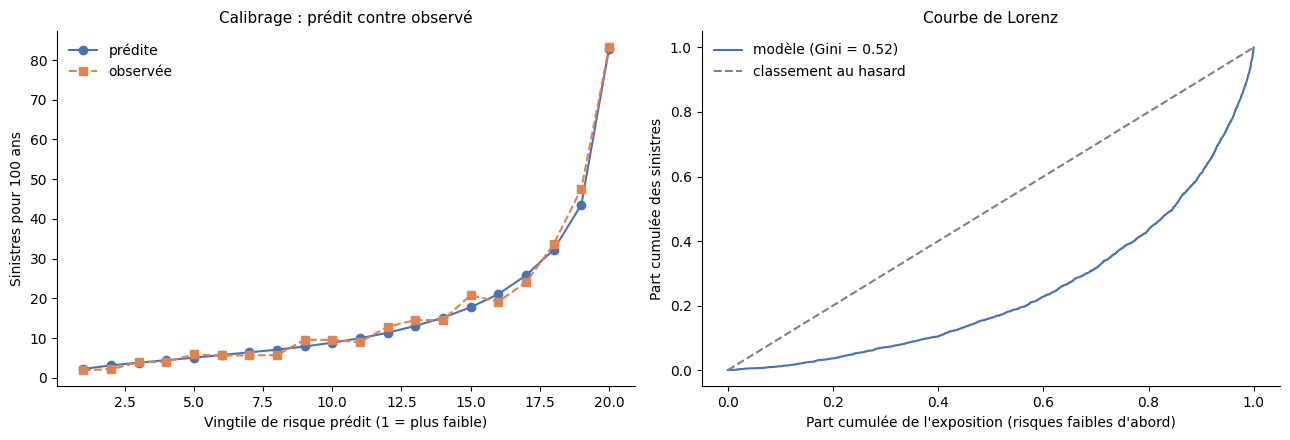

#### Points clés
- La fréquence observée passe de 1,9 (vingtile 1) à 83,2 (vingtile 20) sinistres pour 100 ans : le modèle sépare les risques d'un facteur ×43.
- Les courbes prédite et observée se suivent : écart médian de 10 % par groupe, au plus 32 %. Le modèle est bien calibré sur toute l'échelle de risque.
- Indice de Gini = **0,52** : les 50 % de l'exposition jugés les moins risqués ne portent que 16 % des sinistres.

#### Interprétation
- **Gini** : 0 = classement au hasard, 1 = classement parfait. À 0,52, le modèle classe nettement mieux que le hasard.
- Écart médian de 10 % : le modèle est calibré **groupe par groupe**, pas seulement en moyenne. Aucune classe de risque n'est systématiquement sur- ou sous-tarifée.
- Le plus grand écart (32 %) est au vingtile 2 : c'est un groupe de risques faibles, avec très peu de sinistres, donc une fréquence observée plus bruitée.
- Calibrage et classement sont deux qualités différentes : un modèle peut bien classer mais donner des primes toutes trop basses, ou l'inverse. Ici, les deux sont vérifiés.

In [29]:
te = e7["te"]  # polices de l'échantillon test
taux_pred = e7["modele_frequence"].predict(e7["X_te"])  # fréquence annuelle prédite par le modèle retenu
expo_te = te["expo"].to_numpy()  # exposition de chaque police
nb_obs = te["nb"].to_numpy()  # sinistres observés
nb_att = taux_pred * expo_te  # sinistres attendus = fréquence × exposition

ordre = np.argsort(taux_pred)  # polices triées du risque le plus faible au plus élevé
groupe = np.empty(len(ordre), dtype=int)  # numéro de vingtile de chaque police
groupe[ordre] = np.arange(len(ordre)) * 20 // len(ordre)  # 20 groupes de même effectif
cal = pd.DataFrame({"g": groupe, "obs": nb_obs, "att": nb_att, "expo": expo_te}).groupby("g").sum()  # totaux par groupe
cal["freq_obs"] = 100 * cal["obs"] / cal["expo"]  # fréquence observée pour 100 ans
cal["freq_pred"] = 100 * cal["att"] / cal["expo"]  # fréquence prédite pour 100 ans

cum_expo = np.concatenate([[0], np.cumsum(expo_te[ordre]) / expo_te.sum()])  # part cumulée de l'exposition
cum_sin = np.concatenate([[0], np.cumsum(nb_obs[ordre]) / nb_obs.sum()])  # part cumulée des sinistres
gini = 1 - 2 * np.trapz(cum_sin, cum_expo)  # indice de Gini = 1 − 2 × aire sous la courbe de Lorenz

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))  # deux graphiques côte à côte
ax1.plot(cal.index + 1, cal["freq_pred"], "o-", label="prédite", color="#4C72B0")  # fréquence prédite
ax1.plot(cal.index + 1, cal["freq_obs"], "s--", label="observée", color="#DD8452")  # fréquence observée
ax1.set_xlabel("Vingtile de risque prédit (1 = plus faible)")  # axe horizontal
ax1.set_ylabel("Sinistres pour 100 ans")  # axe vertical
ax1.set_title("Calibrage : prédit contre observé")  # titre
ax1.legend()  # légende
ax2.plot(cum_expo, cum_sin, color="#4C72B0", label=f"modèle (Gini = {gini:.2f})")  # courbe de Lorenz
ax2.plot([0, 1], [0, 1], "--", color="grey", label="classement au hasard")  # diagonale de référence
ax2.set_xlabel("Part cumulée de l'exposition (risques faibles d'abord)")  # axe horizontal
ax2.set_ylabel("Part cumulée des sinistres")  # axe vertical
ax2.set_title("Courbe de Lorenz")  # titre
ax2.legend()  # légende
plt.tight_layout()  # ajuste les marges
montrer_fig("calibrage_lorenz")  # affiche et enregistre la figure

ecart = (cal["freq_obs"] / cal["freq_pred"] - 1).abs()  # écart relatif observé / prédit par groupe
points_cles(  # constats chiffrés
    f"La fréquence observée passe de {cal['freq_obs'].iloc[0]:.1f} (vingtile 1) à {cal['freq_obs'].iloc[-1]:.1f} "
    f"(vingtile 20) sinistres pour 100 ans : le modèle sépare les risques d'un facteur ×{cal['freq_obs'].iloc[-1] / cal['freq_obs'].iloc[0]:.0f}.",
    f"Les courbes prédite et observée se suivent : écart médian de {100 * ecart.median():.0f} % par groupe, "
    f"au plus {100 * ecart.max():.0f} %. Le modèle est bien calibré sur toute l'échelle de risque.",
    f"Indice de Gini = **{gini:.2f}** : les 50 % de l'exposition jugés les moins risqués ne portent que "
    f"{100 * np.interp(0.5, cum_expo, cum_sin):.0f} % des sinistres.",
)

pire = int(ecart.idxmax()) + 1  # vingtile le moins bien calibré
interpretation(  # lecture du calibrage et du Gini
    f"**Gini** : 0 = classement au hasard, 1 = classement parfait. "
    + verdict(gini >= 0.3, f"À {gini:.2f}, le modèle classe nettement mieux que le hasard.",
              f"À {gini:.2f}, le pouvoir de classement reste limité."),
    verdict(ecart.median() < 0.15, f"Écart médian de {100 * ecart.median():.0f} % : le modèle est calibré **groupe par groupe**, "
            "pas seulement en moyenne. Aucune classe de risque n'est systématiquement sur- ou sous-tarifée.",
            f"Écart médian de {100 * ecart.median():.0f} % : certains groupes sont mal tarifés."),
    f"Le plus grand écart ({100 * ecart.max():.0f} %) est au vingtile {pire}"
    + (" : c'est un groupe de risques faibles, avec très peu de sinistres, donc une fréquence observée plus bruitée."
       if pire in (1, 2) else " : c'est le groupe le plus risqué, où quelques polices extrêmes pèsent beaucoup."
       if pire in (19, 20) else " : à surveiller, car ce n'est pas un groupe extrême."),
    "Calibrage et classement sont deux qualités différentes : un modèle peut bien classer mais donner des primes toutes "
    "trop basses, ou l'inverse. Ici, les deux sont vérifiés.",
)
pour_rapport("calibrage_lorenz", "Étape 7 bis : calibrage et courbe de Lorenz",
             "Fréquence prédite et observée par vingtile de risque, et courbe de Lorenz du modèle de fréquence.")

#### Effets partiels des variables numériques
Chaque courbe montre la fréquence moyenne prédite quand on fait varier **une seule** variable en gardant les autres à leurs valeurs réelles (*partial dependence*). Cela révèle la forme de l'effet, qu'un GLM linéaire imposerait sinon.

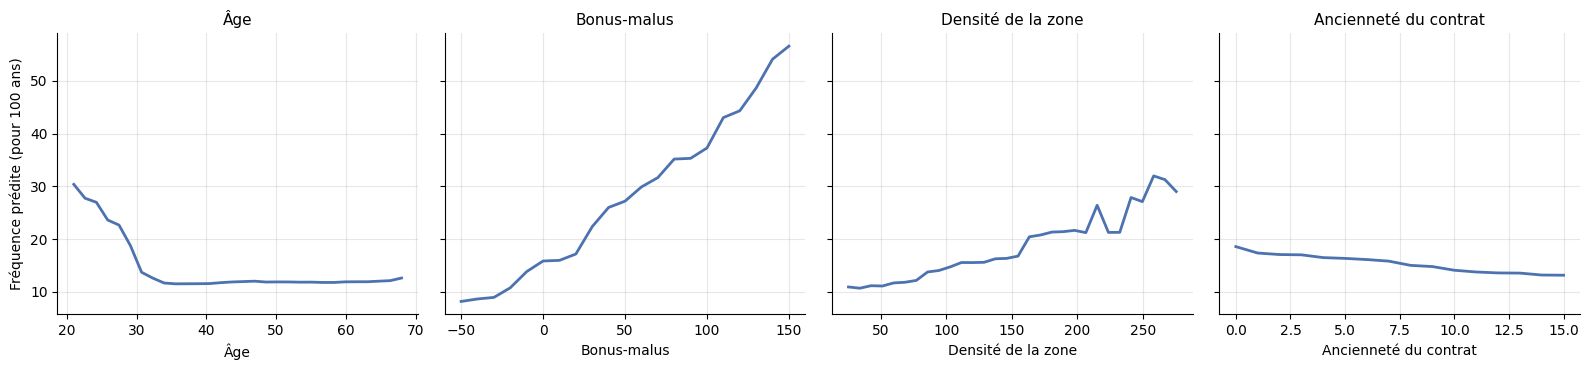

#### Points clés
- Amplitude de l'effet (fréquence max / min sur la plage observée) : Bonus-malus ×6,9, Densité de la zone ×3,0, Âge ×2,6, Ancienneté du contrat ×1,4.
- Âge : fréquence prédite de 30,4 à 21 ans, 11,5 à 40 ans et 12,6 à 68 ans. L'effet n'est pas linéaire, d'où le découpage en tranches dans le tarif de l'étape 9.
- Bonus-malus : de 8,2 (bonus -50) à 56,6 (malus +150) sinistres pour 100 ans. Le bonus résume bien l'historique de sinistres du conducteur.

#### Interprétation
- **Bonus-malus** a l'effet le plus fort (×6,9), **Ancienneté du contrat** le plus faible (×1,4). Le bonus-malus arrive aussi en tête des importances de variables de l'étape 7 : les deux méthodes concordent.
- La courbe de l'âge est **en U** : minimum vers 36 ans, puis légère remontée. Jeunes et seniors sont plus risqués : une relation linéaire serait fausse, d'où les tranches d'âge dans le tarif.
- Un effet partiel fait varier une variable **seule**, alors qu'en réalité l'âge et le bonus évoluent ensemble. Les extrémités des courbes reposent sur peu de polices et sont moins fiables.

In [30]:
from sklearn.inspection import partial_dependence  # calcul des effets partiels

echantillon = e7["X_te"].sample(3000, random_state=0)  # 3 000 polices pour un calcul rapide
VAR_PD = {"Age": "Âge", "Bonus": "Bonus-malus", "Density": "Densité de la zone", "Poldur": "Ancienneté du contrat"}  # libellés
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)  # 4 graphiques, même échelle verticale
effets, courbes = {}, {}  # amplitude et courbe de chaque effet
for ax, (v, lib) in zip(axes, VAR_PD.items()):  # une variable par graphique
    pdp = partial_dependence(e7["modele_frequence"], echantillon, [v], grid_resolution=30)  # effet partiel
    x, y = pdp["grid_values"][0], 100 * pdp["average"][0]  # grille de valeurs et fréquence pour 100 ans
    effets[lib] = y.max() / y.min()  # rapport entre l'effet maximal et minimal
    courbes[v] = pd.Series(y, index=x)  # courbe gardée pour les constats
    ax.plot(x, y, color="#4C72B0", lw=2)  # courbe de l'effet
    ax.set_title(lib)  # titre
    ax.set_xlabel(lib)  # axe horizontal
    ax.grid(alpha=0.3)  # grille légère
axes[0].set_ylabel("Fréquence prédite (pour 100 ans)")  # axe vertical commun
plt.tight_layout()  # ajuste les marges
montrer_fig("effets_partiels")  # affiche et enregistre la figure

effets = pd.Series(effets).sort_values(ascending=False)  # variables triées par amplitude
age_c, bon_c = courbes["Age"], courbes["Bonus"]  # courbes de l'âge et du bonus
points_cles(  # constats chiffrés
    "Amplitude de l'effet (fréquence max / min sur la plage observée) : "
    + ", ".join(f"{k} ×{v:.1f}" for k, v in effets.items()) + ".",
    f"Âge : fréquence prédite de {age_c.iloc[0]:.1f} à {age_c.index[0]:.0f} ans, {age_c.asof(40):.1f} à 40 ans et "
    f"{age_c.iloc[-1]:.1f} à {age_c.index[-1]:.0f} ans. L'effet n'est pas linéaire, d'où le découpage en tranches "
    "dans le tarif de l'étape 9.",
    f"Bonus-malus : de {bon_c.iloc[0]:.1f} (bonus {bon_c.index[0]:.0f}) à {bon_c.iloc[-1]:.1f} (malus +{bon_c.index[-1]:.0f}) "
    "sinistres pour 100 ans. Le bonus résume bien l'historique de sinistres du conducteur.",
)

age_min = age_c.idxmin()  # âge où la fréquence prédite est la plus basse
remonte = age_c.iloc[-1] > 1.05 * age_c.min()  # la courbe remonte-t-elle chez les seniors ?
interpretation(  # lecture des effets partiels
    f"**{effets.index[0]}** a l'effet le plus fort (×{effets.iloc[0]:.1f}), **{effets.index[-1]}** le plus faible "
    f"(×{effets.iloc[-1]:.1f}). "
    + (f"Le {effets.index[0].lower()} arrive aussi en tête des importances de variables de l'étape 7 : les deux méthodes concordent."
       if effets.index[0] == e7["imp_f"]["libelle"].iloc[0]
       else f"Les importances de l'étape 7 placent plutôt {e7['imp_f']['libelle'].iloc[0]} en tête : les deux mesures ne disent pas la même chose (amplitude contre contribution à la prédiction)."),
    (f"La courbe de l'âge est **en U** : minimum vers {age_min:.0f} ans, puis légère remontée. Jeunes et seniors sont "
     "plus risqués : une relation linéaire serait fausse, d'où les tranches d'âge dans le tarif."
     if remonte else f"La fréquence baisse avec l'âge jusqu'à {age_min:.0f} ans environ, puis se stabilise."),
    "Un effet partiel fait varier une variable **seule**, alors qu'en réalité l'âge et le bonus évoluent ensemble. "
    "Les extrémités des courbes reposent sur peu de polices et sont moins fiables.",
)
pour_rapport("effets_partiels", "Étape 7 bis : effets partiels des variables numériques",
             "Fréquence moyenne prédite quand une seule variable varie (effets partiels).")

### Étape 8 — Interprétation actuarielle

**Objectif.** Traduire les résultats en constats utiles pour la tarification et la réassurance.

**Méthode.**
- *Concentration des coûts* : quelle part du coût total vient des 1 %, 5 %, 10 % et 20 % de sinistres les plus chers ;
- *Polices atypiques* : polices de l'échantillon test ayant **au moins 2 sinistres** alors que, selon le modèle de fréquence, la probabilité d'en avoir autant est **inférieure à 0,1 %** (queue de la loi de Poisson).

**Comment lire.** Une forte concentration justifie un écrêtement des gros sinistres pour la tarification, ou une couverture de réassurance en excédent de sinistre.

#### Code : concentration des coûts et polices atypiques

Définition des fonctions de l'étape. Le résultat de leur exécution s'affiche dans la cellule suivante.

In [31]:
# ===========================================================================
# ÉTAPE 8 – INTERPRÉTATION ACTUARIELLE ET RECOMMANDATIONS
# ===========================================================================


def etape8(res: dict) -> dict:
    e3, e7 = res["etape3"], res["etape7"]
    sin = e3["sin"]
    figures = {}

    # Concentration du coût : une ligne de sinistre regroupe nb_sin sinistres, coût par sinistre = chg_sin / nb_sin
    s = sin.loc[(sin["chg_sin"].astype(float) > 0) & (sin["nb_sin"].astype(float) > 0),
                ["chg_sin", "nb_sin"]].astype(float)
    cout_par_sin = np.repeat(s["chg_sin"].to_numpy() / s["nb_sin"].to_numpy(), s["nb_sin"].astype(int).to_numpy())
    cout_par_sin = np.sort(cout_par_sin)[::-1]
    total = cout_par_sin.sum()
    lignes_c = []
    for p in [0.01, 0.05, 0.10, 0.20]:
        k = max(1, int(round(p * len(cout_par_sin))))
        lignes_c.append({"part_des_sinistres_pct": 100 * p, "part_du_cout_pct": 100 * cout_par_sin[:k].sum() / total})
    conc = pd.DataFrame(lignes_c)
    conc.to_csv(SORTIE / "etape8_concentration_couts.csv", index=False, sep=";", decimal=",")

    cumul = np.cumsum(cout_par_sin) / total
    fig, ax = plt.subplots(figsize=(6.2, 3.6))
    ax.plot(100 * np.arange(1, len(cumul) + 1) / len(cumul), 100 * cumul, color="#4C72B0")
    ax.plot([0, 100], [0, 100], "--", color="grey", lw=0.8)
    ax.set_xlabel("Part des sinistres (les plus coûteux d'abord, %)"); ax.set_ylabel("Part du coût total (%)")
    ax.set_title("Concentration du coût des sinistres (courbe de Lorenz)")
    figures["concentration"] = _sauver_fig(fig, "fig_concentration_couts")

    # Polices atypiques : sinistralité observée très supérieure à la prévision du modèle (jeu de test)
    te = e7["te"]
    mu = e7["modele_frequence"].predict(e7["X_te"]) * te["expo"].to_numpy()
    nb = te["nb"].to_numpy()
    cout = te["cout"].to_numpy()
    p_queue = sstats.poisson.sf(nb - 1, mu)  # P(X >= nb) sous le modèle de Poisson
    atyp = (nb >= 2) & (p_queue < 0.001)
    liste = te.loc[atyp, ["PolNum", "nb", "expo", "cout"]].copy()
    liste["sinistres_attendus"] = mu[atyp]
    liste["probabilite_queue"] = p_queue[atyp]
    liste.sort_values("probabilite_queue").to_csv(SORTIE / "etape8_polices_atypiques.csv", index=False,
                                                  sep=";", decimal=",")
    atyp_synth = {"n_test": len(te), "n_atyp": int(atyp.sum()), "part_polices": 100 * atyp.mean(),
                  "sinistres_observes": float(nb[atyp].sum()), "sinistres_attendus": float(mu[atyp].sum()),
                  "part_sinistres": 100 * nb[atyp].sum() / nb.sum(),
                  "part_cout": 100 * cout[atyp].sum() / cout.sum()}
    pd.DataFrame([atyp_synth]).to_csv(SORTIE / "etape8_atypiques_synthese.csv", index=False, sep=";", decimal=",")

    print(f"Étape 8 : {atyp_synth['n_atyp']} polices atypiques sur {len(te)} polices de test ; "
          f"{conc.loc[0, 'part_du_cout_pct']:.1f} % du coût dans le 1 % des sinistres les plus coûteux")
    return {"conc": conc, "atyp": atyp_synth, "figures": figures}


def section_etape8(res: dict) -> str:
    e5, e6, e7, e8 = res["etape5"], res["etape6"], res["etape7"], res["etape8"]
    f = e8["figures"]
    glm = e5["glm"].set_index("facteur")
    prof = {r["profil"]: r for r in e6["prof"].to_dict("records")}
    faible, moyen, eleve = prof["Faible risque"], prof["Risque intermédiaire"], prof["Risque élevé"]
    t_type = e5["t_type"].set_index("Type")
    t_age = e5["t_age"].set_index("tranche_age")
    t_anc = e5["t_anc"].set_index("tranche_anciennete")
    cible = e5["cible"].set_index("variable")["rho_avec_nb_sinistres"]
    conc = e8["conc"].set_index("part_des_sinistres_pct")["part_du_cout_pct"]
    at = e8["atyp"]
    res_f, res_s, tot = e7["res_f"], e7["res_s"], e7["total"]

    def rr(nom):
        return nombre(float(glm.loc[nom, "rapport_de_taux"]), 2)

    def pct(x, d=1):
        return nombre(x, d) + " \\%"

    rr_double_valeur = float(glm.loc["Valeur du véhicule (par +1 log)", "rapport_de_taux"]) ** np.log(2)
    charge_A = t_type.loc["A", "frequence_pour_100_ans"] * t_type.loc["A", "cout_moyen_par_sinistre"] / 100
    charge_F = t_type.loc["F", "frequence_pour_100_ans"] * t_type.loc["F", "cout_moyen_par_sinistre"] / 100

    lignes_f = [[echapper(r["facteur"]), nombre(r["rapport_de_taux"], 2), nombre(r["ic95_bas"], 2) + " – " + nombre(r["ic95_haut"], 2),
                 "oui" if r["p_valeur"] < 0.05 else "non"]
                for r in e5["glm"].to_dict("records") if r["facteur"] != "Constante"]
    lignes_p = [[echapper(r["profil"]), nombre(r["part_polices"], 1), nombre(r["age"], 1), nombre(r["bonus"], 1),
                 nombre(r["poldur"], 1), nombre(r["frequence_pour_100_ans"], 2), nombre(r["charge_annuelle"], 0)]
                for r in e6["prof"].to_dict("records")]
    lignes_r = [[echapper(v), nombre(x, 3)] for v, x in cible.items()]
    lignes_c = [[nombre(r["part_des_sinistres_pct"], 0) + " \\%", nombre(r["part_du_cout_pct"], 1) + " \\%"]
                for r in e8["conc"].to_dict("records")]
    atyp_txt = nombre(at["n_atyp"])
    refs = ", ".join(echapper(a) + " : " + echapper(b) for a, b in e7["references"])

    def fig(chemin, legende, largeur="0.8"):
        return ("\\begin{figure}[htbp]\\centering\\includegraphics[width=" + largeur + "\\textwidth]{" + chemin + "}\n"
                "\\caption{" + echapper(legende) + "}\\end{figure}\n")

    def tab_petit(*args):
        return "{\\footnotesize\\setlength{\\tabcolsep}{3pt}\n" + tableau(*args) + "}\n"

    return (
        "\n\\part{Étape 8 -- Interprétation actuarielle et recommandations}\n\\section{Objectif}\n"
        "Transformer les résultats statistiques en lecture de risque : quels facteurs comptent, quels profils "
        "sont les plus sinistrés, quelles limites ont les résultats, et comment une compagnie pourrait les utiliser.\n"
        "\\section{Synthèse}\n\\begin{itemize}\n"
        "  \\item \\textbf{Le risque se concentre} : le décile le plus coûteux de polices concentre "
        + pct(float(e7["total"].iloc[0]["part_cout_top10"])) + " du coût réel, contre "
        + pct(float(e7["total"].iloc[1]["part_cout_top10"])) + " pour une tarification uniforme.\n"
        "  \\item \\textbf{La fréquence est expliquée} : bonus-malus, âge et zone géographique sont les facteurs les plus "
        "liés aux sinistres. La déviance de test baisse d'environ " + pct(e7["gain_f"])
        + " par rapport à une prévision uniforme.\n"
        "  \\item \\textbf{Le coût par sinistre est peu prévisible} : les variables disponibles n'expliquent qu'une "
        "faible part de sa dispersion. La tarification du coût moyen devra s'appuyer sur d'autres informations.\n"
        "  \\item \\textbf{Les résultats sont des associations} : ils proviennent d'une seule base, sans prime ni "
        "dates de sinistre. Ils doivent être validés avant tout usage opérationnel.\n"
        "\\end{itemize}\n"
        "\\section{1. Variables qui influencent le risque}\n"
        "Le modèle de Poisson multivarié (étape 5) mesure l'effet de chaque facteur toutes choses égales par ailleurs. "
        "Un rapport de taux de 1,50 signifie 50 % de sinistres en plus. Les facteurs de référence sont : "
        + refs + " ; âge 36-50 ; ancienneté 5-9 ans ; type A.\n"
        + tab_petit("Effet de chaque facteur sur la fréquence (modèle de Poisson multivarié)", "tab:e8_facteurs",
                    ["Facteur", "Rapport de taux", "IC 95 \\%", "Significatif"], lignes_f, "p{6.8cm}rrr")
        + "\\begin{itemize}\n"
        "  \\item \\textbf{Âge} : les 18-25 ans ont une fréquence " + rr("Âge = 18-25") + " fois celle des 36-50 ans. "
        "Après 50 ans, le risque baisse : " + rr("Âge = 66+") + " pour les 66 ans et plus. C'est le facteur le plus marqué "
        "du modèle.\n"
        "  \\item \\textbf{Bonus-malus} : chaque tranche de 10 points supplémentaires multiplie la fréquence par "
        + rr("Bonus-malus (par +10 points)") + ". Voir la mise en garde sur la causalité en section 3.\n"
        "  \\item \\textbf{Type de véhicule} : le type F a une fréquence " + rr("Type = F") + " fois celle du type A, "
        "et le type E " + rr("Type = E") + " fois.\n"
        "  \\item \\textbf{Valeur du véhicule} : doubler la valeur multiplie la fréquence par environ "
        + nombre(rr_double_valeur, 2) + ". C'est un effet modéré.\n"
        "  \\item \\textbf{Ancienneté} : les polices récentes (0-1 an) ont une fréquence " + rr("Ancienneté = 0-1")
        + " fois celle des polices de 5-9 ans ; les polices de 10 ans et plus, " + rr("Ancienneté = 10+") + " fois.\n"
        "  \\item \\textbf{Sexe} : la fréquence féminine est " + rr("Sexe = Female") + " fois la fréquence masculine. "
        "Attention : l'usage du sexe dans la tarification est interdit dans l'Union européenne depuis l'arrêt "
        "\\emph{Test-Achats} (2011). Cet effet est un constat, pas un critère tarifaire.\n"
        "  \\item \\textbf{Zone géographique} : la fréquence varie fortement selon la zone (étape 7). Les zones les plus "
        "sinistrées ont une fréquence jusqu'à environ deux fois et demie celle de la zone de référence.\n"
        "\\end{itemize}\n"
        "\\section{2. Profils à sinistralité plus importante}\n"
        "Les trois profils de l'étape 6 ont été construits sans les sinistres, puis vérifiés par leur sinistralité : "
        "la fréquence et la charge augmentent bien du profil faible risque au profil élevé.\n"
        + tab_petit("Profils d'assurés : caractéristiques et sinistralité", "tab:e8_profils",
                    ["Profil", "Polices \\%", "Âge", "Bonus", "Ancien.", "Fréq. /100 ans", "Charge (€/an)"],
                    lignes_p, "p{3.6cm}*{6}{>{\\raggedleft\\arraybackslash}p{1.6cm}}")
        + "\\begin{itemize}\n"
        "  \\item \\textbf{Risque élevé} (" + pct(eleve["part_polices"]) + " des polices) : conducteurs plus jeunes "
        "(âge moyen " + nombre(eleve["age"], 1) + " ans), bonus-malus moyen de " + nombre(eleve["bonus"], 1)
        + ", et fréquence de " + nombre(eleve["frequence_pour_100_ans"], 1) + " sinistres pour 100 ans. "
        "Sa charge annuelle, de " + nombre(eleve["charge_annuelle"], 0) + " €, est environ quatre fois celle du profil "
        "faible risque.\n"
        "  \\item \\textbf{Risque intermédiaire} : fréquence de " + nombre(moyen["frequence_pour_100_ans"], 1)
        + " pour 100 ans, avec des polices plus anciennes (" + nombre(moyen["poldur"], 1) + " ans en moyenne).\n"
        "  \\item \\textbf{Faible risque} : conducteurs plus âgés (" + nombre(faible["age"], 1) + " ans), bonus-malus "
        "négatif (" + nombre(faible["bonus"], 1) + "), fréquence de " + nombre(faible["frequence_pour_100_ans"], 1)
        + " pour 100 ans.\n"
        "  \\item La valeur du véhicule est presque identique d'un profil à l'autre : elle ne distingue pas le risque "
        "dans ce portefeuille.\n"
        "\\end{itemize}\n"
        "\\section{3. Relations identifiées}\n"
        "\\begin{enumerate}\n"
        "  \\item \\textbf{Fréquence et coût vont en sens inverse selon le type} : la fréquence augmente du type A au "
        "type F (" + nombre(t_type.loc["A", "frequence_pour_100_ans"], 1) + " à "
        + nombre(t_type.loc["F", "frequence_pour_100_ans"], 1) + " pour 100 ans), alors que le coût moyen par sinistre "
        "baisse (" + nombre(t_type.loc["A", "cout_moyen_par_sinistre"], 0) + " € à "
        + nombre(t_type.loc["F", "cout_moyen_par_sinistre"], 0) + " €). La charge annuelle reste du même ordre "
        "(" + nombre(charge_A, 0) + " € contre " + nombre(charge_F, 0) + " €) : les deux effets se compensent en partie. "
        "Une tarification qui ne regarderait que la fréquence ou que le coût se tromperait.\n"
        "  \\item \\textbf{Âge et sinistralité} : la relation est non linéaire. Le coût moyen par sinistre est de "
        + nombre(t_age.loc["18-25", "cout_moyen_par_sinistre"], 0) + " € chez les 18-25 ans, contre "
        + nombre(t_age.loc["36-50", "cout_moyen_par_sinistre"], 0) + " € chez les 36-50 ans : le risque jeune combine "
        "fréquence et coût.\n"
        "  \\item \\textbf{Corrélations univariées} (Spearman, avec le nombre de sinistres) : bonus-malus "
        + nombre(cible["Bonus"], 3) + ", âge " + nombre(cible["Age"], 3) + ", densité " + nombre(cible["Density"], 3)
        + ". Ces coefficients sont faibles : aucune variable ne porte à elle seule la sinistralité.\n"
        "  \\item \\textbf{Bonus-malus : une relation circulaire} : le bonus-malus évolue avec les sinistres passés. "
        "Son association avec la fréquence reflète donc en partie l'historique de sinistres lui-même, et non un risque "
        "intrinsèque. C'est la relation la plus délicate à interpréter.\n"
        "\\end{enumerate}\n"
        + tab_petit("Corrélation de chaque variable avec le nombre de sinistres", "tab:e8_rho",
                    ["Variable", "Rho de Spearman"], lignes_r, "lr")
        + "\\section{4. Limites du modèle}\n\\begin{enumerate}\n"
        "  \\item \\textbf{Pas de prime} : impossible de comparer les résultats au tarif appliqué, ni de calculer un "
        "ratio sinistres sur primes. Le coût prédit est un coût, pas un tarif.\n"
        "  \\item \\textbf{Pas de dates de sinistre} : pas de tendance dans le temps, pas de provisions pour sinistres "
        "non encore déclarés, et une validation aléatoire au lieu d'une validation dans le temps.\n"
        "  \\item \\textbf{Deux années seulement} d'observation (2009 et 2010), donc une stabilité des effets non vérifiée.\n"
        "  \\item \\textbf{Variables incertaines} : la signification de \\texttt{Type}, de la zone géographique et de la "
        "densité est une hypothèse ; la valeur du véhicule comporte des valeurs imputées ; les codes de sexe sont mixtes.\n"
        "  \\item \\textbf{Exclusions} : les sinistres sans police correspondante (étape 4), les polices au sexe inconnu "
        "et les expositions nulles sont écartés.\n"
        "  \\item \\textbf{Coût par sinistre peu prévisible} : la déviance ne baisse que d'environ "
        + pct(e7["gain_s"]) + " par rapport à une prévision uniforme. "
        "Les montants extrêmes restent dans les données : ils dominent la dispersion et rendent les coûts instables.\n"
        "  \\item \\textbf{Surapprentissage} : le gradient boosting apprend davantage son échantillon que les modèles "
        "linéaires. Il est plus difficile à expliquer et à contrôler.\n"
        "  \\item \\textbf{Indépendance fréquence-coût} : le coût total suppose que la fréquence et le coût moyen sont "
        "indépendants. Cette hypothèse n'a pas été testée.\n"
        "  \\item \\textbf{Associations, pas causes} : un facteur significatif peut être un proxy d'un autre facteur "
        "non observé.\n"
        "  \\item \\textbf{Segmentation peu séparée} : la silhouette des groupes est faible (étape 6).\n"
        "\\end{enumerate}\n"
        "\\section{5. Utilisation par une compagnie d'assurance}\n"
        + tab_petit("Applications possibles et conditions", "tab:e8_applications",
                    ["Application", "Ce que disent les résultats", "Recommandation", "Conditions préalables"],
                    [["Amélioration de la tarification",
                      "Bonus-malus, âge, zone et type ont des effets nets sur la fréquence.",
                      "Construire un tarif technique à partir du modèle de Poisson, et le comparer au tarif en vigueur.",
                      "Primes, historique tarifaire, validation dans le temps, contrôle juridique."],
                     ["Identification des profils à risque",
                      "Le profil élevé représente " + pct(eleve["part_polices"]) + " des polices et une charge quatre fois supérieure.",
                      "Renforcer la souscription pour ce profil : conditions, franchises, contrôle des jeunes conducteurs.",
                      "Seuils d'action définis avec les souscripteurs ; suivi annuel."],
                     ["Gestion des sinistres",
                      "Le 1 \\% des sinistres les plus coûteux représente " + pct(conc[1.0], 1) + " du coût ; le coût par sinistre est peu prévisible.",
                      "Suivre les gros dossiers dès l'ouverture, réviser les provisions de ces dossiers, et étudier la réassurance des pertes extrêmes.",
                      "Dates de déclaration, statuts et montants réservés et payés."],
                     ["Détection des comportements atypiques",
                      atyp_txt + " polices du jeu de test (" + pct(at["part_polices"], 2) + ") ont une sinistralité très "
                      "au-dessus de la prévision.",
                      "Revue manuelle ciblée : contrôle de souscription, vérification des déclarations. Aucune décision automatique.",
                      "Seuil calibré, taux de faux positifs mesuré sur un échantillon."],
                     ["Segmentation du portefeuille",
                      "Trois profils ont été identifiés (étape 6), avec une séparation modérée.",
                      "Utiliser la segmentation en complément du tarif, pour le suivi de portefeuille et le marketing.",
                      "Stabilité des groupes dans le temps ; accepter le recouvrement entre profils."]],
                    "p{3.2cm}p{4.3cm}p{4.6cm}p{3.6cm}")
        + fig(f["concentration"], "Concentration du coût des sinistres : part du coût total en fonction de la part des "
              "sinistres les plus coûteux (par sinistre, en tenant compte de nb_sin).", "0.7")
        + tab_petit("Concentration du coût des sinistres", "tab:e8_conc",
                    ["Part des sinistres les plus coûteux", "Part du coût total"], lignes_c, "rr")
        + "Pour la détection, les polices atypiques sont celles dont le nombre de sinistres dépasse nettement la "
        "prévision du modèle de fréquence (probabilité inférieure à 0,1 \\% sous Poisson). Elles représentent "
        + pct(at["part_sinistres"], 1) + " des sinistres du jeu de test et " + pct(at["part_cout"], 1)
        + " de son coût. Leur liste est fournie à titre de revue, pas comme preuve de fraude.\n"
        "\\section{6. Plan de mise en œuvre recommandé}\n\\begin{enumerate}\n"
        "  \\item \\textbf{Données} : obtenir les primes, les dates de sinistre et de souscription, et la signification "
        "des codes (\\texttt{Type}, zone, densité, sexe).\n"
        "  \\item \\textbf{Validation} : entraîner sur une période et tester sur une période ultérieure ; mesurer la "
        "stabilité des effets d'une année sur l'autre.\n"
        "  \\item \\textbf{Juridique} : vérifier qu'aucun facteur interdit (sexe, et leurs substituts) n'entre dans le tarif. "
        "Le sexe et ses effets doivent être exclus des critères tarifaires.\n"
        "  \\item \\textbf{Suivi} : surveiller la calibration (A/E) et la dérive des variables chaque trimestre.\n"
        "\\end{enumerate}\n"
        "\\section{Points à valider}\n\\begin{enumerate}\n"
        "  \\item Confirmer la présence ou l'absence de primes, et leur niveau.\n"
        "  \\item Confirmer la signification de \\texttt{Type}, de la zone et de la densité.\n"
        "  \\item Faire valider juridiquement les facteurs retenus pour la tarification.\n"
        "\\end{enumerate}\n"
    )

print("Fonctions chargées (2) ; fonction principale : etape8()")  # confirme l'exécution de la cellule


Fonctions chargées (2) ; fonction principale : etape8()


Étape 8 : 11 polices atypiques sur 19999 polices de test ; 8.4 % du coût dans le 1 % des sinistres les plus coûteux


*Étape 8 terminée en 0.1 s*

**Figure : concentration couts**

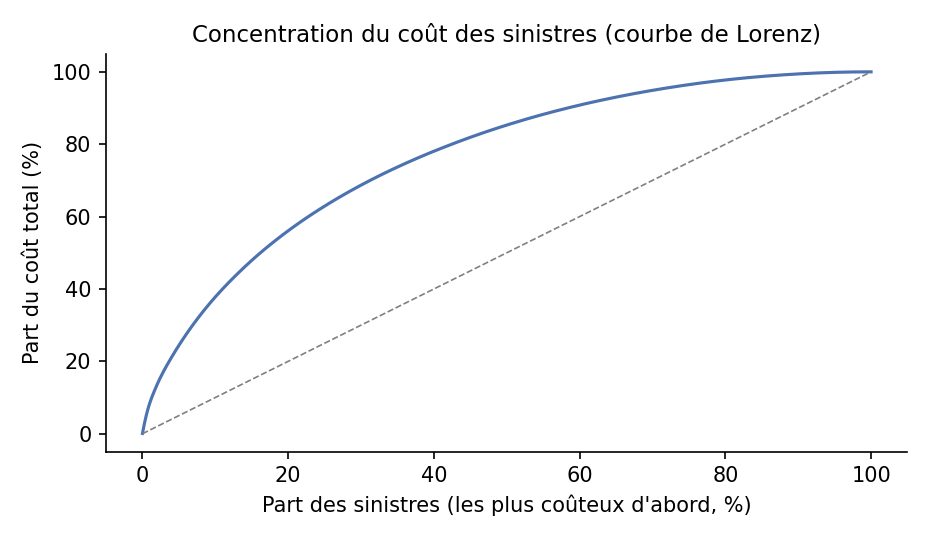

**Concentration du coût sur les plus gros sinistres** — 4 lignes × 2 colonnes

,part_des_sinistres_pct,part_du_cout_pct
0,1,8.439
1,5,24.4
2,10,37.79
3,20,56.08


**Polices atypiques : synthèse** — 7 lignes × 1 colonnes

,valeur
n_test,2e+04
n_atyp,11
part_polices,0.055
sinistres_observes,36
sinistres_attendus,2.513
part_sinistres,1.211
part_cout,1.049


**Polices atypiques : liste (de la plus improbable à la moins improbable)** — 11 lignes × 6 colonnes

,PolNum,nb,expo,cout,sinistres_attendus,probabilite_queue
0,200142508,4,0.8712,"3,567",0.2443,0.0001221
1,200271683,4,1,"2,283",0.2592,0.0001529
2,200148126,3,1,"2,247",0.1069,0.000188
3,200250652,2,1,"2,036",0.02135,0.0002247
4,200162862,3,0.7425,"2,107",0.1409,0.0004193
5,200121521,6,1,"5,408",0.957,0.0004733
6,200258873,4,1,851.1,0.3544,0.0004957
7,200117083,3,1,"1,877",0.1622,0.00063
8,200123720,2,1,620.2,0.04079,0.0008097
9,200115097,2,1,311.9,0.04294,0.000896


#### Points clés
- Les 1 % de sinistres les plus chers pèsent **8,4 %** du coût, les 10 % les plus chers **37,8 %**, et les 20 % les plus chers **56,1 %**.
- 11 polices atypiques sur 19 999 (0,06 % des polices) : 36 sinistres observés pour 2,5 attendus. Elles représentent 1,2 % des sinistres et 1,0 % du coût de l'échantillon test.
- Recommandation : suivre ces polices individuellement (vérification, revue de souscription) plutôt que de les laisser peser sur le tarif de tous.

#### Interprétation
- Le 1 % des sinistres les plus chers ne pèse que 8,4 % du coût : aucun sinistre isolé ne déséquilibre le portefeuille, et la prime pure moyenne ne dépend pas de quelques sinistres exceptionnels.
- Concentration de type Pareto : 20 % des sinistres font 56 % du coût. C'est habituel en auto, où beaucoup de petits sinistres côtoient quelques sinistres très chers.
- Polices atypiques : 36 sinistres pour 2,5 attendus (×14). Avec une loi de Poisson, un tel écart est quasi impossible par hasard : il faut en chercher la cause (usage professionnel non déclaré, conducteur secondaire, fraude, erreur de saisie).
- Elles ne pèsent que 1,0 % du coût : aucun danger pour l'équilibre global, mais un enjeu d'équité entre assurés.

In [32]:
res["etape8"] = lancer("Étape 8", lambda: etape8(res), "etape8")  # interprétation finale
e8 = res["etape8"]  # raccourci

afficher(e8["conc"], "Concentration du coût sur les plus gros sinistres")  # courbe de concentration
atyp = pd.Series(e8["atyp"], name="valeur").to_frame()  # synthèse des polices atypiques
afficher(atyp, "Polices atypiques : synthèse")  # affichage
liste = pd.read_csv(SORTIE / "etape8_polices_atypiques.csv", sep=";", decimal=",")  # liste détaillée des polices
afficher(liste, "Polices atypiques : liste (de la plus improbable à la moins improbable)", 20)  # affichage

c = e8["conc"].set_index("part_des_sinistres_pct")["part_du_cout_pct"]  # part du coût selon la part des sinistres
a = e8["atyp"]  # dictionnaire des indicateurs atypiques
points_cles(  # constats chiffrés
    f"Les 1 % de sinistres les plus chers pèsent **{c.loc[1.0]:.1f} %** du coût, les 10 % les plus chers "
    f"**{c.loc[10.0]:.1f} %**, et les 20 % les plus chers **{c.loc[20.0]:.1f} %**.",
    f"{a['n_atyp']} polices atypiques sur {nb_fr(a['n_test'])} ({a['part_polices']:.2f} % des polices) : "
    f"{a['sinistres_observes']:.0f} sinistres observés pour {a['sinistres_attendus']:.1f} attendus. Elles représentent "
    f"{a['part_sinistres']:.1f} % des sinistres et {a['part_cout']:.1f} % du coût de l'échantillon test.",
    "Recommandation : suivre ces polices individuellement (vérification, revue de souscription) "
    "plutôt que de les laisser peser sur le tarif de tous.",
)

sur_risque = a["sinistres_observes"] / a["sinistres_attendus"]  # sinistres observés / attendus des atypiques
interpretation(  # lecture actuarielle
    verdict(c.loc[1.0] < 15, f"Le 1 % des sinistres les plus chers ne pèse que {c.loc[1.0]:.1f} % du coût : aucun sinistre "
            "isolé ne déséquilibre le portefeuille, et la prime pure moyenne ne dépend pas de quelques sinistres exceptionnels.",
            f"Le 1 % des sinistres les plus chers pèse {c.loc[1.0]:.1f} % du coût : le résultat dépend de quelques sinistres, "
            "il faut prévoir un écrêtement et une réassurance."),
    f"Concentration de type Pareto : 20 % des sinistres font {c.loc[20.0]:.0f} % du coût. C'est habituel en auto, "
    "où beaucoup de petits sinistres côtoient quelques sinistres très chers.",
    f"Polices atypiques : {a['sinistres_observes']:.0f} sinistres pour {a['sinistres_attendus']:.1f} attendus (×{sur_risque:.0f}). "
    "Avec une loi de Poisson, un tel écart est quasi impossible par hasard : il faut en chercher la cause "
    "(usage professionnel non déclaré, conducteur secondaire, fraude, erreur de saisie).",
    verdict(a["part_cout"] < 5, f"Elles ne pèsent que {a['part_cout']:.1f} % du coût : aucun danger pour l'équilibre global, "
            "mais un enjeu d'équité entre assurés.",
            f"Elles pèsent {a['part_cout']:.1f} % du coût : leur traitement a un impact réel sur le tarif."),
)

### Étape 9 — Application : tarification et prévision

**Objectif.** Construire un **tarif utilisable**, c'est-à-dire une prime pour chaque assuré, et vérifier qu'il **prévoit** correctement la sinistralité d'une année qu'il n'a jamais vue.

**Méthode.**
1. **Validation temporelle** : le portefeuille contient deux années (2009 et 2010, 50 000 polices chacune). Le tarif est construit **uniquement sur 2009**, puis appliqué à **2010**. C'est la situation réelle d'un assureur, qui tarifie l'année suivante avec les données passées.
2. **Modèle fréquence × coût** : GLM de Poisson pour la fréquence et GLM Gamma pour le coût moyen. Un GLM donne un tarif **multiplicatif et lisible** : prime = prime de base × coefficient de chaque facteur.
3. **Variables tarifaires** : tranche d'âge, bande de bonus-malus, ancienneté, type de véhicule, profession, densité. Le **sexe est exclu** : depuis l'arrêt *Test-Achats* de la CJUE (applicable au 21/12/2012), il est interdit comme critère tarifaire dans l'Union européenne.
4. **Équilibrage** : un coefficient garantit que la somme des primes pures égale la somme des coûts 2009.
5. **Prime commerciale** = prime pure × (1 + chargement). Le chargement de 30 % couvrant frais, marge et sécurité est une **hypothèse de travail** (ordre de grandeur usuel en assurance automobile).

**Comment lire.** Un coefficient de 1,50 veut dire « 50 % plus cher que l'assuré de référence ». Le ratio **S/P** (sinistres / primes) doit être proche de la même valeur dans tous les groupes : sinon, certains assurés paient trop et partiront chez un concurrent (**antisélection**).

In [33]:
from sklearn.linear_model import GammaRegressor, PoissonRegressor  # GLM Poisson et Gamma

CHARGEMENT = 0.30  # hypothèse de travail : chargement de 30 % pour frais, marge et sécurité
T = base[base["expo_annees"] > 0].copy()  # polices avec une exposition positive
T["bande_bonus"] = pd.cut(T["Bonus"], [-51, -30, 0, 50, 150],  # bonus-malus en 4 bandes
                          labels=["≤ −30", "−29 à 0", "+1 à +50", "> +50"]).astype(str)
T["bande_densite"] = pd.qcut(T["Density"], 4, labels=["D1 faible", "D2", "D3", "D4 forte"]).astype(str)  # densité en quartiles
FACTEURS = {  # variable : libellé
    "tranche_age": "Âge", "bande_bonus": "Bonus-malus", "tranche_anciennete": "Ancienneté",
    "Type": "Type de véhicule", "Occupation": "Profession", "bande_densite": "Densité de la zone",
}
REFS = {f: T.groupby(f)["expo_annees"].sum().idxmax() for f in FACTEURS}  # référence = modalité la plus exposée


def matrice(df):  # transforme les facteurs en variables 0/1, sans la modalité de référence
    X = pd.get_dummies(df[list(FACTEURS)].astype(str), prefix_sep="=")  # une colonne par modalité
    X = X.drop(columns=[f"{f}={r}" for f, r in REFS.items()], errors="ignore")  # retire les références
    return X.reindex(columns=COLONNES, fill_value=0).astype(float)  # mêmes colonnes que l'apprentissage


COLONNES = [c for c in pd.get_dummies(T[list(FACTEURS)].astype(str), prefix_sep="=").columns  # toutes les modalités
            if c not in {f"{f}={r}" for f, r in REFS.items()}]  # sauf les références
app, prev = T[T["CalYear"] == 2009], T[T["CalYear"] == 2010]  # 2009 pour construire, 2010 pour prévoir
X_app = matrice(app)  # facteurs de 2009

glm_f = PoissonRegressor(alpha=1e-6, max_iter=1000)  # GLM de fréquence (pénalité quasi nulle)
glm_f.fit(X_app, app["nb_sinistres"] / app["expo_annees"], sample_weight=app["expo_annees"])  # pondéré par l'exposition
avec_cout = app[(app["nb_sinistres"] > 0) & (app["cout_total"] > 0)]  # polices avec au moins un sinistre payé
glm_c = GammaRegressor(alpha=1e-6, max_iter=1000)  # GLM du coût moyen par sinistre
glm_c.fit(matrice(avec_cout), avec_cout["cout_total"] / avec_cout["nb_sinistres"],  # coût moyen par sinistre
          sample_weight=avec_cout["nb_sinistres"])  # pondéré par le nombre de sinistres


def prime_brute(df):  # prime pure annuelle avant équilibrage = fréquence × coût moyen
    X = matrice(df)  # facteurs de la police
    return glm_f.predict(X) * glm_c.predict(X)  # produit des deux modèles


K = app["cout_total"].sum() / (prime_brute(app) * app["expo_annees"]).sum()  # coefficient d'équilibrage sur 2009
PRIME_BASE = K * np.exp(glm_f.intercept_ + glm_c.intercept_)  # prime pure annuelle de l'assuré de référence

grille = pd.DataFrame({  # coefficients tarifaires par modalité
    "colonne": COLONNES,  # nom technique
    "coef_frequence": np.exp(glm_f.coef_),  # effet sur la fréquence
    "coef_cout": np.exp(glm_c.coef_),  # effet sur le coût moyen
})
grille["coefficient"] = grille["coef_frequence"] * grille["coef_cout"]  # effet total sur la prime
grille[["facteur", "modalité"]] = grille["colonne"].str.split("=", n=1, expand=True)  # facteur et modalité
refs = pd.DataFrame([{"facteur": f, "modalité": f"{r} (référence)", "coef_frequence": 1.0,  # lignes des références
                      "coef_cout": 1.0, "coefficient": 1.0} for f, r in REFS.items()])
grille = pd.concat([refs, grille.drop(columns="colonne")])  # grille complète
grille["facteur"] = grille["facteur"].map(FACTEURS)  # libellé lisible du facteur
grille = grille.sort_values(["facteur", "coefficient"]).set_index(["facteur", "modalité"])  # tri
grille.to_csv(SORTIE / "etape9_grille_tarifaire.csv", sep=";", decimal=",")  # sauvegarde

display(Markdown(f"**Prime pure de base** (assuré de référence : {', '.join(f'{FACTEURS[f]} {r}' for f, r in REFS.items())}) : "
                 f"**{nb_fr(PRIME_BASE, 1)} € / an**, soit {nb_fr(PRIME_BASE * (1 + CHARGEMENT), 1)} € de prime commerciale."))
afficher(grille, "Grille tarifaire (coefficients multiplicatifs)", 40)  # affichage de la grille

amplitude = grille.groupby(level=0)["coefficient"].agg(lambda c: c.max() / c.min()).sort_values(ascending=False)  # écart par facteur
points_cles(  # constats chiffrés
    "Écart de prime entre la modalité la plus chère et la moins chère, par facteur : "
    + ", ".join(f"{k} ×{v:.2f}" for k, v in amplitude.items()) + ".",
    f"Le facteur le plus discriminant est **{amplitude.index[0]}**, suivi de **{amplitude.index[1]}**.",
    f"Coefficient d'équilibrage K = {K:.4f} : la somme des primes pures 2009 égale le coût observé 2009 "
    + ("(correction négligible : les GLM sont déjà équilibrés)." if abs(K - 1) < 0.01 else f"(correction de {100 * (K - 1):+.1f} %)."),
)

correspondance = {"tranche_age": "Âge", "Occupation": "Profession", "tranche_anciennete": "Ancienneté", "Type": "Type de véhicule"}
comparaison = [f"{lib} ×{ecarts[v]:.2f} → ×{amplitude[lib]:.2f}" for v, lib in correspondance.items()
               if v in ecarts and lib in amplitude]  # écart brut (3 bis) contre écart ajusté (GLM)
hausses = [lib for v, lib in correspondance.items() if v in ecarts and lib in amplitude and amplitude[lib] > ecarts[v]]  # effets renforcés
interpretation(  # lecture de la grille
    "**Lecture** : un coefficient de 1,30 = prime 30 % plus chère que la référence ; 0,80 = 20 % moins chère. "
    "La prime d'un assuré = prime de base × le produit de ses coefficients.",
    "Écart brut (étape 3 bis) → écart ajusté (GLM) : " + ", ".join(comparaison) + ". Un écart qui **diminue** veut dire "
    "qu'une partie de l'effet brut passait par une autre variable (par exemple, les jeunes ont aussi plus souvent un malus) : "
    "le GLM retire ces effets croisés."
    + (f" Un écart qui **augmente** ({', '.join(hausses)}) veut dire que l'effet était masqué en univarié par une autre variable "
       "et n'apparaît qu'à caractéristiques égales." if hausses else ""),
    verdict(abs(K - 1) < 0.01, f"K = {K:.4f} ≈ 1 : les primes pures reproduisent le coût 2009 sans correction. Le tarif est **équilibré**.",
            f"K = {K:.4f} : les GLM seuls ne reproduisent pas le coût total, la correction est nécessaire."),
    "Les coefficients des modalités peu exposées (petites professions, véhicules rares) sont moins précis : "
    "en pratique on les lisse ou on les regroupe avec une modalité voisine.",
)

**Prime pure de base** (assuré de référence : Âge 36-50, Bonus-malus ≤ −30, Ancienneté 2-4, Type de véhicule A, Profession Employed, Densité de la zone D1 faible) : **23,3 € / an**, soit 30,2 € de prime commerciale.

**Grille tarifaire (coefficients multiplicatifs)** — 28 lignes × 3 colonnes

coef_frequence  coef_cout  \
facteur            modalité                                           
Ancienneté         10+                            0.7942     0.9302   
                   5-9                             0.925     0.9387   
                   2-4 (référence)                     1          1   
                   0-1                             1.058     0.9571   
Bonus-malus        ≤ −30 (référence)                   1          1   
                   −29 à 0                         1.725      1.016   
                   +1 à +50                        2.487     0.8846   
                   > +50                           4.901     0.8273   
Densité de la zone D1 faible (référence)               1          1   
                   D2                               1.19      1.065   
                   D3                              1.584      1.099   
                   D4 forte                        2.494       1.19   
Profession         Retired                        0.4064      1.747   
                   Self-employed                  0.8387      1.038   
                   Employed (référence)                1          1   
                   Housewife                       1.255     0.8305   
                   Unemployed                      1.202      1.183   
Type de véhicule   A (référence)                       1          1   
                   D                               1.283     0.8087   
                   B                               1.099     0.9772   
                   C                               1.153     0.9317   
                   E                               1.366     0.7947   
                   F                               1.519     0.7818   
Âge                36-50 (référence)                   1          1   
                   51-65                           1.111     0.9469   
                   66+                             1.356     0.8876   
                   26-35                           1.442      1.062   
                   18-25                           2.606      1.327   

                                          coefficient  
facteur            modalité                            
Ancienneté         10+                         0.7388  
                   5-9                         0.8684  
                   2-4 (référence)                  1  
                   0-1                          1.013  
Bonus-malus        ≤ −30 (référence)                1  
                   −29 à 0                      1.753  
                   +1 à +50                       2.2  
                   > +50                        4.055  
Densité de la zone D1 faible (référence)            1  
                   D2                           1.267  
                   D3                           1.741  
                   D4 forte                     2.969  
Profession         Retired                     0.7102  
                   Self-employed               0.8706  
                   Employed (référence)             1  
                   Housewife                    1.042  
                   Unemployed                   1.422  
Type de véhicule   A (référence)                    1  
                   D                            1.037  
                   B                            1.074  
                   C                            1.074  
                   E                            1.085  
                   F                            1.187  
Âge                36-50 (référence)                1  
                   51-65                        1.052  
                   66+                          1.203  
                   26-35                         1.53  
                   18-25                        3.458

#### Points clés
- Écart de prime entre la modalité la plus chère et la moins chère, par facteur : Bonus-malus ×4,05, Âge ×3,46, Densité de la zone ×2,97, Profession ×2,00, Ancienneté ×1,37, Type de véhicule ×1,19.
- Le facteur le plus discriminant est **Bonus-malus**, suivi de **Âge**.
- Coefficient d'équilibrage K = 1,0001 : la somme des primes pures 2009 égale le coût observé 2009 (correction négligible : les GLM sont déjà équilibrés).

#### Interprétation
- **Lecture** : un coefficient de 1,30 = prime 30 % plus chère que la référence ; 0,80 = 20 % moins chère. La prime d'un assuré = prime de base × le produit de ses coefficients.
- Écart brut (étape 3 bis) → écart ajusté (GLM) : Âge ×5,58 → ×3,46, Profession ×4,70 → ×2,00, Ancienneté ×1,44 → ×1,37, Type de véhicule ×1,08 → ×1,19. Un écart qui **diminue** veut dire qu'une partie de l'effet brut passait par une autre variable (par exemple, les jeunes ont aussi plus souvent un malus) : le GLM retire ces effets croisés. Un écart qui **augmente** (Type de véhicule) veut dire que l'effet était masqué en univarié par une autre variable et n'apparaît qu'à caractéristiques égales.
- K = 1,0001 ≈ 1 : les primes pures reproduisent le coût 2009 sans correction. Le tarif est **équilibré**.
- Les coefficients des modalités peu exposées (petites professions, véhicules rares) sont moins précis : en pratique on les lisse ou on les regroupe avec une modalité voisine.

#### Graphique : décomposition des coefficients tarifaires
Pour chaque modalité, l'effet sur la **fréquence** (rond), sur le **coût moyen** d'un sinistre (carré) et l'effet total sur la prime (losange), qui est le produit des deux. Échelle logarithmique : 1 = modalité de référence.

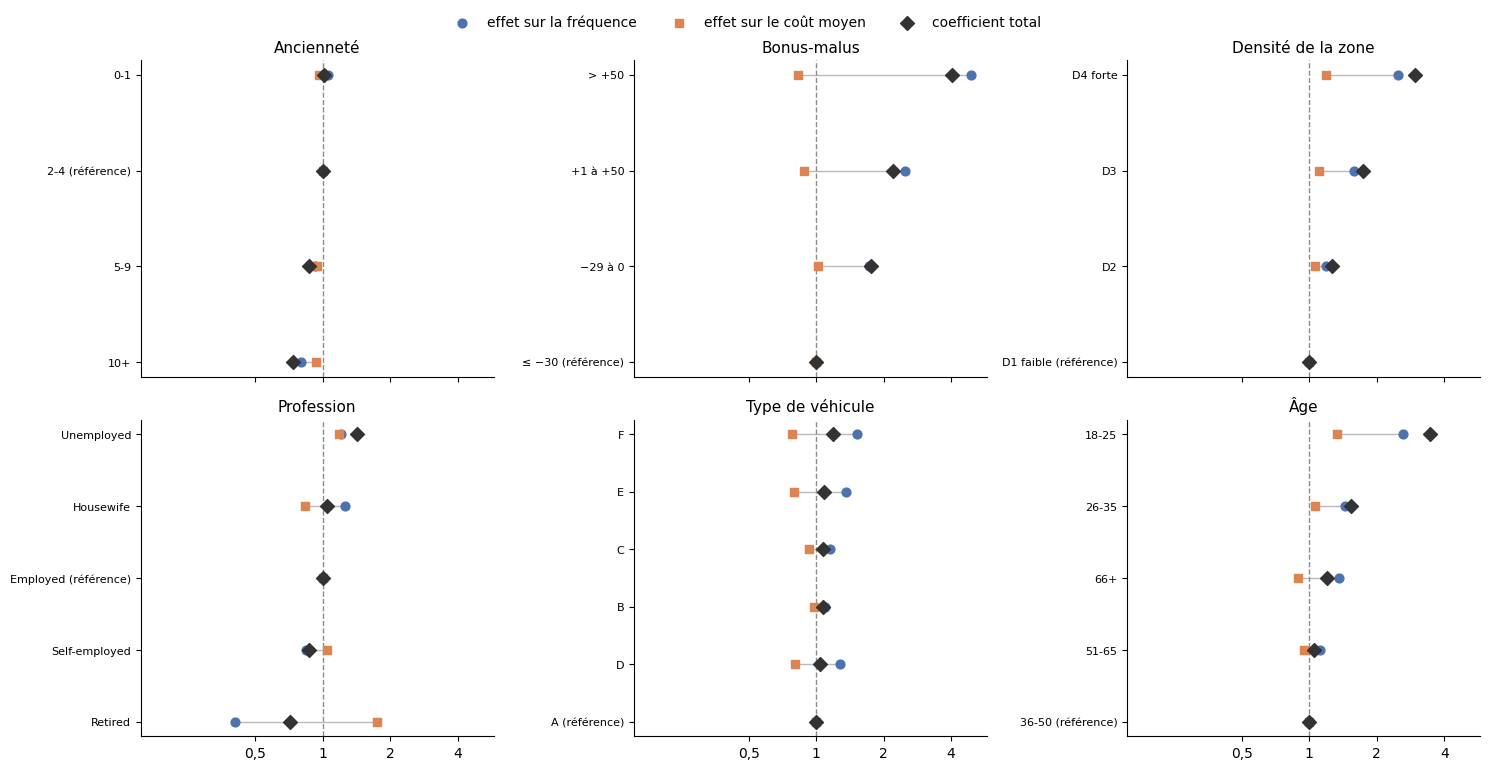

#### Points clés
- 8 modalités ont des effets de **sens contraire** sur la fréquence et sur le coût : Bonus-malus = +1 à +50 (fréquence ×2,49, coût ×0,88), Bonus-malus = > +50 (fréquence ×4,90, coût ×0,83), Profession = Retired (fréquence ×0,41, coût ×1,75), Profession = Housewife (fréquence ×1,26, coût ×0,83), Type de véhicule = D (fréquence ×1,28, coût ×0,81), Type de véhicule = E (fréquence ×1,37, coût ×0,79), Type de véhicule = F (fréquence ×1,52, coût ×0,78), Âge = 66+ (fréquence ×1,36, coût ×0,89).

#### Interprétation
- Les retraités ont **moins de sinistres** (fréquence ×0,41) mais des sinistres **plus coûteux** (coût ×1,75) : les deux effets se compensent en partie et leur coefficient total n'est que de ×0,71.
- Les forts malus ont beaucoup plus de sinistres (×4,90) mais des sinistres un peu moins chers (×0,83) : cela suggère des sinistres plus nombreux mais plutôt de petite taille (accrochages).
- C'est l'intérêt de modéliser **séparément** la fréquence et le coût : un modèle unique de la prime pure donnerait le même coefficient total, mais cacherait ces mécanismes, qui sont utiles pour la prévention et la gestion des sinistres.
- Pour 100 % des modalités, l'effet sur la fréquence est plus fort que l'effet sur le coût : la fréquence reste le moteur principal de la segmentation.

In [34]:
facteurs_g = list(grille.index.get_level_values(0).unique())  # facteurs de la grille
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True)  # une petite figure par facteur
for ax, f in zip(axes.flat, facteurs_g):  # un facteur par graphique
    g = grille.loc[f]  # modalités du facteur, triées par coefficient
    pos = np.arange(len(g))  # une ligne par modalité
    ax.hlines(pos, np.minimum(g["coef_frequence"], g["coef_cout"]), np.maximum(g["coef_frequence"], g["coef_cout"]),
              color=GRIS, lw=1, alpha=0.6)  # trait reliant les deux effets
    ax.scatter(g["coef_frequence"], pos, marker="o", s=40, color=BLEU, label="effet sur la fréquence", zorder=3)
    ax.scatter(g["coef_cout"], pos, marker="s", s=40, color=ORANGE, label="effet sur le coût moyen", zorder=3)
    ax.scatter(g["coefficient"], pos, marker="D", s=50, color="#333333", label="coefficient total", zorder=4)
    ax.axvline(1, color=GRIS, ls="--", lw=1)  # référence
    ax.set_xscale("log")  # échelle logarithmique
    ax.set_yticks(pos, g.index)  # noms des modalités
    ax.tick_params(axis="y", labelsize=8)  # libellés plus petits
    ax.set_title(f)  # nom du facteur
for ax in axes.flat:  # graduations lisibles
    ax.set_xticks([0.5, 1, 2, 4], ["0,5", "1", "2", "4"])
    ax.minorticks_off()
poignees, libelles = axes.flat[0].get_legend_handles_labels()  # légende commune
fig.legend(poignees, libelles, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.03))
plt.tight_layout()  # ajuste les marges
montrer_fig("grille_tarifaire")  # affiche et enregistre la figure

gr = grille.reset_index()  # grille à plat
opposes_g = gr[((gr["coef_frequence"] - 1) * (gr["coef_cout"] - 1) < 0)  # effets de sens contraires
               & (np.abs(np.log(gr["coef_frequence"])) > 0.1) & (np.abs(np.log(gr["coef_cout"])) > 0.1)]
retraite = gr[gr["modalité"].str.startswith("Retired")]  # retraités
malus_fort = gr[gr["modalité"].str.startswith("> +50")]  # forts malus
points_cles(
    f"{len(opposes_g)} modalités ont des effets de **sens contraire** sur la fréquence et sur le coût : "
    + ", ".join(f"{r['facteur']} = {r['modalité']} (fréquence ×{r['coef_frequence']:.2f}, coût ×{r['coef_cout']:.2f})"
                for _, r in opposes_g.iterrows()) + ".",
)
interpretation(
    (f"Les retraités ont **moins de sinistres** (fréquence ×{retraite['coef_frequence'].iloc[0]:.2f}) mais des sinistres "
     f"**plus coûteux** (coût ×{retraite['coef_cout'].iloc[0]:.2f}) : les deux effets se compensent en partie et leur "
     f"coefficient total n'est que de ×{retraite['coefficient'].iloc[0]:.2f}." if len(retraite) else ""),
    (f"Les forts malus ont beaucoup plus de sinistres (×{malus_fort['coef_frequence'].iloc[0]:.2f}) mais des sinistres "
     f"un peu moins chers (×{malus_fort['coef_cout'].iloc[0]:.2f}) : cela suggère des sinistres "
     "plus nombreux mais plutôt de petite taille (accrochages)." if len(malus_fort) else ""),
    "C'est l'intérêt de modéliser **séparément** la fréquence et le coût : un modèle unique de la prime pure donnerait le "
    "même coefficient total, mais cacherait ces mécanismes, qui sont utiles pour la prévention et la gestion des sinistres.",
    f"Pour {100 * (np.abs(np.log(gr['coef_frequence'])) >= np.abs(np.log(gr['coef_cout']))).mean():.0f} % des modalités, "
    "l'effet sur la fréquence est plus fort que l'effet sur le coût : la fréquence reste le moteur principal de la segmentation.",
)
pour_rapport("grille_tarifaire", "Étape 9 : grille tarifaire et décomposition fréquence × coût",
             "Coefficients tarifaires par modalité : effet sur la fréquence, sur le coût moyen et effet total (échelle logarithmique).")

#### Prévision 2010 et test de l'antisélection
On applique le tarif 2009 aux polices de 2010, puis on compare avec les sinistres réellement observés en 2010. On le compare aussi à un **tarif uniforme**, où tout le monde paie la même prime moyenne.

**Sinistralité observée par année** — 2 lignes × 6 colonnes

,sinistres,expo,cout,fréquence (pour 100 ans),coût moyen (€),prime pure (€/an)
CalYear,,,,,,
2009,7022,4.488e+04,4.929e+06,15.64,702,109.8
2010,7726,4.486e+04,5.686e+06,17.22,736,126.7


,prévu (tarif 2009),observé 2010,écart %
Nombre de sinistres,"7,048","7,726",-8.772
Coût total (€),4.984e+06,5.686e+06,-12.35


**Ratio sinistres / primes 2010 par décile de risque** — 10 lignes × 7 colonnes

,polices,prime_annuelle_moyenne,cout,prime_segmentee,prime_uniforme,S/P segmenté,S/P uniforme
decile,,,,,,,
1,5024,19.97,1.128e+05,8.986e+04,4.938e+05,1.255,0.2284
2,4995,27.69,1.518e+05,1.241e+05,4.926e+05,1.223,0.3082
3,4981,35.74,1.903e+05,1.601e+05,4.918e+05,1.189,0.3869
4,5000,46,2.306e+05,2.059e+05,4.913e+05,1.12,0.4694
5,5025,58.98,2.974e+05,2.654e+05,4.944e+05,1.12,0.6016
6,4982,74.69,3.755e+05,3.334e+05,4.901e+05,1.126,0.766
7,4993,100.7,5.308e+05,4.535e+05,4.947e+05,1.17,1.073
8,5000,138.6,7.326e+05,6.243e+05,4.947e+05,1.174,1.481
9,5004,202.8,9.915e+05,9.089e+05,4.921e+05,1.091,2.015


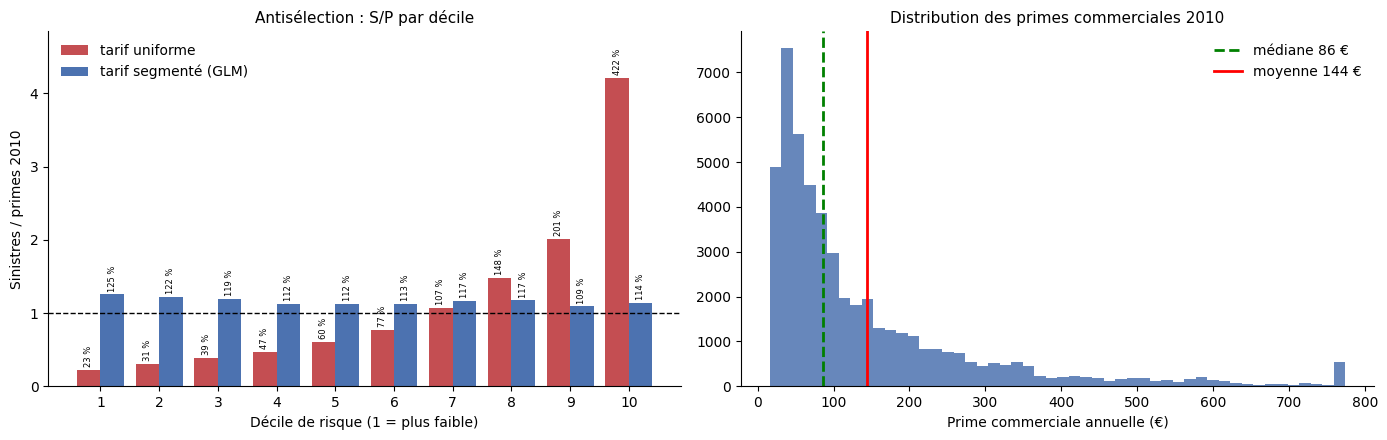

#### Points clés
- Prévision 2010 : coût prévu 4 983 979 € contre 5 686 465 € observés (écart **-12,4 %**). Le tarif 2009 sous-estime 2010, car la sinistralité a augmenté : fréquence 15,6 → 17,2 pour 100 ans, coût moyen 702 → 736 €.
- En pratique, il faut appliquer au tarif un **coefficient de tendance** (ici ×1,154 entre 2009 et 2010). Avec seulement deux années, ce coefficient est une estimation fragile : il faudra le confirmer sur plus d'historique.
- Avec un **tarif uniforme**, le S/P va de 0,23 (décile 1) à 4,22 (décile 10) : les bons risques paient trop, partent chez un concurrent, et l'assureur garde les mauvais risques (antisélection).
- Avec le **tarif segmenté**, le S/P reste entre 1,09 et 1,25 : il est trop élevé partout, à cause de la hausse de 2010, mais **au même niveau dans tous les déciles**. La segmentation reste donc valable d'une année sur l'autre : seul le niveau général doit être ajusté.
- Prime commerciale annuelle 2010 : médiane 86 €, 90 % des assurés entre 26 € et 470 €.

#### Interprétation
- Écart de -12,4 % : le tarif est bien **structuré** (segmentation stable), mais son **niveau** est dépassé par la hausse de la sinistralité. C'est un problème de **tendance**, pas de modèle.
- Écart de S/P entre déciles : ×18 avec le tarif uniforme, ×1,15 avec le tarif segmenté. La segmentation supprime presque toute la **subvention** des mauvais risques par les bons.
- Rapporté à la prime commerciale (chargement 30 %), le S/P monte jusqu'à 0,97 : la hausse de 2010 a consommé presque tout le chargement, il ne reste presque rien pour les frais et la marge.
- Recommandation : garder la **structure** de la grille et ajuster son **niveau** avec le coefficient de tendance (×1,154), à réestimer dès que plus d'années seront disponibles.

In [35]:
prev = prev.copy()  # polices 2010
prev["prime_pure"] = K * prime_brute(prev) * prev["expo_annees"]  # prime pure segmentée (exposition réelle)
prime_uniforme = app["cout_total"].sum() / app["expo_annees"].sum()  # prime unique : coût moyen 2009 par année
prev["prime_uniforme"] = prime_uniforme * prev["expo_annees"]  # tarif uniforme

prevu, observe = prev["prime_pure"].sum(), prev["cout_total"].sum()  # coût prévu et observé en 2010
annee = T.groupby("CalYear").agg(sinistres=("nb_sinistres", "sum"), expo=("expo_annees", "sum"),  # sinistralité par année
                                 cout=("cout_total", "sum"))
annee["fréquence (pour 100 ans)"] = 100 * annee["sinistres"] / annee["expo"]  # fréquence annuelle
annee["coût moyen (€)"] = annee["cout"] / annee["sinistres"]  # coût moyen par sinistre
annee["prime pure (€/an)"] = annee["cout"] / annee["expo"]  # coût par année d'exposition
afficher(annee, "Sinistralité observée par année")  # comparaison 2009 / 2010
TENDANCE = annee.loc[2010, "prime pure (€/an)"] / annee.loc[2009, "prime pure (€/an)"]  # évolution de la prime pure
nb_prevu = (glm_f.predict(matrice(prev)) * prev["expo_annees"]).sum()  # nombre de sinistres prévu
display(pd.DataFrame({  # bilan de la prévision
    "prévu (tarif 2009)": [nb_prevu, prevu],  # ce que le tarif annonçait
    "observé 2010": [prev["nb_sinistres"].sum(), observe],  # ce qui s'est passé
    "écart %": [100 * (nb_prevu / prev["nb_sinistres"].sum() - 1), 100 * (prevu / observe - 1)],  # erreur relative
}, index=["Nombre de sinistres", "Coût total (€)"]))  # deux lignes

prev["decile"] = pd.qcut(prev["prime_pure"] / prev["expo_annees"], 10, labels=range(1, 11))  # déciles de prime annuelle
dec9 = prev.groupby("decile", observed=True).agg(  # bilan par décile
    polices=("PolNum", "size"),  # nombre de polices
    prime_annuelle_moyenne=("prime_pure", lambda s: (s / prev.loc[s.index, "expo_annees"]).mean()),  # prime moyenne
    cout=("cout_total", "sum"),  # coût réel
    prime_segmentee=("prime_pure", "sum"),  # primes encaissées avec le tarif segmenté
    prime_uniforme=("prime_uniforme", "sum"),  # primes encaissées avec le tarif uniforme
)
dec9["S/P segmenté"] = dec9["cout"] / dec9["prime_segmentee"]  # ratio sinistres / primes, tarif segmenté
dec9["S/P uniforme"] = dec9["cout"] / dec9["prime_uniforme"]  # ratio sinistres / primes, tarif uniforme
afficher(dec9, "Ratio sinistres / primes 2010 par décile de risque", 10)  # affichage

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))  # deux graphiques
x = np.arange(1, 11)  # numéros de décile
b_u = ax1.bar(x - 0.2, dec9["S/P uniforme"], 0.4, label="tarif uniforme", color="#C44E52")  # S/P avec tarif uniforme
b_s = ax1.bar(x + 0.2, dec9["S/P segmenté"], 0.4, label="tarif segmenté (GLM)", color="#4C72B0")  # S/P avec tarif segmenté
for b_, col in [(b_u, "S/P uniforme"), (b_s, "S/P segmenté")]:  # étiquette en % sur chaque bâton
    ax1.bar_label(b_, labels=[f"{100 * v:.0f} %" for v in dec9[col]], padding=2, fontsize=6, rotation=90)  # S/P en %
ax1.margins(y=0.15)  # place pour les étiquettes
ax1.axhline(1, color="black", lw=1, ls="--")  # S/P = 1 : primes = sinistres
ax1.set_xticks(x)  # un repère par décile
ax1.set_xlabel("Décile de risque (1 = plus faible)")  # axe horizontal
ax1.set_ylabel("Sinistres / primes 2010")  # axe vertical
ax1.set_title("Antisélection : S/P par décile")  # titre
ax1.legend()  # légende
pc = prev["prime_pure"] / prev["expo_annees"] * (1 + CHARGEMENT)  # prime commerciale annuelle
ax2.hist(pc.clip(upper=pc.quantile(0.99)), bins=50, color="#4C72B0", alpha=0.85)  # distribution (1 % extrême regroupé)
ax2.axvline(pc.median(), color="green", ls="--", lw=2, label=f"médiane {pc.median():.0f} €")  # médiane
ax2.axvline(pc.mean(), color="red", lw=2, label=f"moyenne {pc.mean():.0f} €")  # moyenne
ax2.set_xlabel("Prime commerciale annuelle (€)")  # axe horizontal
ax2.set_title("Distribution des primes commerciales 2010")  # titre
ax2.legend()  # légende
plt.tight_layout()  # ajuste les marges
montrer_fig("antiselection_primes")  # affiche et enregistre la figure

points_cles(  # constats chiffrés
    f"Prévision 2010 : coût prévu {nb_fr(prevu)} € contre {nb_fr(observe)} € observés "
    f"(écart **{100 * (prevu / observe - 1):+.1f} %**). Le tarif 2009 sous-estime 2010, car la sinistralité a augmenté : "
    f"fréquence {annee.loc[2009, 'fréquence (pour 100 ans)']:.1f} → {annee.loc[2010, 'fréquence (pour 100 ans)']:.1f} pour 100 ans, "
    f"coût moyen {nb_fr(annee.loc[2009, 'coût moyen (€)'])} → {nb_fr(annee.loc[2010, 'coût moyen (€)'])} €.",
    f"En pratique, il faut appliquer au tarif un **coefficient de tendance** (ici ×{TENDANCE:.3f} entre 2009 et 2010). "
    "Avec seulement deux années, ce coefficient est une estimation fragile : il faudra le confirmer sur plus d'historique.",
    f"Avec un **tarif uniforme**, le S/P va de {dec9['S/P uniforme'].iloc[0]:.2f} (décile 1) à "
    f"{dec9['S/P uniforme'].iloc[-1]:.2f} (décile 10) : les bons risques paient trop, partent chez un concurrent, "
    "et l'assureur garde les mauvais risques (antisélection).",
    f"Avec le **tarif segmenté**, le S/P reste entre {dec9['S/P segmenté'].min():.2f} et {dec9['S/P segmenté'].max():.2f} : "
    "il est trop élevé partout, à cause de la hausse de 2010, mais **au même niveau dans tous les déciles**. "
    "La segmentation reste donc valable d'une année sur l'autre : seul le niveau général doit être ajusté.",
    f"Prime commerciale annuelle 2010 : médiane {pc.median():.0f} €, 90 % des assurés entre "
    f"{pc.quantile(0.05):.0f} € et {pc.quantile(0.95):.0f} €.",
)

ecart_prev = prevu / observe - 1  # erreur de la prévision 2010
sp_commercial_max = dec9["S/P segmenté"].max() / (1 + CHARGEMENT)  # S/P rapporté à la prime commerciale
interpretation(  # lecture actuarielle
    verdict(abs(ecart_prev) < 0.05, f"La prévision 2010 est juste à {100 * abs(ecart_prev):.1f} % près.",
            f"Écart de {100 * ecart_prev:+.1f} % : le tarif est bien **structuré** (segmentation stable), mais son **niveau** "
            "est dépassé par la hausse de la sinistralité. C'est un problème de **tendance**, pas de modèle."),
    f"Écart de S/P entre déciles : ×{dec9['S/P uniforme'].iloc[-1] / dec9['S/P uniforme'].iloc[0]:.0f} avec le tarif uniforme, "
    f"×{dec9['S/P segmenté'].max() / dec9['S/P segmenté'].min():.2f} avec le tarif segmenté. La segmentation supprime "
    "presque toute la **subvention** des mauvais risques par les bons.",
    verdict(sp_commercial_max < 0.75, "Rapporté à la prime commerciale, le S/P laisse une marge suffisante pour les frais.",
            f"Rapporté à la prime commerciale (chargement {100 * CHARGEMENT:.0f} %), le S/P monte jusqu'à {sp_commercial_max:.2f} : "
            "la hausse de 2010 a consommé presque tout le chargement, il ne reste presque rien pour les frais et la marge."),
    f"Recommandation : garder la **structure** de la grille et ajuster son **niveau** avec le coefficient de tendance "
    f"(×{TENDANCE:.3f}), à réestimer dès que plus d'années seront disponibles.",
)
pour_rapport("antiselection_primes", "Étape 9 : prévision 2010 et antisélection",
             "Ratio sinistres / primes 2010 par décile de risque (tarif uniforme et tarif segmenté) et distribution des primes commerciales.")

#### Graphique : la hausse de 2010 est-elle la même dans tous les segments ?
Rapport entre la fréquence 2010 et la fréquence 2009 par segment, avec un intervalle de confiance à 95 % (loi de Poisson). Si tous les intervalles contiennent la hausse globale (ligne pleine), un **coefficient de tendance unique** suffit ; sinon, il faut ajuster la tendance segment par segment.

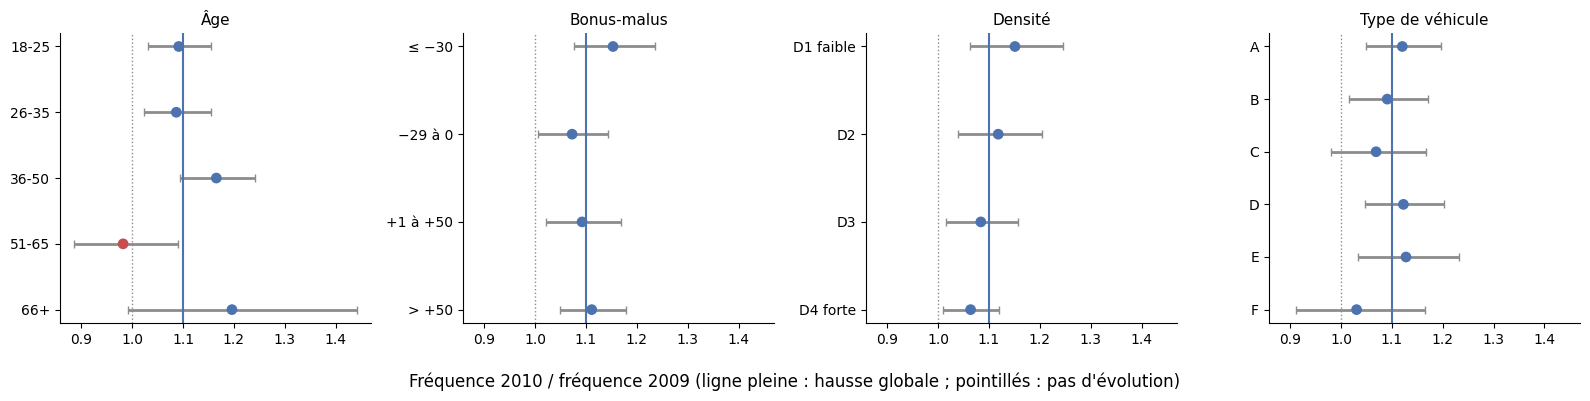

#### Points clés
- Hausse globale de la fréquence : **×1,101** ; du coût moyen : ×1,048 ; de la prime pure : ×1,154.
- Segments dont l'évolution diffère significativement de la tendance globale : Âge = 51-65 (×0,98).

#### Interprétation
- On teste 19 segments au seuil de 5 % : même si la hausse était partout identique, environ 1 segment(s) sortiraient de l'intervalle **par hasard** (problème des comparaisons multiples).
- 1 segment(s) seulement s'écartent de la tendance globale, ce qui est compatible avec le hasard : la hausse de 2010 touche **tous les segments de la même façon**. Un coefficient de tendance unique, appliqué à toute la grille, est justifié ; c'est cohérent avec le S/P homogène entre déciles.
- La hausse de la prime pure (×1,154) vient surtout de la **fréquence** (×1,101) et, dans une moindre mesure, du coût moyen (×1,048).
- Avec deux années seulement, on ne peut pas dire si cette hausse est durable (tendance) ou ponctuelle (année défavorable). Il faudra la confirmer avec les années suivantes avant de l'intégrer définitivement au tarif.

In [36]:
VAR_TENDANCE = {"tranche_age": "Âge", "bande_bonus": "Bonus-malus", "bande_densite": "Densité", "Type": "Type de véhicule"}
hausse_glob = annee.loc[2010, "fréquence (pour 100 ans)"] / annee.loc[2009, "fréquence (pour 100 ans)"]  # hausse globale
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True)  # une petite figure par variable
hors_tendance = []  # segments dont l'évolution diffère de la tendance globale
n_segments = 0  # nombre de segments testés
for ax, (v, lib) in zip(axes, VAR_TENDANCE.items()):  # une variable par graphique
    g = T.groupby([v, "CalYear"]).agg(n=("nb_sinistres", "sum"), e=("expo_annees", "sum")).unstack("CalYear")  # par année
    ORDRES = {"tranche_age": BANDES_AGE, "bande_bonus": ["≤ −30", "−29 à 0", "+1 à +50", "> +50"]}  # ordres naturels
    if v in ORDRES:
        g = g.reindex([a for a in ORDRES[v] if a in g.index])
    rap = (g[("n", 2010)] / g[("e", 2010)]) / (g[("n", 2009)] / g[("e", 2009)])  # rapport des fréquences
    se_log = np.sqrt(1 / g[("n", 2010)] + 1 / g[("n", 2009)])  # erreur type du log du rapport (Poisson)
    bas_t, haut_t = rap * np.exp(-1.96 * se_log), rap * np.exp(1.96 * se_log)  # intervalle de confiance à 95 %
    hors = (bas_t > hausse_glob) | (haut_t < hausse_glob)  # segment significativement différent
    n_segments += len(rap)  # segments testés
    hors_tendance += [f"{lib} = {m} (×{r:.2f})" for m, r in rap[hors].items()]
    pos = np.arange(len(rap))[::-1]  # première modalité en haut
    ax.errorbar(rap, pos, xerr=[rap - bas_t, haut_t - rap], fmt="none", ecolor=GRIS, elinewidth=2, capsize=3)
    ax.scatter(rap, pos, s=45, zorder=3, color=np.where(hors, ROUGE, BLEU))  # rouge : différent de la tendance
    ax.axvline(hausse_glob, color=BLEU, lw=1.5)  # hausse globale
    ax.axvline(1, color=GRIS, ls=":", lw=1)  # pas d'évolution
    ax.set_yticks(pos, rap.index.astype(str))  # modalités
    ax.set_title(lib)  # nom de la variable
fig.supxlabel("Fréquence 2010 / fréquence 2009 (ligne pleine : hausse globale ; pointillés : pas d'évolution)")
plt.tight_layout()  # ajuste les marges
montrer_fig("tendance_segments")  # affiche et enregistre la figure

hausse_cout = annee.loc[2010, "coût moyen (€)"] / annee.loc[2009, "coût moyen (€)"]  # évolution du coût moyen
points_cles(
    f"Hausse globale de la fréquence : **×{hausse_glob:.3f}** ; du coût moyen : ×{hausse_cout:.3f} ; "
    f"de la prime pure : ×{TENDANCE:.3f}.",
    (f"Segments dont l'évolution diffère significativement de la tendance globale : {', '.join(hors_tendance)}."
     if hors_tendance else "Aucun segment ne s'écarte significativement de la tendance globale."),
)
attendus_hasard = 0.05 * n_segments  # écarts attendus par hasard avec un test à 5 % par segment
interpretation(
    f"On teste {n_segments} segments au seuil de 5 % : même si la hausse était partout identique, environ "
    f"{attendus_hasard:.0f} segment(s) sortiraient de l'intervalle **par hasard** (problème des comparaisons multiples).",
    verdict(len(hors_tendance) <= max(1, round(attendus_hasard)),
            f"{len(hors_tendance)} segment(s) seulement s'écartent de la tendance globale, ce qui est compatible avec le hasard : "
            "la hausse de 2010 touche **tous les segments de la même façon**. Un coefficient de tendance unique, appliqué à "
            "toute la grille, est justifié ; c'est cohérent avec le S/P homogène entre déciles.",
            "La hausse n'est pas uniforme : un coefficient unique sous-tarifera certains segments. Il faut soit des tendances "
            "par segment, soit recalibrer le GLM sur les deux années avec un effet année."),
    f"La hausse de la prime pure (×{TENDANCE:.3f}) vient surtout de la **fréquence** (×{hausse_glob:.3f}) et, dans une "
    f"moindre mesure, du coût moyen (×{hausse_cout:.3f}).",
    "Avec deux années seulement, on ne peut pas dire si cette hausse est durable (tendance) ou ponctuelle (année "
    "défavorable). Il faudra la confirmer avec les années suivantes avant de l'intégrer définitivement au tarif.",
)
pour_rapport("tendance_segments", "Étape 9 : homogénéité de la tendance 2009-2010",
             "Rapport des fréquences 2010 / 2009 par segment, avec intervalles de confiance à 95 %.")

#### Exemples de tarifs pour quatre profils types

In [37]:
profils = pd.DataFrame([  # profils d'assurés fictifs (choix retenu), pour illustrer le tarif
    {"profil": "Jeune conducteur, malus, ville", "tranche_age": "18-25", "bande_bonus": "> +50",
     "tranche_anciennete": "0-1", "Type": "A", "Occupation": "Employed", "bande_densite": "D4 forte"},
    {"profil": "Jeune conducteur, sans malus, campagne", "tranche_age": "18-25", "bande_bonus": "−29 à 0",
     "tranche_anciennete": "0-1", "Type": "A", "Occupation": "Employed", "bande_densite": "D1 faible"},
    {"profil": "Conducteur expérimenté, bonus fort", "tranche_age": "36-50", "bande_bonus": "≤ −30",
     "tranche_anciennete": "10+", "Type": "A", "Occupation": "Employed", "bande_densite": "D2"},
    {"profil": "Retraité, bonus fort, campagne", "tranche_age": "66+", "bande_bonus": "≤ −30",
     "tranche_anciennete": "10+", "Type": "A", "Occupation": "Retired", "bande_densite": "D1 faible"},
]).set_index("profil")  # nom du profil en index
profils["fréquence (pour 100 ans)"] = 100 * glm_f.predict(matrice(profils))  # fréquence attendue
profils["coût moyen d'un sinistre (€)"] = K * glm_c.predict(matrice(profils))  # coût moyen attendu (équilibré)
profils["prime pure (€/an)"] = K * prime_brute(profils)  # prime pure annuelle
profils["prime commerciale (€/an)"] = profils["prime pure (€/an)"] * (1 + CHARGEMENT)  # prime commerciale
display(profils)  # affichage

pmax, pmin = profils["prime commerciale (€/an)"].max(), profils["prime commerciale (€/an)"].min()  # extrêmes
points_cles(  # constats chiffrés
    f"Entre le profil le plus cher et le moins cher, la prime commerciale varie de {pmin:.0f} € à {pmax:.0f} € "
    f"(×{pmax / pmin:.1f}).",
    "Le facteur ×K est appliqué au coût moyen pour que les profils restent cohérents avec le tarif équilibré.",
)

interpretation(  # lecture des profils
    f"Un écart ×{pmax / pmin:.0f} entre profils extrêmes est cohérent avec un tarif multiplicatif : les coefficients "
    "défavorables (âge, malus, densité) se **multiplient** entre eux.",
    f"Une prime de {pmin:.0f} € par an ne couvre probablement pas les frais fixes de gestion d'un contrat : "
    "en pratique, on fixe une **prime minimale**.",
    f"Une prime de {pmax:.0f} € par an est difficile à vendre à un jeune conducteur : il risque de partir. "
    "On peut la limiter par un plafond, une franchise plus élevée ou des réductions (conduite accompagnée, boîtier télématique).",
)

,tranche_age,bande_bonus,tranche_anciennete,Type,Occupation,bande_densite,fréquence (pour 100 ans),coût moyen d'un sinistre (€),prime pure (€/an),prime commerciale (€/an)
profil,,,,,,,,,,
"Jeune conducteur, malus, ville",18-25,> +50,0-1,A,Employed,D4 forte,113.8,861.3,980.5,"1,275"
"Jeune conducteur, sans malus, campagne",18-25,−29 à 0,0-1,A,Employed,D1 faible,16.07,888.6,142.8,185.6
"Conducteur expérimenté, bonus fort",36-50,≤ −30,10+,A,Employed,D2,3.191,682.5,21.78,28.32
"Retraité, bonus fort, campagne",66+,≤ −30,10+,A,Retired,D1 faible,1.478,993.9,14.69,19.1


#### Points clés
- Entre le profil le plus cher et le moins cher, la prime commerciale varie de 19 € à 1275 € (×66,7).
- Le facteur ×K est appliqué au coût moyen pour que les profils restent cohérents avec le tarif équilibré.

#### Interprétation
- Un écart ×67 entre profils extrêmes est cohérent avec un tarif multiplicatif : les coefficients défavorables (âge, malus, densité) se **multiplient** entre eux.
- Une prime de 19 € par an ne couvre probablement pas les frais fixes de gestion d'un contrat : en pratique, on fixe une **prime minimale**.
- Une prime de 1275 € par an est difficile à vendre à un jeune conducteur : il risque de partir. On peut la limiter par un plafond, une franchise plus élevée ou des réductions (conduite accompagnée, boîtier télématique).

#### Graphique : prime des profils types
Prime commerciale annuelle de chaque profil, décomposée en **prime pure** (coût attendu des sinistres) et **chargement** (frais, marge et sécurité). La ligne verticale indique la prime commerciale médiane du portefeuille en 2010.

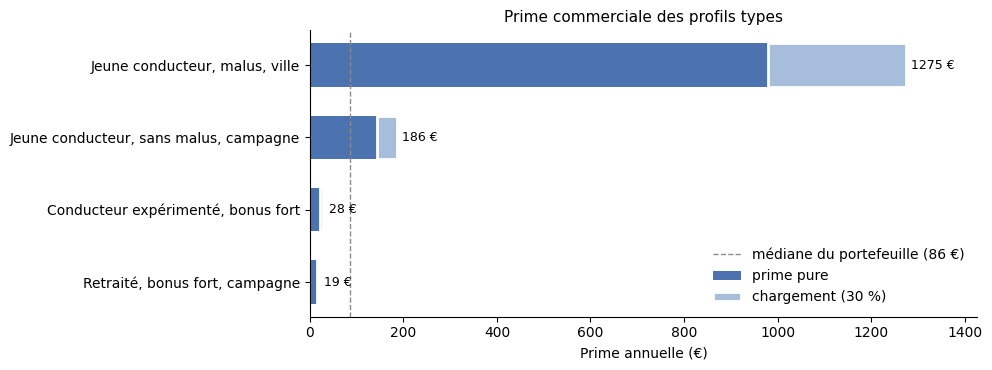

#### Points clés
- « Retraité, bonus fort, campagne » : 19 € par an, moins cher que plus de 99 % des assurés de 2010.
- « Conducteur expérimenté, bonus fort » : 28 € par an, plus cher que 7 % des assurés de 2010.
- « Jeune conducteur, sans malus, campagne » : 186 € par an, plus cher que 76 % des assurés de 2010.
- « Jeune conducteur, malus, ville » : 1275 € par an, plus cher que plus de 99 % des assurés de 2010.

#### Interprétation
- Les profils extrêmes se situent aux deux bouts de la distribution du portefeuille : le tarif utilise toute l'amplitude permise par les coefficients.
- Le chargement est proportionnel à la prime pure (30 %) : il rapporte peu sur les petits contrats, qui ont pourtant des frais de gestion comparables. Un chargement en partie **fixe** (par exemple un montant par contrat plus un pourcentage) serait plus réaliste.

In [38]:
pf = profils.sort_values("prime commerciale (€/an)")  # du moins cher au plus cher
fig, ax = plt.subplots(figsize=(10, 3.8))  # zone de dessin
b_pure = ax.barh(pf.index, pf["prime pure (€/an)"], color=BLEU, height=0.6, label="prime pure")  # prime pure
b_charg = ax.barh(pf.index, pf["prime commerciale (€/an)"] - pf["prime pure (€/an)"], left=pf["prime pure (€/an)"],
                  color="#A6BDDB", height=0.6, label=f"chargement ({100 * CHARGEMENT:.0f} %)", edgecolor="white", linewidth=2)
ax.bar_label(b_charg, labels=[f"{v:.0f} €" for v in pf["prime commerciale (€/an)"]], padding=4, fontsize=9)  # total
ax.axvline(pc.median(), color=GRIS, ls="--", lw=1, label=f"médiane du portefeuille ({pc.median():.0f} €)")  # repère
ax.margins(x=0.12)  # place pour les étiquettes
ax.set_xlabel("Prime annuelle (€)")  # axe horizontal
ax.set_title("Prime commerciale des profils types")  # titre
ax.legend(loc="lower right")  # légende
plt.tight_layout()  # ajuste les marges
montrer_fig("profils_types")  # affiche et enregistre la figure

rang_pc = {p: 100 * (pc < v).mean() for p, v in pf["prime commerciale (€/an)"].items()}  # rang dans le portefeuille
def position(r):  # place d'une prime dans la distribution du portefeuille, en clair
    if r < 1:
        return "moins cher que plus de 99 % des assurés de 2010"
    if r > 99:
        return "plus cher que plus de 99 % des assurés de 2010"
    return f"plus cher que {r:.0f} % des assurés de 2010"


points_cles(*[f"« {p} » : {v:.0f} € par an, {position(rang_pc[p])}." for p, v in pf["prime commerciale (€/an)"].items()])
interpretation(
    "Les profils extrêmes se situent aux deux bouts de la distribution du portefeuille : le tarif utilise toute "
    "l'amplitude permise par les coefficients.",
    f"Le chargement est proportionnel à la prime pure ({100 * CHARGEMENT:.0f} %) : il rapporte peu sur les petits contrats, "
    "qui ont pourtant des frais de gestion comparables. Un chargement en partie **fixe** (par exemple un montant par contrat "
    "plus un pourcentage) serait plus réaliste.",
)
pour_rapport("profils_types", "Étape 9 : primes des profils types",
             "Prime commerciale annuelle des profils types, décomposée en prime pure et chargement.")

### Synthèse générale
Les chiffres essentiels de toute l'analyse, puis le temps passé sur chaque étape.

,Valeur
Indicateur,
Polices analysées,100 000
Polices sans sinistre,"87,7 %"
Fréquence moyenne (sinistres / an),"0,164"
Coût moyen d'un sinistre,1 174 €
Prime pure moyenne (€ / an),"118,3 €"
Écart de fréquence entre le profil le plus et le moins risqué,"×4,1"
Modèle de fréquence retenu,Gradient boosting Poisson
Modèle de coût retenu,GLM Gamma
Prédit / observé sur le test (idéal = 1),"1,008"


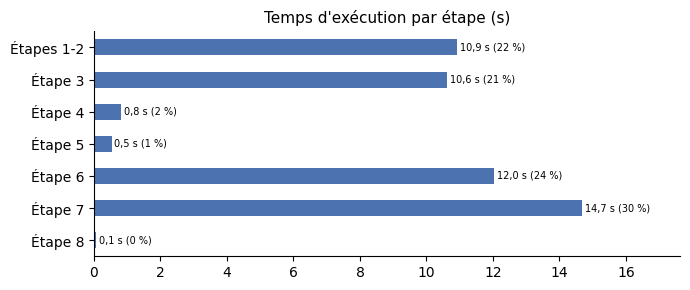

#### Interprétation
- **Données** : nettoyées, jointures contrôlées, totaux conservés.
- **Modèle de fréquence** : performant (gain 22 %, Gini 0,52) et bien calibré.
- **Modèle de coût** : faible gain (5 %) ; le coût moyen varie peu selon le profil.
- **Prévision 2010** : écart -12 % dû à la hausse de la sinistralité ; à corriger par la tendance.
- Le tarif segmenté protège contre l'antisélection ; il reste à ajuster son niveau chaque année.

In [39]:
e5, e6, e7, e8 = res["etape5"], res["etape6"], res["etape7"], res["etape8"]  # raccourcis
pr = e6["prof"].set_index("profil")  # profils de risque
synthese = pd.DataFrame({  # tableau récapitulatif
    "Indicateur": [  # libellés
        "Polices analysées",  # taille de la base
        "Polices sans sinistre",  # part des polices sans sinistre
        "Fréquence moyenne (sinistres / an)",  # fréquence globale
        "Coût moyen d'un sinistre",  # sévérité globale
        "Prime pure moyenne (€ / an)",  # coût annuel moyen par police
        "Écart de fréquence entre le profil le plus et le moins risqué",  # pouvoir de la segmentation
        "Modèle de fréquence retenu",  # meilleur modèle de fréquence
        "Modèle de coût retenu",  # meilleur modèle de coût
        "Prédit / observé sur le test (idéal = 1)",  # calibrage
        "Part du coût due au 1 % des plus gros sinistres",  # concentration
    ],
    "Valeur": [  # valeurs correspondantes
        nb_fr(res["etape3"]["base_n"]),  # nombre de polices
        f"{e5['freq_nb'].iloc[0]['pct']:.1f} %",  # part sans sinistre
        f"{base['nb_sinistres'].sum() / base['expo_annees'].sum():.3f}",  # fréquence annuelle
        f"{nb_fr(sin['chg_sin'].mean())} €",  # coût moyen
        f"{nb_fr(prime_globale, 1)} €",  # prime pure
        f"×{pr['frequence_pour_100_ans'].max() / pr['frequence_pour_100_ans'].min():.1f}",  # rapport des fréquences
        e7["best_f"],  # nom du modèle de fréquence
        e7["best_s"],  # nom du modèle de coût
        f"{e7['total'].loc[0, 'ae_total']:.3f}",  # calibrage
        f"{e8['conc'].iloc[0]['part_du_cout_pct']:.1f} %",  # concentration
    ],
}).set_index("Indicateur")  # indicateurs en index pour un affichage plus propre
synthese["Valeur"] = synthese["Valeur"].map(virgule)  # virgule décimale à la française
display(synthese)  # affiche le tableau

d = pd.Series(duree, name="secondes")  # durées des étapes
ax = d.plot.barh(figsize=(7, 3), color="#4C72B0", title="Temps d'exécution par étape (s)")  # graphique des durées
ax.bar_label(ax.containers[0], labels=[f"{v:.1f} s ({100 * v / d.sum():.0f} %)".replace(".", ",") for v in d],  # durée et part
             padding=2, fontsize=7)
ax.margins(x=0.2)  # place pour les étiquettes
plt.gca().invert_yaxis()  # première étape en haut
plt.tight_layout()  # ajuste les marges
montrer_fig()  # affiche la figure

interpretation(  # bilan général
    verdict(echecs == 0 and ok, "**Données** : nettoyées, jointures contrôlées, totaux conservés.",
            "**Données** : certains contrôles échouent, à revoir."),
    verdict(e7["gain_f"] >= 10 and abs(e7["total"].loc[0, "ae_total"] - 1) < 0.03,
            f"**Modèle de fréquence** : performant (gain {e7['gain_f']:.0f} %, Gini {gini:.2f}) et bien calibré.",
            "**Modèle de fréquence** : performance ou calibrage insuffisants."),
    verdict(e7["gain_s"] >= 10, "**Modèle de coût** : performant.",
            f"**Modèle de coût** : faible gain ({e7['gain_s']:.0f} %) ; le coût moyen varie peu selon le profil."),
    verdict(abs(ecart_prev) < 0.05, "**Prévision 2010** : juste.",
            f"**Prévision 2010** : écart {100 * ecart_prev:+.0f} % dû à la hausse de la sinistralité ; à corriger par la tendance."),
    "Le tarif segmenté protège contre l'antisélection ; il reste à ajuster son niveau chaque année.",
)

### Rapport PDF
Génère le rapport LaTeX complet et le compile en PDF (nécessite `pdflatex`).

#### Code : génération du rapport LaTeX / PDF

Définition des fonctions de l'étape. Le résultat de leur exécution s'affiche dans la cellule suivante.

In [40]:
SYMBOLES_TEX = {"≈": r"$\approx$", "ρ": r"$\rho$", "α": r"$\alpha$", "χ": r"$\chi$", "²": r"\textsuperscript{2}",
                "…": r"\ldots{}", "·": r"$\cdot$", "`": "", "<": r"$<$", ">": r"$>$", "±": r"$\pm$"}


def md_vers_tex(texte):  # convertit une phrase du notebook (Markdown simple) en LaTeX
    morceaux = str(texte).split("**")  # le gras est entre doubles astérisques
    sortie = []
    for k, m in enumerate(morceaux):
        m = "".join(SYMBOLES_TEX.get(ch, CARACTERES.get(ch, ch)) for ch in m)  # caractères spéciaux
        m = re.sub(r"\*(.+?)\*", r"\\emph{\1}", m)  # italique entre astérisques simples
        sortie.append(r"\textbf{" + m + "}" if k % 2 else m)
    return "".join(sortie)


def section_complements() -> str:  # partie du rapport reprenant les graphiques et analyses ajoutés au notebook
    if not RAPPORT_COMPLEMENTS:
        return ""
    morceaux = ["\n\\part{Compléments : tests statistiques, visualisations et tarification}\n"
                "Cette partie reprend les analyses ajoutées dans le notebook : graphiques de l'audit et du nettoyage, "
                "choix des lois de probabilité, tests statistiques, visualisations avancées des modèles, et application "
                "à la tarification (grille, prévision 2010, antisélection, profils types).\n"]
    for contenu in RAPPORT_COMPLEMENTS.values():
        morceaux.append("\\section{" + echapper(contenu["titre"]) + "}\n")
        if contenu["figure"]:
            morceaux.append("\\begin{figure}[htbp]\\centering\\includegraphics[width=\\textwidth]{" + contenu["figure"]
                            + "}\n\\caption{" + echapper(contenu["legende"]) + "}\\end{figure}\n")
        if contenu.get("tableau") is not None:
            t = contenu["tableau"]
            lignes = [[echapper(i)] + [echapper(v) for v in r] for i, r in zip(t.index, t.to_numpy())]
            morceaux.append(tableau(contenu["titre"], "tab:" + str(abs(hash(contenu["titre"])) % 10 ** 6),
                                    ["variable"] + list(t.columns), lignes, "l" + "r" * t.shape[1]))
        for nom_bloc, cle in [("Points clés", "points"), ("Interprétation", "interp")]:
            phrases = [p for p in contenu[cle] if p]
            if phrases:
                morceaux.append("\\paragraph{" + nom_bloc + "}\n\\begin{itemize}\n"
                                + "\n".join("  \\item " + md_vers_tex(p) for p in phrases) + "\n\\end{itemize}\n")
    return "".join(morceaux)


def generer_rapport(res: dict) -> None:
    corps = [
        "\\part{Étape 1 -- Compréhension des bases de données}\n\\section{Objectif}\n"
        "Comprendre les données disponibles : importer, dimensionner, typer, classer les variables et repérer "
        "les clés de jointure.\n",
        s_methode_e1(), s_sources(res["etape1_resume"]), s_dictionnaire(res["dico"]), s_nature(res["dico"]),
        s_statistiques(res["stats"]), s_anomalies_e1(res["anomalies_e1"]), s_cles(res["cles"]),
        "\n\\part{Étape 2 -- Audit et qualité des données}\n\\section{Objectif}\n"
        "Détecter les anomalies avant toute analyse.\n",
        s_methode_e2(), s_synthese(res), s_manquants(res), s_doublons(res), s_outliers(res), s_saisie(res),
        s_regles(res), s_incoherences(res), s_formats(res), s_plan(res),
        section_etape3(res["etape3"]),
        section_etape4(res["etape4"]),
        section_etape5(res["etape5"]),
        section_etape6(res["etape6"]),
        section_etape7(res["etape7"]),
        section_etape8(res),
        section_complements(),  # graphiques, tests et tarification ajoutés dans le notebook
    ]
    mois = ["janvier", "février", "mars", "avril", "mai", "juin", "juillet", "août",
            "septembre", "octobre", "novembre", "décembre"]
    auj = datetime.date.today()
    date_fr = f"{auj.day} {mois[auj.month - 1]} {auj.year}"
    pre = PREAMBULE.replace("__DATE_FR__", date_fr).replace("__LITERATE__", literate())
    FICHIER_TEX.write_text(pre + "\n".join(corps) + FIN, encoding="utf-8")
    if shutil.which("pdflatex") is None:
        print("pdflatex introuvable : le fichier rapport_analyse.tex est produit ; "
              "compilez-le avec votre éditeur LaTeX (ou installez une distribution LaTeX).")
        return
    for _ in range(2):
        # compilé depuis la racine (chemins des figures), fichiers produits dans rapport/
        subprocess.run(["pdflatex", "-interaction=nonstopmode", "-halt-on-error",
                        f"-output-directory={FICHIER_TEX.parent.name}", FICHIER_TEX.relative_to(DOSSIER).as_posix()],
                       cwd=DOSSIER, check=True, stdout=subprocess.DEVNULL)
    for ext in (".aux", ".log", ".out", ".toc"):  # fichiers techniques de LaTeX, inutiles une fois le PDF produit
        FICHIER_TEX.with_suffix(ext).unlink(missing_ok=True)

print("Fonctions chargées (1) ; fonction principale : generer_rapport()")  # confirme l'exécution de la cellule


Fonctions chargées (1) ; fonction principale : generer_rapport()


In [41]:
generer_rapport(res)  # écrit rapport_analyse.tex puis le compile en PDF
pdf = FICHIER_TEX.with_suffix(".pdf")  # chemin du PDF produit
print("Rapport :", pdf if pdf.exists() else "PDF non produit (pdflatex manquant ?)")  # indique où le trouver

Rapport : /Users/morelpouniguia/Documents/Projet AIMAF Actuariat/rapport/rapport_analyse.pdf


### Conclusion, limites et recommandations

#### Ce qu'il faut retenir
- **Qualité des données** : les bases contenaient de nombreuses anomalies (âges impossibles, doublons, codes non normalisés, nombres stockés en texte). Toutes ont été traitées et documentées dans le journal des décisions.
- **Facteurs de risque** : la fréquence dépend surtout du **bonus-malus**, de l'**âge** et de la **densité** de la zone. Les jeunes conducteurs à fort malus sont de loin les plus risqués.
- **Le coût d'un sinistre est peu prévisible** avec les variables disponibles : l'essentiel de la segmentation vient de la fréquence.
- **Lois de probabilité** : le nombre de sinistres est **surdispersé** (test de Cameron-Trivedi significatif) ; la binomiale négative décrit bien mieux que la loi de Poisson les polices à plusieurs sinistres. Les montants sont globalement mieux décrits par une loi Gamma que par une log-normale (AIC), mais la Gamma sous-estime les gros sinistres.
- **Fréquence et coût jouent parfois en sens contraire** : par exemple, les retraités ont moins de sinistres mais des sinistres plus coûteux. Modéliser séparément la fréquence et le coût rend ces mécanismes visibles.
- **Concentration** : une petite part des sinistres représente une grande part du coût, ce qui plaide pour un écrêtement des gros sinistres dans le tarif et une réassurance en excédent de sinistre.
- **Application** : le tarif GLM construit sur 2009 garde une segmentation valable en 2010 (S/P homogène entre déciles, pas d'antisélection, contrairement à un tarif uniforme). En revanche, il **sous-estime le niveau** de 2010, car la sinistralité a augmenté : un coefficient de tendance est nécessaire.

#### Limites
- Une partie des lignes de sinistres n'a **pas de police correspondante** (étape 4). Elles sont exclues, ce qui peut sous-estimer la sinistralité si elles appartiennent à des polices réelles absentes du portefeuille.
- L'incohérence « Housewife » chez des hommes est très fréquente : la variable *Occupation* est probablement mal codée. Choix retenu : les lignes sont conservées, l'incohérence est signalée et *Occupation* reste dans le tarif ; son effet est à surveiller lors du recalibrage.
- La segmentation non supervisée est **modérément stable** (ARI) : les profils servent à décrire le portefeuille, pas à tarifer.
- Deux années seulement : on mesure l'évolution entre 2009 et 2010 (hausse homogène entre segments), mais on ne peut pas dire si elle est durable ou ponctuelle.
- Avec 100 000 polices, presque tous les tests sont significatifs : c'est la **taille des effets** (rapports de taux, V de Cramér) qui compte, plus que les p-valeurs. La surdispersion rend en outre les intervalles de confiance du GLM de Poisson un peu trop étroits.
- Le chargement de 30 % est une hypothèse de travail ; il sera à remplacer par les frais réels de l'insurtech.

#### Recommandations
Les recommandations sont classées par ordre de priorité. Pour chacune : le **constat** qui la justifie, l'**action** proposée et l'**indicateur de suivi** qui permettra de vérifier qu'elle fonctionne.

##### A. Avant la mise en production

**1. Retrouver l'origine des sinistres sans police.**
- *Constat* : 1 011 lignes de sinistres (7,6 %) n'ont pas de police correspondante (étape 4). Si elles appartiennent à des contrats réels, la fréquence et la prime pure sont sous-estimées d'autant.
- *Action* : rapprocher ces numéros de police avec le système de gestion (polices résiliées, autres produits, erreurs de saisie), puis réintégrer celles qui sont retrouvées et recalculer le tarif.
- *Suivi* : part des sinistres sans police à chaque nouvel extrait, avec une cible proche de 0 %.

**2. Fiabiliser les données à la source.**
- *Constat* : clés `PolNum` répétées avec des contenus différents, âges impossibles (de 4 à 250 ans), anciennetés négatives, nombres stockés en texte, codes de sexe non normalisés (étapes 1-2).
- *Action* : ajouter des contrôles bloquants à la saisie (clé unique, bornes d'âge et d'ancienneté, listes de codes fermées) et relancer automatiquement les contrôles de l'étape 2 à chaque chargement de données.
- *Suivi* : nombre d'anomalies par contrôle, comparé d'un extrait à l'autre.

**3. Clarifier le codage de la profession.**
- *Constat* : 12 653 lignes (12,7 %) codent « Housewife » pour un homme, et 1 734 « Retired » ont moins de 50 ans. Or la profession entre dans le tarif, avec des coefficients allant de ×0,71 (retraités) à ×1,42 (sans emploi).
- *Action* : vérifier la définition de la variable auprès du gestionnaire des données et la recoder. En attendant, la variable est conservée (choix retenu) mais son effet est surveillé.
- *Suivi* : stabilité des coefficients de profession à chaque recalibrage.

##### B. Construction du tarif

**4. Tarifer avec la grille GLM, piloter avec le gradient boosting.**
- *Constat* : le GLM obtient 94 % du gain de performance du gradient boosting (étape 7), et ses coefficients sont lisibles et justifiables auprès des clients et du régulateur.
- *Action* : utiliser la grille de l'étape 9 comme tarif commercial ; utiliser le gradient boosting pour la sélection des risques et pour repérer les segments que la grille tarife mal (écart entre la prime GLM et la prédiction du boosting). Le sexe reste exclu du tarif, conformément au droit européen.
- *Suivi* : indice de Gini (0,52 aujourd'hui) et rapport prédit / observé par groupe de risque.

**5. Tester l'ajout de la zone géographique dans la grille.**
- *Constat* : la zone géographique (`Group1`) est la 4e variable la plus utile au modèle de fréquence (sa permutation dégrade la déviance de 6 %, étape 7), mais la grille tarifaire n'utilise que la densité.
- *Action* : ajouter la zone au GLM tarifaire en regroupant les zones de risque proche, puis mesurer le gain sur l'échantillon test. Vérifier qu'elle n'est pas redondante avec la densité.
- *Suivi* : gain de déviance et stabilité des coefficients de zone d'une année à l'autre.

**6. Écrêter les gros sinistres et traiter la queue à part.**
- *Constat* : 20 % des sinistres représentent 56 % du coût (étape 8), et la loi Gamma sous-estime le 99e centile des montants de 28 % (6 199 € prévus contre 8 622 € observés, étape 3 bis).
- *Action* : dans le tarif, plafonner chaque sinistre au P99 (environ 8 600 €) et répartir le surcoût sur tous les contrats. Au-delà du seuil, ajuster une loi de Pareto et couvrir ce risque par une réassurance en excédent de sinistre.
- *Suivi* : part du coût annuel au-dessus du seuil.

**7. Revoir le chargement et fixer une prime minimale.**
- *Constat* : avec un chargement de 30 % proportionnel à la prime pure, un retraité à fort bonus paie 19 € par an, ce qui ne couvre probablement pas les frais de gestion d'un contrat. En 2010, le S/P rapporté à la prime commerciale atteint 0,97 : il ne reste presque rien pour les frais et la marge.
- *Action* : remplacer le chargement par un montant fixe par contrat plus un pourcentage de la prime pure, calés sur les frais réels de l'insurtech, et fixer une prime minimale.
- *Suivi* : ratio combiné ((sinistres + frais) / primes) par décile de risque.

**8. Accompagner la prime des jeunes conducteurs.**
- *Constat* : un jeune conducteur à fort malus en ville paie 1 275 € par an, plus que 99 % des assurés. Il risque de partir chez un concurrent ; mais baisser sa prime sans contrepartie créerait de l'antisélection.
- *Action* : proposer des contreparties qui réduisent réellement le risque ou le coût : franchise plus élevée, conduite accompagnée, boîtier télématique.
- *Suivi* : taux de souscription et S/P des 18-25 ans.

##### C. Pilotage et suivi annuel

**9. Appliquer un coefficient de tendance, puis recalibrer chaque année.**
- *Constat* : le tarif 2009 sous-estime le coût 2010 de 12,4 %. La hausse (×1,154 sur la prime pure) est la même dans tous les segments (étape 9).
- *Action* : multiplier toute la grille par le coefficient de tendance ; recalibrer le GLM chaque année sur l'ensemble des années disponibles, avec un effet année ; confirmer la tendance dès que la troisième année est disponible.
- *Suivi* : S/P par décile de risque (il doit rester au même niveau dans tous les déciles) et écart entre coût prévu et coût observé.

**10. Utiliser la binomiale négative pour mesurer l'incertitude.**
- *Constat* : la surdispersion est significative (α = 1,88, test de Cameron-Trivedi) ; la loi de Poisson prévoit 2 polices à 4 sinistres ou plus, contre 98 observées (étape 3 bis).
- *Action* : calculer les intervalles de confiance des coefficients avec un GLM binomial négatif (ou un Poisson à erreurs-types corrigées), et simuler la sinistralité avec la binomiale négative (provisionnement, besoin en capital, réassurance).
- *Suivi* : comparer les quantiles simulés aux sinistres observés chaque année.

**11. Surveiller individuellement les polices atypiques.**
- *Constat* : 11 polices de l'échantillon test totalisent 36 sinistres pour 2,5 attendus, soit 14 fois plus : un tel écart est quasi impossible par hasard (étape 8).
- *Action* : revue de souscription au cas par cas (usage professionnel non déclaré, conducteur secondaire, fraude, erreur de saisie), plutôt que de laisser leur coût peser sur le tarif de tous.
- *Suivi* : liste des polices atypiques mise à jour chaque trimestre.
